# Libraries

In [4]:
#### libraries ####
import os
import mne
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy import signal
from scipy.io import wavfile

# from pybv import write_brainvision
from pyprep.prep_pipeline import PrepPipeline
from mne_icalabel import label_components

# autoreject
from autoreject import AutoReject
from autoreject import Ransac


# working directory
work_dir = '/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/'
exp_dir = work_dir + 'Experiments/experiment_english/'

# read in participant file
df = pd.read_csv(work_dir + 'Data/data_english/data_analysis/participants_include.txt', delimiter = '\t')
include_ppts = df[df['include']==1]['participant'].astype(str).tolist()
include_ppts = [x for x in include_ppts if x.split('_')[0]=='VOT']

# create a montage file for the pipeline
montage = mne.channels.make_standard_montage("standard_1020")

# Raw data quality check

In [ ]:
# directory
input_dir = work_dir + '/Data/data_english/eeg_raw/eeg_brainvision/'

# file name
file = 'CUE2024_0006_VOT.vhdr'

# read in file
raw = mne.io.read_raw_brainvision(input_dir + file, preload = True)

# drop the audio channel in data
raw.drop_channels(['StimTrak'])

# set montage
raw.set_montage('standard_1020')

# # drop channels
# raw.drop_channels(['FC6'])

# check information
print(raw.info)

# plot spectrum of raw EEG
raw.compute_psd().plot()
plt.show()

# event distributions
events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
fig = mne.viz.plot_events(
    events_from_annot, event_id=event_dict, sfreq=raw.info["sfreq"], first_samp=raw.first_samp
)


# segmentation for ERP
epochs = mne.Epochs(
    raw,
    events = events_from_annot, event_id = event_dict,
    tmin = -0.2, tmax = 1,
    # remove epochs that meet the rejection criteria
    reject = None,
    preload = True,
)

# plot epochs
epochs.plot_image(combine="mean", vmin=-100, vmax=100)

# butterfly
epochs.average().plot()
plt.show()

# Save as EEGLAB file
# file = 'CUE2024_0008_VOT_corr_prep_ica.fif'

# # read in file
# raw = mne.io.read_raw_fif(input_dir + file, preload = True)

# # save
# mne.export.export_raw(output_dir + "CUE2024_0008_VOT_corr_prep_ica.set", 
#                       raw, fmt='auto', physical_range='auto', add_ch_type=False, overwrite=True, verbose=None)

# plot epochs
epochs.plot_image(combine="mean")

# butterfly
epochs.average().plot()
plt.show()


# if needed, plot a spectrum for fewer channels together
raw.compute_psd(picks = ['Fp1', 'Fp2', 'F3','F7','Fz','F4','F8']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['FT9', 'FT10', 'FC5','FC1','FC2','FC6']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['T7', 'T8', 'C3','Cz','C4']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['CP5', 'CP1', 'CP2','CP6','TP10']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['P7', 'P3', 'Pz','P4','P8']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['O1', 'Oz', 'O2']).plot(show=False, amplitude=False)

plt.show()

# Trigger latency correction
Fixing trigger timing & renaming events

In [ ]:
##### parameters #####

# directory
input_dir = work_dir + 'Data/data_english/eeg_raw/eeg_brainvision/'
output_dir = work_dir + 'eeg_preprocessed_NEW/1_trigger_lag_corrected/'

# create a dictionary for blocks and block markers
block_dict = {
    'dorsal_highStan_lowDevi': 1000, # standard: dorsal_high; deviant: dorsal_low
    'dorsal_lowStan_highDevi': 2000, # standard: dorsal_low; deviant: dorsal_high
    'glottal_highStan_lowDevi': 3000, # standard: glottal_high; deviant: glottal_low
    'glottal_lowStan_highDevi': 4000, # standard: glottal_low; deviant: glottal_high
}

# create a condition-level mapping
condition_mapping = {
    1000: 'dorsal_highStan_lowDevi_stan',
    1100: 'dorsal_highStan_lowDevi_devi',
    2000: 'dorsal_lowStan_highDevi_stan',
    2100: 'dorsal_lowStan_highDevi_devi',
    3000: 'glottal_highStan_lowDevi_stan',
    3100: 'glottal_highStan_lowDevi_devi',
    4000: 'glottal_lowStan_highDevi_stan',
    4100: 'glottal_lowStan_highDevi_devi',
}

# trigger searching window (actual trigger time based on audio - trigger time in the data)
t_left = -0.01
t_right = 0.4 # long latency due to using pygame sound library

# set a threshold for good stims
max_corr_thres = 0.3

##### trigger lag fix #####

# read in eeg data files
all_files = os.listdir(input_dir)

#### for each file, create a dictionary to store each block and the indices of trials of that block  ####
for file in all_files:
    if file.endswith('.vhdr') and (file.split('.')[0]+ '_corr.fif' not in os.listdir(output_dir)):

        # check participants
        if file.split('.')[0].split('_')[2]+'_'+file.split('.')[0].split('_')[1] not in include_ppts:
            continue
        
        # read in vhdr files
        raw = mne.io.read_raw_brainvision(input_dir + file, preload = True)

        # If the aux channel is not named 'StimTrak', change the channel name to 'StimTrak'
        if raw.info['ch_names'][31] != 'StimTrak':
            # change the channel name
            raw.rename_channels({raw.info['ch_names'][31]: 'StimTrak'})
            # specify the audio channel
            raw.set_channel_types({'StimTrak':'misc'})
        
        # extract the info of experiment version
        exp_ver = file.split('.')[0].split('_')[2]

        # extract sampling rate
        eeg_sfreq = raw.info['sfreq']
        
        #############################################################################################
        #### create a dictionary for each stim's standard version and deviant version of markers ####
        
        # intialize a dictionary for triggers
        trigger_dict = {}
        
        # read in trigger_codes file, and create a standard trigger code and a deviant triggre code for each stimulus
        with open(exp_dir + exp_ver+'_eeg/trigger_codes.txt','r') as tf:
            for line in tf:
                # read in the current line
                line = line.replace('\n','')
                # separate fileNames and triggerMarker
                label, marker = line.split('\t')
                # convert trigger markers to integer
                marker = int(marker)
                # create label for stims used as standards
                trigger_dict[marker] = label + '-s'
                # add 100 for deviant marker
                marker_deviant = marker + 100
                # create label for stims used as deviants
                trigger_dict[marker_deviant] = label + '-d'
        #############################################################################################

        ########################
        #### get audio data ####
        
        # initialize dictionaries
        audio = {}
        lengths = {}
        
        # del trigger_dict[99999]
        # for each trigger code and label in the trigger dictionary
        for marker,label in trigger_dict.items():
            # extract file name
            file_name = label.split('-')[0]
            # if not already in audio dictionary, get the info of the audio file
            if file_name not in audio:
                # get sample rate and data of the audio file
                sampleRate, data = wavfile.read(exp_dir + exp_ver + '_eeg/stimuli/{}.wav'.format(file_name))
                # calculate sound file length
                lengths[file_name] = len(data)/sampleRate
                # reduce the sampling rate of the audio file by the factor of int(sampleRate/eeg_sfreq)
                data_downsampled = signal.decimate(data, int(sampleRate/eeg_sfreq), ftype='fir')
                # add info the audio dictionary
                audio[file_name] = data_downsampled
        ########################

        
        ##################################################################
        #### recode trigger marker to reflect condition and stim info ####

        # for each stimulus, mark the block info
        events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        # remove the non-stim marker
        events_from_annot = events_from_annot[events_from_annot[:, 2] < 200]
        
        # initialize the train for each standards+deviant sequence
        train = np.array([]).astype(int)
        
        all_block = {}
        isStandard = True # whether the standard in a train has been noted
        
        # loop over each trigger
        for i in range(events_from_annot.shape[0]):

            # get trigger value
            trigger_value = events_from_annot[i,2]
            
            # add the current token to the train
            train = np.append(train,i)

            # if the trigger value is smaller than 100 and the standard toggle is true
            if (trigger_value<100) & isStandard:
                # split the file name
                trigger_splitted = trigger_dict[trigger_value].split('_')
                # get the standard category name
                block = trigger_splitted[1] + '_' + trigger_splitted[2] + 'Stan'
                # toggle standard
                isStandard = False

            # if the trigger value is over 100
            elif trigger_value>100:
                # split the file name
                trigger_splitted = trigger_dict[trigger_value].split('_')
                # append the deviant stim category 
                block = block + '_' + trigger_splitted[2] + 'Devi'

                # if the block is not present in all block
                if block not in all_block:
                    # add the new block and the token idx
                    all_block[block] = train[-2:] # [-2:] to include one standard + one eviant sequence
                else:
                    # add the token idx to the existing block
                    all_block[block] = np.concatenate([ all_block[block],train[-2:] ],axis = None) # # [-2:] to include one standard + one eviant sequence

                # reset train
                train = np.array([]).astype(int)

                # toggle standard note
                isStandard = True
        
        # loop over each block and its trigger index
        for k,v in all_block.items():
            # recode the trigger value to reflect block and stim category
            events_from_annot[tuple(v),2] += block_dict[k]

        # generate new events
        events_from_annot = events_from_annot[events_from_annot[:,2]>1000]
        ##################################################################

        
        ######################################################
        #### cross correction to detect the trigger delay ####
        
        # initialize delay list
        delays = np.array([])
        # initialize bad stim list
        bad_stim = []
        corr_results = []
        
        # loop over each event
        for i in range(events_from_annot.shape[0]):
        
            # get current event info [time, duration, annotation]
            event = events_from_annot[i]
            # get the onset latency (s) of the event
            time = event[0]/eeg_sfreq
            # get the file name of the event
            name = trigger_dict[event[2]%100].split('-')[0]
            # get the data from the sound channel
            audio_eeg = raw.get_data(
                picks = ['StimTrak'],
                tmin = time + t_left,
                tmax = time + lengths[name] + t_right,
            )[0]
            # actual stimulus
            audio_stim = audio[name]
            # Z-score normalization (subtract mean, divide by std)
            audio_eeg = (audio_eeg - np.mean(audio_eeg)) / np.std(audio_eeg)
            audio_stim = (audio_stim - np.mean(audio_stim)) / np.std(audio_stim)
            
            # cross-correlation
            corr = signal.correlate(audio_eeg, audio_stim, mode='full')
            # Normalize cross-correlation
            corr = corr / (np.linalg.norm(audio_eeg) * np.linalg.norm(audio_stim))
            # Find peak correlation value
            max_corr = np.max(corr)            
            
            # if the maximum correction (sum of products) is less than a threshold (empirical threshold, 0.5 is generally good)
            if max_corr < max_corr_thres:
                # mark the stim bad
                bad_stim.append(i)

            # append the maximum correlation
            corr_results.append(max_corr)

            
            # the lags for cross-correlation
            lags = signal.correlation_lags(
                audio_eeg.size,
                audio_stim.size,
                mode="full")
            # get the lag of the maximum cross-correlation
            lag = lags[np.argmax(corr)] + t_left*eeg_sfreq
            
            # save the lag for non-starting events
            delays = np.append(delays,lag)

        # log the number of bad stims
        with open(output_dir + 'bad_stims.txt', 'a+') as f:
            f.write(file + '\t' + str(len(bad_stim)) + '\n')
        ######################################################

        
        ##################################################################################################
        #### plot the wave from the stim track and the eeg channel of the token with the minimum corr ####
        min_corr = np.argmin(corr_results)
        # get current event info [time, duration, annotation]
        event = events_from_annot[min_corr]
        # get the onset latency (s) of the event
        time = event[0]/eeg_sfreq
        # get the file name of the event
        name = trigger_dict[event[2]%100].split('-')[0]
        # get the data from the sound channel
        audio_eeg = raw.get_data(
            picks = ['StimTrak'],
            tmin = time + t_left,
            tmax = time + lengths[name] + t_right,
        )[0]
        # actual stimulus
        audio_stim = audio[name]
        # Z-score normalization (subtract mean, divide by std)
        audio_eeg = (audio_eeg - np.mean(audio_eeg)) / np.std(audio_eeg)
        audio_stim = (audio_stim - np.mean(audio_stim)) / np.std(audio_stim)
        # plot
        fig, ax = plt.subplots()
        ax.plot(audio_eeg, label = 'StimTrak', alpha = 0.6)
        ax.plot(audio_stim, label = 'wave', alpha = 0.6)
        ax.set_title(file)
        ax.legend()
        fig.savefig(output_dir + file.split('.')[0] + "_minCor.png", dpi=300, bbox_inches='tight')
        ##################################################################################################
        
        
        ################################################
        #### correct for trigger lag and save files ####
        
        # remove items associated with bad stims from the event list
        events_from_annot = np.delete(events_from_annot, bad_stim, 0)
        
        # remove items associated with bad stims from the delay list
        delays = np.delete(delays, bad_stim, 0)

        ########## recode trigger marker ##########
        # add delay back to the onset latency of each event
        events_from_annot[:,0] = events_from_annot[:,0] + delays
        
        # # create item-level annotations
        # annot_from_events = mne.annotations_from_events(
        #     events = events_from_annot,
        #     event_desc = eval(exp_ver + '_mapping'),
        #     sfreq = eeg_sfreq
        # )
        
        # convert individual event marker to conditions
        events_from_annot[:,2] = events_from_annot[:,2] - events_from_annot[:,2]%100
        # create condition-level annotations
        annot_from_events = mne.annotations_from_events(
            events = events_from_annot,
            event_desc = condition_mapping,
            sfreq = eeg_sfreq
        )
        
        # set annotations
        raw.set_annotations(annot_from_events)
        
        # drop the audio channel in data
        raw.drop_channels(['StimTrak'])
        
        # save as a file-into-file data
        raw.save(output_dir + file.split('.')[0]+ '_corr.fif')

        # save lag data
        np.savetxt(output_dir + file.replace('.vhdr', '_delays.txt'), delays, fmt='%i')
        ################################################

## mannual correct
in case some files may need different parameters...

In [ ]:
##### parameters #####

# directory
input_dir = work_dir + 'Data/data_english/eeg_raw/eeg_brainvision/'
output_dir = work_dir + 'eeg_preprocessed_NEW/1_trigger_lag_corrected/manual/'

# create a dictionary for blocks and block markers
block_dict = {
    'dorsal_highStan_lowDevi': 1000, # standard: dorsal_high; deviant: dorsal_low
    'dorsal_lowStan_highDevi': 2000, # standard: dorsal_low; deviant: dorsal_high
    'glottal_highStan_lowDevi': 3000, # standard: glottal_high; deviant: glottal_low
    'glottal_lowStan_highDevi': 4000, # standard: glottal_low; deviant: glottal_high
}

# create a condition-level mapping
condition_mapping = {
    1000: 'dorsal_highStan_lowDevi_stan',
    1100: 'dorsal_highStan_lowDevi_devi',
    2000: 'dorsal_lowStan_highDevi_stan',
    2100: 'dorsal_lowStan_highDevi_devi',
    3000: 'glottal_highStan_lowDevi_stan',
    3100: 'glottal_highStan_lowDevi_devi',
    4000: 'glottal_lowStan_highDevi_stan',
    4100: 'glottal_lowStan_highDevi_devi',
}

# trigger searching window (actual trigger time based on audio - trigger time in the data)
t_left = -0.01
t_right = 0.4 # long latency due to using pygame sound library

##### trigger lag fix #####

file = 'CUE2024_0047_VOT.vhdr'

max_corr_thres = 0.3
       
# read in vhdr files
raw = mne.io.read_raw_brainvision(input_dir + file, preload = True)

# If the aux channel is not named 'StimTrak', change the channel name to 'StimTrak'
if raw.info['ch_names'][31] != 'StimTrak':
    # change the channel name
    raw.rename_channels({raw.info['ch_names'][31]: 'StimTrak'})
    # specify the audio channel
    raw.set_channel_types({'StimTrak':'misc'})

# extract the info of experiment version
exp_ver = file.split('.')[0].split('_')[2]

# extract sampling rate
eeg_sfreq = raw.info['sfreq']

#############################################################################################
#### create a dictionary for each stim's standard version and deviant version of markers ####

# intialize a dictionary for triggers
trigger_dict = {}

# read in trigger_codes file, and create a standard trigger code and a deviant triggre code for each stimulus
with open(exp_dir + exp_ver+'_eeg/trigger_codes.txt','r') as tf:
    for line in tf:
        # read in the current line
        line = line.replace('\n','')
        # separate fileNames and triggerMarker
        label, marker = line.split('\t')
        # convert trigger markers to integer
        marker = int(marker)
        # create label for stims used as standards
        trigger_dict[marker] = label + '-s'
        # add 100 for deviant marker
        marker_deviant = marker + 100
        # create label for stims used as deviants
        trigger_dict[marker_deviant] = label + '-d'
#############################################################################################

########################
#### get audio data ####

# initialize dictionaries
audio = {}
lengths = {}

# del trigger_dict[99999]
# for each trigger code and label in the trigger dictionary
for marker,label in trigger_dict.items():
    # extract file name
    file_name = label.split('-')[0]
    # if not already in audio dictionary, get the info of the audio file
    if file_name not in audio:
        # get sample rate and data of the audio file
        sampleRate, data = wavfile.read(exp_dir + exp_ver + '_eeg/stimuli/{}.wav'.format(file_name))
        # calculate sound file length
        lengths[file_name] = len(data)/sampleRate
        # reduce the sampling rate of the audio file by the factor of int(sampleRate/eeg_sfreq)
        data_downsampled = signal.decimate(data, int(sampleRate/eeg_sfreq), ftype='fir')
        # add info the audio dictionary
        audio[file_name] = data_downsampled
########################


##################################################################
#### recode trigger marker to reflect condition and stim info ####

# for each stimulus, mark the block info
events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
# remove the non-stim marker
events_from_annot = events_from_annot[events_from_annot[:, 2] < 200]

# initialize the train for each standards+deviant sequence
train = np.array([]).astype(int)

all_block = {}
isStandard = True # whether the standard in a train has been noted

# loop over each trigger
for i in range(events_from_annot.shape[0]):

    # get trigger value
    trigger_value = events_from_annot[i,2]
    
    # add the current token to the train
    train = np.append(train,i)

    # if the trigger value is smaller than 100 and the standard toggle is true
    if (trigger_value<100) & isStandard:
        # split the file name
        trigger_splitted = trigger_dict[trigger_value].split('_')
        # get the standard category name
        block = trigger_splitted[1] + '_' + trigger_splitted[2] + 'Stan'
        # toggle standard
        isStandard = False

    # if the trigger value is over 100
    elif trigger_value>100:
        # split the file name
        trigger_splitted = trigger_dict[trigger_value].split('_')
        # append the deviant stim category 
        block = block + '_' + trigger_splitted[2] + 'Devi'

        # if the block is not present in all block
        if block not in all_block:
            # add the new block and the token idx
            all_block[block] = train[-2:] # [-2:] to include one standard + one eviant sequence
        else:
            # add the token idx to the existing block
            all_block[block] = np.concatenate([ all_block[block],train[-2:] ],axis = None) # # [-2:] to include one standard + one eviant sequence

        # reset train
        train = np.array([]).astype(int)

        # toggle standard note
        isStandard = True

# loop over each block and its trigger index
for k,v in all_block.items():
    # recode the trigger value to reflect block and stim category
    events_from_annot[tuple(v),2] += block_dict[k]

# generate new events
events_from_annot = events_from_annot[events_from_annot[:,2]>1000]
##################################################################


######################################################
#### cross correction to detect the trigger delay ####

# initialize delay list
delays = np.array([])
# initialize bad stim list
bad_stim = []
corr_results = []

# loop over each event
for i in range(events_from_annot.shape[0]):

    # get current event info [time, duration, annotation]
    event = events_from_annot[i]
    # get the onset latency (s) of the event
    time = event[0]/eeg_sfreq
    # get the file name of the event
    name = trigger_dict[event[2]%100].split('-')[0]
    # get the data from the sound channel
    audio_eeg = raw.get_data(
        picks = ['StimTrak'],
        tmin = time + t_left,
        tmax = time + lengths[name] + t_right,
    )[0]
    # actual stimulus
    audio_stim = audio[name]
    # Z-score normalization (subtract mean, divide by std)
    audio_eeg = (audio_eeg - np.mean(audio_eeg)) / np.std(audio_eeg)
    audio_stim = (audio_stim - np.mean(audio_stim)) / np.std(audio_stim)
    
    # cross-correlation
    corr = signal.correlate(audio_eeg, audio_stim, mode='full')
    # Normalize cross-correlation
    corr = corr / (np.linalg.norm(audio_eeg) * np.linalg.norm(audio_stim))
    # Find peak correlation value
    max_corr = np.max(corr)            
    
    # if the maximum correction (sum of products) is less than a threshold (empirical threshold, 0.5 is generally good)
    if max_corr < max_corr_thres:
        # mark the stim bad
        bad_stim.append(i)

    # append the maximum correlation
    corr_results.append(max_corr)

    
    # the lags for cross-correlation
    lags = signal.correlation_lags(
        audio_eeg.size,
        audio_stim.size,
        mode="full")
    # get the lag of the maximum cross-correlation
    lag = lags[np.argmax(corr)] + t_left*eeg_sfreq
    
    # save the lag for non-starting events
    delays = np.append(delays,lag)

# log the number of bad stims
with open(output_dir + 'bad_stims.txt', 'a+') as f:
    f.write(file + '\t' + str(len(bad_stim)) + '\n')
######################################################


##################################################################################################
#### plot the wave from the stim track and the eeg channel of the token with the minimum corr ####
min_corr = np.argmin(corr_results)
# get current event info [time, duration, annotation]
event = events_from_annot[min_corr]
# get the onset latency (s) of the event
time = event[0]/eeg_sfreq
# get the file name of the event
name = trigger_dict[event[2]%100].split('-')[0]
# get the data from the sound channel
audio_eeg = raw.get_data(
    picks = ['StimTrak'],
    tmin = time + t_left,
    tmax = time + lengths[name] + t_right,
)[0]
# actual stimulus
audio_stim = audio[name]
# Z-score normalization (subtract mean, divide by std)
audio_eeg = (audio_eeg - np.mean(audio_eeg)) / np.std(audio_eeg)
audio_stim = (audio_stim - np.mean(audio_stim)) / np.std(audio_stim)
# plot
fig, ax = plt.subplots()
ax.plot(audio_eeg, label = 'StimTrak', alpha = 0.6)
ax.plot(audio_stim, label = 'wave', alpha = 0.6)
ax.set_title(file)
ax.legend()
fig.savefig(output_dir + file.split('.')[0] + "_minCor.png", dpi=300, bbox_inches='tight')
##################################################################################################


################################################
#### correct for trigger lag and save files ####

# remove items associated with bad stims from the event list
events_from_annot = np.delete(events_from_annot, bad_stim, 0)

# remove items associated with bad stims from the delay list
delays = np.delete(delays, bad_stim, 0)

########## recode trigger marker ##########
# add delay back to the onset latency of each event
events_from_annot[:,0] = events_from_annot[:,0] + delays

# # create item-level annotations
# annot_from_events = mne.annotations_from_events(
#     events = events_from_annot,
#     event_desc = eval(exp_ver + '_mapping'),
#     sfreq = eeg_sfreq
# )

# convert individual event marker to conditions
events_from_annot[:,2] = events_from_annot[:,2] - events_from_annot[:,2]%100
# create condition-level annotations
annot_from_events = mne.annotations_from_events(
    events = events_from_annot,
    event_desc = condition_mapping,
    sfreq = eeg_sfreq
)

# set annotations
raw.set_annotations(annot_from_events)

# drop the audio channel in data
raw.drop_channels(['StimTrak'])

# save as a file-into-file data
raw.save(output_dir + file.split('.')[0]+ '_corr.fif')

# save lag data
np.savetxt(output_dir + file.replace('.vhdr', '_delays.txt'), delays, fmt='%i')
################################################

# Filter, resample, and remove line noise
- filtering
- resampling
- remove line noise

In [ ]:
#### parameters ####

# set directory
input_dir = work_dir + 'eeg_preprocessed_NEW/1_trigger_lag_corrected/'
output_dir = work_dir + 'eeg_preprocessed_NEW/2_filtered/'

# filter cutoff frequencies (low/high)
f_low = 0.5

# resampling frequency
f_res = 250

# line frequency
line_freq = 60

#####################################################
#### filtering, resampling, bad channel detection/interpoloation ####
#####################################################

# get all file namesin the folder
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


for file in all_input:
    if file.endswith("corr.fif") and (file.split('.')[0]+ '_prep.fif' not in all_output):

        # select participants
        if file.split('_')[2] + '_' + file.split('_')[1] not in include_ppts:
            continue
            
        # read in file
        raw = mne.io.read_raw_fif(input_dir + file, preload=True)

        #### cut off the beginning and ending part ####
        # # get the onset of the first and the last event ####
        # events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        # # define the beginning time (in seconds)
        # crop_start = events_from_annot[0][0]/raw.info['sfreq'] - 10
        # # define the ending time (in seconds)
        # crop_end = events_from_annot[-1][0]/raw.info['sfreq'] + 10
        # # crop the data
        # raw.crop(
        #     tmin=max(crop_start, raw.times[0]), 
        #     tmax=min(crop_end, raw.times[-1])
        # )

        # filter
        raw.filter(l_freq = f_low, h_freq = None)

        # notch filter to remove line noise
        freqs = np.arange(line_freq, f_res/2, line_freq)
        raw.notch_filter(freqs=freqs)

        # resample
        raw.resample(sfreq = f_res)

        # save
        raw.save(output_dir + file.split('.')[0]+ '_filt.fif')

# Manual bad channel detection quality check
* If some channel looks abnormal (usually showing a much larger spectral amplitude/power compared to other channels), mark it bad, and exclude it from the following ICA bad channel correction. Bad channels will be interpolated after the ICA.
* If Fp1 or Fp2 is bad, better to exclude that participant.

In [39]:
# Korean data only
# filter cutoff frequencies
f_low = 1
f_high = 100

# sampling frequency
f_res = 250

# line frequency
line_freq = 60

# montage
montage = mne.channels.make_standard_montage("standard_1020")

# for renaming channels to match the mne montage file
chan_mapping = {
    'CPZ': 'CPz',
    'OZ': 'Oz',
    'PZ': 'Pz',
    'CZ': 'Cz',
    'FCZ': 'FCz',
    'FZ': 'Fz',
    'FP2': 'Fp2',
    'FP1': 'Fp1',
}

# interpolation method
# method=dict(eeg="spline")

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/Data/data_korean/eeg_preprocessed/1_trigger_latency_corrected/KCUE2025_0003_VOT_corr.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/997614311.py:19: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/Data/data_korean/eeg_preprocessed/1_trigger_latency_corrected/KCUE2025_0003_VOT_corr.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 2336949 =      0.000 ...  4673.898 secs
Ready.
Reading 0 ... 2336949  =      0.000 ...  4673.898 secs...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 1651 samples (3.302 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower tr

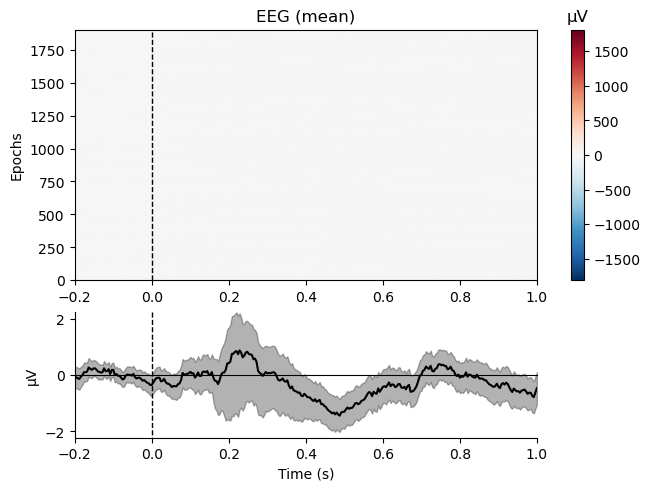

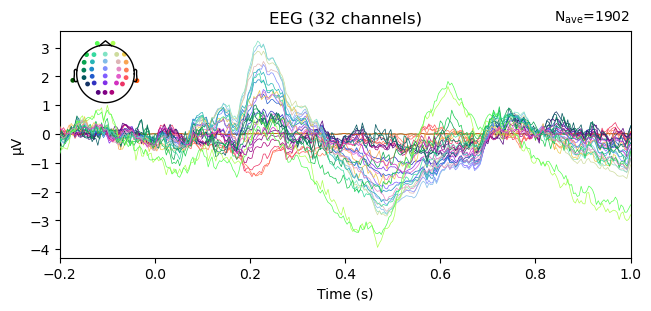

Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Effective window size : 8.192 (s)


/opt/anaconda3/lib/python3.12/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)
/opt/anaconda3/lib/python3.12/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)
/opt/anaconda3/lib/python3.12/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Plotting power spectral density (dB=True).
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).


/opt/anaconda3/lib/python3.12/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)
/opt/anaconda3/lib/python3.12/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)
/opt/anaconda3/lib/python3.12/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


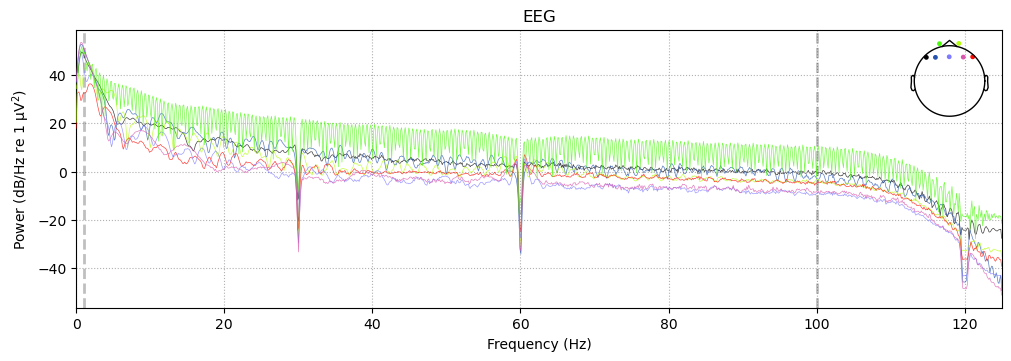

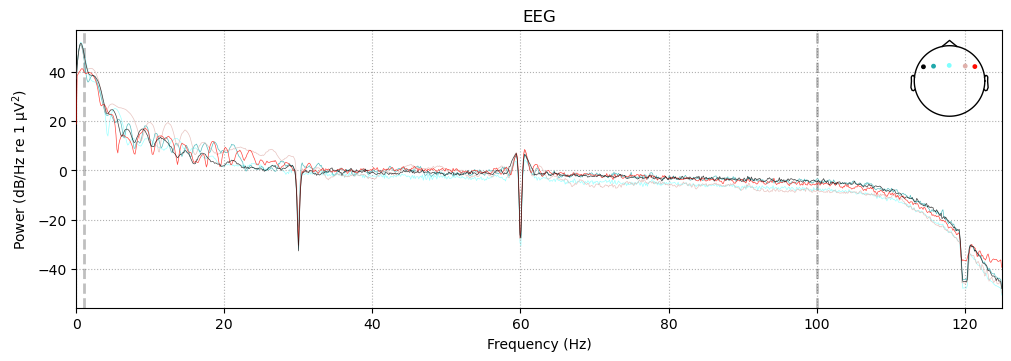

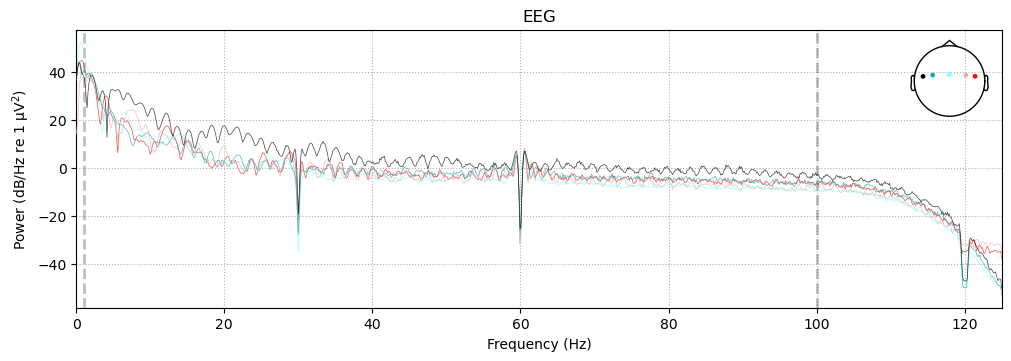

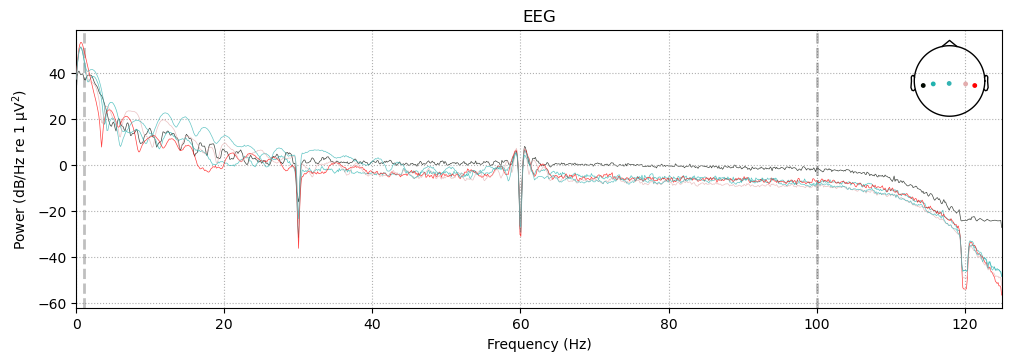

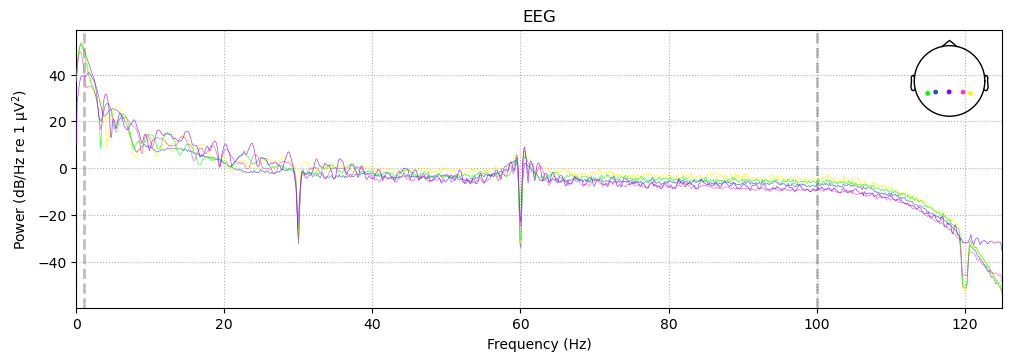

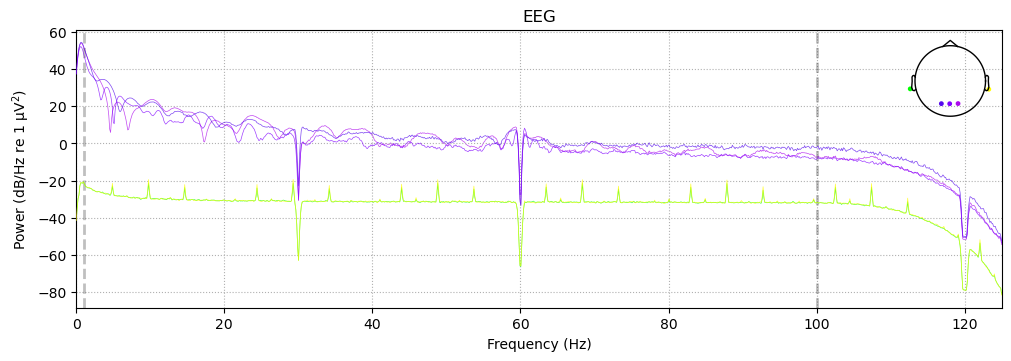

In [165]:
# -----------------
bad_channels = [
    # 'FT8'
]
#------------------

# manually select a file
file = 'KCUE2025_0003_VOT_corr.fif'

# directory
input_dir = work_dir + 'Data/data_korean/eeg_preprocessed/1_trigger_latency_corrected/'
output_dir = work_dir + 'eeg_preprocessed_NEW/3_manual_bad_channel_detect/korean/'

# get all file names in the folder
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)

# read in file
raw = mne.io.read_raw_fif(input_dir + file, preload = True)

# drop reference channels
raw.drop_channels(['M1', 'M2'])

# rename channels
mne.rename_channels(raw.info, mapping=chan_mapping)

# filter
raw.filter(l_freq = f_low, h_freq = f_high)
# notch filter to remove line noise
freqs = np.arange(line_freq, f_res/2, line_freq)
# some files has 30 hz noise
freqs = np.append(30, freqs)
raw.notch_filter(freqs=freqs)

# resample
raw.resample(sfreq = f_res)

# mark bad channel
raw.info['bads'] = bad_channels

# add the channel loc info
raw.set_montage(montage)

# check information
print(raw.info)

# event distributions
events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')

# segmentation for ERP
epochs = mne.Epochs(
    raw,
    events = events_from_annot, event_id = event_dict,
    tmin = -0.2, tmax = 1,
    # apply baseline correction
    # baseline = None,
    # remove epochs that meet the rejection criteria
    reject = None,
    preload = True,
)

# print file name
print('==========================================')
print(f'===== FILE: {file} =====')
print('==========================================')

# plot epochs
epochs.plot_image(combine="mean")

# butterfly
epochs.average().plot()
plt.show()


# if needed, plot a spectrum for fewer channels together
# korean
raw.compute_psd(picks = ['Fp1', 'Fp2', 'F7','F3','Fz','F4','F8']).plot(amplitude=False)
raw.compute_psd(picks = ['FT7', 'FC3', 'FCz','FC4','FT8']).plot(amplitude=False)
raw.compute_psd(picks = ['T7', 'C3', 'Cz','C4','T8']).plot(amplitude=False)
raw.compute_psd(picks = ['TP7', 'CP3', 'CPz','CP4','TP8']).plot(amplitude=False)
raw.compute_psd(picks = ['P7', 'P3', 'Pz','P4','P8']).plot(amplitude=False)
raw.compute_psd(picks = ['O1', 'Oz', 'O2']).plot(amplitude=False)

plt.show()

## save and log

In [158]:
all_output = os.listdir(output_dir)

# initialize a log file for epochs containing super big noise
if ('manual_bad_channel_log.txt' not in all_output):
    with open(output_dir + '/manual_bad_channel_log.txt', 'a+') as f:
        f.write('file' + '\t' + 'bad_channels' + '\n')

# save
if (file.split('.')[0]+ '_bads.fif' not in all_output):
    
    # save
    raw.save(output_dir + file.split('.')[0]+ '_bads.fif')
            
    # log
    with open(output_dir + '/manual_bad_channel_log.txt', 'a+') as f:
                f.write(file + '\t' + str(raw.info['bads']) + '\n')

Writing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_manual_bad_channel_detect/korean/KCUE2025_0024_VOT_corr_bads.fif


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/714674289.py:12: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_manual_bad_channel_detect/korean/KCUE2025_0024_VOT_corr_bads.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw.save(output_dir + file.split('.')[0]+ '_bads.fif')


Closing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_manual_bad_channel_detect/korean/KCUE2025_0024_VOT_corr_bads.fif
[done]


# Epoch, RANSAC and ICA
* add back reference channel
* Epoch
* average re-reference
* RANSAC for further bad channel detection

In [166]:
#### parameters ####

# directory
input_dir = work_dir + 'eeg_preprocessed_NEW/3_manual_bad_channel_detect/korean/'
output_dir = work_dir + 'eeg_preprocessed_NEW/4_epochs/korean/'

# define start and end time point for filting (epochs can overlap)
t_start_filt = -0.7
t_end_filt = 1.5

# define start and end time point
t_start_epoch = -0.1
t_end_epoch = 0.7

# use big cutoff to reject explosives/mechanical noise
reject_criteria = dict(eeg = 500e-6)


# get all file names in the folder
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)

# initialize a log file for epochs containing super big noise
if ('epoch_big_noise_log.txt' not in all_output):
    with open(output_dir + '/epoch_big_noise_log.txt', 'a+') as f:
        f.write('file' + '\t' + 'n_goodTrials' +  '\t' + 'rate_goodTrials' + '\n')

# initialize a log file for ransac and ica
if ('ransac_and_ica_log.txt' not in all_output):
    with open(output_dir + '/ransac_and_ica_log.txt', 'a+') as f:
        f.write('file' + '\t' + 'bad_channels' +  '\t' + 'excluded_components' + '\t' + 'n_excluded' + '\n')

# run artifact correction
for file in all_input:
    if file.endswith("bads.fif") and (file.split('.')[0]+ '_bads_ica.fif' not in all_output):

        # read in file
        raw = mne.io.read_raw_fif(input_dir + file, preload=True)

        # add the channel loc info
        raw.set_montage(montage)

        # get event info for segmentation
        events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        
        # segmentation for detecting super noise
        # Here we reject trial containing super large artifacts (explosives/mechanical noise), that's why we don't apply re-reference before epoch
        epochs = mne.Epochs(
            raw,
            events = events_from_annot, event_id = event_dict,
            tmin = t_start_filt, tmax = t_end_filt,
            baseline = None, # Important: No baseline correction before ICA
            # remove epochs that meet the rejection criteria
            reject = reject_criteria,
            preload = True,
        )
        
        # =============================================
        # log epoch info
        # =============================================
        # the good trial rate has to be high, otherwise the data need to be excluded...
        for k, v in event_dict.items():
            
            # good trial count
            n_goodTrials = len(epochs[k])
            
            # # remove 0 trial event
            # if n_goodTrials==0:
            #     del epochs.event_id[k]
                
            # good trial rate
            rate_goodTrials = round( n_goodTrials/sum(events_from_annot[:,2]==v), 2 )
            
            # record epoch summary
            with open(output_dir + 'epoch_big_noise_log.txt', 'a+') as f:
                f.write(file + '\t' + k + '\t' + str(n_goodTrials) + '\t' + str(rate_goodTrials) + '\n')

    
        # =================================================
        # Creating 1Hz copy for training (RANSAC + ICA)
        # =================================================
        print("Creating 1Hz copy for training (RANSAC + ICA)...")
        
        # 1. Create Copy & Filter
        epochs_filt = epochs.copy().filter(l_freq=1, h_freq=100)
        # average reference
        epochs_filt.set_eeg_reference('average')
        
        # 2. Crop Copy (delete the edge artifacts)
        epochs_filt.crop(tmin=t_start_epoch, tmax=t_end_epoch)
        
        # 3. Run RANSAC (On 1Hz Copy)
        # Fp1/Fp2 are 'eeg', so RANSAC checks them.
        print("Running RANSAC...")
        # use default ransac parameters
        ransac = Ransac()
        # fit
        ransac.fit(epochs_filt)
        print(f'ransac detected bad channels: {ransac.bad_chs_}')
        
        # Check if RANSAC tried to kill blink channels, if it does, add them back.
        for bad_ch in ransac.bad_chs_:
            if bad_ch in ['Fp1', 'Fp2']:
                print(f"WARNING: RANSAC marked {bad_ch} as bad. Keeping it anyway for ICA.")
            # add newly detected bad channels
            elif bad_ch not in epochs.info['bads']:
                epochs.info['bads'].append(bad_ch)

        print(f"Total Bad Channels: {epochs.info['bads']}")

        # save
        # crop the buffer (it served its purpose for the filter)
        epochs.crop(tmin=t_start_epoch, tmax=t_end_epoch)
        epochs.save(output_dir + file.split('.')[0]+ '_bads.fif')
            
        # Important: Sync bads to the filtered copy so ICA ignores them too
        epochs_filt.info['bads'] = epochs.info['bads']
        # save ica input
        epochs_filt.save(output_dir + file.split('.')[0]+ '_bads_icaInput.fif')

        # 4. run ICA (On 1Hz Copy)
        # initialize ica parameters
        ica = mne.preprocessing.ICA(
            # use ‘extended infomax’ method for fitting the ICA, to comply with the ICLabel requirements
            method = 'infomax', 
            fit_params = dict(extended=True),
            random_state = 42,
        )
        ica.fit(epochs_filt)
        # save ica solutions
        ica.save(output_dir + file.split('.')[0]+ '_bads_icaSolution.fif')
        
        # 5. ICLabel
        ic_labels = label_components(epochs_filt, ica, method="iclabel")
        labels = ic_labels["labels"]
        probs = ic_labels['y_pred_proba']
        
        # pick components to exclude
        exclude_idx = [ ind for ind, label in enumerate(labels) if label not in ["brain", "other"] and probs[ind]>0.9 ]
        print(f"ICA Components to remove: {exclude_idx}")

        # record the bad ICs in bad_ICs.txt
        with open(output_dir + '/ransac_and_ica_log.txt', 'a+') as f:
            f.write(file + '\t' + str(epochs.info['bads']) + '\t' + str(exclude_idx) + '\t' + str(len(exclude_idx)) + '\n')
        
    
        # =================================================
        # APPLY TO FINAL DATA (0.5 Hz)
        # =================================================

        # add back the reference channel
        # epochs = mne.add_reference_channels(epochs, 'TP9')
        # epochs.set_montage(montage)
        # NOTE: add reference channels one by one to avoid the bug that overlaps reference channels if added simultaneously
        # add back the reference channel
        # epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
        # epochs.set_montage(montage)
        # epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])
        # epochs.set_montage(montage)
        
        # Apply ICA Weights
        ica.apply(epochs, exclude=exclude_idx)

        # save ica corrected data
        epochs.save(output_dir + file.split('.')[0]+ '_bads_ica.fif')

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_manual_bad_channel_detect/korean/KCUE2025_0011_VOT_corr_bads.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/651050717.py:38: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_manual_bad_channel_detect/korean/KCUE2025_0011_VOT_corr_bads.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload=True)


    Range : 0 ... 1137449 =      0.000 ...  4549.796 secs
Ready.
Reading 0 ... 1137449  =      0.000 ...  4549.796 secs...
Not setting metadata
1922 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 1922 events and 551 original time points ...
    Rejecting  epoch based on EEG : ['FC3', 'F3']
    Rejecting  epoch based on EEG : ['C3', 'FC3', 'F3']
2 bad epochs dropped
Creating 1Hz copy for training (RANSAC + ICA)...
Setting up band-pass filter from 1 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 825 samples (3

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/651050717.py:85: RuntimeWarning: filter_length (825) is longer than the signal (551), distortion is likely. Reduce filter length or filter a longer signal.
  epochs_filt = epochs.copy().filter(l_freq=1, h_freq=100)


EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Running RANSAC...


  0%|          | interpolating channels : 0/50 [00:00<?,       ?it/s]

... (633 outputs left out)

Fitting ICA to data using 30 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 29 components
Computing Extended Infomax ICA
Fitting ICA took 178.8s.
Writing ICA solution to /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0004_VOT_corr_bads_bads_icaSolution.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/651050717.py:131: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0004_VOT_corr_bads_bads_icaSolution.fif) does not conform to MNE naming conventions. All ICA files should end with -ica.fif, -ica.fif.gz, _ica.fif or _ica.fif.gz
  ica.save(output_dir + file.split('.')[0]+ '_bads_icaSolution.fif')


ICA Components to remove: [1, 2, 27]
Applying ICA to Epochs instance
    Transforming to ICA space (29 components)
    Zeroing out 3 ICA components
    Projecting back using 30 PCA components


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/651050717.py:165: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0004_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs.save(output_dir + file.split('.')[0]+ '_bads_ica.fif')


## manual check ICA and interpolate bad channels

In [ ]:
#### parameters ####

# directory
input_dir = work_dir + 'eeg_preprocessed_NEW/4_epochs/'

# get all file names in the folder
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


file = 'CUE2024_0035_VOT_corr_filt_bads_epo.fif'

# read in epoched file
epochs = mne.read_epochs(input_dir + file, preload=True)

# read in ica input
ica_input = mne.read_epochs(input_dir + file.split('.')[0] + '_icaInput.fif')

# read in ica solution
ica = mne.preprocessing.read_ica(input_dir + file.split('.')[0] + '_icaSolution.fif')

# ICLabel
ic_labels = label_components(ica_input, ica, method="iclabel")
labels = ic_labels["labels"]
probs = ic_labels['y_pred_proba']

# remove components
exclude_idx = [ ind for ind, label in enumerate(labels) if label not in ["brain", "other"] and probs[ind]>0.9 ]


# print the file name
print(file)
print()

# get the label and probability of ICs
for idx in range(15):
    print( 'ICA' + f"{idx:03}" + ': ' + labels[idx] + ' - ' + str(round(probs[idx], ndigits=4)) )
print()

print(exclude_idx)

# plot topos
ica.plot_components()
plt.show()


# Continuous waveforms for components.
ica.plot_sources(ica_input,
                 start = 310, stop = 320,
                 show_scrollbars=False)
plt.show()

## further diagnosis

In [ ]:
# further diagnosis
ica.plot_properties(ica_input, picks=range(0,10), verbose='WARNING')
plt.show()

## IC to exclude

In [ ]:
# manually enter ICs to exclude
exclude_idx = [0, 4, 25]

# compare waveforms before vs after removing components
ica.plot_overlay(epochs.average(), exclude=exclude_idx)
plt.show()

## save

In [ ]:
output_dir = work_dir + 'eeg_preprocessed_NEW/4_epochs/manual'

# record the bad ICs in bad_ICs.txt
with open(output_dir + '/manual_ica_log.txt', 'a+') as f:
    f.write(file + '\t' + str(epochs.info['bads']) + '\t' + str(exclude_idx) + '\t' + str(len(exclude_idx)) + '\n')


# =================================================
# APPLY TO FINAL DATA (0.5 Hz)
# =================================================

# Apply ICA Weights
ica.apply(epochs, exclude=exclude_idx)

# save ica corrected data
epochs.save(output_dir + file.split('.')[0]+ '_epo_ica.fif')

# autoreject, and evokeds
segmenting continuous EEG into epochs, then autoreject, then evoked
- re-reference
- segmentation

Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0015_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1981 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0015_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

... (7 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/430 [00:00<?,       ?it/s]

Dropped 34 epochs: 14, 32, 69, 91, 95, 96, 97, 168, 169, 176, 192, 201, 207, 224, 234, 239, 241, 242, 245, 246, 247, 249, 250, 266, 282, 286, 288, 311, 312, 327, 338, 346, 361, 388


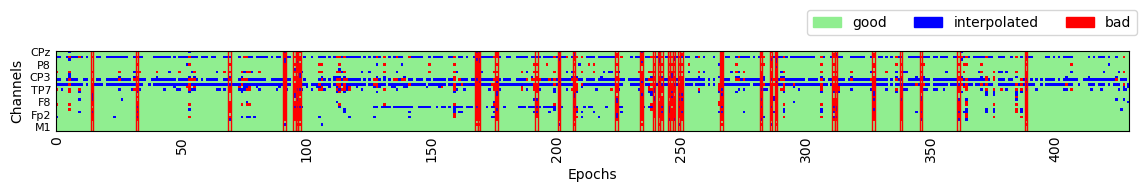

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 31, 36, 37, 47, 62, 66


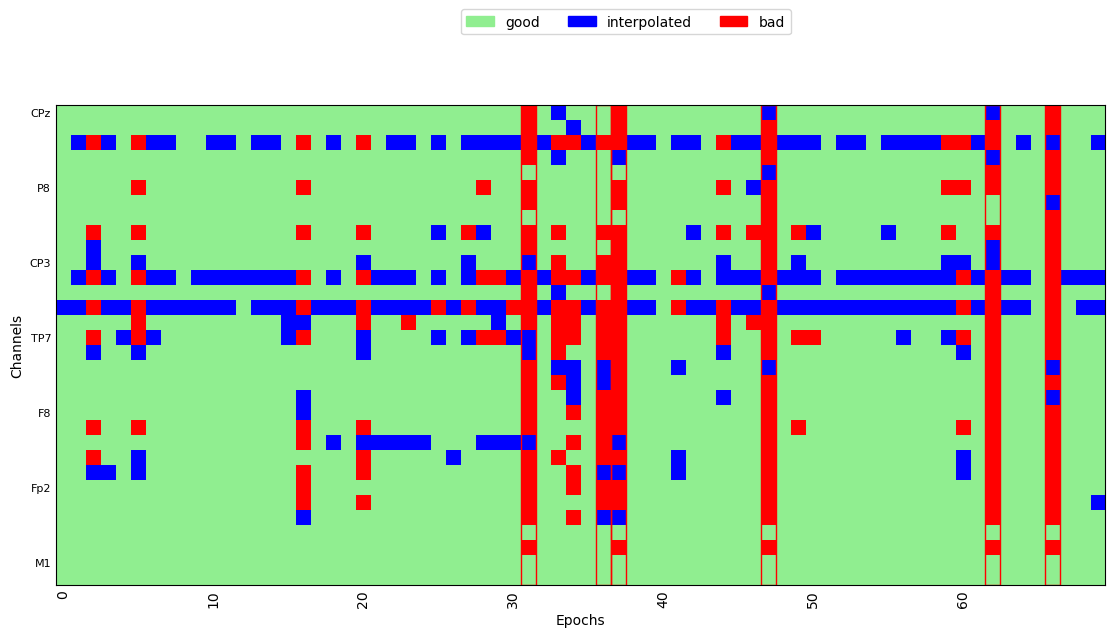

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/440 [00:00<?,       ?it/s]

Dropped 34 epochs: 27, 37, 84, 115, 123, 129, 149, 150, 156, 166, 168, 174, 175, 179, 182, 183, 193, 196, 197, 213, 222, 227, 245, 246, 292, 295, 317, 339, 365, 375, 386, 425, 426, 427


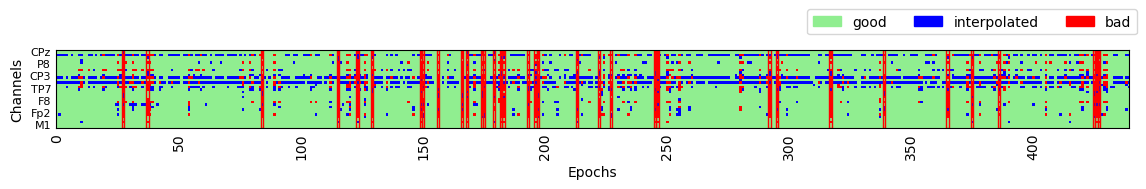

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 3, 8, 43, 62, 65


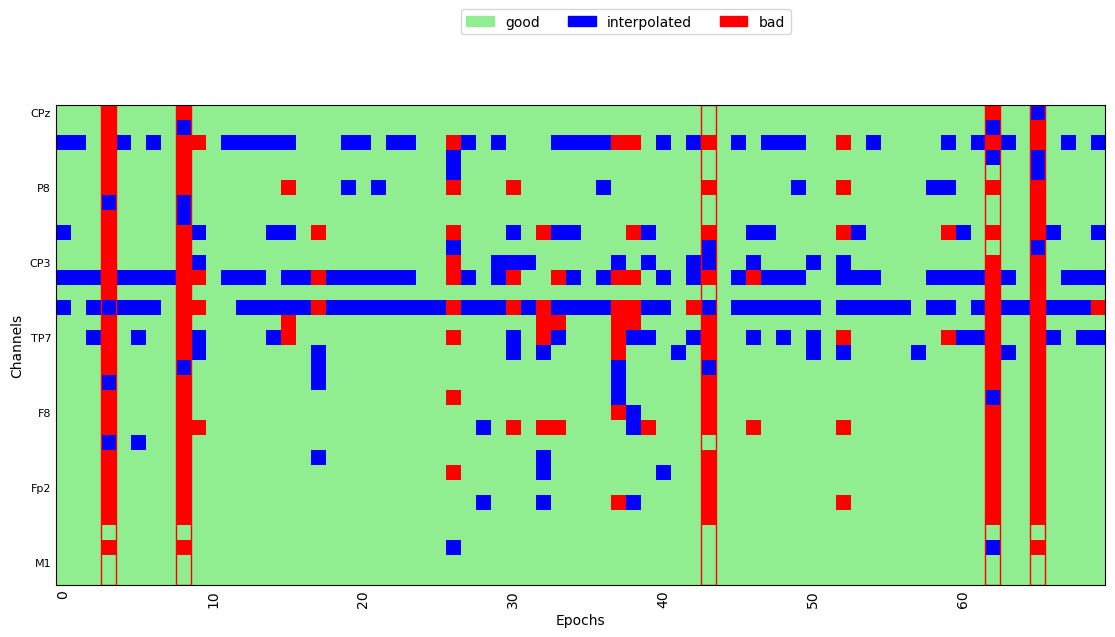

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/419 [00:00<?,       ?it/s]

Dropped 29 epochs: 0, 4, 5, 24, 52, 73, 127, 133, 138, 182, 186, 191, 192, 232, 234, 295, 301, 303, 306, 311, 319, 329, 331, 334, 341, 342, 362, 375, 376


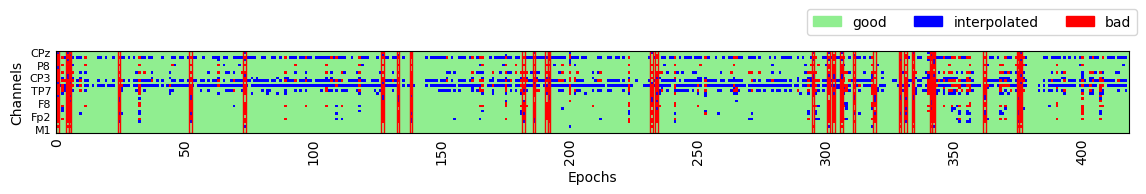

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 0, 4, 32, 36, 40, 46


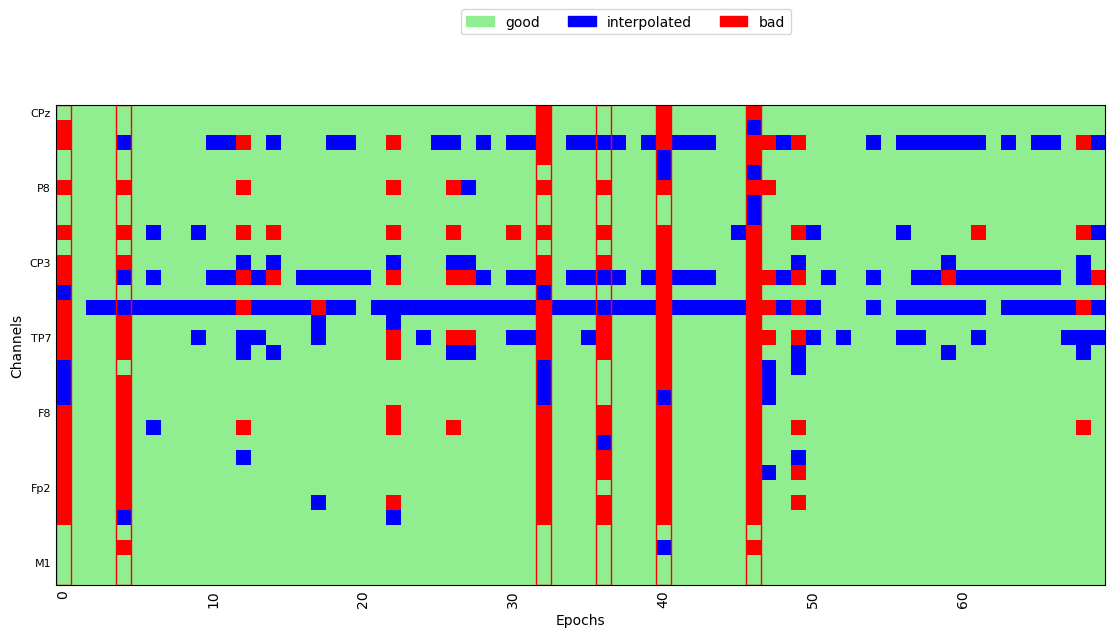

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/412 [00:00<?,       ?it/s]

Dropped 41 epochs: 34, 36, 51, 55, 57, 68, 84, 87, 89, 95, 97, 98, 99, 104, 106, 107, 109, 112, 121, 137, 138, 151, 183, 190, 198, 205, 218, 252, 268, 275, 288, 300, 307, 309, 323, 324, 329, 369, 373, 405, 410


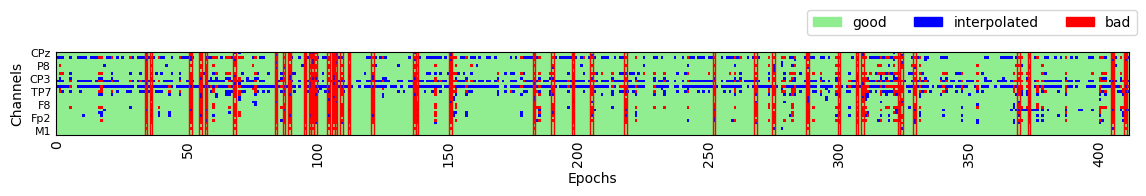

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 3, 22, 31, 35, 50, 68


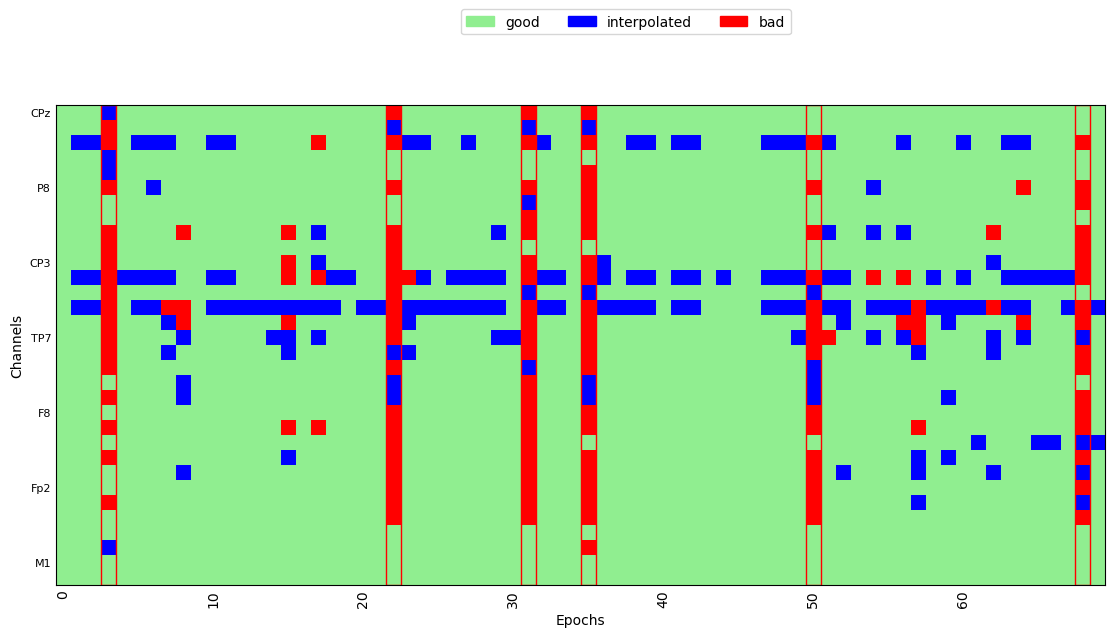

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0008_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1924 matching events found
No baseline correction applied
0 projection items activated
Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0008_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_c

  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/1924 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

... (5 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/408 [00:00<?,       ?it/s]

Dropped 102 epochs: 0, 2, 3, 7, 13, 16, 19, 22, 23, 27, 29, 30, 31, 33, 34, 39, 40, 47, 50, 61, 67, 69, 73, 77, 81, 83, 89, 97, 104, 108, 110, 124, 125, 131, 135, 136, 138, 141, 146, 148, 154, 155, 156, 175, 181, 195, 196, 205, 209, 211, 215, 217, 221, 222, 225, 228, 230, 232, 233, 234, 239, 240, 242, 251, 253, 258, 264, 269, 275, 284, 286, 289, 296, 303, 307, 308, 309, 310, 312, 322, 327, 329, 331, 332, 335, 342, 344, 349, 355, 361, 370, 372, 374, 375, 376, 378, 383, 384, 387, 392, 396, 398


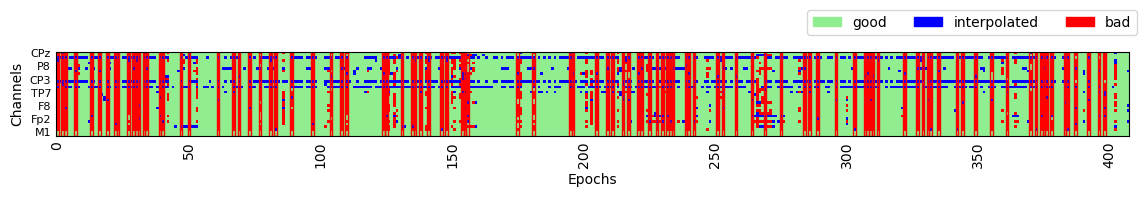

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 15 epochs: 1, 5, 9, 10, 17, 18, 19, 22, 37, 47, 51, 53, 54, 60, 62


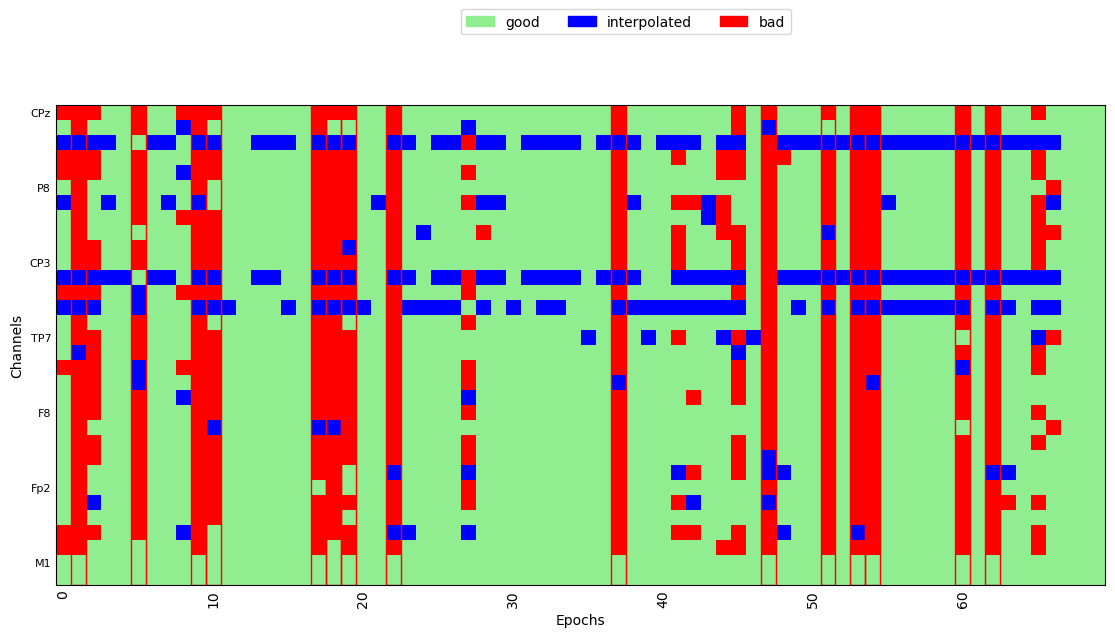

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/413 [00:00<?,       ?it/s]

Dropped 113 epochs: 0, 4, 8, 12, 22, 27, 30, 35, 38, 40, 47, 50, 61, 73, 78, 90, 91, 92, 93, 102, 112, 114, 118, 121, 122, 127, 130, 132, 137, 142, 143, 145, 151, 152, 153, 157, 161, 164, 165, 168, 172, 174, 175, 176, 177, 179, 180, 183, 185, 186, 187, 196, 210, 213, 218, 221, 225, 234, 241, 245, 248, 255, 257, 262, 267, 268, 269, 270, 273, 275, 280, 283, 284, 286, 290, 296, 299, 300, 303, 313, 314, 320, 329, 342, 343, 344, 345, 353, 358, 359, 361, 362, 363, 369, 370, 372, 374, 376, 377, 378, 381, 386, 394, 399, 400, 402, 403, 404, 407, 408, 409, 410, 411


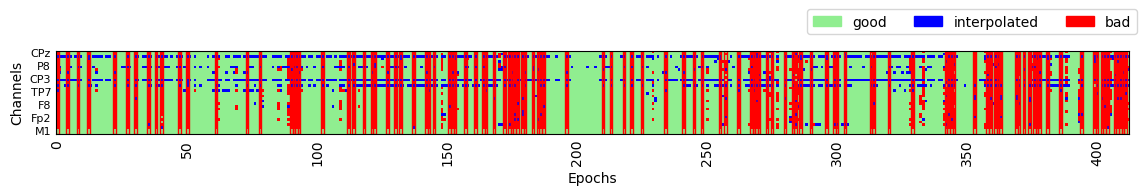

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 26 epochs: 3, 5, 9, 12, 14, 18, 20, 22, 24, 28, 29, 33, 37, 38, 40, 41, 45, 49, 57, 58, 60, 62, 63, 65, 66, 69


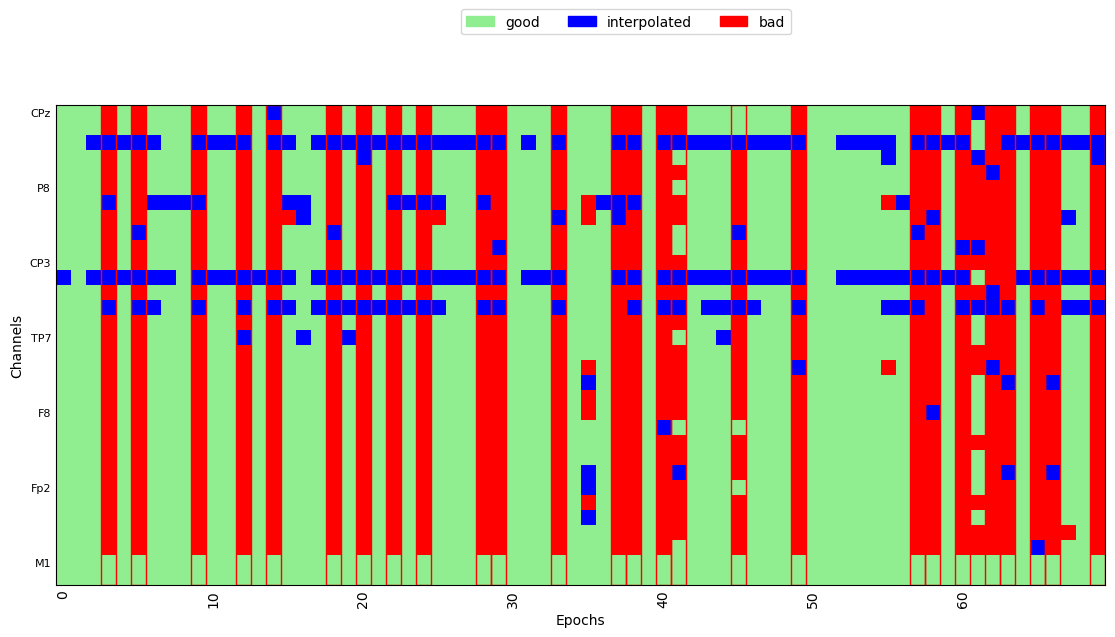

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/411 [00:00<?,       ?it/s]

Dropped 143 epochs: 3, 14, 17, 18, 32, 42, 49, 51, 52, 58, 60, 61, 62, 63, 64, 66, 67, 68, 69, 70, 71, 72, 73, 78, 83, 88, 89, 92, 99, 102, 103, 108, 110, 111, 112, 115, 116, 117, 118, 120, 121, 122, 124, 125, 128, 131, 135, 136, 138, 141, 147, 149, 151, 161, 169, 183, 195, 200, 202, 205, 207, 208, 209, 210, 213, 215, 216, 217, 220, 221, 223, 224, 225, 226, 227, 228, 229, 230, 236, 237, 238, 239, 241, 242, 243, 250, 252, 253, 254, 255, 258, 260, 261, 262, 263, 264, 267, 268, 269, 272, 274, 275, 276, 277, 278, 279, 281, 282, 283, 287, 290, 296, 298, 301, 302, 303, 305, 306, 312, 313, 322, 323, 330, 331, 333, 342, 345, 357, 359, 360, 362, 364, 369, 374, 375, 376, 378, 389, 390, 396, 400, 401, 403


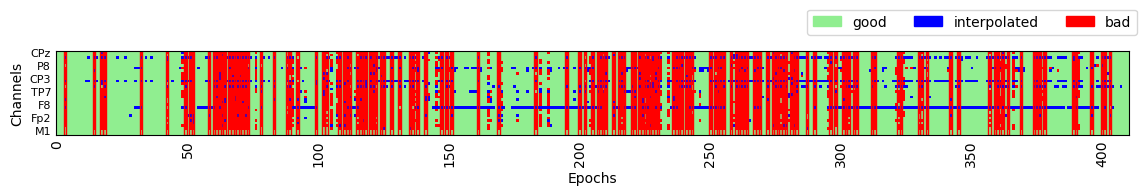

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 26 epochs: 3, 5, 9, 12, 13, 18, 21, 22, 24, 27, 32, 34, 37, 39, 40, 41, 43, 44, 49, 50, 52, 53, 55, 58, 60, 63


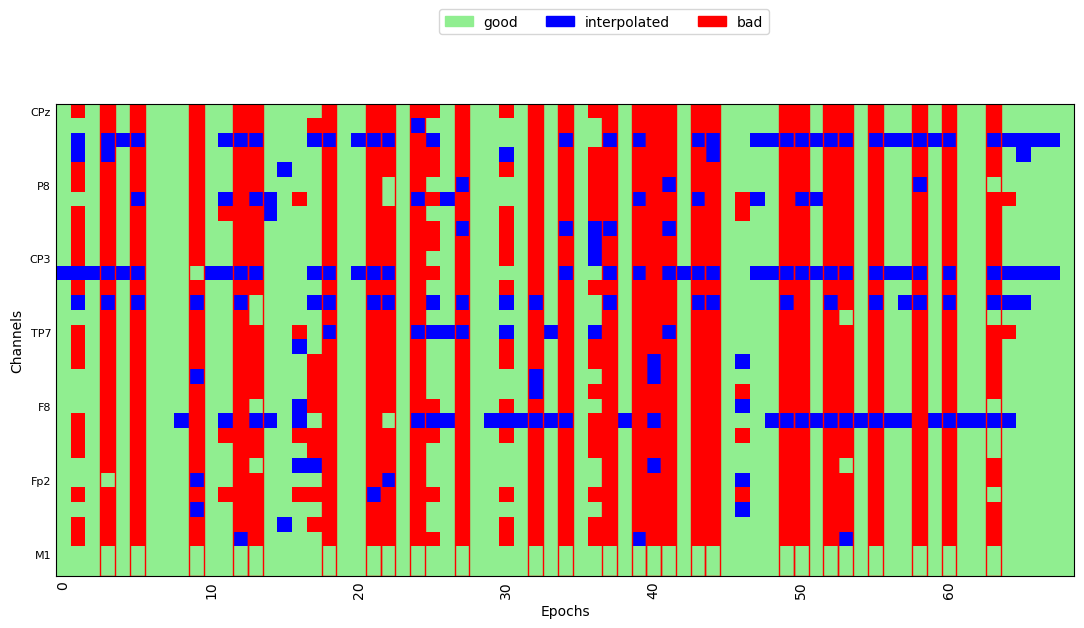

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/413 [00:00<?,       ?it/s]

Dropped 47 epochs: 0, 1, 2, 3, 12, 17, 18, 19, 24, 27, 31, 35, 39, 41, 43, 52, 66, 77, 92, 93, 125, 127, 140, 143, 150, 153, 184, 192, 210, 220, 261, 292, 295, 317, 318, 319, 330, 333, 344, 346, 347, 349, 359, 372, 373, 374, 398


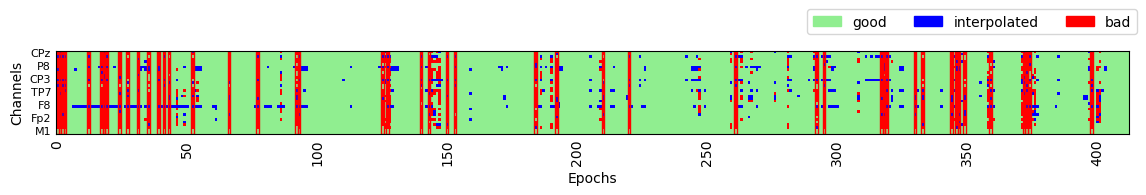

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 10 epochs: 0, 3, 6, 8, 10, 24, 26, 37, 39, 69


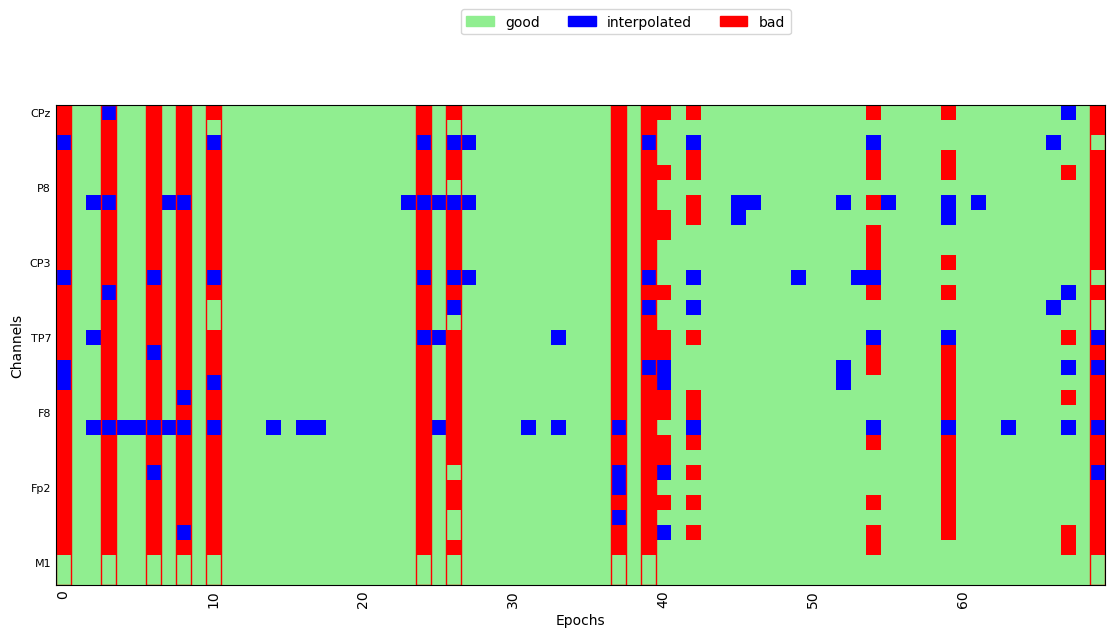

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0023_VOT_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1942 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0023_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

... (7 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=1


  0%|          | Repairing epochs : 0/415 [00:00<?,       ?it/s]

Dropped 33 epochs: 10, 22, 23, 45, 63, 73, 110, 120, 160, 165, 169, 170, 181, 187, 188, 189, 225, 231, 280, 288, 292, 300, 307, 313, 315, 317, 322, 325, 354, 358, 394, 396, 413


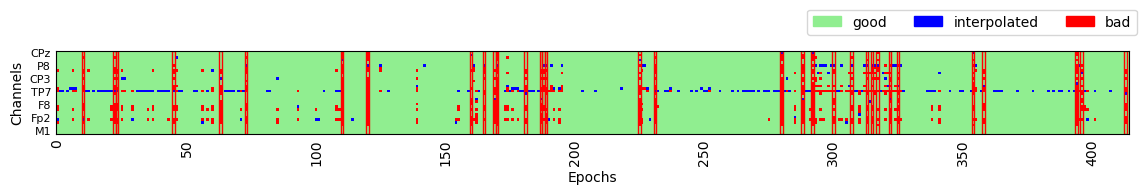

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 16, 29


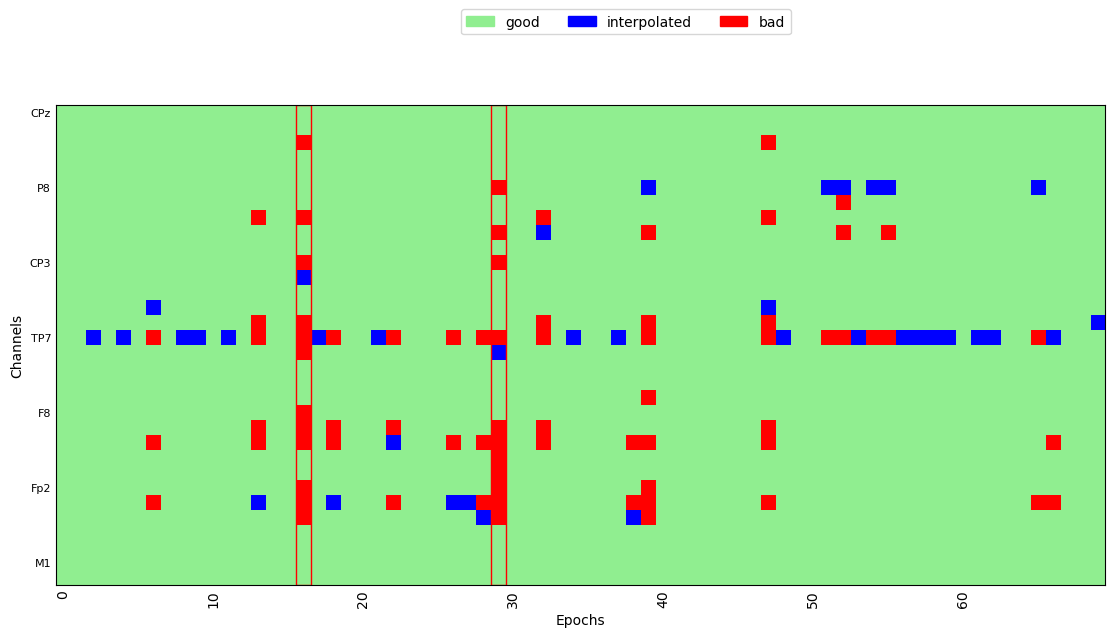

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/407 [00:00<?,       ?it/s]

Dropped 40 epochs: 7, 17, 18, 51, 63, 66, 70, 71, 75, 77, 95, 105, 110, 112, 114, 115, 135, 136, 139, 142, 156, 165, 179, 180, 192, 193, 195, 207, 210, 211, 213, 215, 244, 265, 288, 290, 302, 310, 324, 400


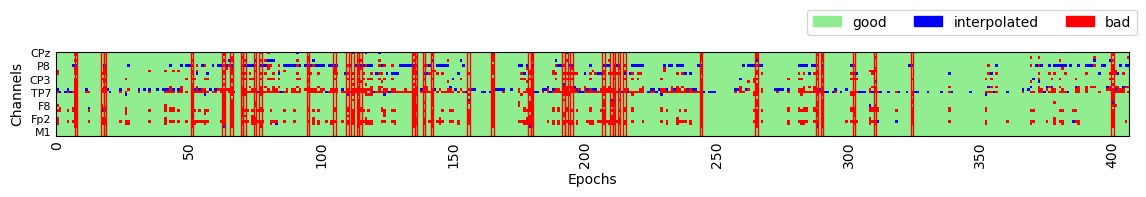

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 7 epochs: 20, 30, 31, 35, 44, 58, 65


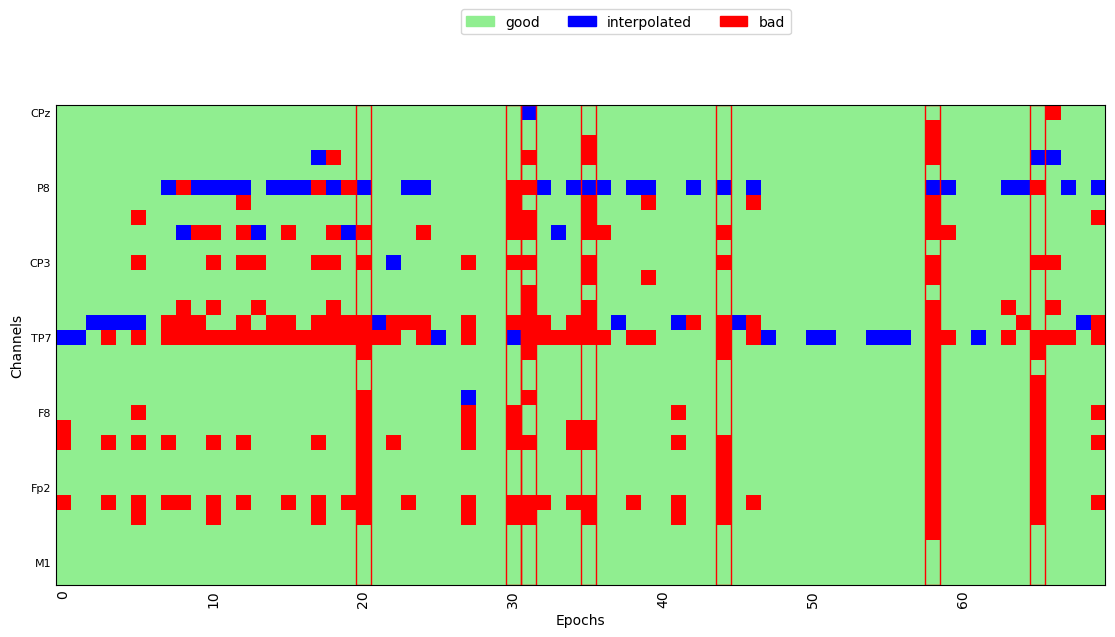

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/433 [00:00<?,       ?it/s]

Dropped 29 epochs: 6, 23, 26, 33, 34, 35, 37, 41, 55, 92, 104, 111, 129, 137, 145, 171, 194, 215, 216, 218, 288, 305, 313, 347, 352, 362, 368, 372, 432


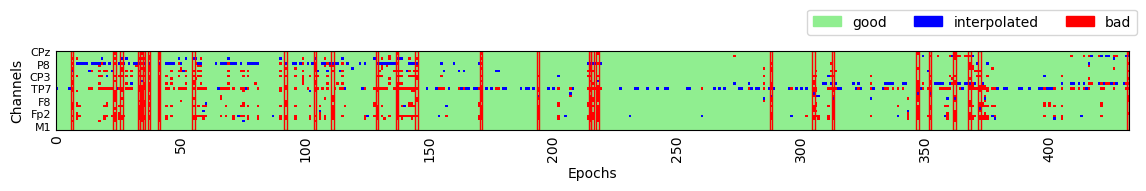

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 19, 22, 25, 59, 66


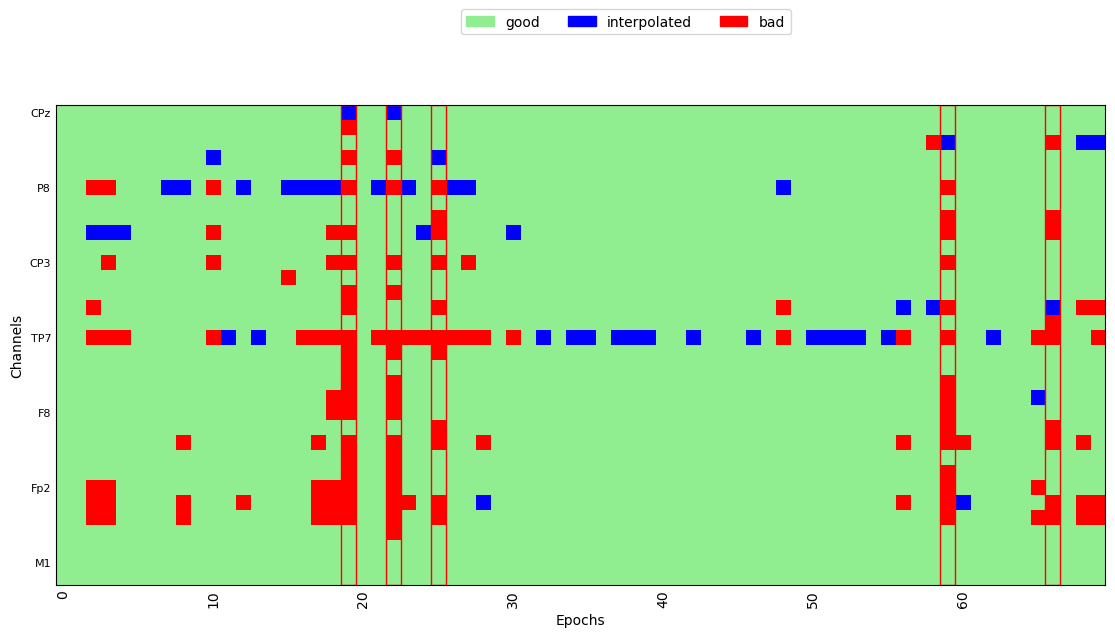

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/407 [00:00<?,       ?it/s]

Dropped 36 epochs: 14, 23, 39, 40, 44, 69, 71, 81, 97, 177, 184, 188, 192, 193, 236, 261, 278, 295, 298, 312, 317, 321, 324, 327, 352, 353, 364, 366, 369, 373, 380, 381, 382, 384, 385, 386


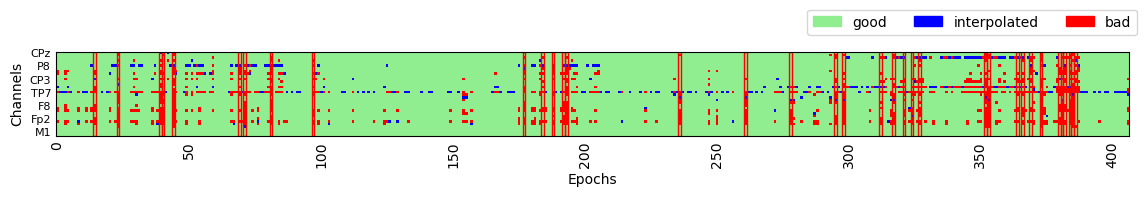

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 4, 53, 54, 58, 64


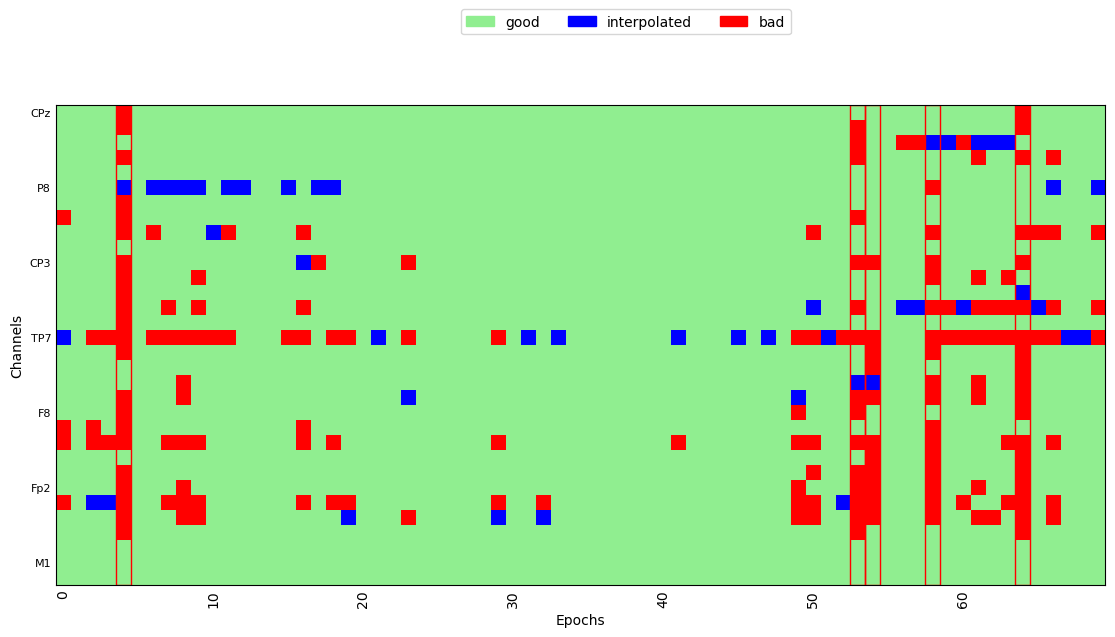

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0016_VOT_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
2010 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0016_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

... (7 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=1


  0%|          | Repairing epochs : 0/444 [00:00<?,       ?it/s]

Dropped 162 epochs: 4, 6, 11, 13, 17, 23, 31, 33, 39, 41, 45, 53, 62, 66, 78, 79, 81, 84, 85, 87, 89, 98, 100, 101, 104, 106, 107, 108, 109, 110, 111, 114, 115, 119, 123, 125, 128, 132, 133, 137, 143, 144, 145, 146, 149, 150, 151, 154, 155, 156, 158, 159, 160, 163, 168, 171, 173, 174, 177, 181, 188, 189, 190, 191, 192, 197, 199, 200, 201, 204, 208, 211, 212, 214, 222, 225, 229, 234, 239, 248, 249, 250, 251, 253, 254, 259, 263, 266, 267, 272, 274, 276, 279, 283, 284, 286, 287, 289, 290, 292, 294, 296, 297, 300, 307, 308, 309, 310, 311, 312, 319, 320, 322, 324, 326, 330, 333, 334, 337, 339, 342, 343, 345, 347, 351, 353, 356, 357, 358, 359, 363, 369, 370, 376, 380, 381, 382, 383, 384, 386, 388, 389, 390, 392, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 412, 417, 421, 425, 426, 432, 438


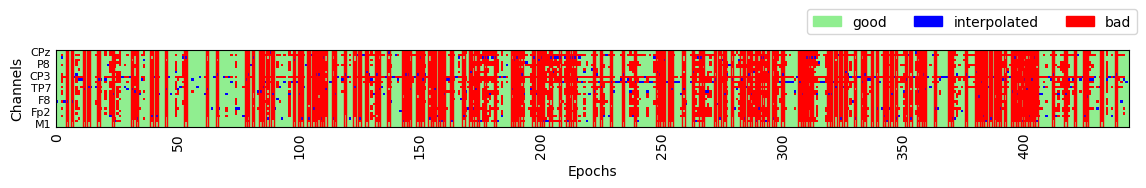

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 20 epochs: 2, 9, 12, 13, 23, 28, 32, 35, 38, 39, 41, 42, 47, 50, 54, 60, 62, 65, 67, 68


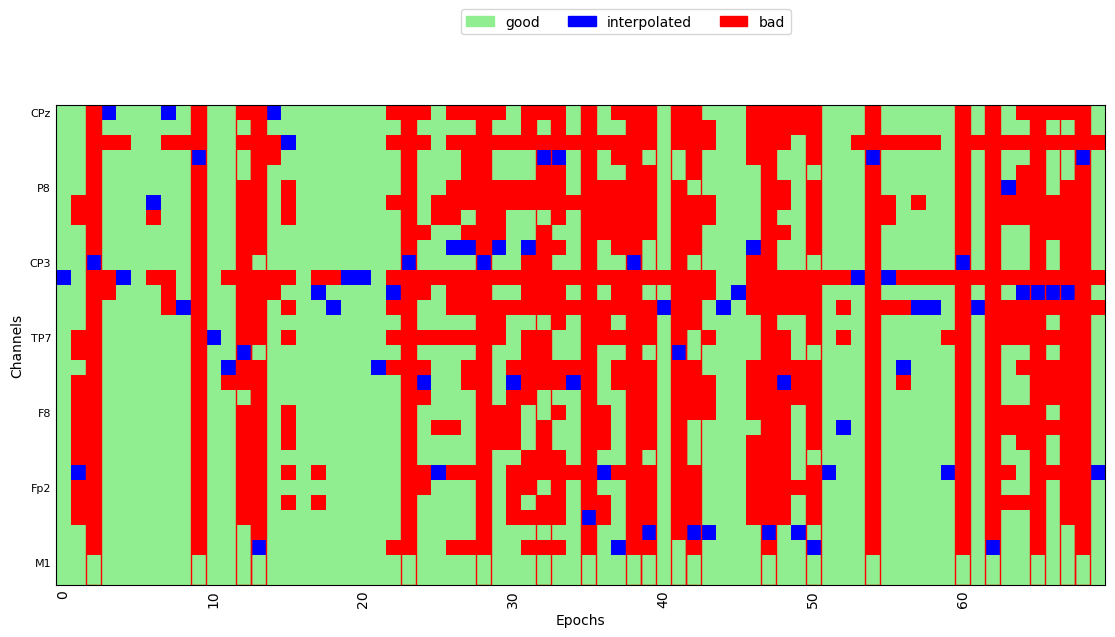

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/437 [00:00<?,       ?it/s]

Dropped 181 epochs: 0, 1, 2, 4, 6, 7, 8, 12, 19, 20, 23, 29, 30, 33, 36, 37, 43, 44, 47, 49, 51, 57, 59, 63, 66, 68, 69, 76, 79, 83, 84, 86, 88, 89, 90, 91, 92, 93, 95, 97, 98, 99, 100, 101, 102, 105, 108, 109, 110, 111, 112, 113, 114, 116, 119, 120, 123, 124, 127, 128, 132, 133, 135, 140, 141, 145, 147, 148, 153, 154, 155, 156, 162, 174, 179, 183, 187, 188, 193, 195, 198, 199, 200, 201, 203, 208, 217, 224, 227, 229, 232, 234, 235, 237, 239, 240, 242, 243, 246, 247, 248, 249, 253, 255, 260, 263, 264, 265, 266, 268, 269, 272, 273, 276, 279, 281, 282, 284, 286, 288, 289, 290, 291, 292, 295, 296, 297, 303, 316, 319, 322, 323, 335, 342, 343, 344, 345, 350, 351, 353, 358, 360, 361, 363, 367, 371, 372, 374, 379, 382, 384, 385, 389, 390, 391, 392, 393, 394, 396, 397, 399, 400, 402, 403, 404, 405, 406, 407, 408, 410, 411, 413, 416, 417, 420, 421, 422, 423, 427, 428, 434


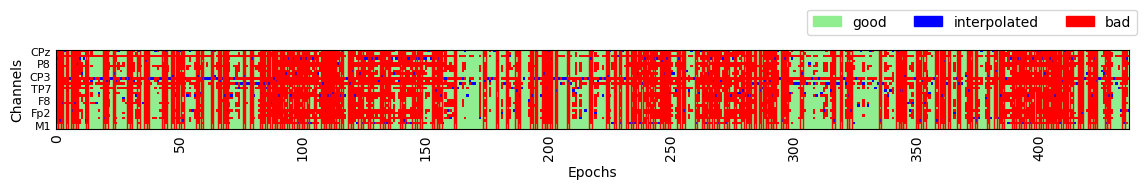

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 34 epochs: 0, 3, 6, 7, 8, 9, 11, 12, 14, 15, 16, 17, 18, 19, 20, 22, 23, 30, 33, 34, 35, 36, 38, 40, 41, 42, 45, 53, 54, 59, 62, 63, 64, 66


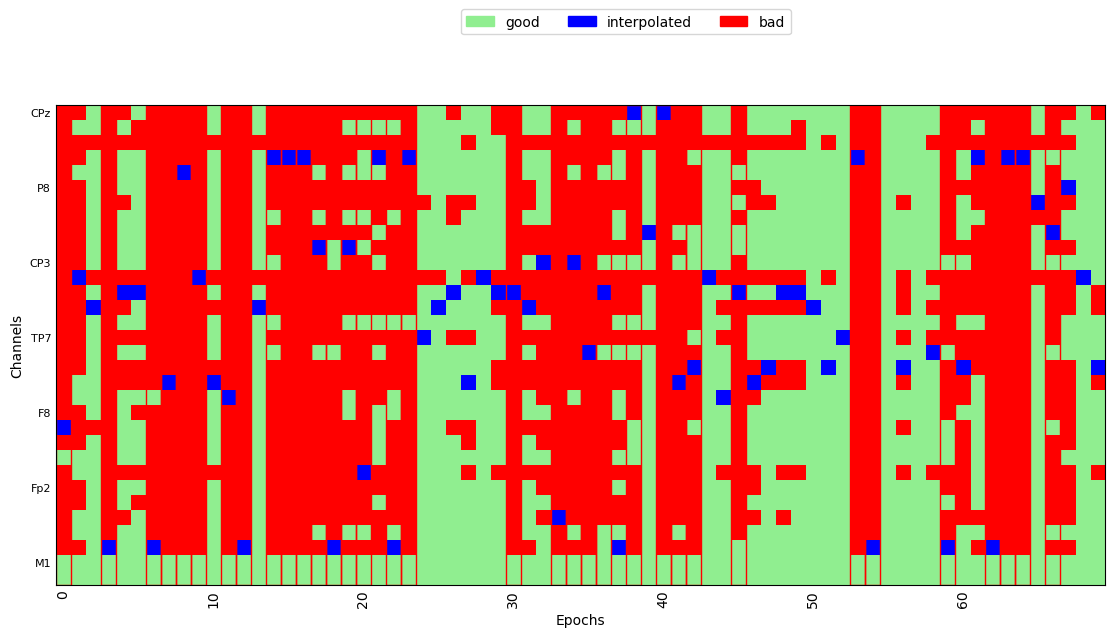

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/424 [00:00<?,       ?it/s]

Dropped 144 epochs: 1, 8, 18, 22, 24, 26, 29, 30, 39, 44, 45, 46, 48, 50, 55, 56, 57, 59, 60, 61, 62, 63, 66, 67, 69, 70, 75, 76, 80, 84, 85, 88, 89, 94, 96, 97, 99, 100, 101, 102, 103, 104, 105, 107, 109, 113, 116, 118, 120, 124, 125, 126, 131, 132, 136, 140, 141, 142, 150, 157, 167, 172, 175, 179, 181, 188, 190, 192, 193, 194, 195, 196, 198, 202, 203, 205, 206, 210, 212, 221, 229, 235, 237, 238, 243, 244, 249, 252, 253, 262, 263, 264, 265, 266, 273, 276, 278, 280, 282, 286, 288, 309, 310, 312, 314, 315, 319, 326, 327, 330, 331, 338, 341, 351, 352, 355, 364, 365, 370, 374, 377, 380, 383, 384, 385, 387, 389, 391, 396, 397, 398, 401, 402, 405, 406, 407, 408, 409, 411, 412, 414, 416, 417, 419


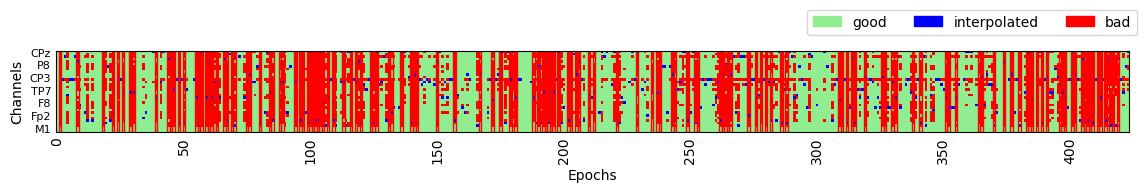

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 20 epochs: 5, 8, 12, 19, 23, 31, 33, 34, 39, 41, 42, 45, 49, 51, 53, 54, 64, 66, 67, 69


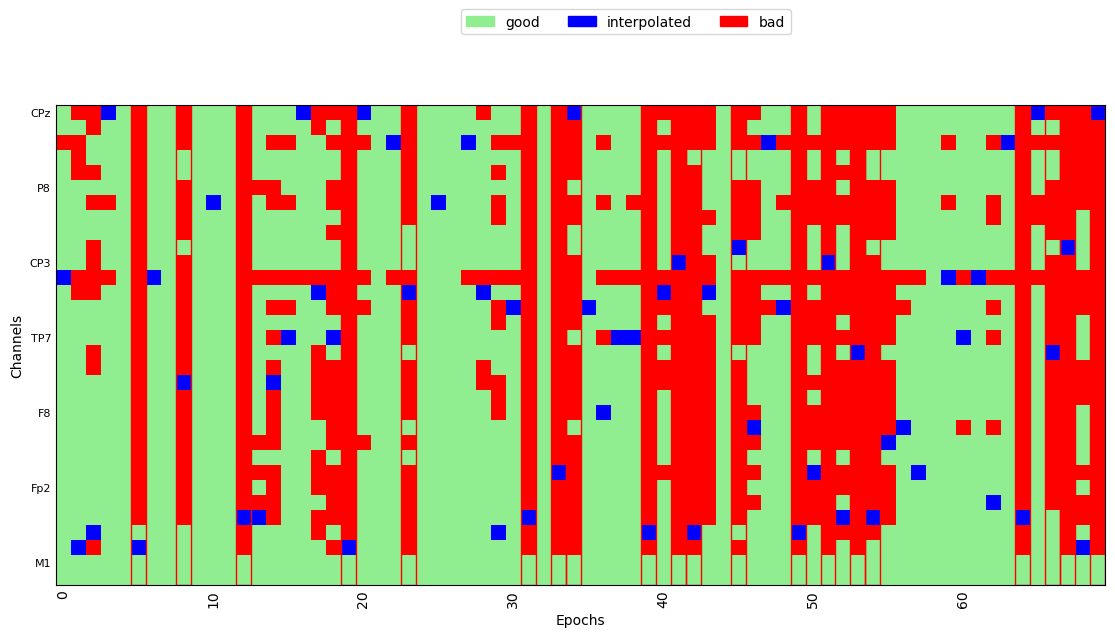

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

Dropped 130 epochs: 7, 8, 9, 10, 11, 14, 16, 19, 24, 27, 29, 32, 34, 36, 39, 47, 59, 63, 65, 67, 68, 70, 74, 80, 86, 89, 90, 91, 93, 95, 105, 111, 113, 119, 124, 132, 145, 148, 151, 154, 155, 156, 158, 159, 160, 161, 169, 173, 176, 186, 189, 190, 196, 197, 198, 201, 207, 208, 209, 210, 223, 226, 233, 236, 242, 245, 247, 248, 261, 268, 275, 276, 277, 282, 286, 287, 290, 293, 299, 301, 311, 316, 317, 318, 320, 321, 322, 328, 330, 335, 338, 339, 346, 347, 348, 349, 351, 352, 353, 354, 356, 358, 360, 361, 363, 364, 368, 369, 373, 374, 376, 379, 380, 382, 385, 386, 387, 388, 392, 394, 396, 401, 402, 404, 405, 408, 412, 413, 414, 417


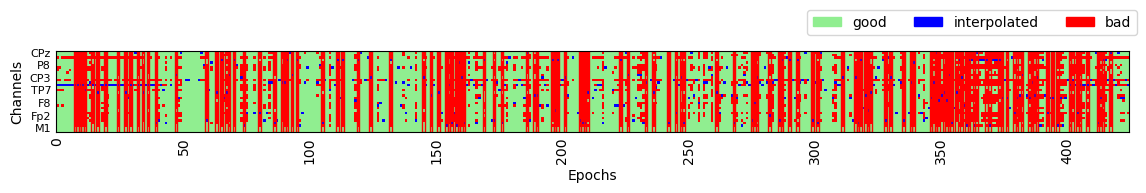

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 30 epochs: 0, 1, 4, 5, 7, 8, 13, 14, 16, 20, 22, 29, 31, 33, 35, 36, 39, 41, 47, 50, 51, 52, 53, 59, 60, 61, 62, 66, 67, 68


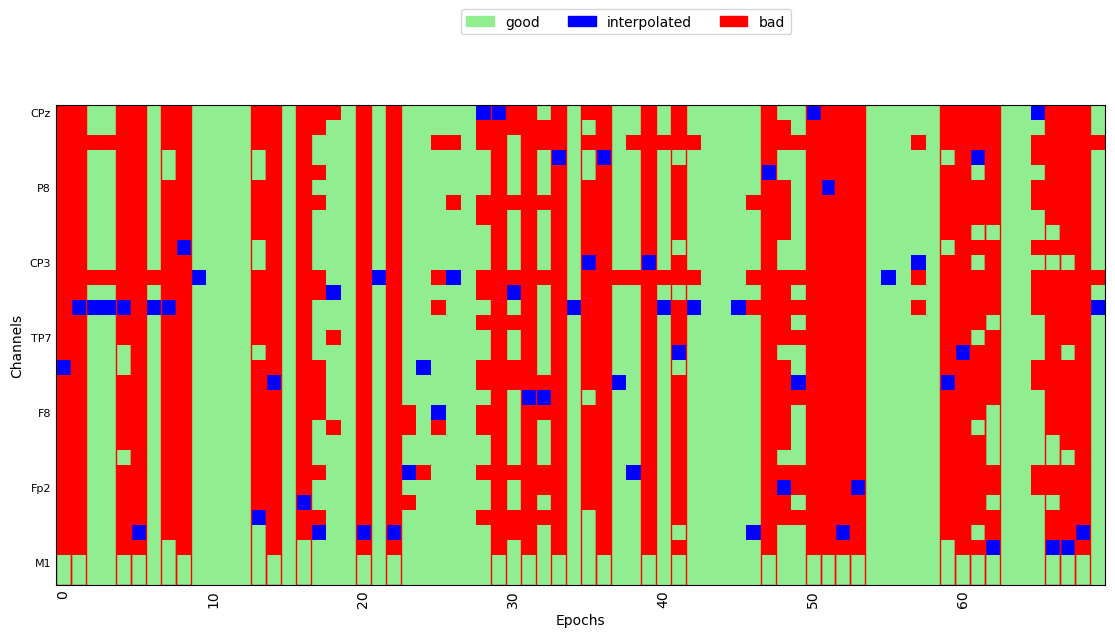

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0011_VOT_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1920 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0011_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])
/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 5 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["b

  0%|          | Creating augmented epochs : 0/27 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/27 [00:00<?,       ?it/s]

... (8 outputs left out)





Estimated consensus=0.80 and n_interpolate=4


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 5 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/412 [00:00<?,       ?it/s]

Dropped 55 epochs: 20, 34, 36, 41, 44, 52, 61, 63, 74, 75, 80, 82, 83, 85, 94, 99, 102, 103, 107, 114, 124, 133, 136, 142, 157, 163, 170, 171, 173, 186, 195, 201, 210, 217, 235, 242, 277, 281, 296, 299, 302, 310, 329, 331, 340, 341, 344, 346, 353, 357, 360, 371, 382, 391, 405


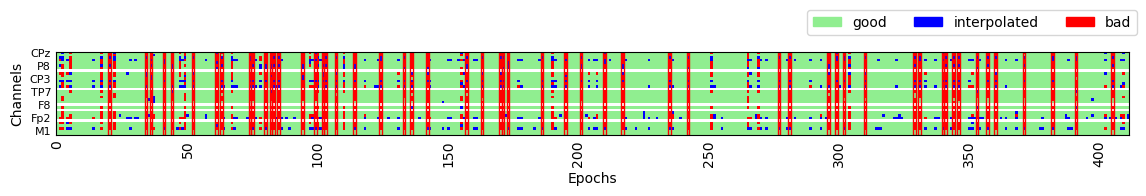

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 27 sensor positions
Interpolating 5 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 5 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 7 epochs: 19, 29, 43, 53, 56, 58, 65


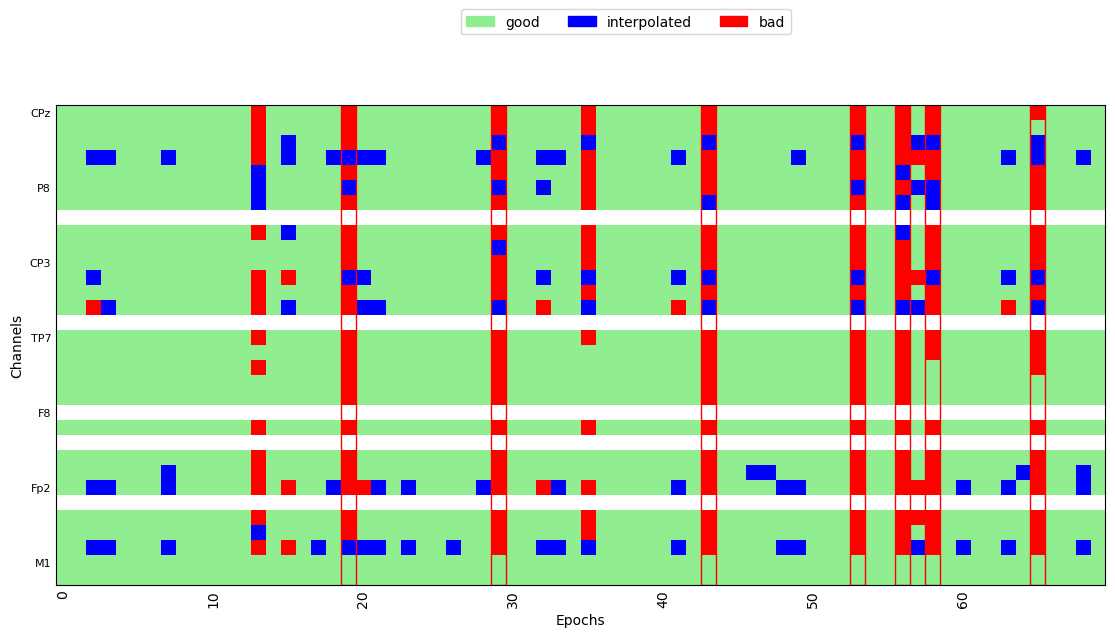

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 27 sensor positions
Interpolating 5 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 5 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/434 [00:00<?,       ?it/s]

Dropped 34 epochs: 0, 2, 48, 49, 50, 107, 116, 139, 152, 153, 156, 157, 173, 221, 222, 226, 228, 234, 235, 277, 299, 300, 320, 331, 333, 334, 336, 349, 364, 381, 391, 399, 401, 402


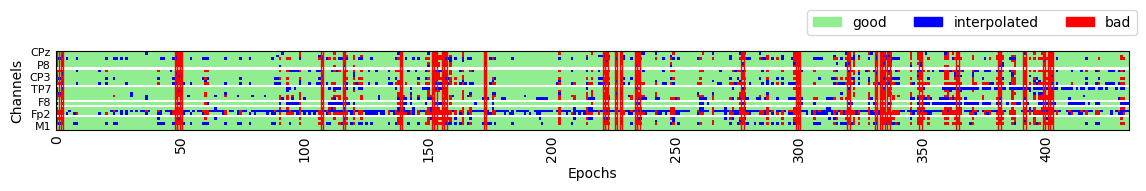

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 27 sensor positions
Interpolating 5 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 5 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 27, 41, 46, 51, 53, 54


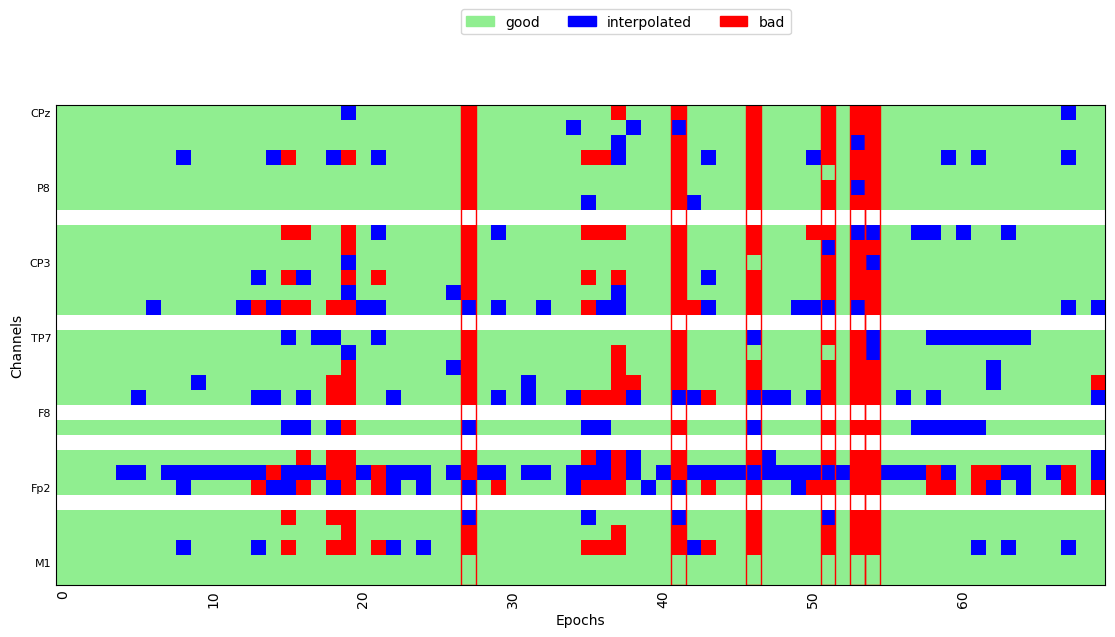

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 27 sensor positions
Interpolating 5 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 5 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/413 [00:00<?,       ?it/s]

Dropped 23 epochs: 0, 1, 146, 147, 195, 206, 209, 240, 243, 252, 267, 270, 271, 272, 293, 296, 308, 329, 358, 388, 389, 391, 400


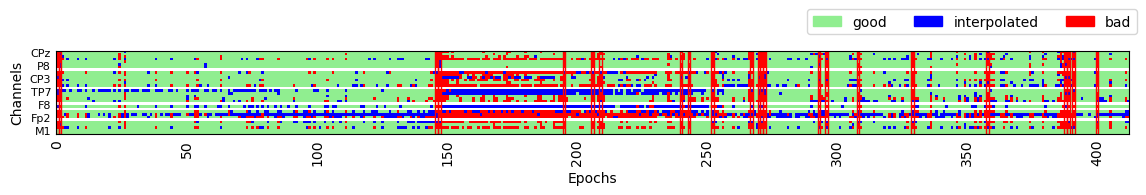

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 27 sensor positions
Interpolating 5 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 5 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 3 epochs: 13, 27, 41


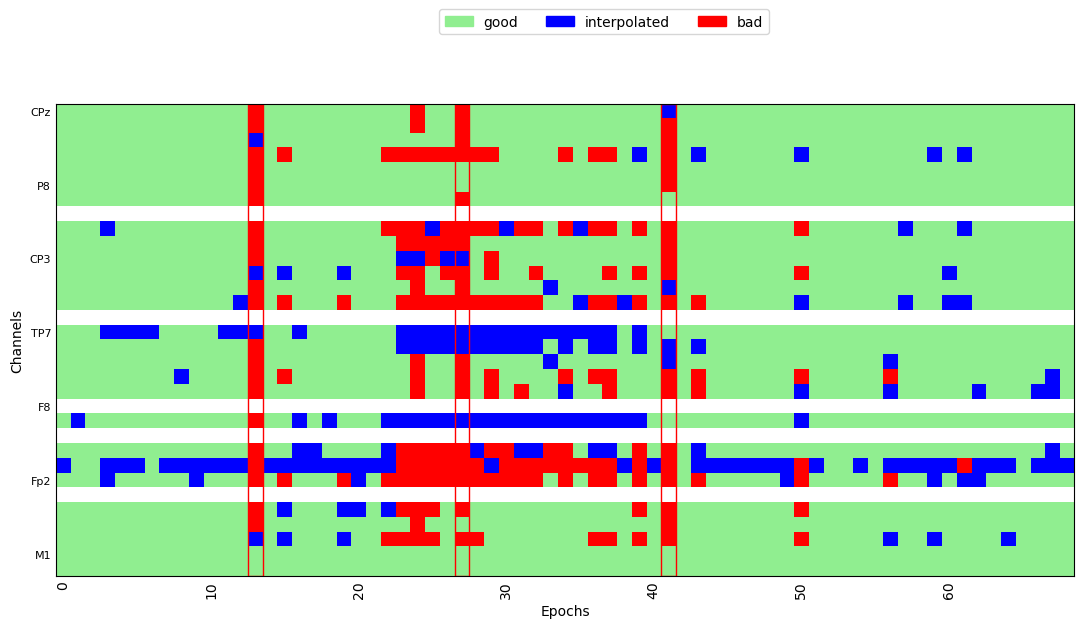

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 27 sensor positions
Interpolating 5 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 5 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/382 [00:00<?,       ?it/s]

Dropped 39 epochs: 1, 8, 10, 20, 22, 24, 27, 29, 35, 36, 37, 39, 44, 45, 47, 48, 49, 50, 51, 54, 59, 60, 66, 67, 68, 69, 71, 72, 73, 76, 78, 83, 102, 110, 189, 247, 254, 298, 345


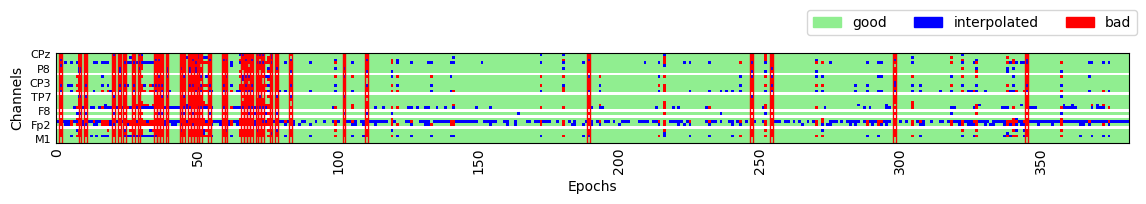

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 27 sensor positions
Interpolating 5 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 5 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 7, 10, 20, 21, 55, 58


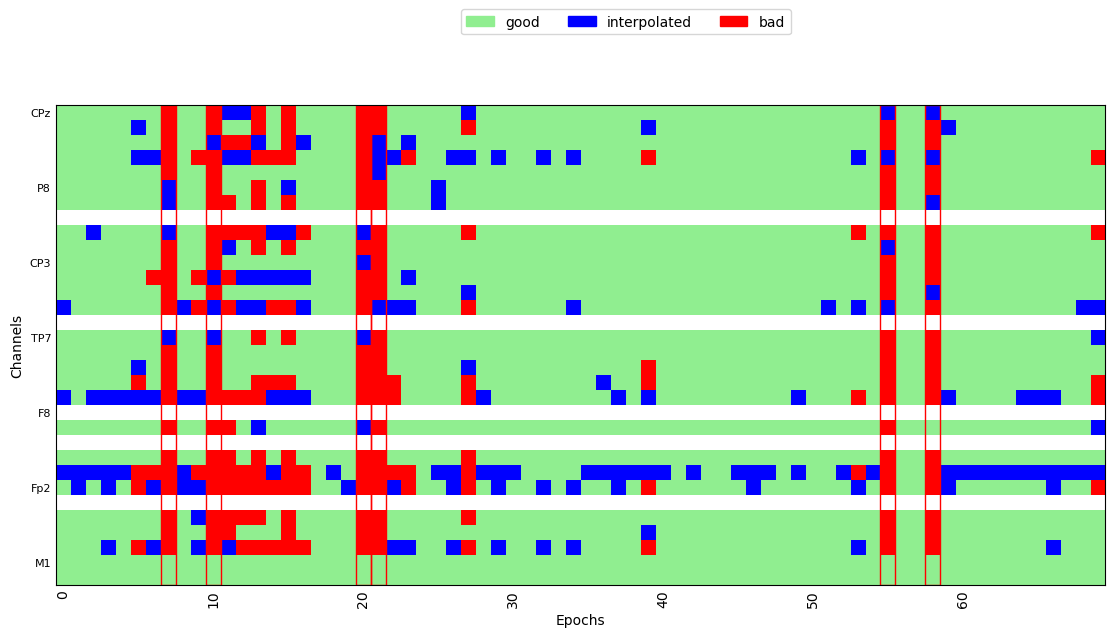

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 27 sensor positions
Interpolating 5 sensors
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0007_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1935 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0007_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])
/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Creating augmented epochs : 0/31 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/31 [00:00<?,       ?it/s]

... (8 outputs left out)





Estimated consensus=0.20 and n_interpolate=4


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/412 [00:00<?,       ?it/s]

Dropped 347 epochs: 0, 1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 21, 23, 24, 25, 26, 27, 29, 30, 32, 33, 34, 35, 36, 39, 40, 41, 42, 43, 44, 45, 47, 48, 50, 51, 52, 54, 55, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 68, 70, 71, 72, 73, 74, 75, 76, 77, 79, 81, 82, 84, 85, 86, 87, 88, 89, 90, 91, 92, 94, 95, 96, 97, 98, 99, 100, 102, 105, 106, 107, 109, 110, 112, 113, 114, 116, 117, 118, 119, 120, 121, 123, 124, 126, 128, 129, 131, 132, 133, 134, 135, 136, 137, 138, 141, 142, 143, 144, 145, 146, 148, 149, 150, 151, 152, 154, 155, 156, 157, 158, 159, 161, 162, 164, 165, 166, 167, 168, 169, 170, 171, 172, 174, 175, 176, 177, 178, 179, 180, 181, 182, 184, 185, 186, 187, 188, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 204, 205, 207, 208, 209, 210, 211, 212, 213, 215, 216, 217, 218, 219, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 239, 240, 243, 244, 245, 246, 247, 248, 249, 250, 252, 253, 254, 255, 257, 258, 259, 260, 

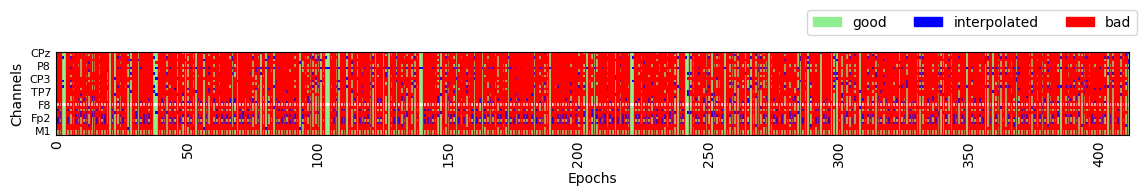

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 56 epochs: 0, 2, 3, 4, 5, 6, 8, 9, 10, 13, 14, 15, 16, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 29, 30, 31, 32, 33, 38, 39, 40, 41, 42, 44, 45, 47, 48, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 68, 69


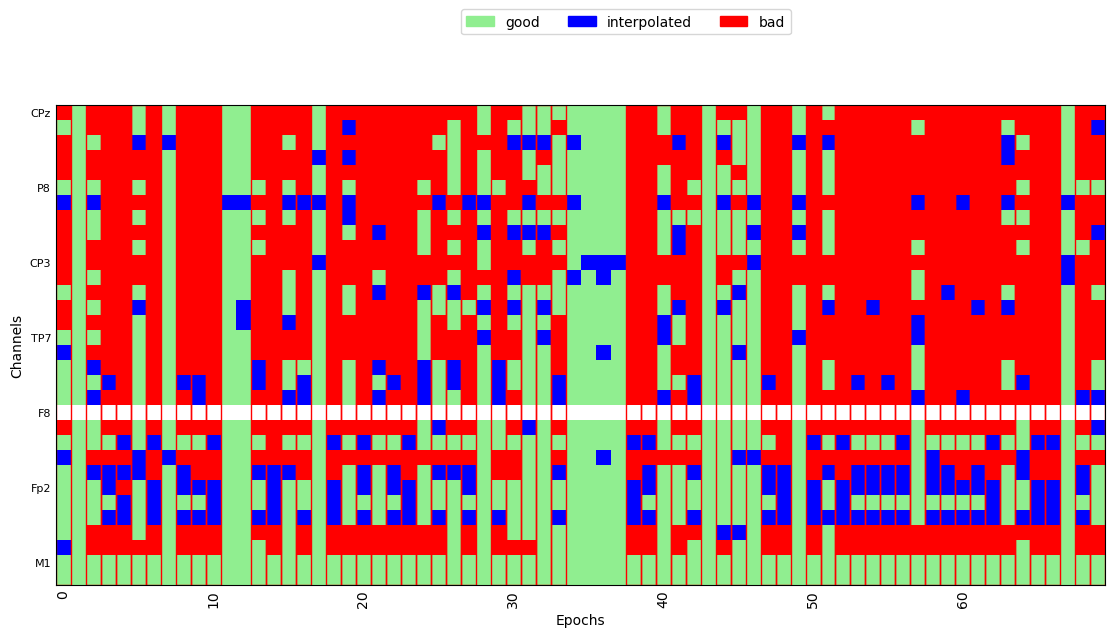

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/385 [00:00<?,       ?it/s]

Dropped 320 epochs: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 35, 36, 37, 38, 39, 40, 41, 42, 44, 46, 47, 48, 49, 50, 51, 52, 53, 55, 56, 57, 59, 60, 63, 64, 65, 66, 67, 68, 70, 71, 72, 73, 76, 77, 79, 81, 82, 83, 84, 85, 86, 87, 88, 89, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 104, 105, 106, 108, 109, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 127, 128, 129, 130, 131, 133, 134, 135, 136, 137, 138, 140, 141, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 167, 168, 171, 172, 173, 174, 175, 177, 178, 179, 180, 181, 182, 183, 185, 186, 187, 188, 190, 191, 192, 193, 194, 196, 198, 200, 201, 202, 203, 204, 205, 206, 208, 209, 211, 212, 213, 214, 216, 217, 218, 220, 221, 222, 223, 224, 225, 226, 227, 228, 230, 231, 232, 233, 234, 235, 236, 237, 239, 240, 241, 243, 244, 246, 247, 248, 249, 250, 251, 252, 254, 255, 256, 2

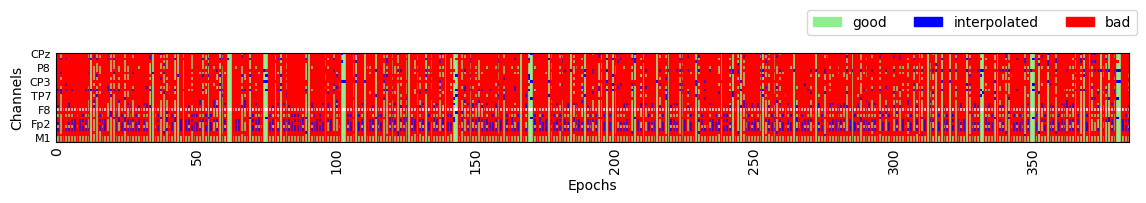

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 59 epochs: 0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12, 13, 15, 17, 18, 19, 20, 21, 22, 23, 24, 26, 27, 28, 29, 30, 31, 32, 34, 35, 36, 38, 41, 42, 43, 44, 45, 46, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 62, 64, 65, 66, 67, 68, 69


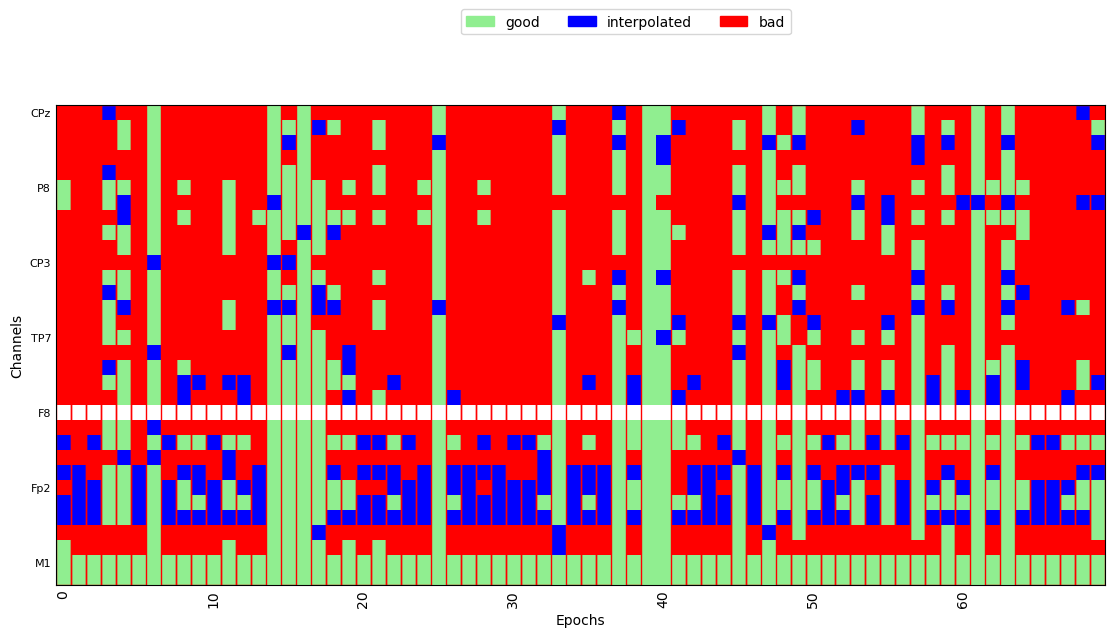

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/440 [00:00<?,       ?it/s]

Dropped 387 epochs: 0, 1, 2, 5, 6, 7, 9, 10, 11, 13, 14, 15, 17, 18, 20, 22, 23, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 37, 38, 39, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 87, 88, 89, 90, 91, 93, 94, 95, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 123, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 140, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 233, 235, 236, 237, 238

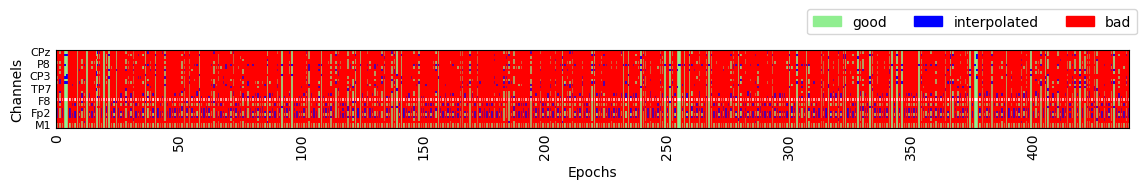

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 61 epochs: 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 15, 16, 17, 18, 20, 21, 22, 23, 24, 25, 27, 28, 29, 30, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 65, 66, 67, 68


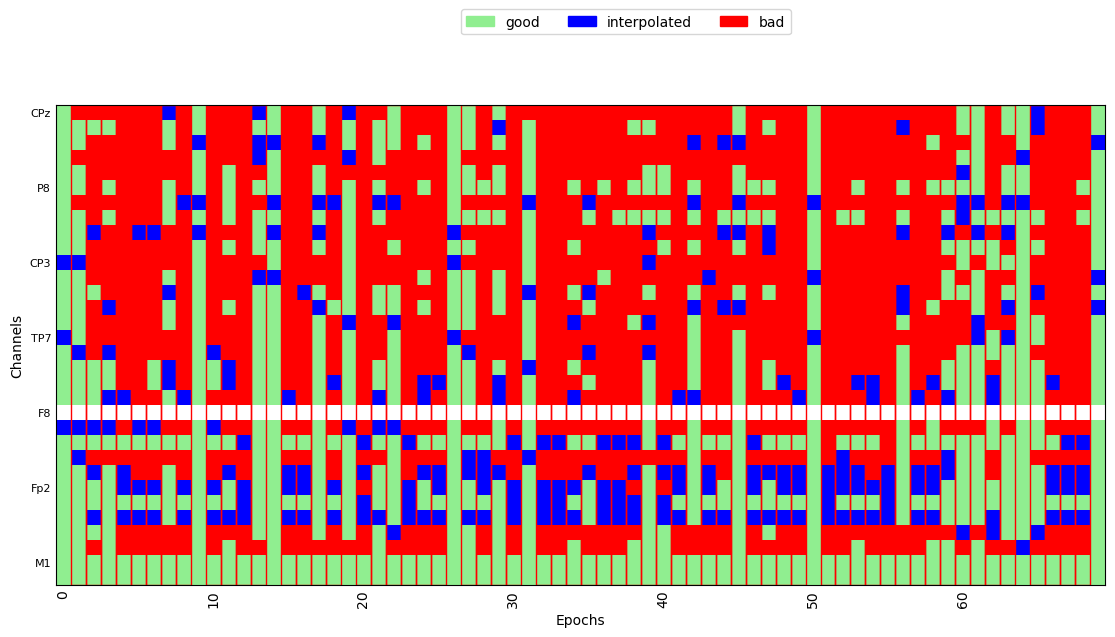

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/419 [00:00<?,       ?it/s]

Dropped 371 epochs: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 18, 19, 21, 22, 23, 24, 28, 30, 31, 32, 33, 34, 36, 37, 39, 40, 41, 43, 44, 45, 47, 48, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 63, 64, 65, 66, 67, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 88, 89, 90, 91, 94, 98, 99, 100, 101, 102, 104, 105, 106, 107, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 130, 133, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242

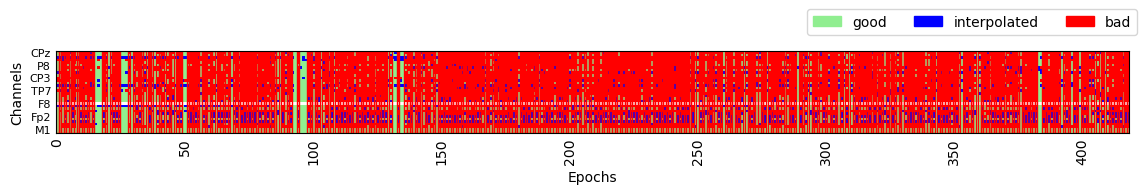

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 65 epochs: 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68


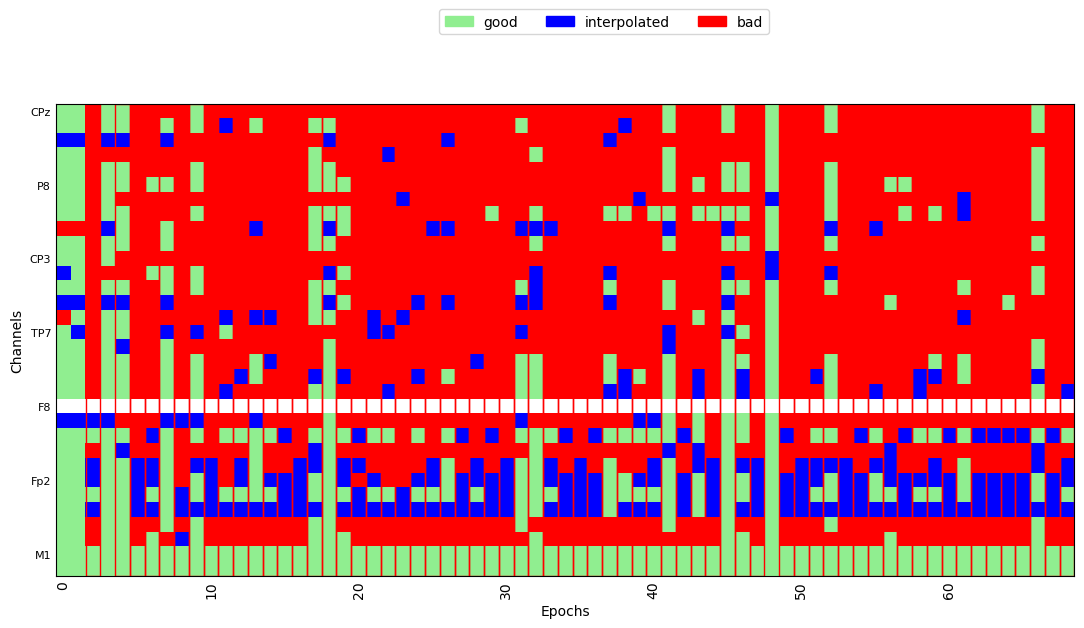

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0024_VOT_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1950 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0024_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

... (7 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

Dropped 123 epochs: 1, 2, 4, 8, 11, 12, 13, 25, 26, 28, 33, 35, 36, 39, 48, 51, 52, 57, 58, 59, 60, 61, 63, 64, 84, 85, 89, 93, 94, 99, 100, 110, 111, 118, 121, 130, 131, 137, 140, 151, 155, 165, 176, 180, 184, 186, 197, 198, 200, 206, 207, 210, 212, 213, 220, 222, 223, 224, 225, 226, 227, 228, 229, 231, 237, 239, 243, 249, 251, 253, 254, 262, 263, 265, 266, 272, 274, 275, 278, 279, 284, 285, 288, 289, 296, 298, 301, 302, 306, 307, 311, 322, 324, 325, 329, 342, 343, 347, 361, 364, 368, 375, 379, 380, 384, 386, 387, 394, 397, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 415, 416


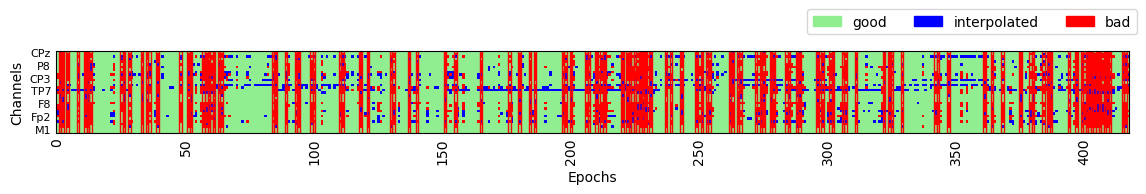

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 24 epochs: 2, 3, 4, 9, 10, 14, 16, 18, 19, 27, 29, 36, 37, 39, 43, 48, 51, 53, 60, 63, 66, 67, 68, 69


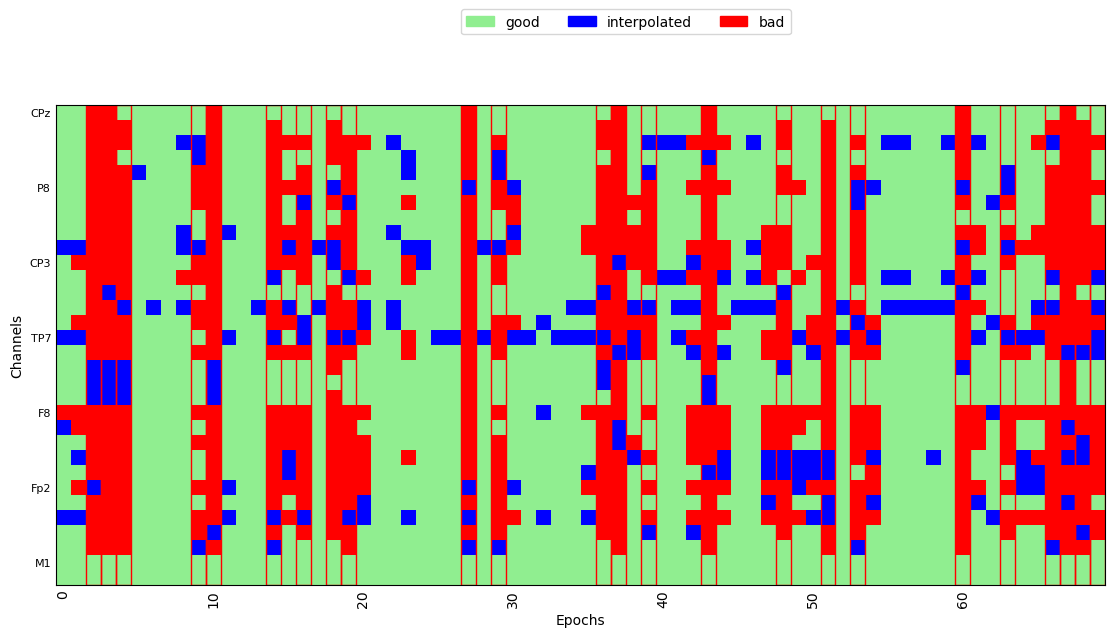

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

Dropped 134 epochs: 2, 3, 11, 26, 32, 34, 36, 37, 50, 56, 65, 66, 67, 68, 73, 84, 85, 91, 98, 102, 103, 104, 105, 106, 109, 110, 111, 112, 116, 127, 128, 129, 130, 131, 132, 133, 135, 136, 143, 144, 151, 152, 153, 154, 162, 169, 170, 171, 175, 179, 180, 182, 185, 186, 189, 190, 191, 192, 194, 196, 198, 199, 200, 201, 204, 206, 208, 209, 210, 212, 213, 221, 227, 230, 231, 232, 233, 234, 244, 246, 260, 261, 262, 263, 264, 272, 275, 276, 279, 281, 282, 283, 284, 285, 286, 288, 289, 290, 291, 296, 298, 299, 307, 309, 310, 311, 313, 314, 316, 333, 338, 340, 341, 346, 347, 348, 363, 367, 368, 369, 375, 379, 380, 381, 382, 384, 386, 387, 400, 402, 403, 404, 408, 409


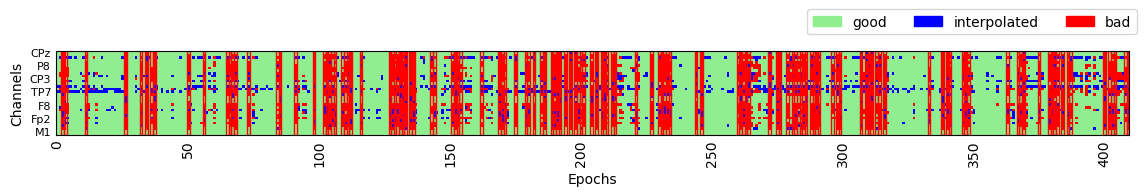

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

Dropped 24 epochs: 7, 10, 11, 12, 16, 18, 23, 27, 33, 35, 36, 39, 41, 47, 48, 49, 51, 52, 53, 57, 58, 59, 62, 67


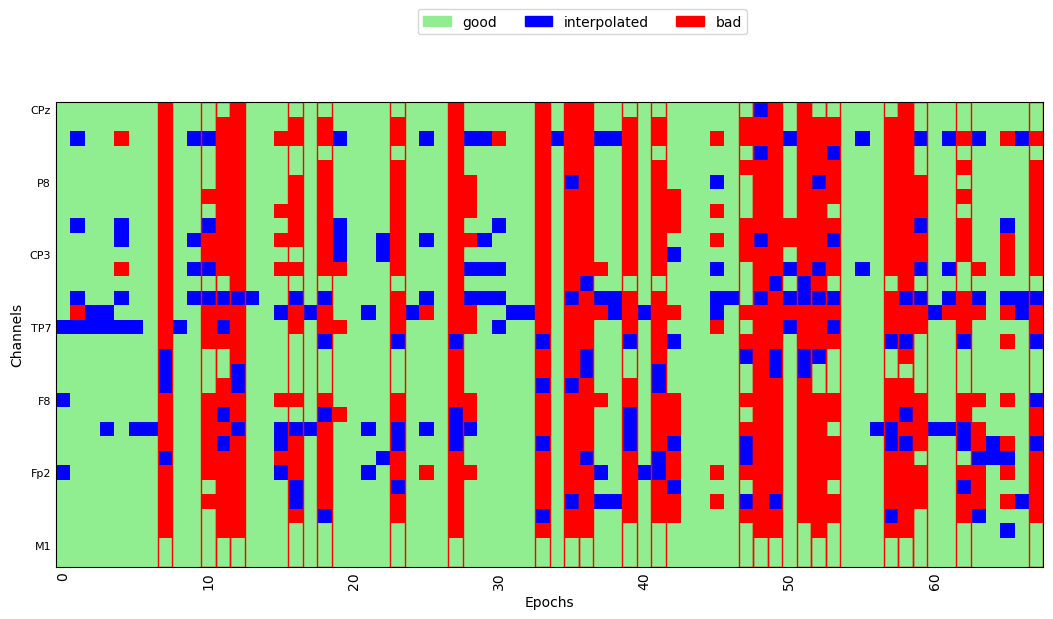

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/451 [00:00<?,       ?it/s]

Dropped 255 epochs: 4, 7, 8, 9, 13, 14, 16, 17, 18, 21, 22, 23, 31, 33, 34, 36, 38, 39, 50, 54, 56, 62, 68, 69, 70, 71, 72, 74, 76, 77, 79, 82, 83, 85, 89, 91, 92, 93, 94, 95, 96, 97, 99, 102, 105, 107, 108, 113, 114, 115, 116, 117, 118, 119, 120, 123, 124, 127, 129, 130, 133, 135, 136, 137, 138, 140, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 158, 159, 160, 161, 162, 164, 165, 166, 167, 168, 169, 170, 172, 178, 180, 181, 182, 183, 190, 191, 198, 199, 202, 203, 204, 205, 206, 207, 208, 209, 211, 213, 214, 215, 216, 219, 220, 221, 223, 224, 228, 229, 230, 231, 233, 238, 239, 244, 245, 246, 247, 248, 250, 252, 253, 254, 255, 256, 259, 264, 265, 266, 267, 270, 271, 272, 274, 275, 278, 279, 280, 281, 283, 284, 285, 286, 287, 289, 292, 296, 297, 298, 299, 304, 305, 306, 308, 309, 310, 311, 312, 313, 314, 317, 318, 319, 320, 324, 325, 326, 329, 330, 331, 332, 333, 334, 335, 336, 338, 339, 340, 341, 342, 343, 344, 345, 346, 348, 350, 351, 352, 353, 354, 355, 35

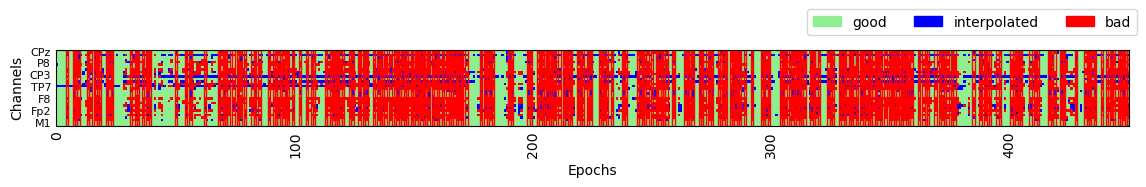

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 36 epochs: 4, 6, 7, 10, 11, 14, 15, 16, 18, 19, 20, 23, 24, 25, 26, 29, 31, 34, 38, 39, 40, 42, 45, 49, 52, 53, 54, 56, 57, 61, 62, 64, 65, 66, 67, 69


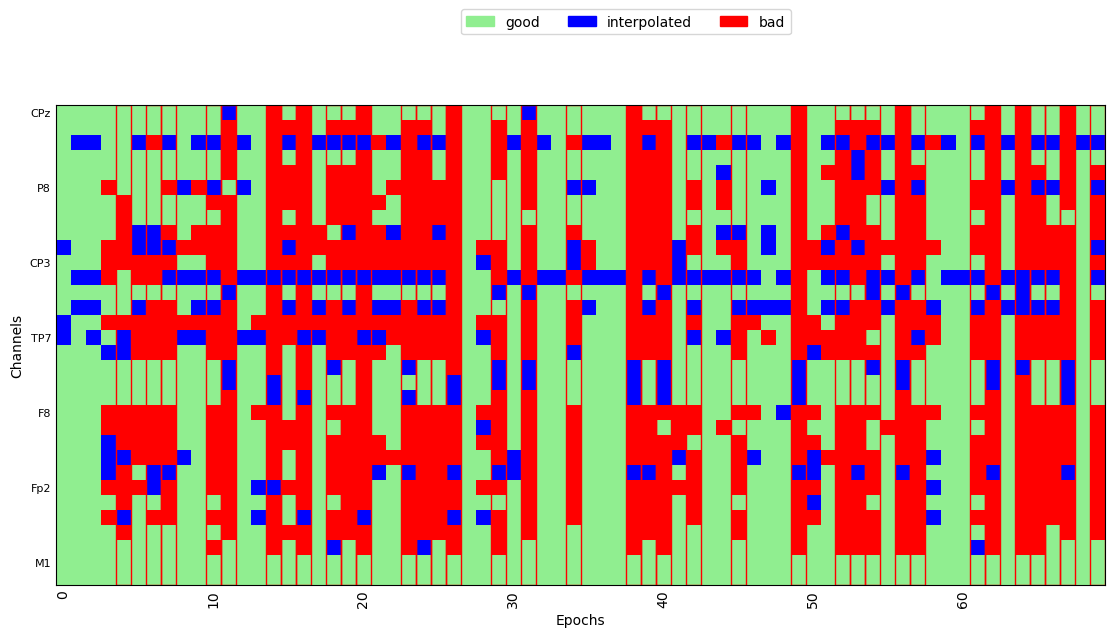

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/393 [00:00<?,       ?it/s]

Dropped 149 epochs: 0, 3, 4, 5, 6, 7, 10, 11, 32, 34, 35, 37, 42, 43, 47, 48, 64, 66, 69, 75, 77, 86, 88, 96, 97, 101, 102, 108, 110, 111, 112, 113, 114, 115, 116, 120, 122, 123, 126, 129, 131, 133, 139, 140, 142, 147, 149, 150, 152, 155, 156, 157, 158, 159, 160, 161, 162, 170, 172, 175, 178, 179, 182, 187, 188, 189, 192, 193, 194, 195, 196, 197, 207, 211, 213, 219, 220, 224, 225, 226, 228, 232, 233, 234, 235, 238, 242, 243, 245, 246, 248, 249, 254, 255, 262, 264, 265, 271, 272, 273, 275, 280, 282, 283, 284, 292, 297, 298, 299, 300, 301, 302, 304, 306, 308, 314, 317, 319, 320, 321, 323, 324, 327, 328, 331, 332, 333, 334, 335, 341, 347, 350, 356, 357, 360, 362, 363, 367, 368, 369, 374, 375, 376, 377, 378, 385, 388, 389, 390


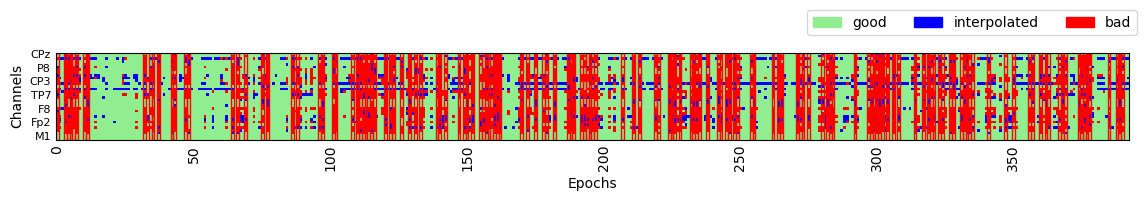

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 26 epochs: 0, 10, 17, 19, 20, 23, 24, 26, 27, 31, 32, 34, 46, 48, 49, 51, 52, 54, 57, 58, 59, 60, 62, 63, 66, 68


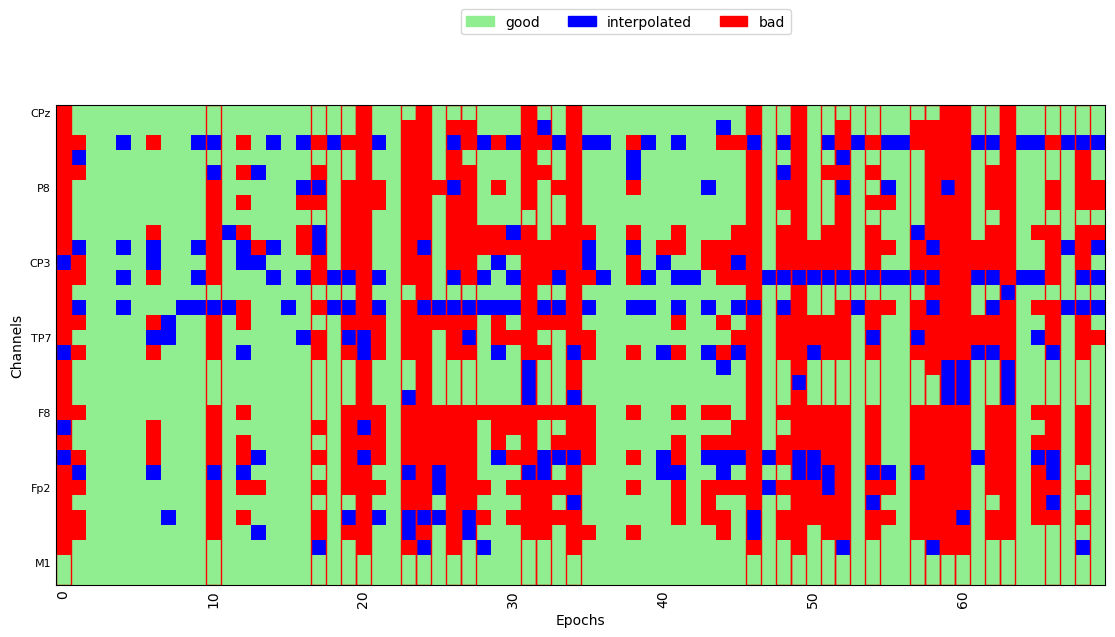

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0007_VOT_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1903 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0007_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_

Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/1903 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/402 [00:00<?,       ?it/s]

Dropped 55 epochs: 0, 18, 37, 38, 45, 66, 74, 78, 91, 98, 104, 107, 111, 116, 117, 119, 121, 127, 132, 133, 135, 139, 140, 141, 156, 169, 171, 174, 176, 186, 193, 195, 196, 197, 204, 207, 208, 211, 221, 222, 266, 268, 283, 294, 296, 305, 309, 317, 331, 332, 333, 352, 367, 396, 401


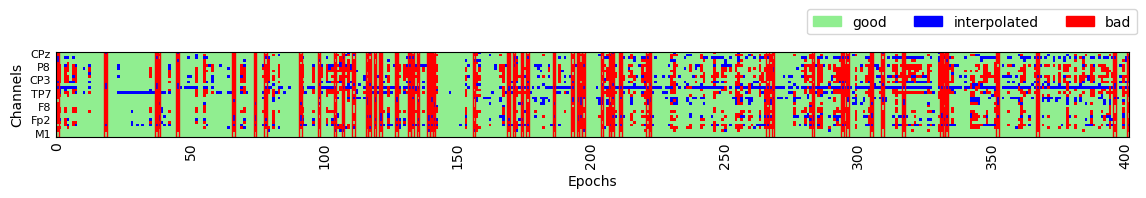

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 9 epochs: 15, 20, 26, 47, 49, 50, 52, 56, 58


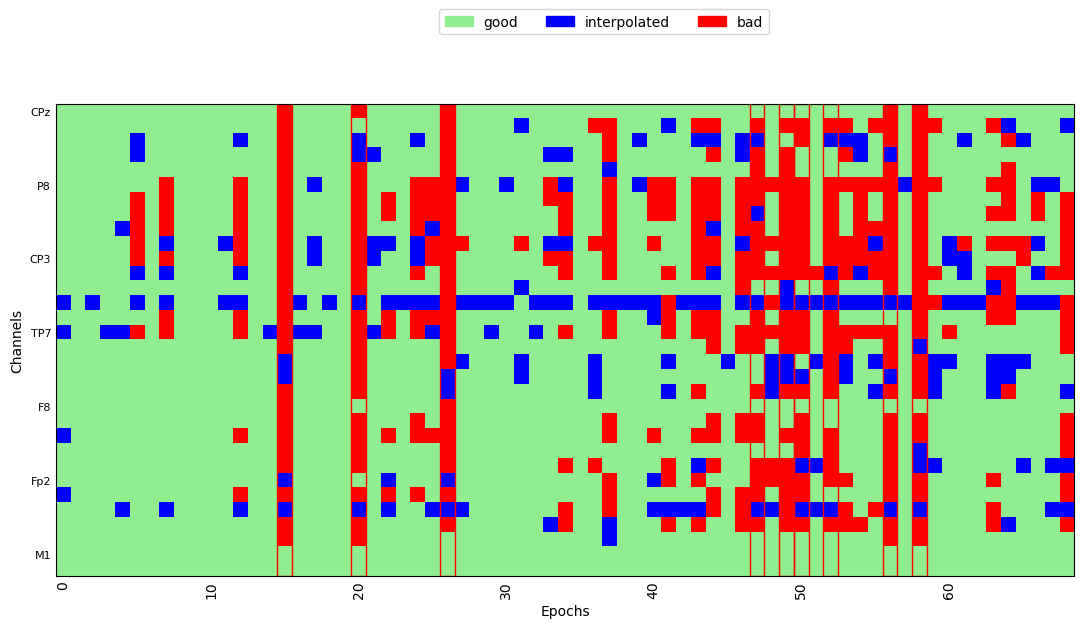

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/398 [00:00<?,       ?it/s]

Dropped 98 epochs: 2, 7, 8, 12, 13, 17, 21, 30, 36, 37, 39, 40, 41, 43, 45, 48, 50, 56, 58, 63, 68, 82, 87, 88, 92, 93, 104, 124, 128, 129, 135, 137, 138, 139, 142, 149, 151, 153, 169, 171, 174, 175, 183, 184, 185, 186, 189, 201, 213, 215, 226, 229, 230, 238, 240, 242, 248, 250, 251, 263, 270, 271, 272, 273, 274, 275, 276, 277, 284, 285, 286, 287, 294, 296, 302, 305, 308, 311, 314, 315, 319, 324, 335, 339, 346, 347, 348, 349, 359, 360, 362, 365, 375, 384, 390, 391, 392, 393


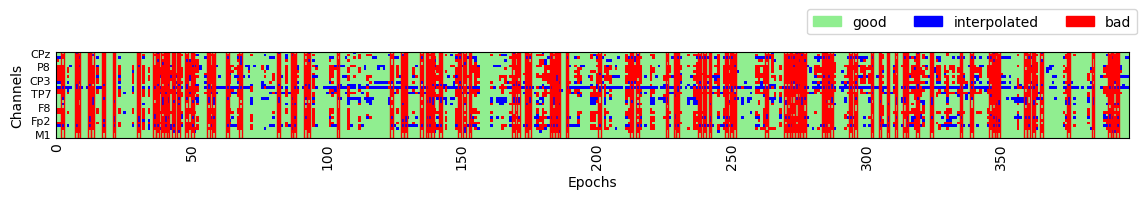

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 0, 2, 8, 9, 11, 22, 23, 30, 34, 37, 51


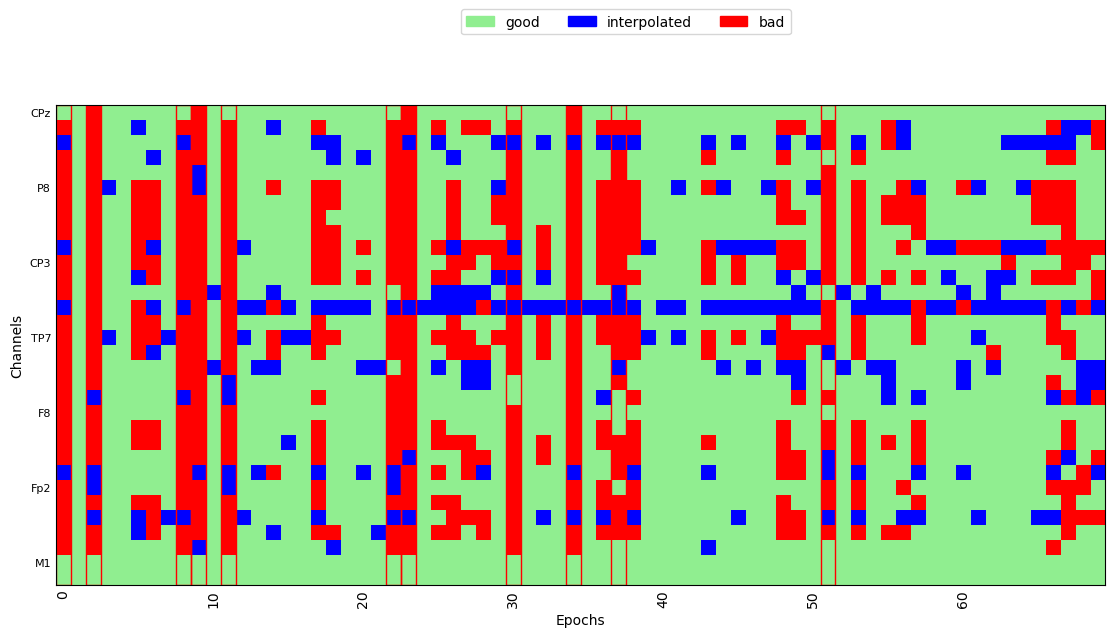

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/416 [00:00<?,       ?it/s]

Dropped 97 epochs: 8, 20, 23, 26, 28, 29, 30, 34, 35, 37, 40, 42, 43, 50, 52, 60, 62, 65, 70, 72, 74, 77, 78, 100, 108, 109, 111, 126, 128, 132, 133, 140, 141, 146, 147, 148, 151, 154, 164, 173, 175, 181, 183, 184, 192, 196, 199, 204, 214, 215, 219, 220, 221, 226, 227, 235, 237, 239, 242, 246, 267, 268, 276, 277, 292, 300, 301, 302, 303, 306, 321, 324, 325, 333, 335, 336, 341, 342, 343, 346, 347, 351, 352, 355, 360, 362, 364, 378, 384, 385, 396, 401, 403, 404, 405, 412, 413


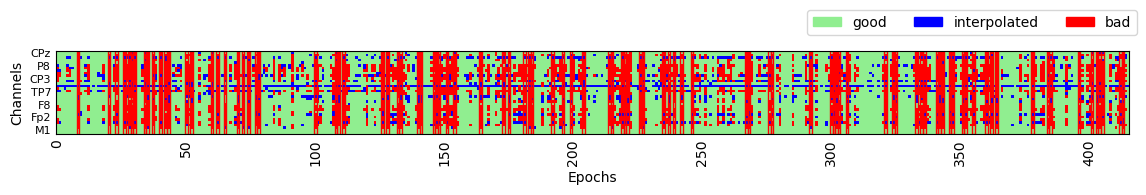

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 14 epochs: 0, 1, 8, 12, 17, 34, 36, 42, 47, 54, 58, 59, 62, 65


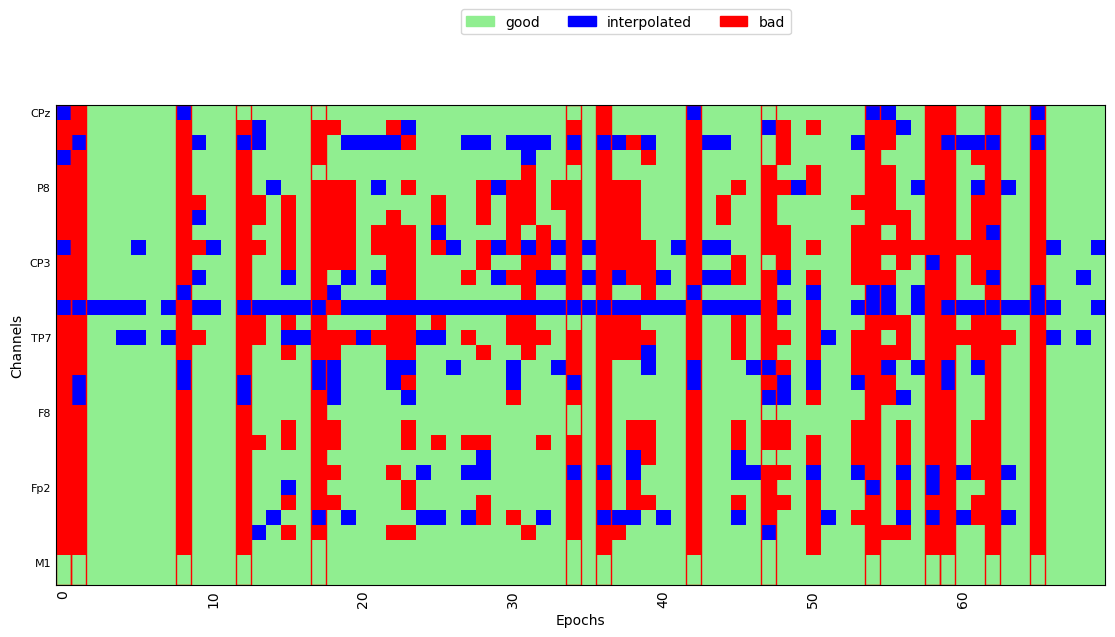

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/409 [00:00<?,       ?it/s]

Dropped 96 epochs: 5, 10, 14, 31, 32, 35, 39, 54, 59, 61, 76, 78, 80, 89, 94, 96, 112, 114, 118, 122, 123, 125, 127, 130, 132, 136, 137, 142, 144, 150, 153, 156, 174, 176, 178, 179, 182, 184, 192, 193, 196, 199, 200, 204, 205, 209, 212, 217, 219, 222, 225, 229, 230, 233, 235, 239, 248, 252, 253, 255, 259, 265, 266, 269, 273, 274, 275, 282, 283, 287, 305, 306, 307, 323, 325, 328, 337, 338, 348, 351, 353, 355, 357, 359, 365, 367, 375, 377, 379, 380, 385, 386, 387, 397, 400, 407


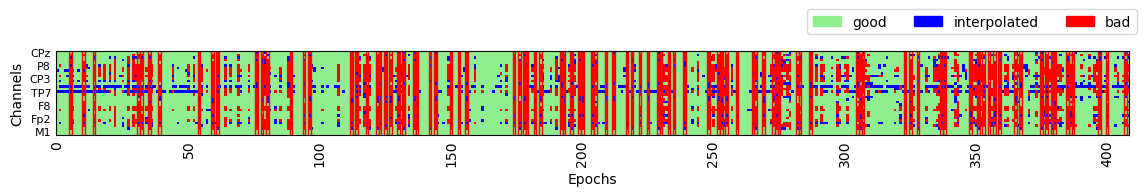

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 18 epochs: 6, 13, 16, 17, 19, 20, 22, 23, 24, 30, 32, 34, 43, 44, 46, 50, 63, 68


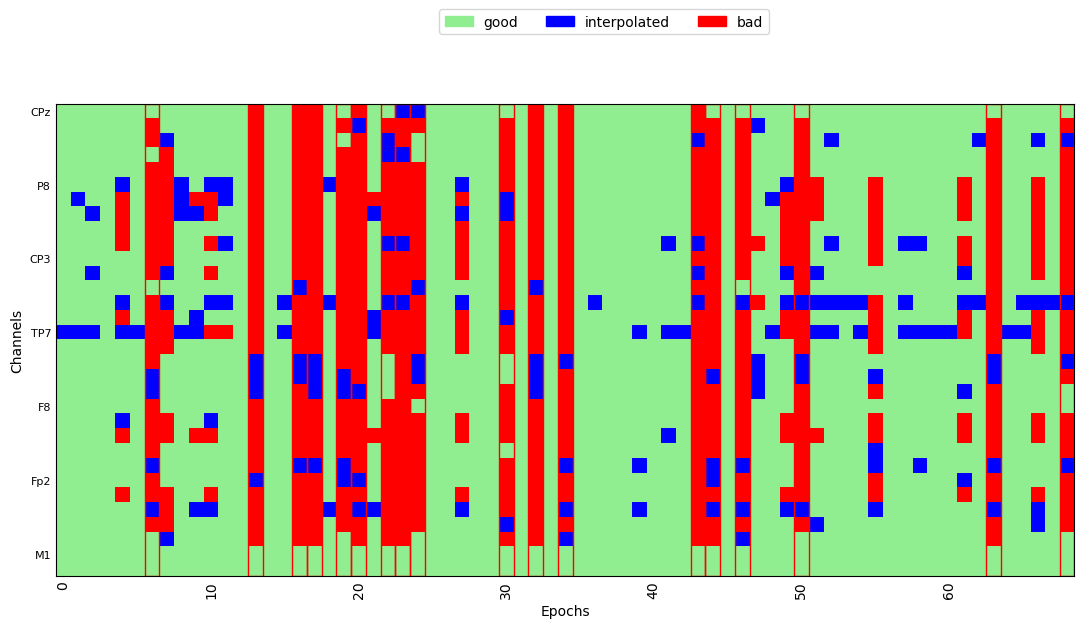

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0012_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1977 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0012_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])
/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["b

  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

... (8 outputs left out)





Estimated consensus=0.40 and n_interpolate=4


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/423 [00:00<?,       ?it/s]

Dropped 130 epochs: 1, 3, 5, 15, 16, 32, 33, 34, 38, 42, 49, 52, 54, 56, 57, 62, 64, 65, 67, 78, 82, 85, 94, 95, 96, 98, 106, 107, 108, 112, 118, 121, 126, 129, 130, 131, 132, 140, 141, 142, 143, 150, 170, 171, 181, 183, 184, 185, 195, 197, 198, 203, 204, 207, 208, 209, 210, 211, 213, 238, 242, 245, 258, 259, 262, 263, 264, 266, 270, 271, 275, 276, 277, 278, 279, 280, 286, 287, 288, 294, 295, 298, 299, 300, 301, 302, 303, 305, 308, 309, 310, 317, 320, 321, 322, 323, 326, 334, 336, 340, 346, 347, 350, 351, 356, 357, 358, 359, 361, 362, 363, 364, 365, 372, 373, 375, 376, 378, 386, 387, 392, 393, 394, 395, 398, 405, 406, 407, 411, 412


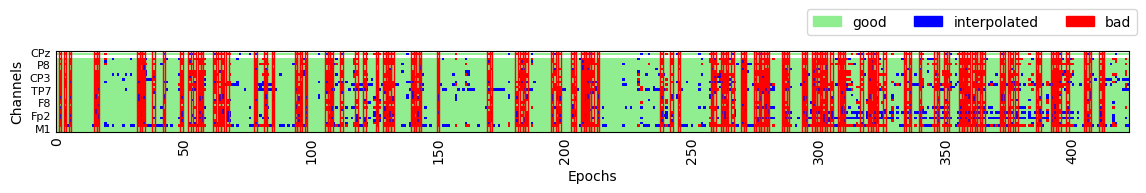

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 18 epochs: 0, 13, 19, 24, 27, 30, 32, 42, 43, 47, 48, 53, 54, 56, 60, 61, 62, 64


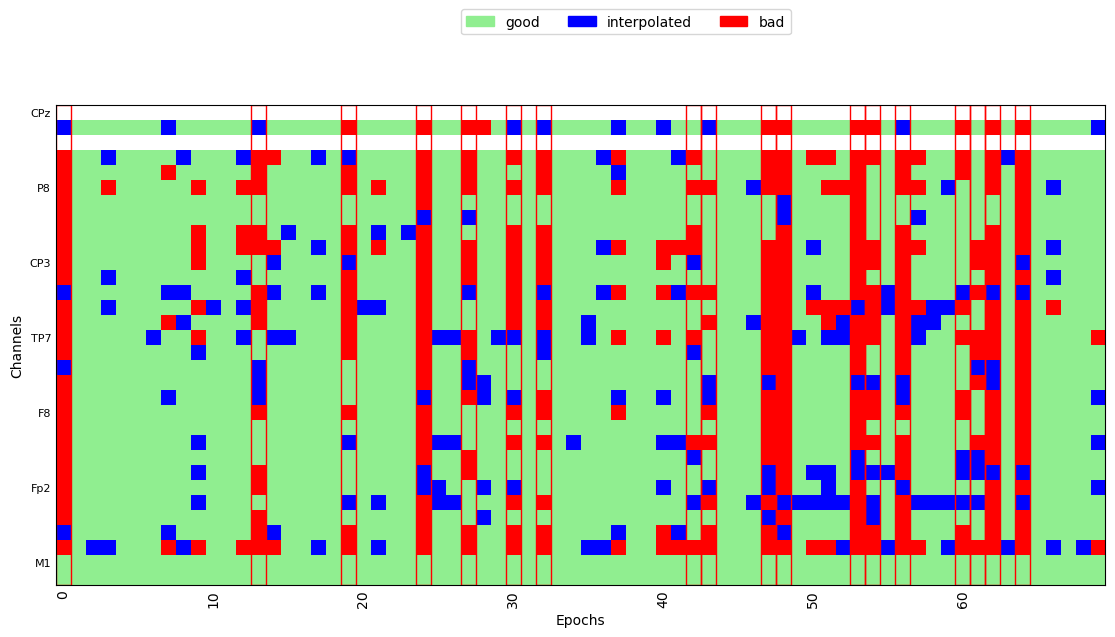

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/444 [00:00<?,       ?it/s]

Dropped 60 epochs: 20, 24, 26, 34, 40, 47, 48, 49, 51, 53, 72, 74, 78, 89, 92, 94, 96, 97, 152, 154, 155, 157, 158, 160, 167, 191, 207, 208, 228, 248, 249, 251, 256, 257, 271, 272, 298, 310, 316, 317, 318, 319, 324, 343, 349, 359, 362, 371, 384, 386, 389, 400, 404, 424, 425, 428, 430, 432, 438, 439


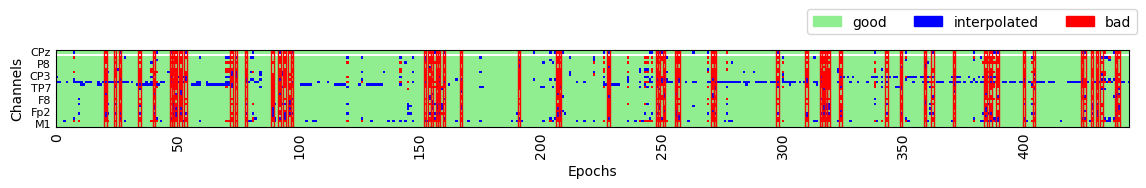

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 12, 33, 38, 39, 41


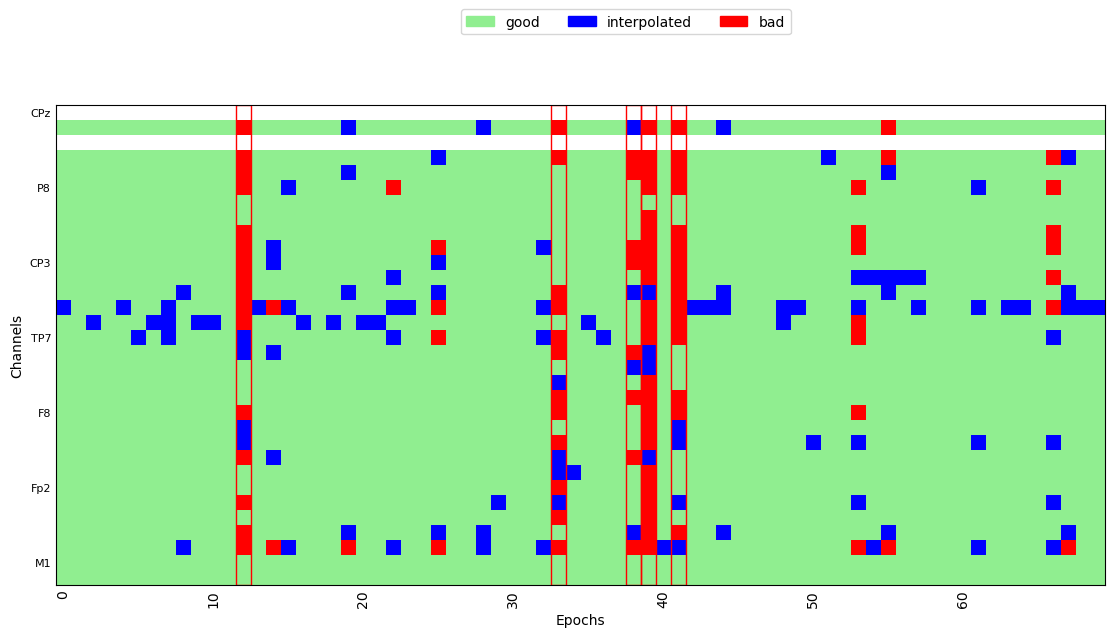

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

Dropped 66 epochs: 21, 38, 55, 60, 64, 66, 69, 76, 94, 100, 101, 105, 119, 127, 128, 129, 133, 134, 144, 147, 155, 157, 160, 170, 172, 173, 174, 190, 192, 197, 198, 207, 209, 210, 212, 218, 228, 246, 247, 248, 251, 266, 269, 279, 281, 289, 290, 291, 326, 330, 342, 343, 369, 370, 371, 372, 381, 382, 383, 392, 393, 396, 397, 404, 405, 414


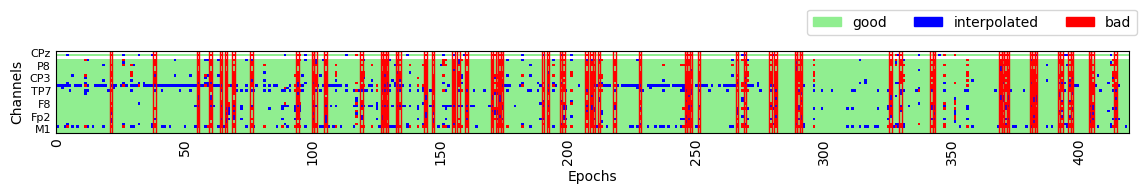

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 14 epochs: 8, 9, 10, 18, 19, 30, 31, 42, 45, 46, 49, 53, 59, 64


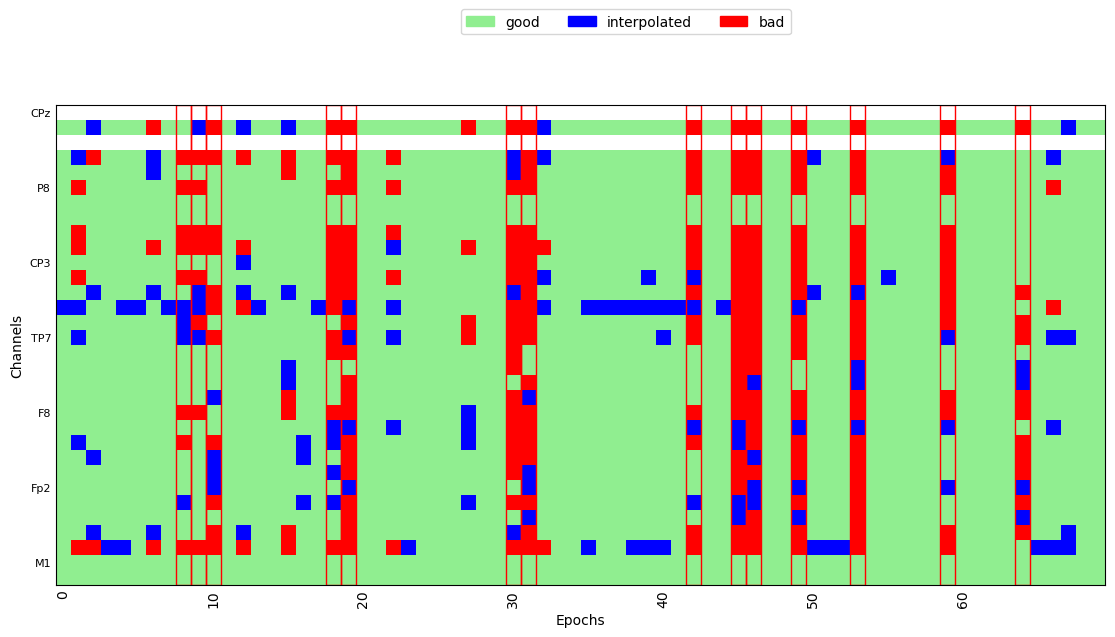

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

Dropped 112 epochs: 3, 4, 5, 23, 34, 48, 49, 51, 52, 53, 54, 56, 57, 62, 78, 96, 106, 111, 114, 118, 120, 125, 130, 133, 140, 141, 146, 160, 163, 165, 166, 168, 169, 170, 172, 173, 178, 181, 182, 183, 186, 188, 190, 196, 201, 202, 203, 204, 205, 207, 208, 217, 228, 233, 234, 235, 236, 237, 239, 241, 245, 248, 249, 251, 257, 258, 261, 262, 268, 269, 270, 272, 273, 275, 276, 279, 280, 282, 307, 308, 313, 314, 315, 319, 321, 324, 325, 328, 331, 335, 336, 339, 340, 342, 345, 349, 350, 353, 358, 363, 364, 365, 366, 368, 369, 370, 381, 399, 403, 406, 407, 409


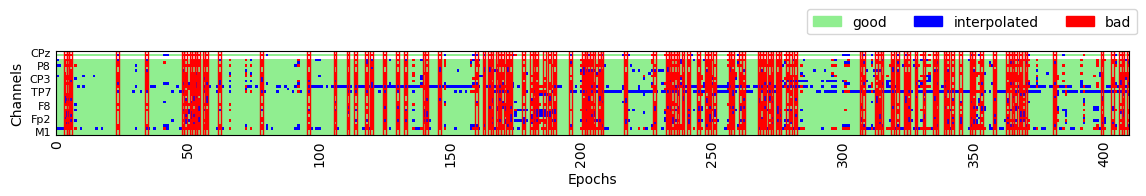

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 20 epochs: 8, 14, 17, 22, 30, 32, 34, 36, 38, 43, 45, 47, 48, 50, 51, 52, 56, 59, 63, 69


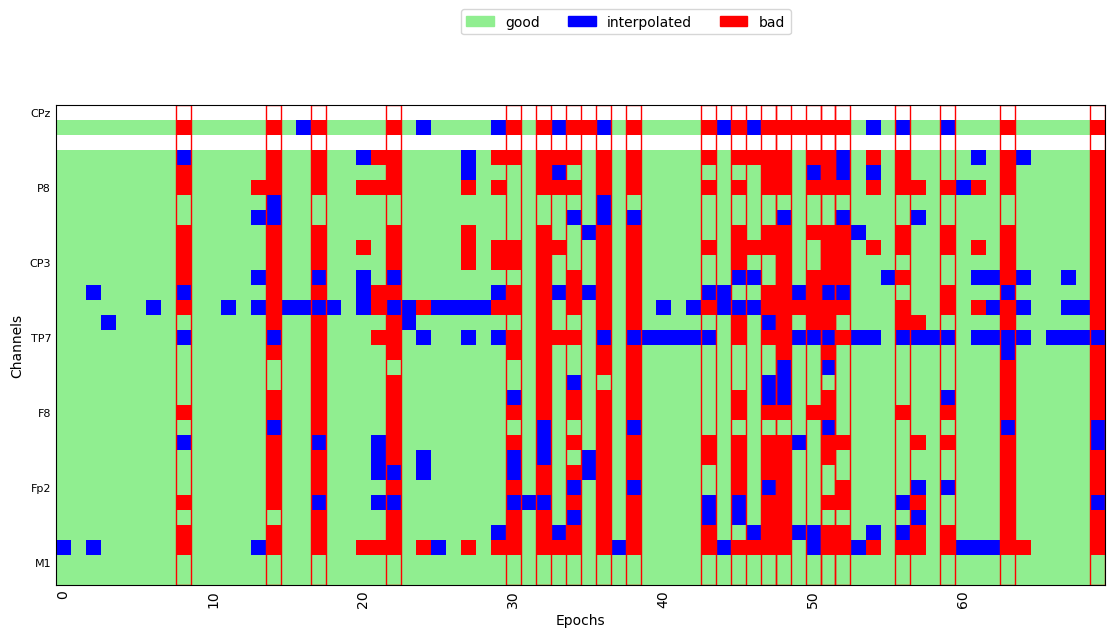

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0017_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1919 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0017_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

... (7 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/427 [00:00<?,       ?it/s]

Dropped 99 epochs: 2, 7, 8, 9, 11, 13, 15, 17, 18, 21, 23, 25, 26, 34, 37, 39, 47, 49, 59, 65, 66, 69, 77, 78, 86, 89, 94, 96, 99, 102, 104, 108, 113, 116, 125, 131, 133, 134, 139, 141, 147, 148, 149, 150, 159, 160, 163, 165, 166, 172, 176, 177, 178, 180, 185, 188, 193, 197, 201, 209, 224, 226, 231, 234, 235, 241, 243, 247, 249, 253, 259, 262, 266, 272, 275, 277, 303, 305, 311, 321, 327, 334, 337, 343, 344, 347, 356, 359, 360, 371, 372, 376, 401, 402, 404, 411, 414, 419, 425


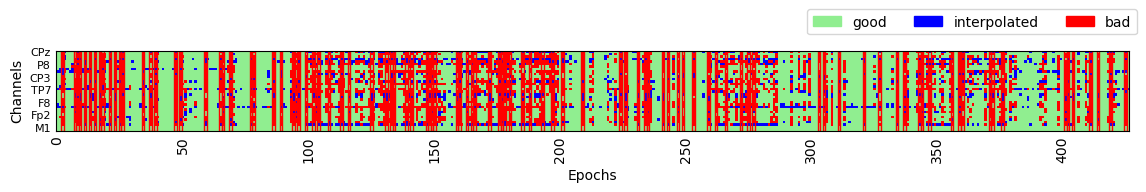

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 20 epochs: 0, 5, 12, 14, 15, 18, 19, 21, 24, 32, 35, 40, 44, 49, 51, 53, 55, 57, 60, 64


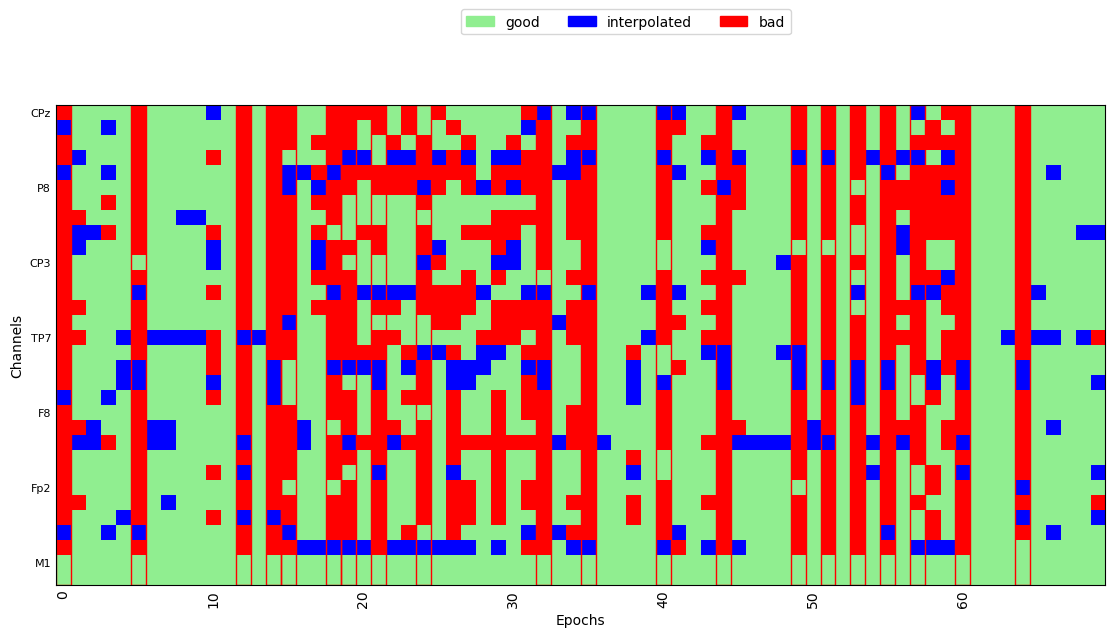

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/414 [00:00<?,       ?it/s]

Dropped 114 epochs: 1, 2, 7, 9, 13, 15, 16, 18, 22, 25, 28, 35, 36, 37, 40, 41, 42, 48, 49, 50, 53, 61, 63, 70, 76, 82, 92, 99, 107, 109, 110, 114, 116, 126, 127, 129, 138, 146, 147, 152, 163, 169, 181, 185, 186, 188, 191, 196, 197, 199, 200, 204, 205, 206, 207, 208, 209, 210, 211, 213, 215, 217, 220, 221, 225, 226, 230, 233, 236, 237, 240, 241, 246, 252, 254, 256, 258, 261, 263, 266, 274, 281, 298, 299, 300, 302, 303, 306, 308, 310, 323, 324, 341, 348, 352, 354, 358, 361, 362, 364, 365, 373, 381, 383, 385, 387, 388, 392, 395, 400, 402, 406, 407, 413


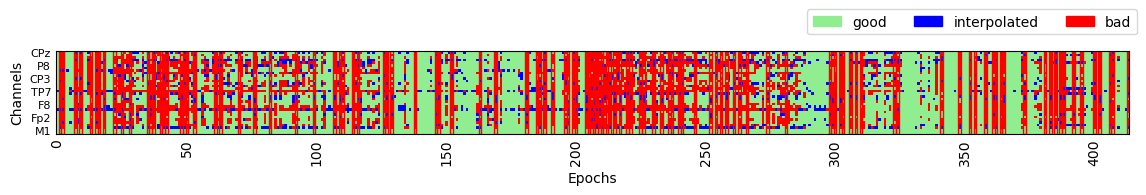

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 19 epochs: 4, 5, 7, 9, 11, 12, 17, 18, 21, 24, 27, 34, 36, 42, 43, 55, 64, 67, 68


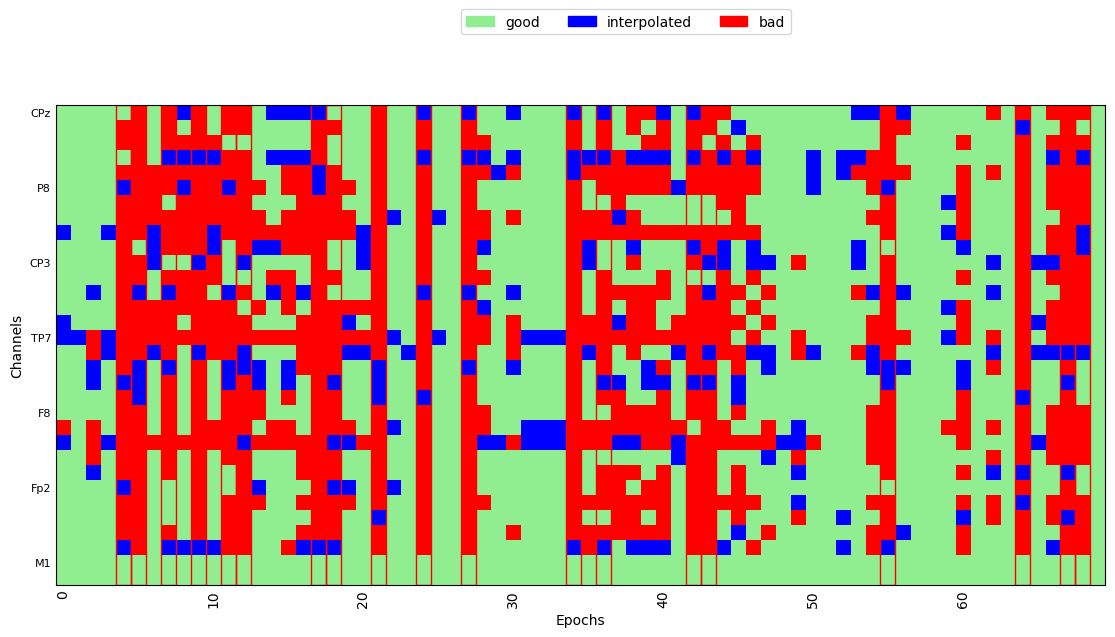

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/411 [00:00<?,       ?it/s]

Dropped 118 epochs: 1, 6, 10, 12, 13, 21, 23, 34, 35, 37, 39, 40, 41, 44, 45, 49, 51, 58, 59, 61, 68, 70, 72, 73, 75, 79, 92, 99, 104, 106, 108, 110, 115, 117, 120, 125, 127, 128, 131, 132, 133, 135, 136, 139, 150, 152, 154, 158, 165, 169, 171, 172, 173, 176, 181, 186, 196, 197, 199, 201, 205, 206, 208, 209, 210, 213, 219, 220, 221, 224, 226, 227, 233, 236, 242, 246, 248, 253, 259, 264, 271, 273, 274, 275, 281, 283, 284, 288, 300, 309, 311, 314, 315, 316, 317, 322, 323, 324, 331, 337, 351, 362, 366, 367, 370, 372, 374, 375, 378, 383, 386, 388, 399, 400, 401, 404, 408, 409


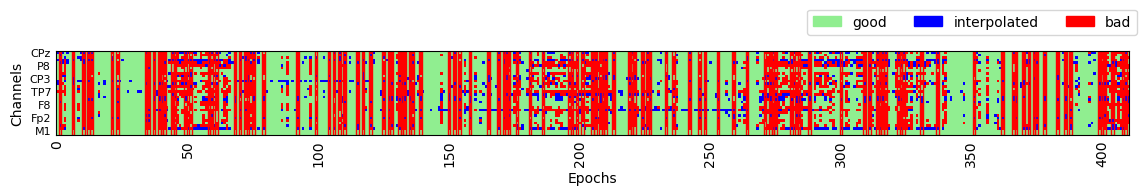

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 23 epochs: 0, 3, 4, 10, 12, 21, 23, 28, 36, 38, 40, 42, 45, 46, 48, 51, 53, 56, 60, 63, 66, 68, 69


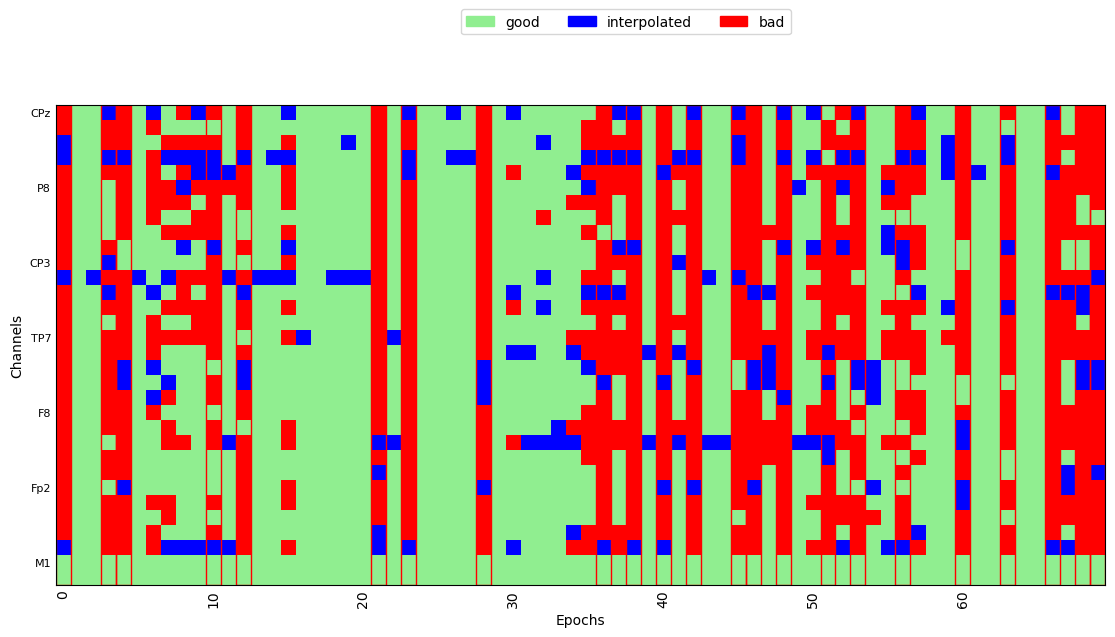

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/390 [00:00<?,       ?it/s]

Dropped 124 epochs: 4, 12, 13, 14, 21, 24, 28, 30, 31, 34, 41, 42, 44, 50, 53, 57, 58, 59, 63, 64, 67, 75, 76, 77, 78, 79, 82, 94, 109, 114, 118, 123, 127, 130, 131, 133, 137, 139, 141, 144, 147, 148, 149, 152, 154, 162, 163, 164, 165, 166, 173, 177, 178, 182, 183, 184, 186, 187, 190, 191, 192, 193, 196, 200, 201, 203, 205, 210, 211, 214, 216, 221, 223, 224, 226, 227, 232, 233, 235, 238, 239, 240, 241, 244, 245, 246, 248, 250, 251, 252, 253, 255, 256, 257, 261, 265, 266, 270, 276, 279, 280, 288, 289, 290, 292, 293, 296, 303, 306, 309, 319, 321, 322, 323, 325, 330, 335, 354, 372, 373, 376, 378, 383, 387


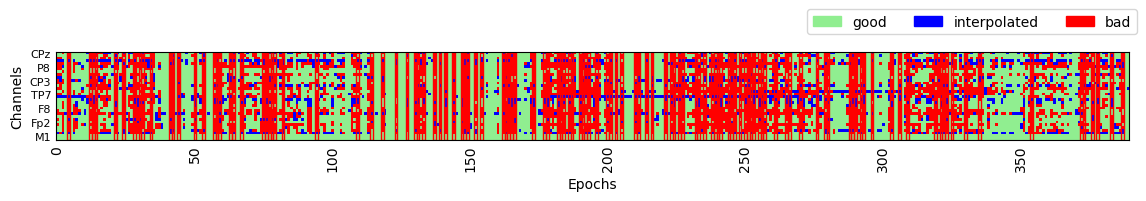

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/67 [00:00<?,       ?it/s]

Dropped 21 epochs: 3, 5, 7, 9, 12, 21, 23, 28, 29, 30, 36, 38, 43, 47, 49, 50, 51, 53, 59, 64, 65


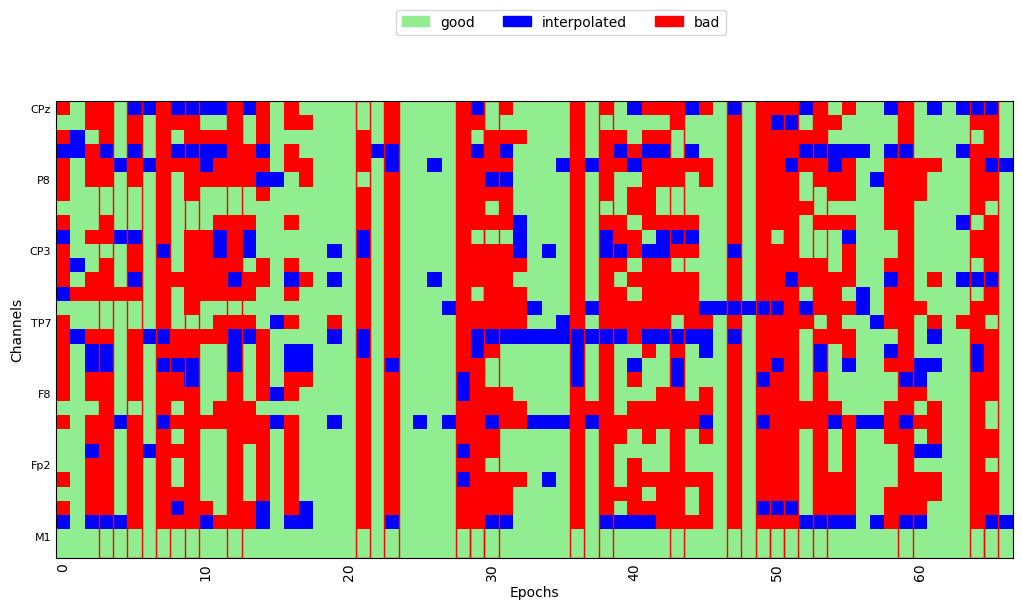

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0010_VOT_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1994 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0010_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_

Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/26 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/26 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/1994 [00:00<?,       ?it/s]

... (7 outputs left out)





Estimated consensus=0.50 and n_interpolate=4


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 6 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

Dropped 124 epochs: 1, 4, 10, 11, 15, 24, 27, 32, 40, 54, 55, 68, 73, 80, 95, 104, 106, 111, 118, 120, 123, 131, 144, 145, 154, 160, 163, 166, 169, 170, 171, 175, 189, 195, 198, 199, 202, 203, 204, 205, 207, 208, 209, 217, 224, 227, 231, 232, 233, 235, 236, 239, 242, 245, 246, 250, 253, 254, 256, 257, 260, 263, 268, 269, 285, 286, 287, 288, 292, 293, 300, 306, 307, 309, 311, 312, 314, 316, 318, 321, 322, 323, 325, 326, 328, 329, 331, 332, 333, 338, 339, 340, 344, 345, 346, 347, 350, 360, 365, 366, 368, 369, 370, 372, 375, 376, 379, 382, 383, 384, 386, 388, 391, 393, 394, 396, 398, 412, 415, 417, 418, 421, 422, 424


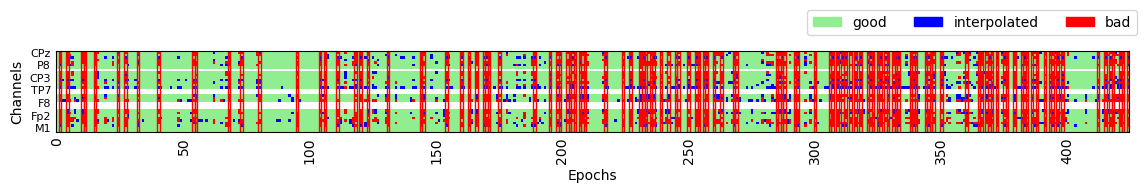

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 26 sensor positions
Interpolating 6 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 6 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 20 epochs: 1, 2, 17, 27, 36, 37, 43, 45, 48, 49, 50, 51, 55, 58, 63, 64, 65, 66, 68, 69


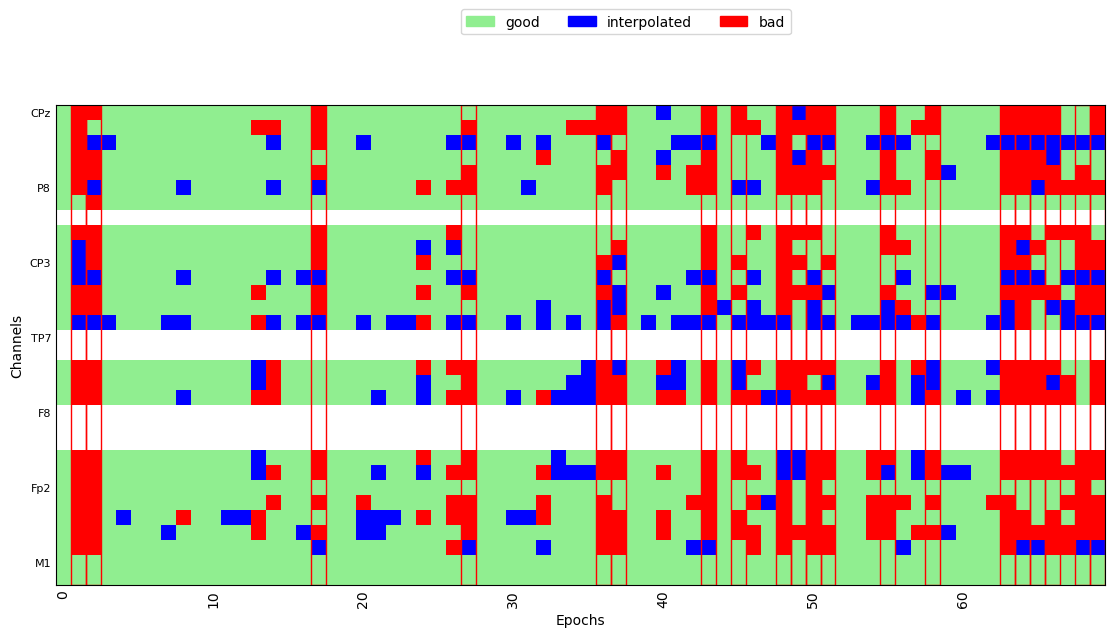

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 26 sensor positions
Interpolating 6 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 6 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

Dropped 196 epochs: 8, 9, 11, 14, 16, 20, 27, 35, 37, 39, 40, 43, 44, 47, 49, 51, 52, 54, 55, 57, 58, 59, 64, 73, 76, 78, 81, 83, 84, 85, 86, 87, 90, 91, 92, 93, 94, 96, 97, 98, 99, 101, 104, 109, 110, 112, 113, 115, 118, 119, 121, 124, 127, 128, 130, 132, 134, 136, 137, 138, 139, 141, 142, 144, 146, 149, 150, 151, 152, 154, 156, 159, 162, 163, 166, 168, 173, 179, 181, 184, 185, 186, 187, 188, 189, 192, 193, 195, 200, 201, 204, 205, 206, 207, 210, 211, 212, 214, 215, 216, 217, 220, 221, 223, 224, 225, 233, 234, 237, 240, 243, 244, 245, 246, 248, 250, 252, 253, 254, 255, 258, 259, 262, 265, 272, 273, 274, 280, 281, 282, 284, 285, 286, 295, 302, 303, 306, 307, 309, 310, 311, 312, 313, 316, 318, 321, 323, 324, 329, 330, 332, 334, 336, 338, 340, 341, 344, 345, 349, 350, 353, 355, 356, 357, 358, 359, 361, 362, 363, 364, 366, 370, 372, 374, 375, 376, 378, 380, 381, 383, 384, 385, 386, 387, 390, 392, 395, 396, 397, 401, 402, 404, 407, 410, 412, 419


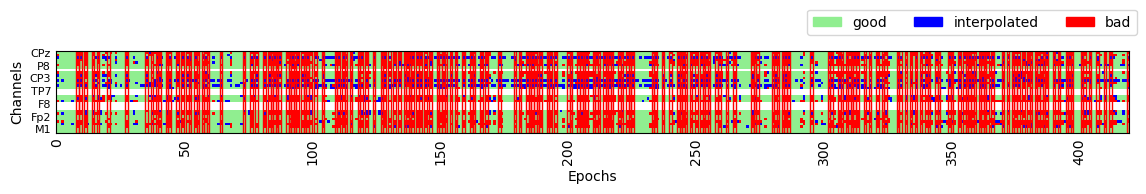

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 26 sensor positions
Interpolating 6 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 6 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 31 epochs: 10, 13, 14, 15, 16, 17, 18, 19, 20, 23, 24, 29, 31, 32, 33, 34, 35, 36, 37, 42, 44, 49, 50, 51, 52, 53, 58, 59, 60, 67, 69


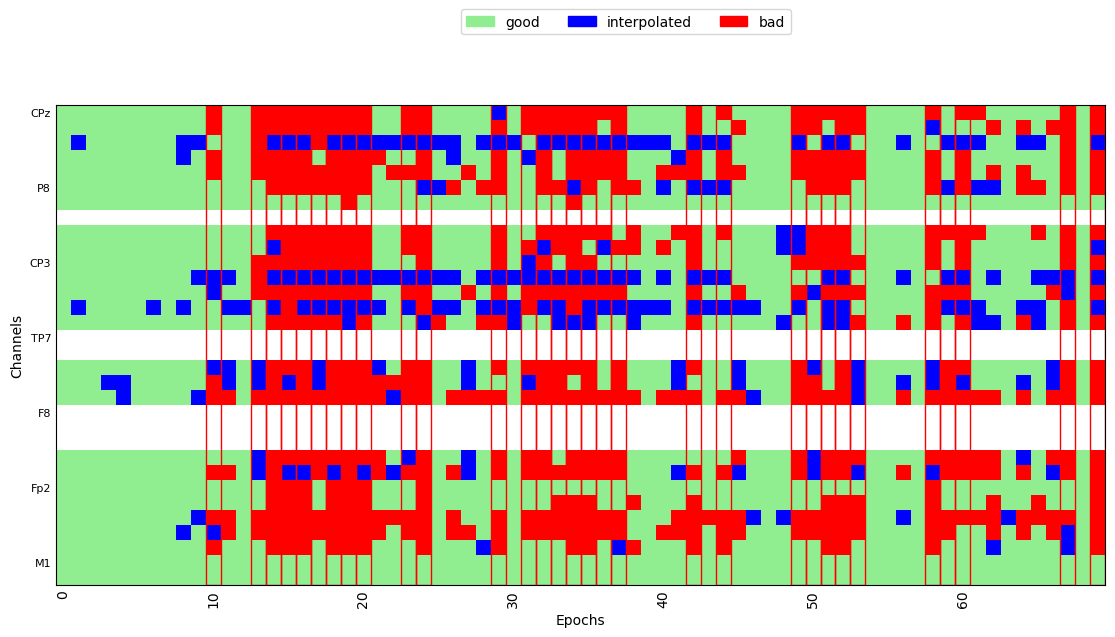

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 26 sensor positions
Interpolating 6 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 6 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/437 [00:00<?,       ?it/s]

Dropped 189 epochs: 1, 2, 3, 4, 6, 9, 10, 11, 12, 13, 14, 16, 19, 21, 22, 24, 25, 27, 29, 30, 34, 35, 36, 39, 42, 43, 44, 45, 49, 53, 54, 55, 56, 57, 58, 60, 61, 62, 64, 67, 70, 72, 74, 75, 76, 77, 78, 79, 82, 85, 86, 87, 88, 89, 90, 91, 93, 95, 97, 98, 99, 100, 102, 103, 107, 108, 109, 111, 115, 116, 117, 120, 121, 123, 124, 125, 126, 128, 129, 130, 131, 132, 133, 134, 136, 139, 141, 143, 144, 146, 147, 148, 149, 150, 152, 153, 154, 156, 158, 159, 161, 162, 164, 168, 169, 173, 174, 176, 177, 178, 179, 180, 183, 185, 186, 187, 188, 189, 190, 191, 194, 196, 199, 200, 201, 203, 204, 206, 209, 210, 214, 217, 218, 219, 226, 227, 229, 230, 231, 232, 233, 236, 239, 240, 241, 243, 244, 247, 252, 254, 257, 258, 261, 269, 270, 275, 280, 285, 286, 288, 289, 292, 298, 299, 300, 306, 308, 310, 312, 316, 322, 342, 346, 351, 360, 361, 366, 382, 386, 394, 398, 399, 406, 412, 418, 420, 421, 425, 434


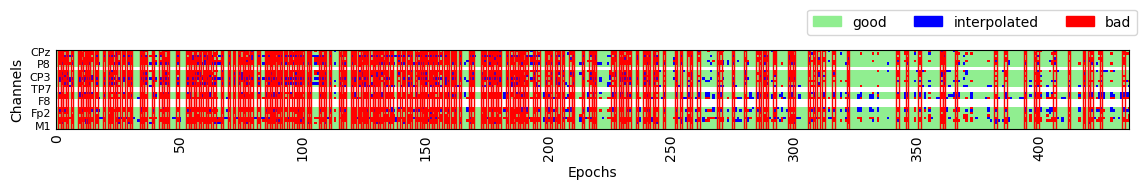

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 26 sensor positions
Interpolating 6 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 6 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 24 epochs: 3, 4, 6, 7, 8, 9, 10, 12, 15, 19, 20, 21, 23, 24, 25, 26, 27, 28, 34, 37, 38, 45, 49, 66


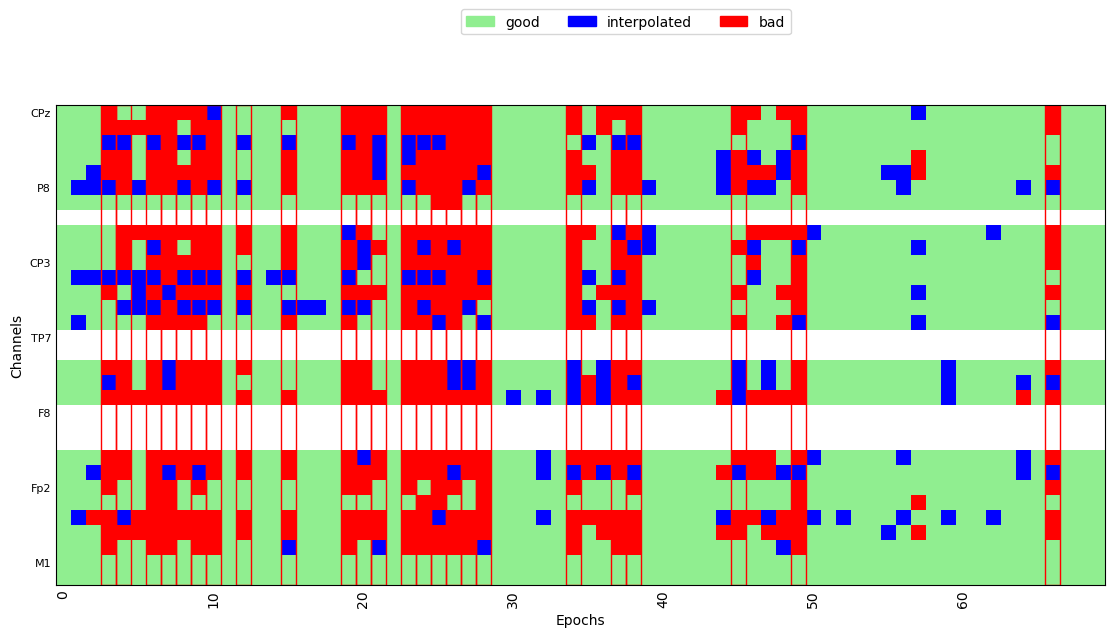

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 26 sensor positions
Interpolating 6 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 6 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/432 [00:00<?,       ?it/s]

Dropped 148 epochs: 1, 17, 18, 20, 21, 24, 25, 28, 39, 40, 43, 50, 60, 64, 76, 77, 85, 88, 89, 94, 95, 96, 98, 99, 101, 102, 107, 108, 113, 116, 117, 119, 120, 122, 125, 126, 127, 128, 133, 134, 137, 141, 142, 149, 153, 154, 155, 165, 167, 169, 172, 175, 176, 177, 181, 182, 184, 188, 189, 190, 192, 193, 198, 199, 205, 208, 217, 219, 220, 222, 224, 233, 235, 236, 239, 241, 243, 248, 251, 253, 254, 257, 258, 259, 261, 262, 263, 264, 266, 267, 269, 270, 271, 273, 275, 278, 283, 284, 286, 287, 288, 293, 296, 297, 305, 306, 307, 310, 314, 317, 319, 326, 327, 330, 332, 333, 345, 346, 351, 352, 358, 359, 361, 362, 365, 366, 367, 369, 373, 374, 376, 379, 380, 383, 388, 392, 394, 395, 402, 403, 406, 411, 412, 415, 418, 422, 424, 429


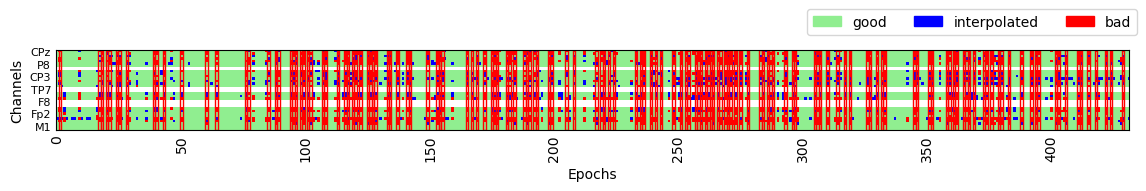

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 26 sensor positions
Interpolating 6 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 6 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 27 epochs: 0, 1, 11, 15, 20, 22, 31, 32, 33, 35, 38, 39, 40, 41, 42, 43, 44, 46, 49, 52, 54, 56, 57, 58, 60, 66, 69


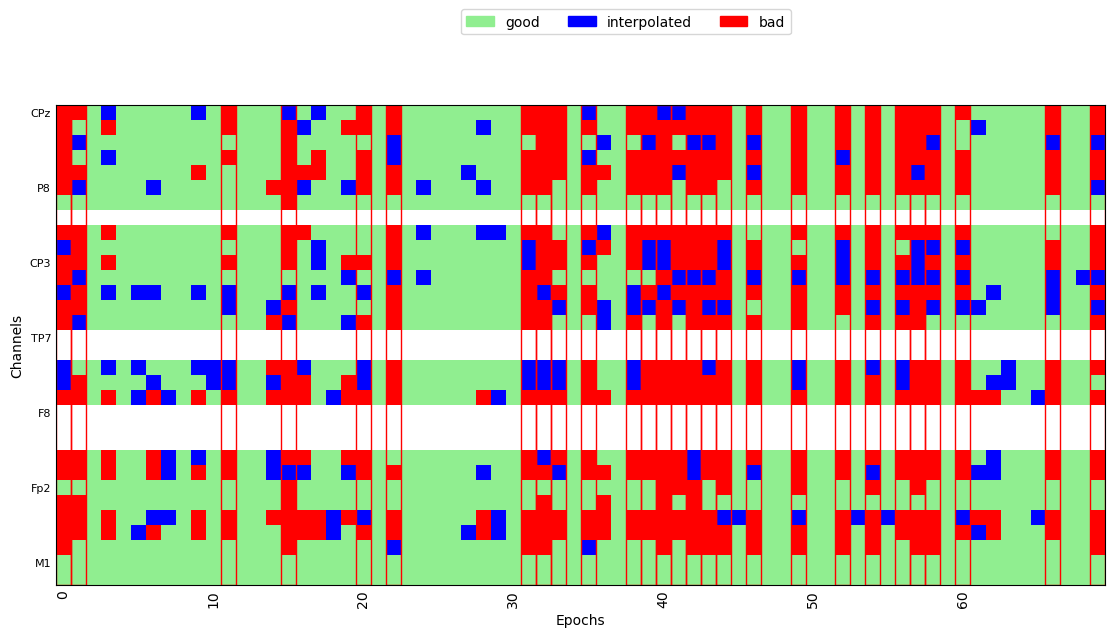

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 26 sensor positions
Interpolating 6 sensors
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0006_VOT_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1921 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0006_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

... (7 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/421 [00:00<?,       ?it/s]

Dropped 76 epochs: 3, 9, 14, 23, 27, 38, 42, 47, 50, 59, 68, 74, 93, 100, 104, 119, 133, 134, 135, 136, 137, 138, 140, 142, 143, 145, 156, 172, 173, 176, 179, 183, 186, 190, 191, 192, 230, 239, 245, 257, 260, 262, 266, 268, 269, 271, 286, 293, 296, 300, 301, 304, 308, 312, 317, 323, 324, 334, 336, 340, 341, 342, 343, 347, 350, 355, 356, 361, 363, 371, 401, 406, 407, 412, 413, 420


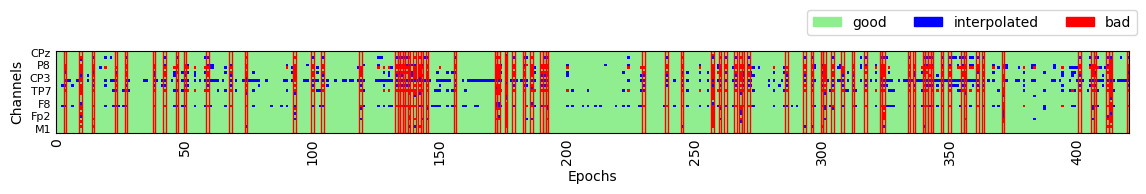

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 12 epochs: 3, 9, 17, 22, 23, 24, 37, 43, 51, 58, 65, 68


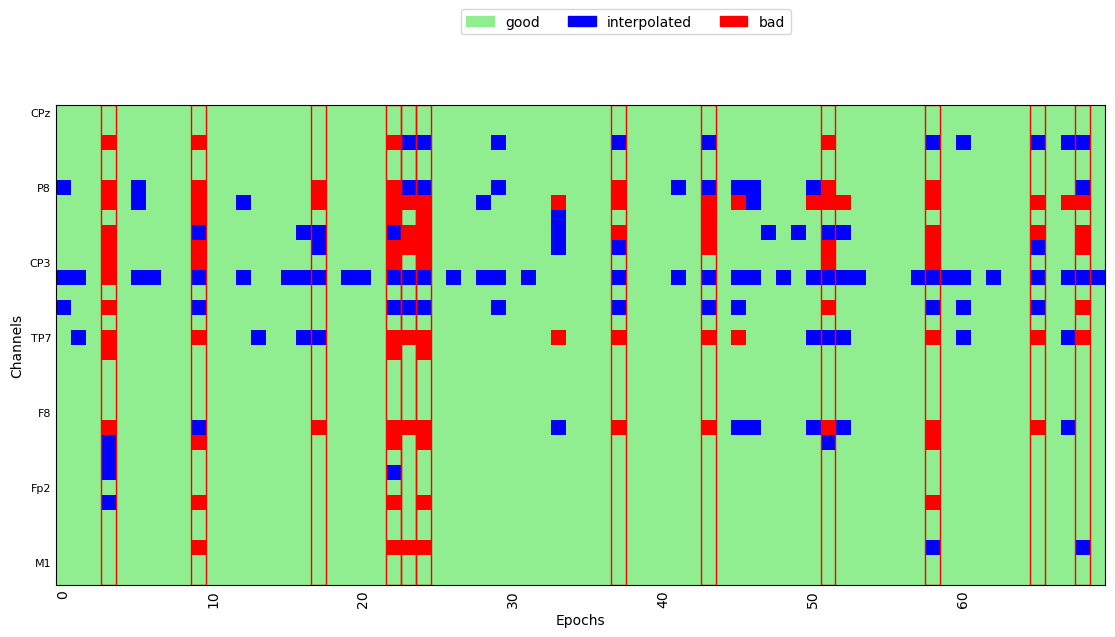

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/424 [00:00<?,       ?it/s]

Dropped 129 epochs: 21, 44, 60, 97, 98, 99, 105, 121, 138, 139, 140, 142, 144, 149, 150, 152, 153, 154, 156, 157, 159, 162, 168, 170, 171, 179, 180, 181, 182, 183, 190, 193, 194, 198, 208, 214, 220, 228, 231, 232, 238, 243, 245, 246, 247, 251, 256, 257, 258, 259, 263, 264, 271, 272, 280, 283, 284, 285, 288, 289, 290, 291, 294, 299, 300, 305, 310, 313, 315, 317, 320, 321, 322, 323, 324, 326, 327, 328, 329, 331, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 355, 356, 361, 366, 367, 368, 371, 373, 374, 379, 380, 381, 382, 383, 387, 388, 392, 393, 394, 396, 397, 398, 399, 400, 401, 402, 403, 407, 408, 410, 411, 413, 414, 416, 418, 419, 421, 423


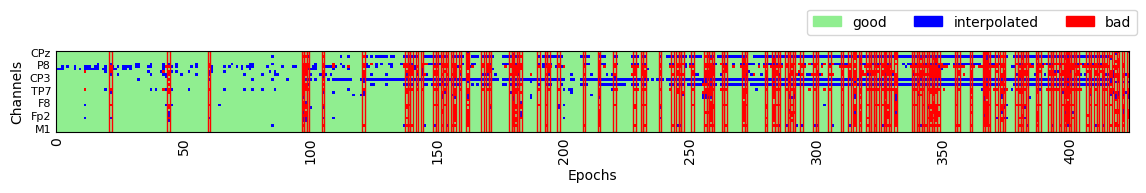

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 25 epochs: 6, 20, 33, 40, 42, 45, 46, 47, 48, 49, 50, 53, 56, 57, 58, 59, 61, 62, 63, 64, 65, 66, 67, 68, 69


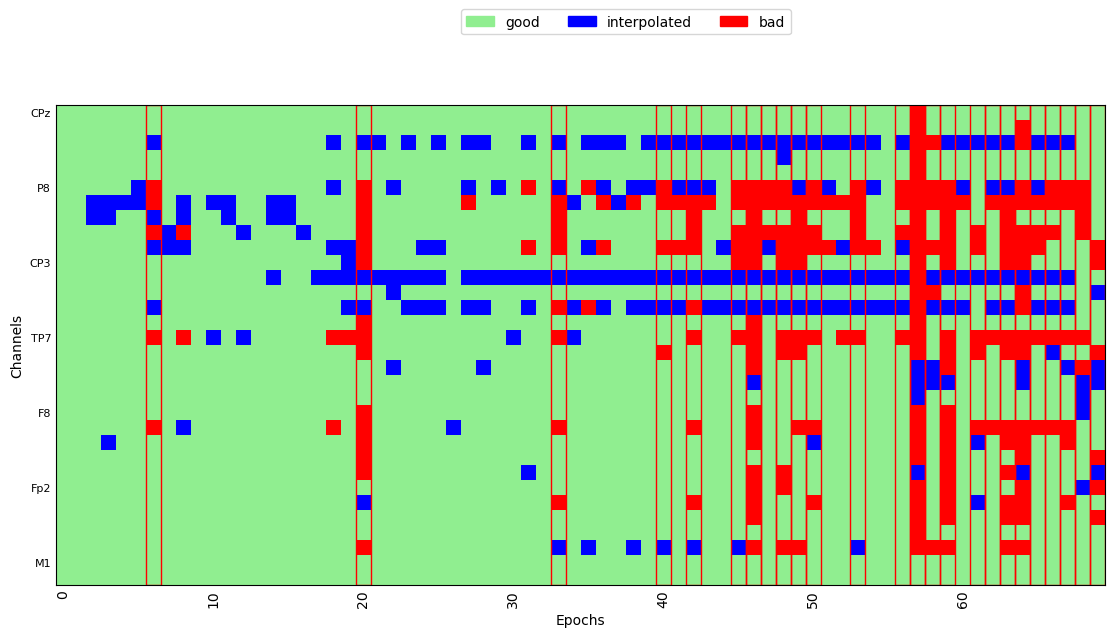

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/403 [00:00<?,       ?it/s]

Dropped 158 epochs: 10, 11, 12, 14, 26, 27, 28, 30, 35, 38, 39, 40, 41, 46, 47, 48, 53, 54, 57, 58, 63, 70, 71, 72, 73, 74, 76, 82, 83, 84, 87, 92, 95, 96, 98, 99, 100, 104, 105, 115, 119, 121, 124, 125, 126, 129, 130, 131, 135, 140, 142, 144, 147, 150, 156, 161, 162, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 182, 186, 190, 192, 193, 194, 196, 197, 199, 208, 209, 211, 212, 217, 218, 223, 225, 226, 227, 228, 230, 231, 232, 233, 234, 236, 237, 239, 240, 244, 246, 249, 250, 254, 262, 263, 264, 269, 271, 272, 273, 274, 275, 278, 285, 287, 288, 292, 293, 297, 298, 299, 300, 310, 311, 314, 317, 318, 321, 324, 327, 328, 331, 341, 343, 350, 351, 352, 353, 358, 359, 360, 367, 368, 369, 375, 376, 377, 378, 379, 381, 383, 384, 385, 386, 387, 391, 392, 401, 402


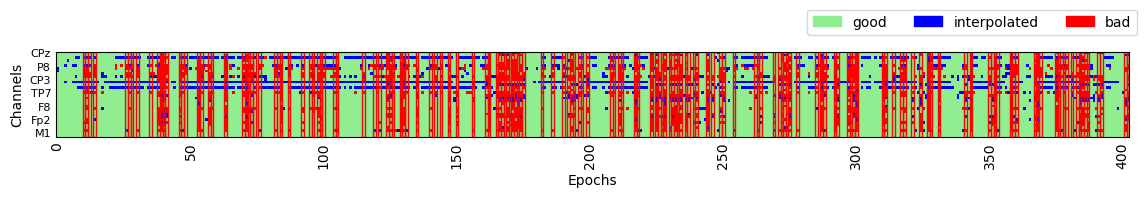

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

Dropped 22 epochs: 1, 3, 6, 15, 17, 21, 26, 27, 28, 30, 35, 37, 40, 41, 47, 52, 54, 57, 59, 60, 64, 65


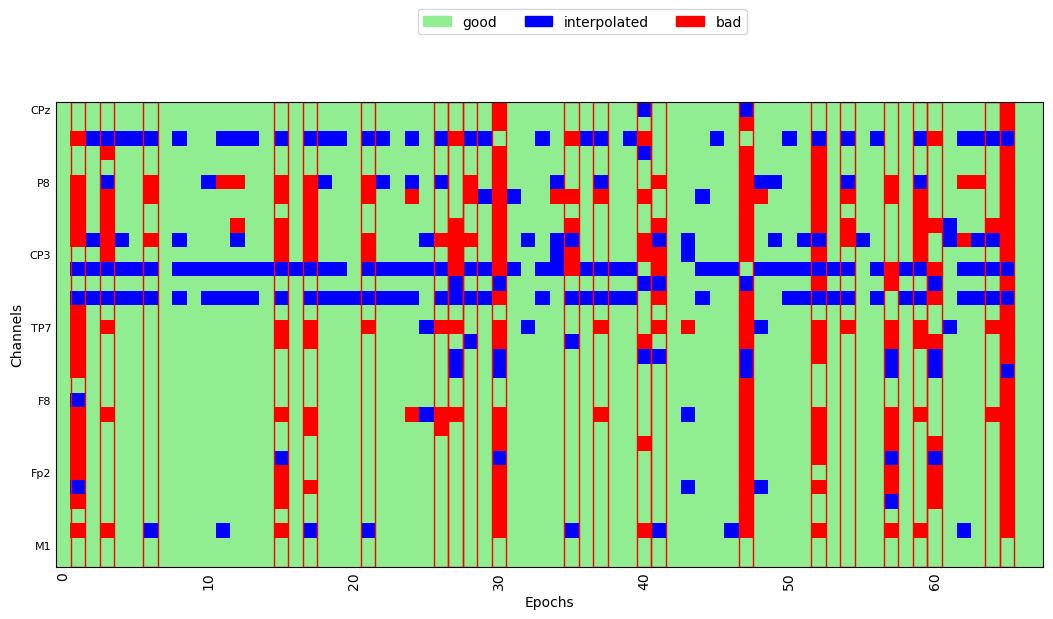

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/397 [00:00<?,       ?it/s]

Dropped 212 epochs: 6, 9, 11, 16, 17, 19, 24, 29, 30, 31, 38, 39, 42, 43, 47, 51, 56, 57, 58, 59, 61, 68, 70, 71, 72, 76, 77, 78, 79, 81, 85, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 103, 104, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 121, 122, 123, 124, 125, 126, 127, 129, 130, 131, 132, 133, 134, 135, 138, 139, 140, 141, 144, 145, 146, 147, 148, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 173, 174, 176, 177, 178, 179, 180, 182, 184, 185, 186, 188, 189, 191, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 205, 207, 210, 211, 212, 215, 217, 219, 220, 221, 222, 224, 225, 226, 230, 231, 232, 233, 249, 250, 251, 252, 253, 255, 268, 270, 271, 272, 273, 276, 277, 278, 279, 283, 286, 287, 288, 289, 293, 300, 305, 306, 307, 309, 310, 315, 316, 318, 320, 327, 328, 329, 330, 332, 333, 335, 338, 340, 341, 342, 344, 356, 359, 360, 361, 363, 366, 367, 369, 370, 371, 372, 373, 377, 378, 379, 380, 384, 385, 

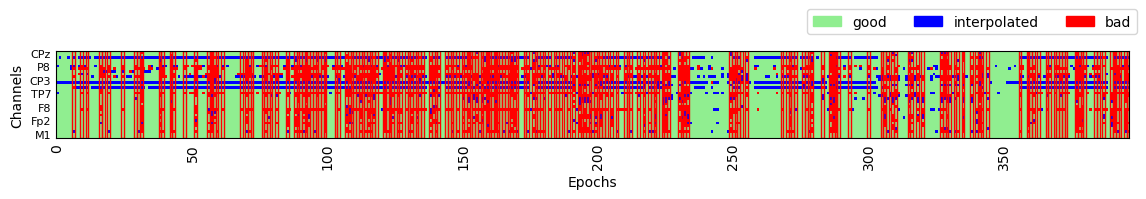

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

Dropped 43 epochs: 2, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 25, 27, 29, 30, 32, 33, 35, 36, 38, 39, 40, 41, 42, 45, 46, 49, 51, 52, 53, 55, 56, 57, 59, 60, 62, 63, 64, 66, 67


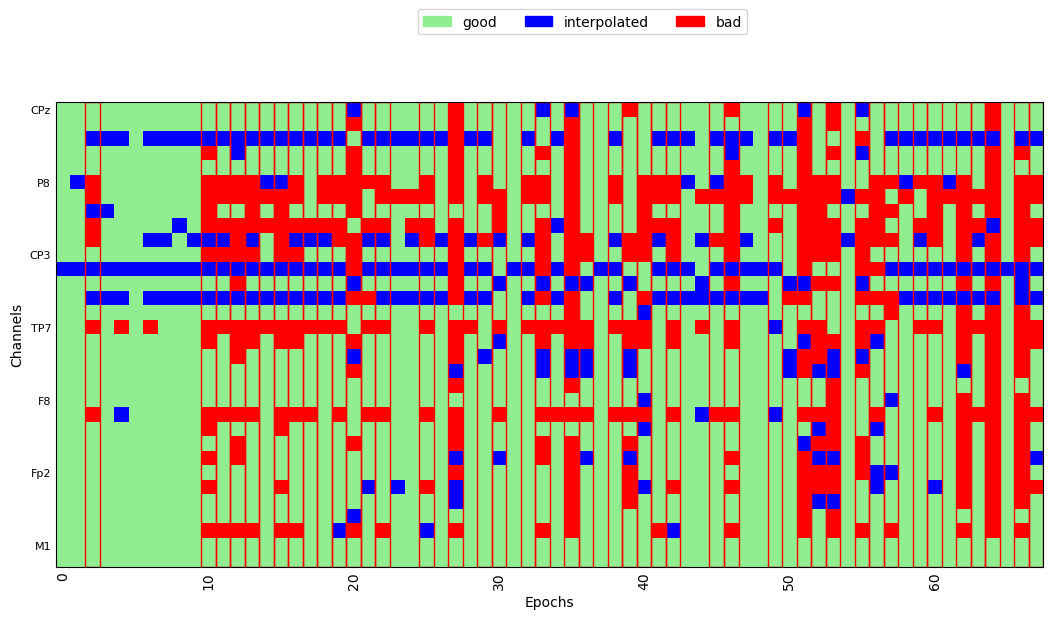

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0024_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1944 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0024_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_c

Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])
/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 3 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Creating augmented epochs : 0/29 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/29 [00:00<?,       ?it/s]

... (8 outputs left out)





Estimated consensus=0.30 and n_interpolate=4


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 3 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/401 [00:00<?,       ?it/s]

Dropped 255 epochs: 0, 3, 5, 6, 7, 8, 9, 13, 16, 19, 20, 23, 25, 27, 28, 30, 32, 33, 35, 38, 39, 40, 41, 46, 49, 51, 61, 64, 65, 69, 70, 73, 74, 75, 78, 81, 83, 84, 85, 89, 93, 94, 95, 96, 97, 102, 103, 104, 106, 107, 109, 112, 114, 115, 116, 117, 120, 121, 122, 123, 124, 125, 126, 127, 130, 131, 132, 133, 135, 136, 137, 139, 140, 142, 143, 144, 145, 146, 147, 149, 150, 151, 152, 153, 154, 155, 156, 157, 159, 160, 161, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 266, 267, 269, 270, 271, 272, 274, 277, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 291, 29

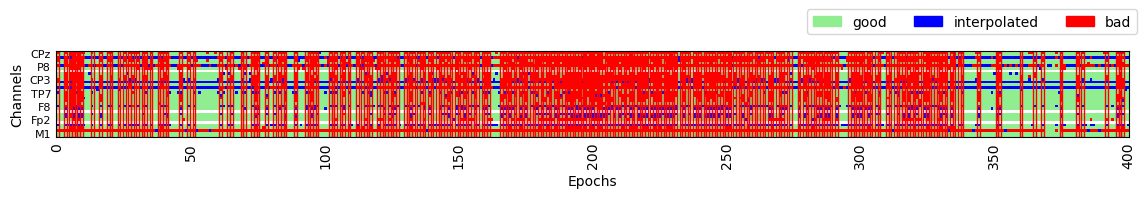

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 29 sensor positions
Interpolating 3 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 3 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 41 epochs: 0, 3, 4, 6, 11, 13, 17, 18, 20, 22, 23, 25, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 42, 43, 44, 45, 46, 47, 48, 49, 52, 53, 54, 62, 66, 68, 69


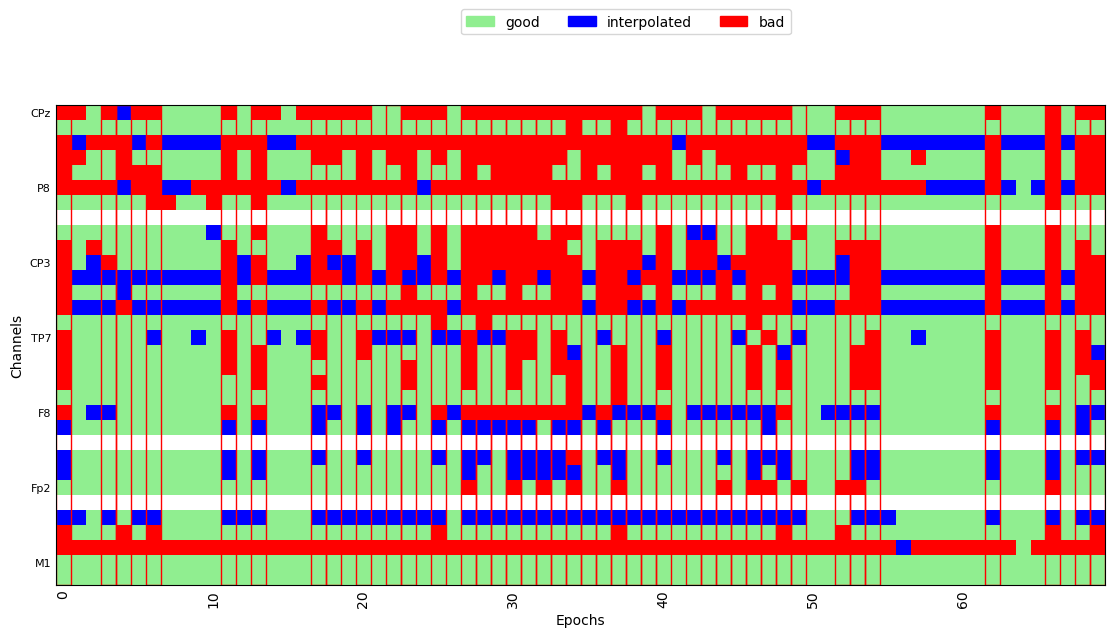

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 29 sensor positions
Interpolating 3 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 3 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

Dropped 257 epochs: 3, 6, 7, 8, 10, 11, 14, 15, 16, 17, 21, 23, 24, 25, 26, 27, 28, 29, 33, 34, 39, 40, 43, 44, 45, 46, 47, 49, 59, 61, 63, 90, 91, 92, 94, 97, 101, 109, 110, 113, 117, 119, 120, 124, 125, 130, 131, 132, 133, 134, 138, 139, 140, 142, 143, 144, 145, 152, 154, 156, 157, 158, 160, 162, 163, 168, 169, 171, 174, 176, 185, 188, 190, 193, 195, 197, 198, 199, 200, 201, 202, 203, 204, 207, 208, 209, 210, 212, 213, 214, 216, 217, 218, 219, 220, 221, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 264, 266, 267, 268, 269, 270, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 301, 302, 303, 304, 305, 306, 307, 308, 311, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 

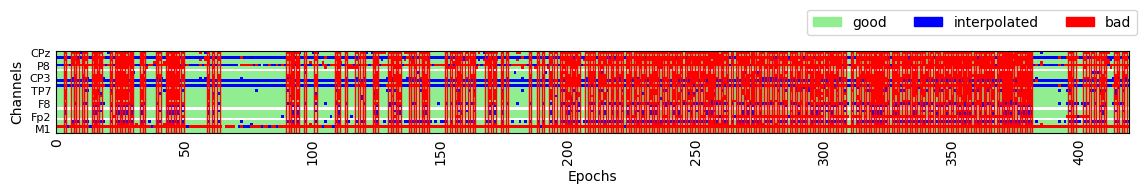

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 29 sensor positions
Interpolating 3 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 3 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 47 epochs: 0, 1, 2, 4, 6, 8, 14, 15, 23, 24, 25, 26, 27, 29, 31, 33, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 64, 66, 67, 68


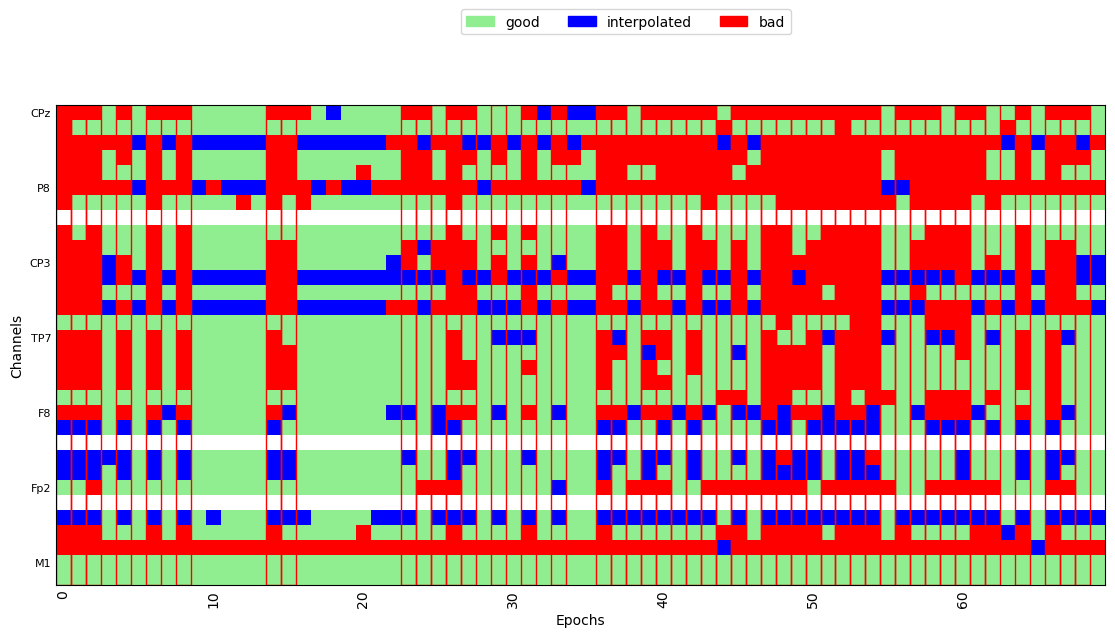

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 29 sensor positions
Interpolating 3 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 3 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/416 [00:00<?,       ?it/s]

Dropped 55 epochs: 2, 3, 5, 23, 56, 70, 77, 83, 110, 122, 134, 135, 142, 179, 180, 185, 194, 198, 204, 207, 210, 212, 224, 227, 232, 239, 251, 263, 268, 275, 277, 279, 297, 305, 306, 309, 310, 311, 312, 314, 317, 318, 320, 321, 329, 334, 340, 363, 365, 379, 382, 387, 389, 399, 402


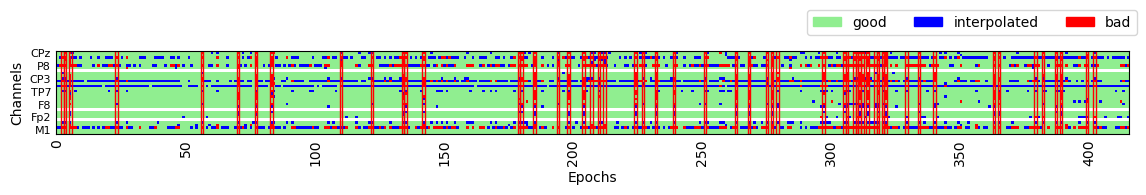

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 29 sensor positions
Interpolating 3 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 3 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 10 epochs: 24, 36, 39, 42, 47, 48, 51, 63, 66, 68


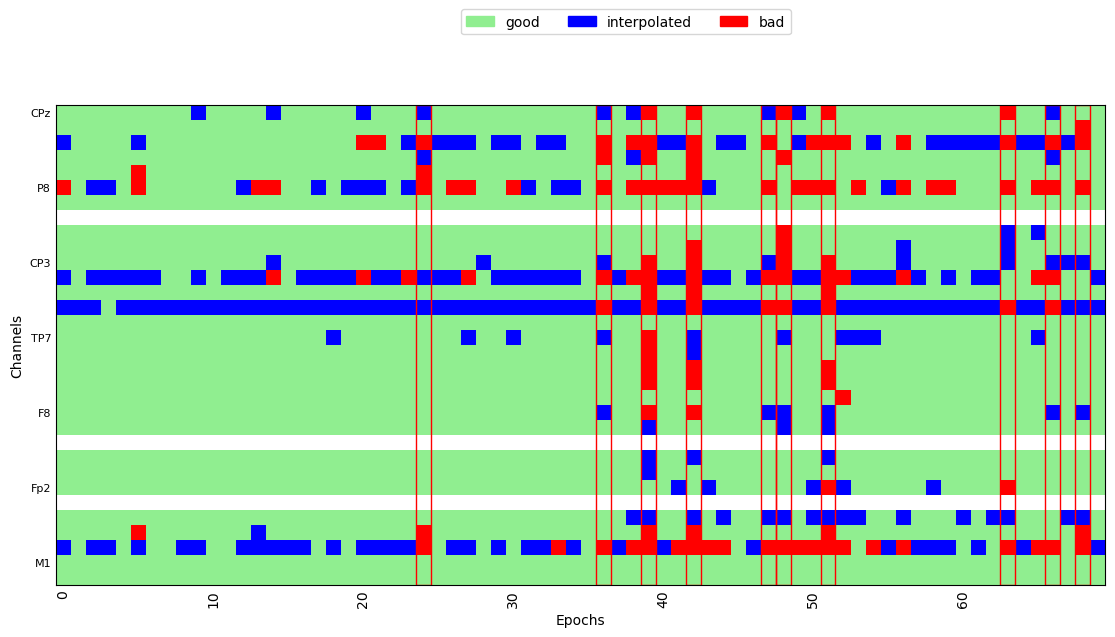

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 29 sensor positions
Interpolating 3 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 3 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/427 [00:00<?,       ?it/s]

Dropped 64 epochs: 40, 43, 55, 57, 84, 85, 107, 109, 119, 124, 167, 171, 188, 193, 199, 203, 204, 211, 235, 236, 237, 238, 248, 272, 273, 286, 287, 324, 332, 333, 339, 340, 343, 346, 352, 354, 355, 357, 358, 367, 368, 370, 371, 372, 373, 377, 378, 382, 383, 389, 390, 394, 398, 400, 401, 402, 403, 404, 406, 407, 409, 412, 420, 421


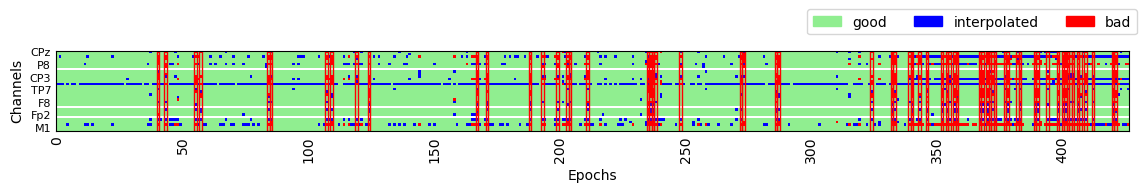

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 29 sensor positions
Interpolating 3 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 3 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 32, 36, 37, 39, 41, 43, 53, 60, 61, 66, 68


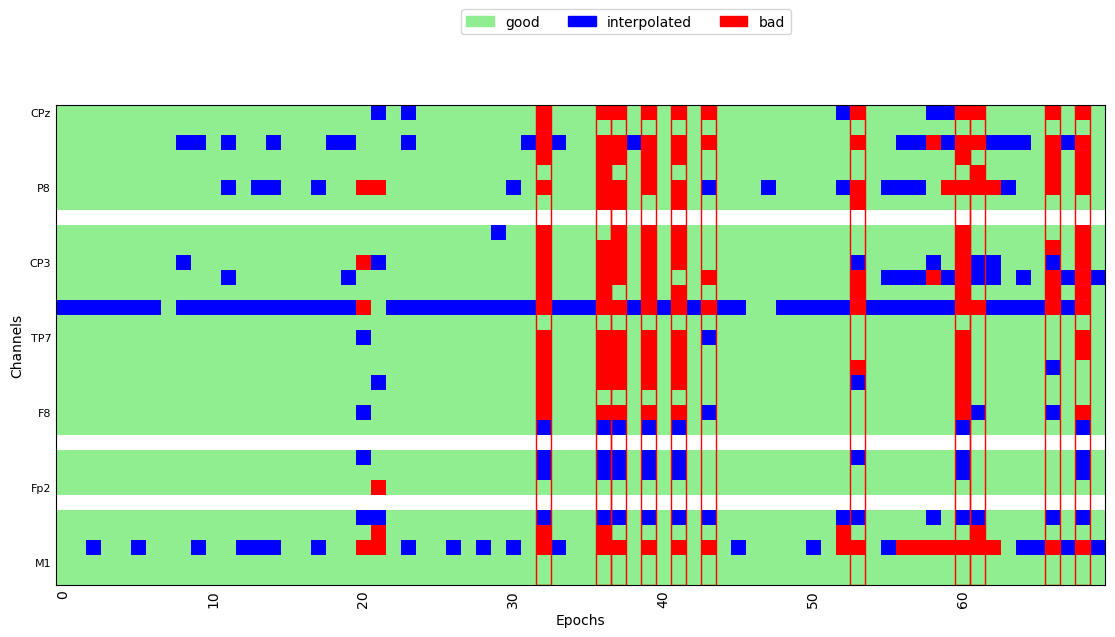

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 29 sensor positions
Interpolating 3 sensors
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0002_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1984 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0002_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])
/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Creating augmented epochs : 0/31 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/31 [00:00<?,       ?it/s]

... (8 outputs left out)





Estimated consensus=0.20 and n_interpolate=1


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/414 [00:00<?,       ?it/s]

Dropped 35 epochs: 4, 27, 30, 32, 57, 59, 73, 77, 116, 146, 158, 164, 166, 176, 193, 200, 201, 246, 249, 272, 273, 279, 297, 309, 316, 328, 332, 339, 342, 350, 362, 372, 376, 381, 412


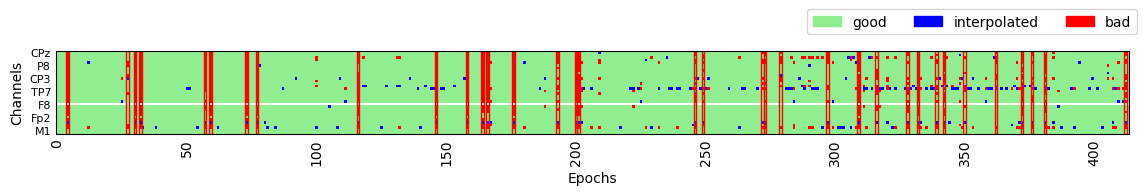

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 10 epochs: 16, 19, 24, 35, 41, 43, 48, 49, 55, 61


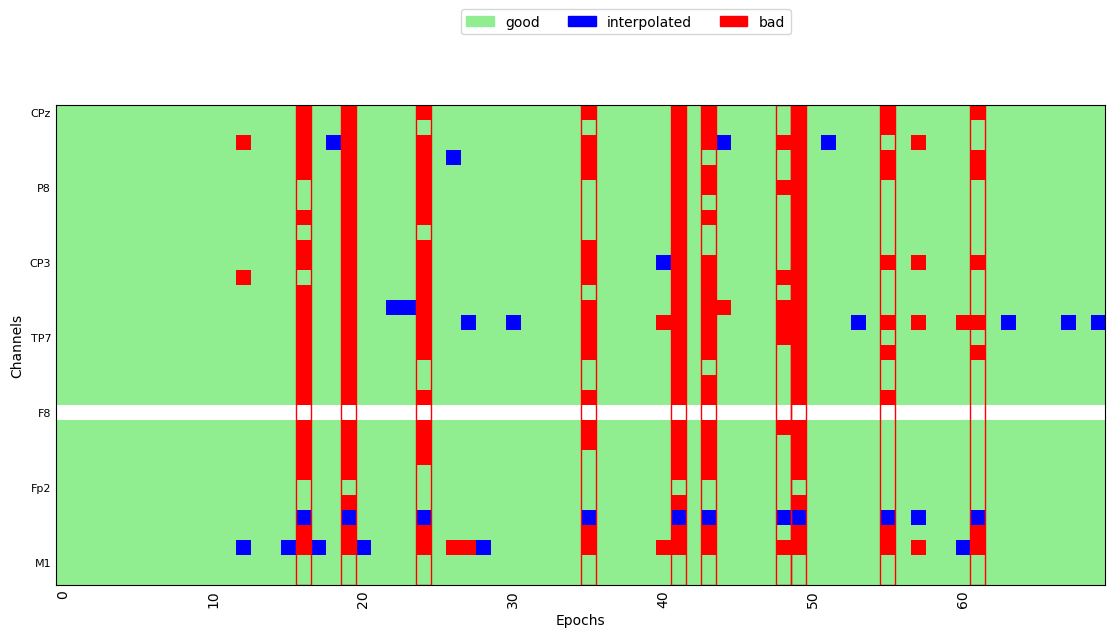

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/437 [00:00<?,       ?it/s]

Dropped 220 epochs: 3, 5, 8, 29, 30, 33, 39, 56, 60, 66, 78, 98, 104, 107, 114, 119, 122, 123, 128, 131, 134, 135, 136, 138, 139, 140, 143, 146, 148, 149, 150, 152, 153, 154, 157, 159, 161, 164, 165, 167, 168, 170, 171, 172, 179, 181, 186, 187, 193, 208, 210, 212, 213, 216, 217, 218, 219, 220, 224, 225, 227, 228, 230, 231, 232, 233, 234, 235, 238, 239, 240, 241, 242, 243, 247, 248, 249, 250, 251, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 269, 270, 271, 272, 273, 275, 276, 277, 278, 279, 280, 282, 283, 284, 285, 286, 287, 288, 290, 291, 292, 293, 294, 296, 297, 300, 302, 307, 308, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 323, 325, 326, 327, 328, 329, 330, 331, 332, 333, 336, 337, 339, 341, 342, 343, 344, 345, 346, 347, 349, 350, 351, 353, 354, 355, 356, 358, 359, 360, 361, 362, 363, 364, 365, 366, 368, 369, 371, 372, 374, 375, 376, 377, 378, 379, 380, 381, 382, 388, 391, 393, 395, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 412, 413, 

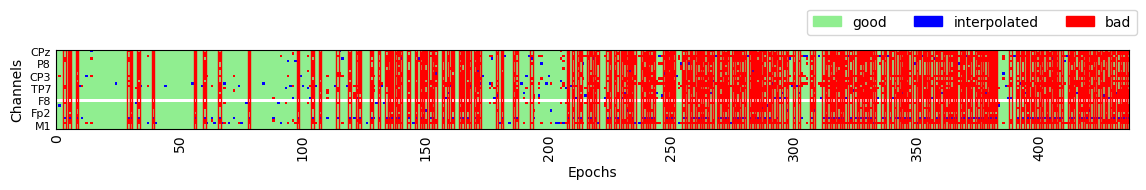

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 37 epochs: 0, 7, 18, 19, 20, 22, 23, 25, 26, 29, 31, 34, 35, 36, 38, 39, 40, 41, 42, 43, 44, 45, 47, 48, 53, 54, 55, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68


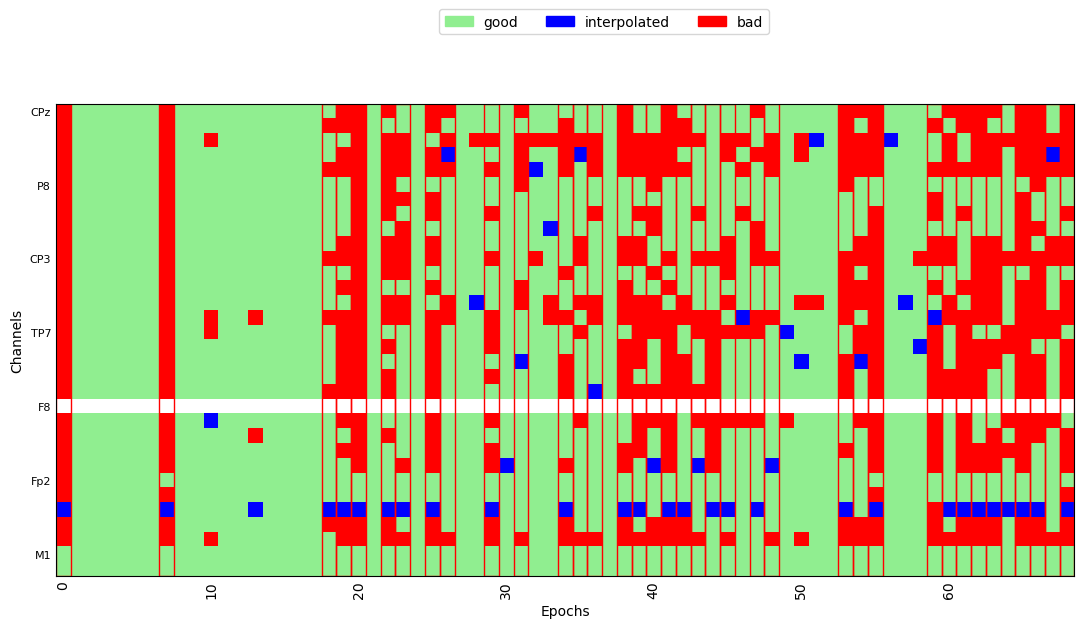

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

Dropped 66 epochs: 3, 6, 8, 16, 28, 36, 38, 39, 51, 55, 79, 88, 98, 108, 115, 118, 124, 138, 141, 142, 143, 146, 150, 153, 157, 165, 174, 178, 191, 202, 205, 219, 229, 232, 233, 235, 236, 240, 244, 265, 276, 277, 285, 299, 300, 306, 311, 312, 317, 325, 334, 367, 368, 371, 373, 374, 375, 376, 377, 378, 379, 380, 382, 387, 392, 410


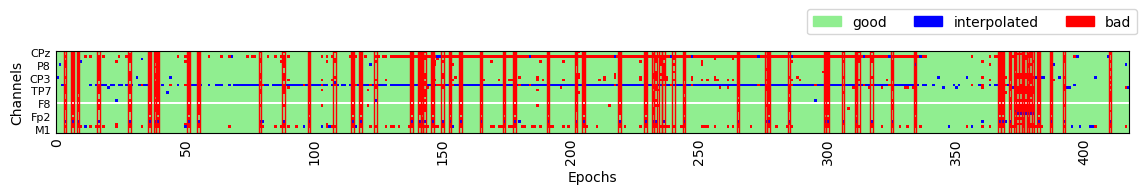

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 13 epochs: 4, 8, 10, 11, 19, 21, 22, 30, 41, 54, 61, 62, 69


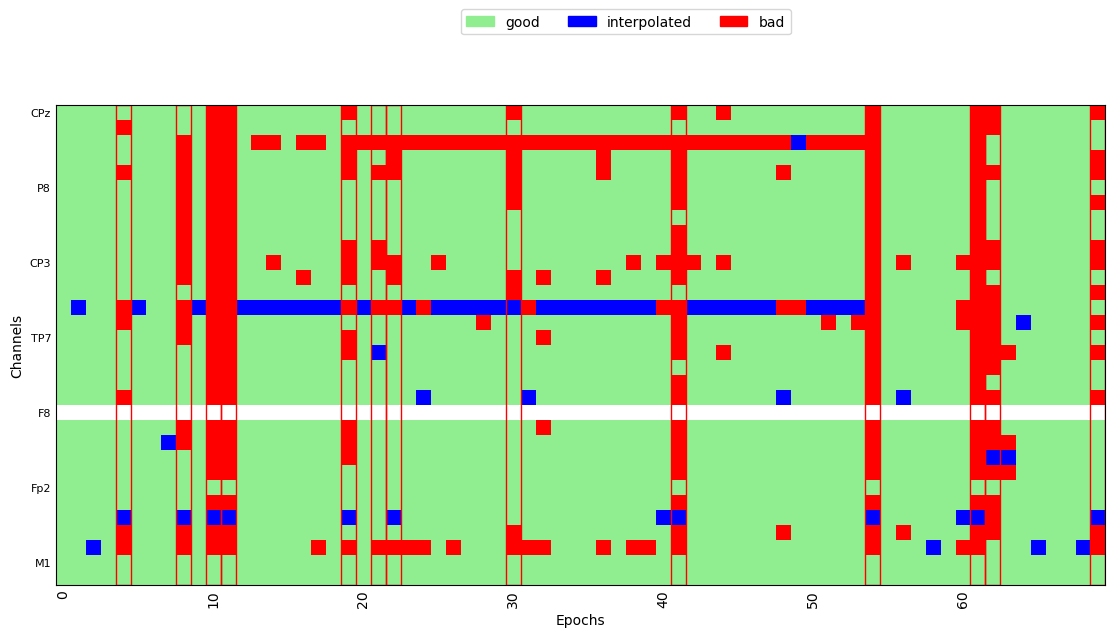

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/436 [00:00<?,       ?it/s]

Dropped 150 epochs: 3, 5, 12, 14, 20, 26, 31, 37, 39, 52, 54, 55, 56, 69, 71, 76, 81, 82, 84, 85, 93, 99, 103, 108, 109, 111, 112, 113, 122, 123, 124, 125, 127, 129, 130, 131, 133, 137, 138, 139, 140, 142, 144, 149, 151, 152, 159, 161, 168, 172, 173, 177, 179, 194, 195, 196, 202, 204, 206, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 224, 226, 227, 228, 230, 233, 234, 235, 237, 238, 239, 242, 243, 247, 253, 254, 255, 257, 258, 259, 267, 271, 275, 278, 280, 284, 287, 289, 294, 297, 298, 299, 307, 311, 313, 317, 328, 330, 331, 335, 336, 337, 339, 343, 347, 350, 352, 357, 360, 363, 365, 366, 368, 374, 376, 380, 381, 385, 387, 390, 396, 399, 402, 403, 405, 410, 415, 416, 421, 422, 423, 425, 427, 432, 433, 434


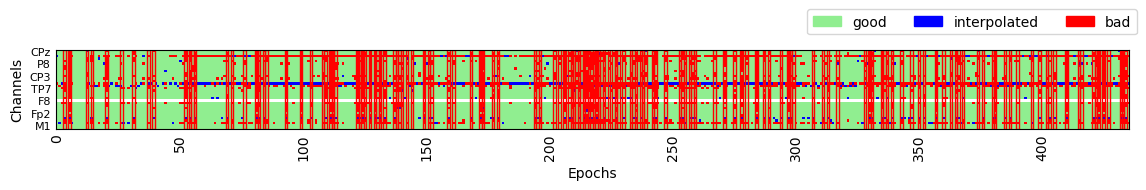

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 27 epochs: 2, 3, 8, 12, 15, 18, 19, 21, 24, 26, 27, 32, 34, 36, 37, 39, 41, 47, 48, 52, 53, 54, 57, 58, 60, 62, 64


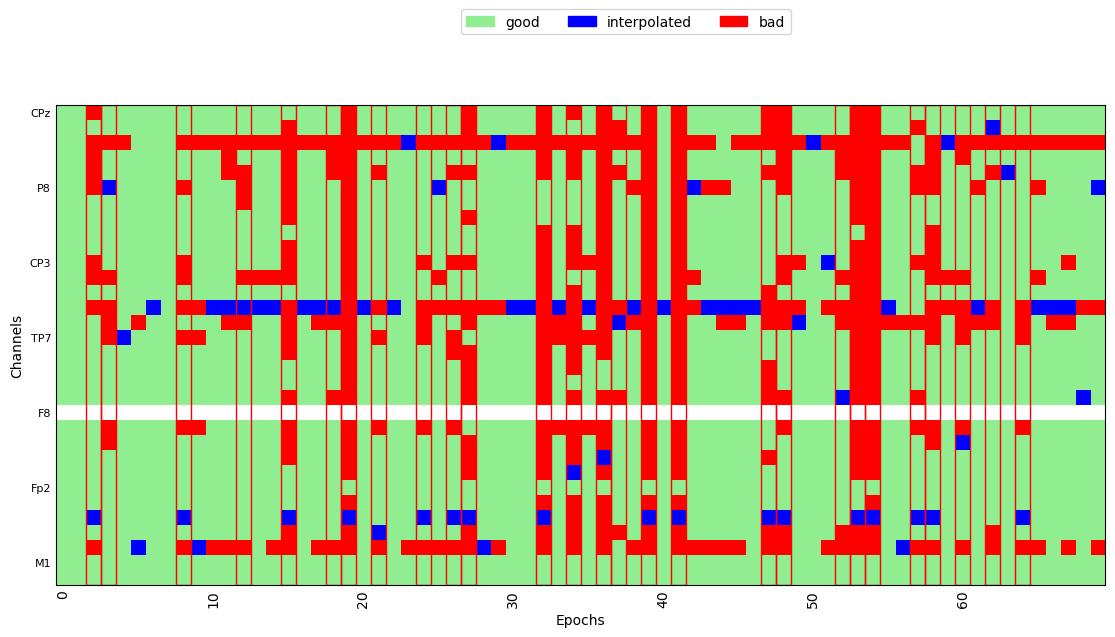

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0005_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1917 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0005_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

... (7 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/411 [00:00<?,       ?it/s]

Dropped 199 epochs: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 35, 37, 41, 42, 43, 44, 45, 47, 48, 50, 51, 53, 55, 56, 57, 59, 60, 63, 64, 66, 70, 72, 73, 74, 75, 78, 87, 89, 94, 95, 97, 100, 102, 104, 105, 107, 109, 110, 114, 119, 126, 128, 134, 136, 152, 153, 157, 158, 164, 166, 167, 168, 171, 175, 177, 179, 183, 191, 197, 198, 199, 200, 201, 203, 204, 205, 206, 207, 209, 210, 211, 212, 214, 218, 219, 220, 225, 227, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 264, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 287, 289, 290, 291, 292, 294, 296, 300, 301, 302, 303, 306, 308, 309, 311, 314, 315, 320, 321, 324, 340, 341, 342, 343, 344, 351, 357, 358, 363, 365, 369, 371, 372, 376, 377, 378, 382, 385, 386, 393, 394, 396, 406


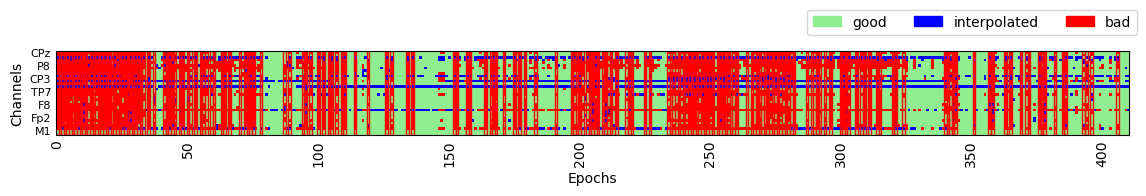

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 30 epochs: 0, 1, 2, 3, 4, 5, 7, 8, 11, 15, 16, 21, 25, 26, 27, 34, 35, 37, 38, 39, 41, 42, 43, 44, 47, 48, 49, 50, 57, 59


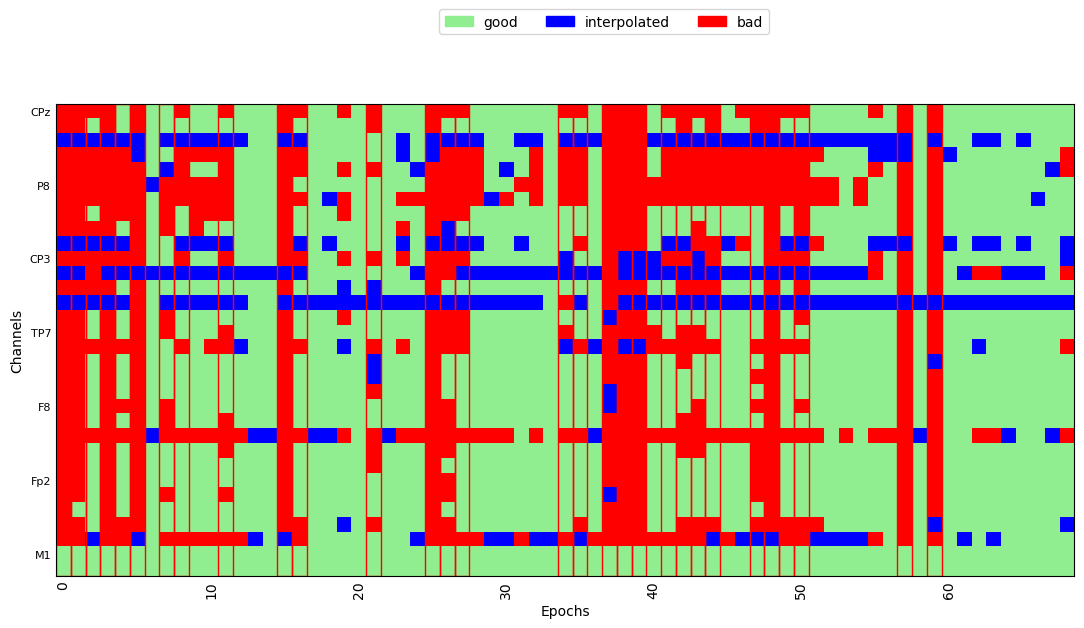

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

Dropped 177 epochs: 0, 1, 2, 3, 4, 7, 8, 10, 11, 12, 13, 14, 16, 17, 22, 24, 26, 34, 36, 39, 44, 48, 50, 53, 56, 58, 59, 61, 63, 66, 67, 69, 70, 71, 74, 76, 78, 80, 81, 84, 85, 87, 88, 89, 102, 109, 111, 114, 115, 122, 123, 124, 125, 129, 133, 139, 141, 142, 145, 147, 149, 151, 160, 161, 163, 166, 168, 169, 170, 174, 175, 176, 179, 181, 182, 185, 186, 188, 191, 194, 196, 198, 210, 217, 220, 223, 225, 227, 229, 230, 231, 232, 236, 240, 241, 242, 243, 245, 250, 251, 253, 254, 262, 263, 264, 266, 267, 269, 274, 275, 277, 279, 282, 284, 285, 289, 290, 295, 297, 299, 303, 305, 306, 307, 310, 312, 314, 315, 316, 317, 318, 320, 322, 323, 324, 326, 327, 329, 330, 332, 334, 335, 337, 338, 339, 343, 347, 348, 352, 353, 354, 355, 357, 358, 360, 362, 363, 367, 372, 373, 375, 376, 377, 379, 381, 382, 384, 388, 389, 392, 393, 395, 397, 401, 404, 405, 409


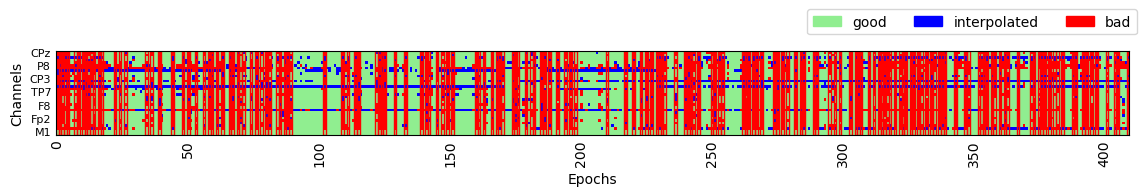

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 26 epochs: 0, 1, 2, 3, 9, 11, 14, 17, 21, 23, 26, 27, 29, 30, 31, 32, 34, 37, 40, 41, 43, 46, 49, 53, 56, 68


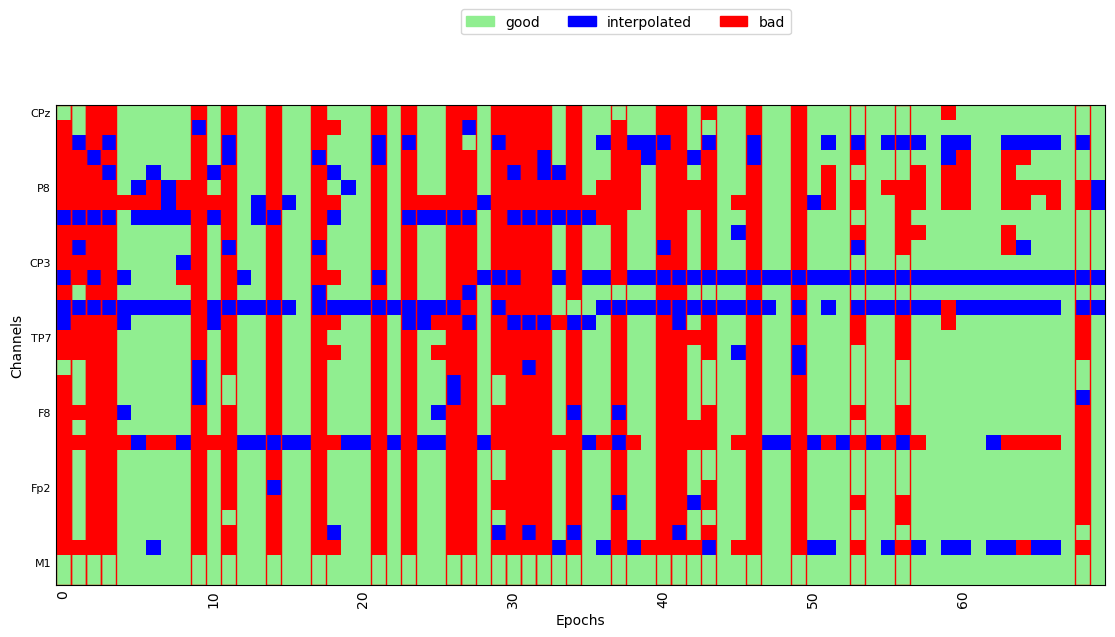

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/417 [00:00<?,       ?it/s]

Dropped 220 epochs: 1, 2, 4, 6, 7, 9, 13, 16, 17, 21, 22, 23, 24, 26, 28, 29, 30, 33, 37, 39, 40, 41, 43, 44, 54, 58, 60, 62, 69, 70, 78, 81, 86, 91, 97, 99, 101, 103, 104, 106, 110, 112, 114, 117, 118, 120, 121, 124, 125, 127, 129, 130, 134, 137, 139, 145, 147, 153, 156, 157, 158, 162, 166, 167, 168, 170, 172, 174, 176, 177, 178, 181, 184, 185, 186, 188, 189, 192, 195, 196, 197, 198, 199, 200, 201, 202, 203, 205, 206, 208, 210, 211, 214, 215, 216, 219, 224, 225, 227, 228, 230, 231, 233, 237, 239, 241, 242, 243, 245, 246, 247, 248, 249, 250, 251, 252, 255, 260, 261, 267, 270, 271, 273, 275, 277, 279, 280, 281, 283, 286, 287, 289, 291, 292, 293, 294, 295, 296, 298, 299, 300, 301, 303, 304, 305, 306, 307, 308, 309, 312, 313, 314, 315, 317, 319, 322, 325, 327, 329, 330, 331, 333, 335, 336, 337, 339, 340, 342, 343, 344, 345, 346, 348, 349, 351, 352, 354, 355, 356, 358, 360, 361, 362, 363, 366, 369, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 39

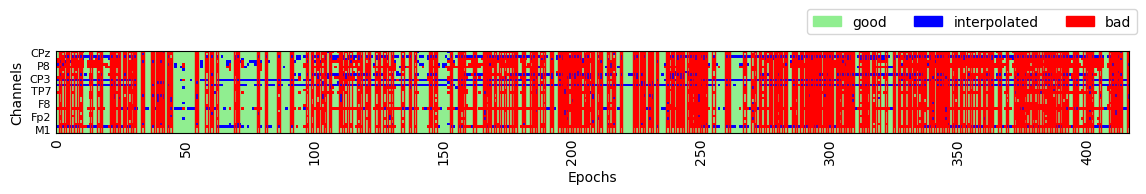

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

Dropped 39 epochs: 1, 5, 7, 10, 12, 14, 15, 16, 17, 25, 28, 30, 31, 32, 33, 37, 38, 40, 41, 43, 45, 46, 48, 49, 50, 52, 53, 54, 55, 56, 57, 58, 61, 62, 63, 64, 65, 66, 67


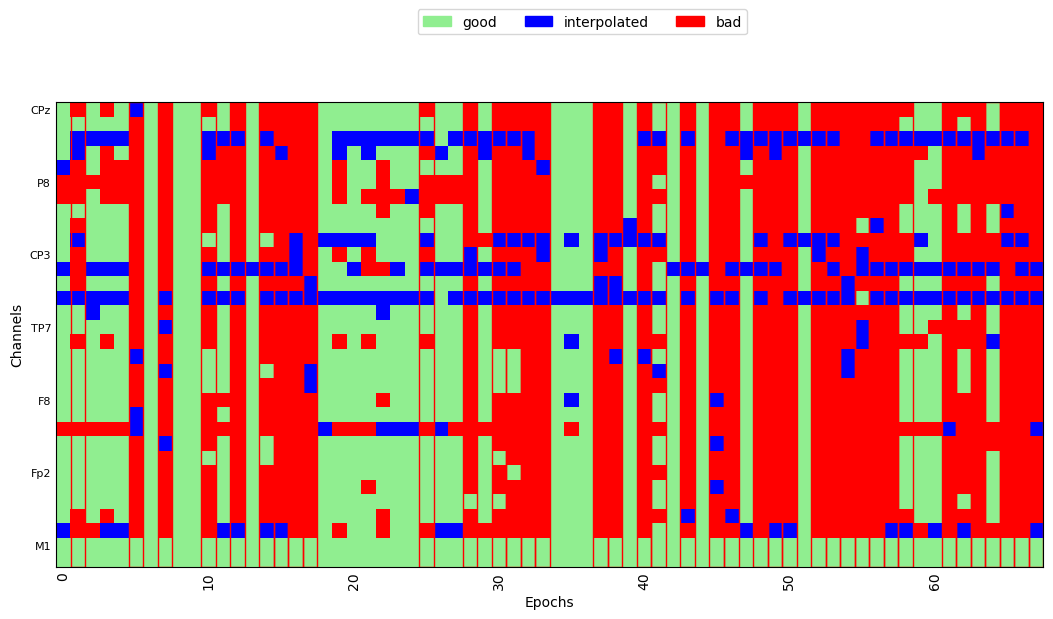

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/402 [00:00<?,       ?it/s]

Dropped 190 epochs: 0, 3, 5, 10, 12, 17, 19, 20, 22, 23, 24, 25, 32, 36, 39, 40, 42, 43, 44, 45, 47, 50, 51, 68, 71, 72, 74, 75, 78, 81, 83, 84, 85, 86, 87, 88, 90, 93, 96, 97, 101, 103, 104, 106, 109, 110, 112, 113, 115, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 143, 149, 150, 151, 157, 158, 160, 163, 166, 175, 179, 182, 185, 191, 196, 199, 200, 202, 203, 205, 209, 210, 211, 212, 215, 217, 218, 220, 221, 223, 224, 225, 229, 232, 239, 240, 246, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 262, 264, 266, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 283, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 300, 301, 305, 308, 309, 313, 324, 325, 326, 328, 330, 335, 336, 338, 339, 340, 341, 348, 353, 358, 359, 361, 364, 372, 373, 374, 375, 376, 377, 378, 380, 384, 393, 394, 395, 396, 398, 399, 400, 401


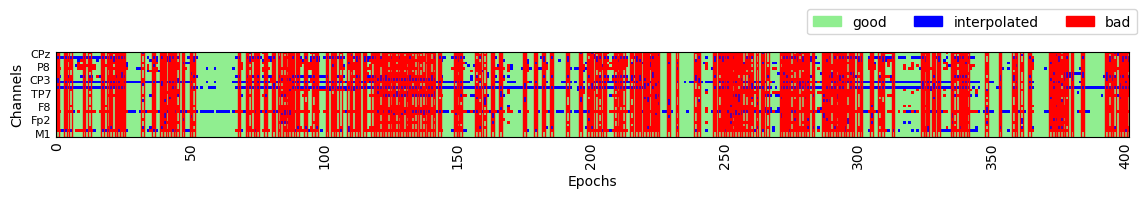

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 41 epochs: 2, 8, 11, 14, 15, 16, 18, 19, 21, 22, 23, 24, 25, 26, 28, 31, 35, 37, 42, 44, 45, 46, 47, 48, 49, 50, 51, 52, 54, 55, 56, 57, 58, 59, 60, 61, 62, 64, 65, 66, 69


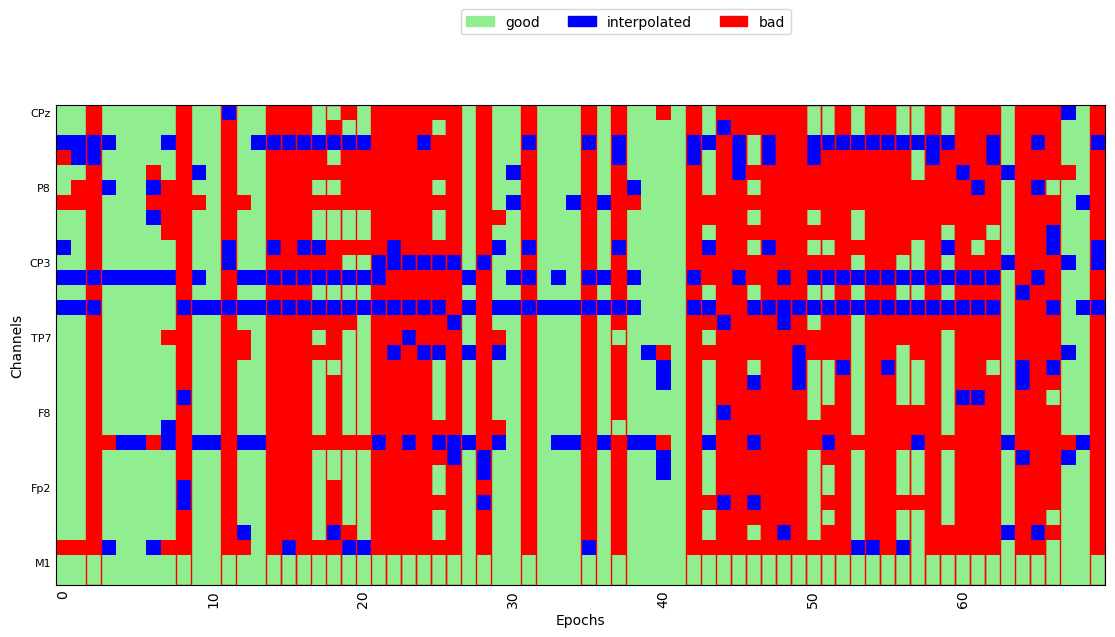

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0023_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1959 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0023_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

... (7 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=1


  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

Dropped 107 epochs: 1, 7, 10, 13, 21, 25, 37, 39, 40, 43, 52, 54, 56, 67, 72, 73, 75, 80, 84, 85, 99, 104, 112, 116, 122, 132, 135, 141, 142, 145, 153, 162, 164, 166, 169, 178, 183, 187, 189, 191, 192, 193, 194, 196, 199, 201, 217, 223, 225, 237, 240, 241, 244, 246, 248, 251, 253, 254, 255, 256, 259, 263, 267, 280, 283, 285, 286, 288, 289, 291, 295, 297, 300, 302, 303, 309, 310, 311, 313, 316, 319, 320, 321, 327, 328, 329, 333, 334, 335, 340, 344, 345, 346, 349, 351, 355, 360, 369, 381, 385, 392, 394, 399, 400, 406, 407, 417


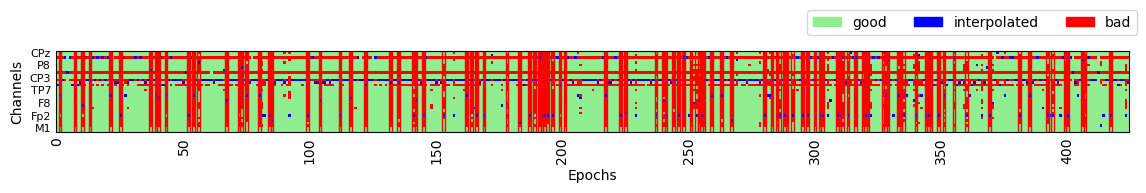

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 21 epochs: 0, 2, 5, 12, 14, 16, 18, 20, 39, 42, 44, 45, 46, 49, 52, 53, 55, 62, 65, 66, 69


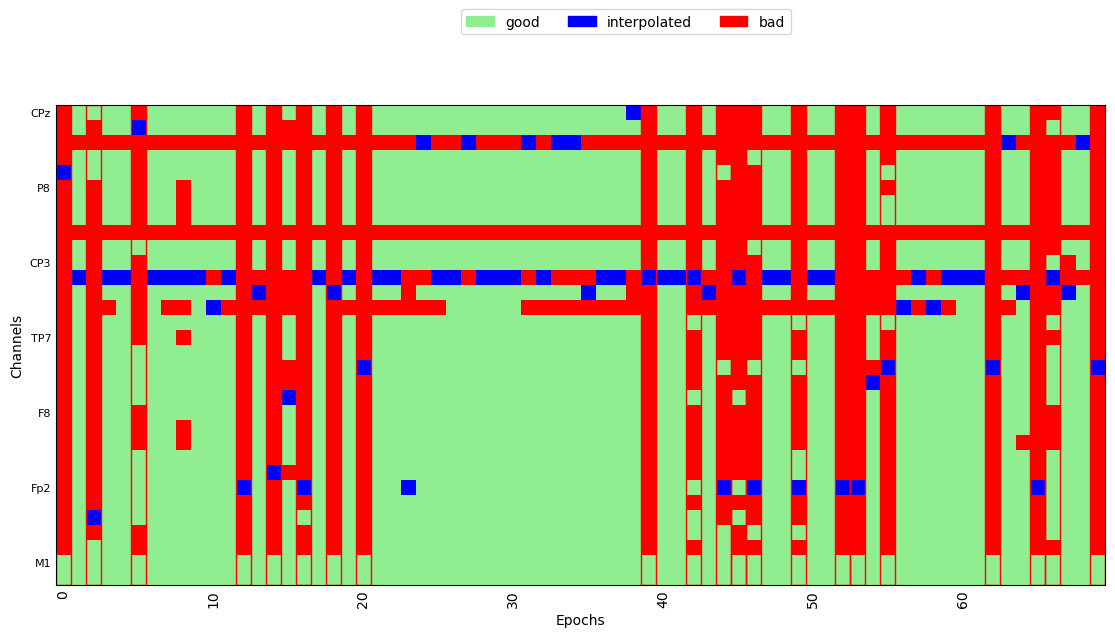

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/397 [00:00<?,       ?it/s]

Dropped 157 epochs: 1, 11, 16, 20, 22, 24, 25, 28, 30, 32, 35, 38, 39, 40, 44, 47, 49, 53, 55, 60, 62, 66, 70, 73, 76, 77, 84, 86, 91, 92, 96, 97, 100, 102, 104, 105, 106, 107, 108, 110, 112, 113, 117, 118, 119, 120, 121, 128, 129, 132, 134, 136, 138, 140, 142, 143, 144, 145, 146, 147, 148, 150, 155, 162, 166, 169, 178, 180, 181, 190, 191, 192, 194, 198, 202, 203, 204, 210, 211, 213, 214, 215, 216, 219, 224, 226, 228, 231, 232, 234, 237, 239, 241, 244, 246, 248, 251, 253, 255, 261, 262, 268, 269, 272, 273, 279, 280, 281, 284, 285, 289, 292, 294, 296, 298, 301, 303, 304, 305, 306, 310, 311, 318, 320, 321, 324, 327, 328, 329, 331, 332, 333, 334, 335, 337, 339, 341, 342, 345, 347, 348, 358, 359, 361, 365, 367, 369, 372, 378, 380, 381, 382, 383, 384, 385, 387, 391


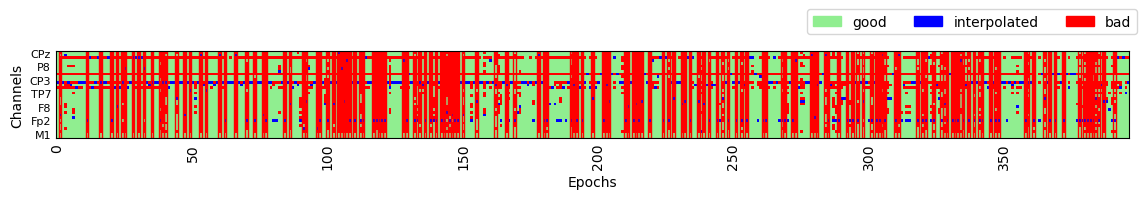

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 31 epochs: 0, 1, 3, 5, 6, 12, 16, 21, 24, 25, 26, 29, 30, 31, 36, 38, 40, 41, 46, 47, 48, 50, 51, 54, 55, 58, 59, 60, 61, 63, 68


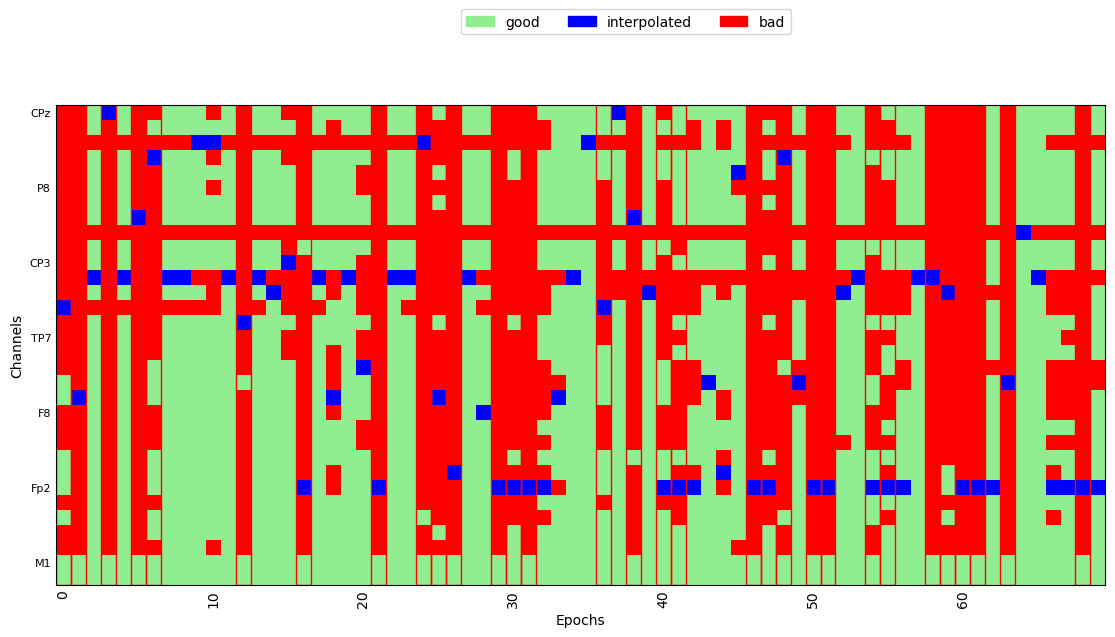

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/410 [00:00<?,       ?it/s]

Dropped 118 epochs: 2, 4, 10, 16, 17, 23, 26, 28, 29, 31, 39, 53, 57, 65, 69, 71, 74, 78, 82, 87, 90, 96, 102, 105, 108, 109, 119, 123, 145, 154, 159, 161, 166, 167, 168, 174, 177, 184, 189, 190, 194, 202, 205, 207, 211, 215, 216, 217, 222, 234, 237, 238, 239, 245, 247, 249, 250, 253, 255, 256, 260, 265, 267, 268, 273, 274, 275, 278, 279, 282, 287, 291, 292, 297, 299, 301, 303, 304, 307, 308, 316, 319, 321, 322, 323, 326, 329, 330, 332, 333, 334, 335, 338, 342, 343, 345, 347, 349, 358, 360, 362, 366, 367, 368, 369, 370, 371, 375, 377, 379, 381, 382, 388, 389, 393, 398, 406, 408


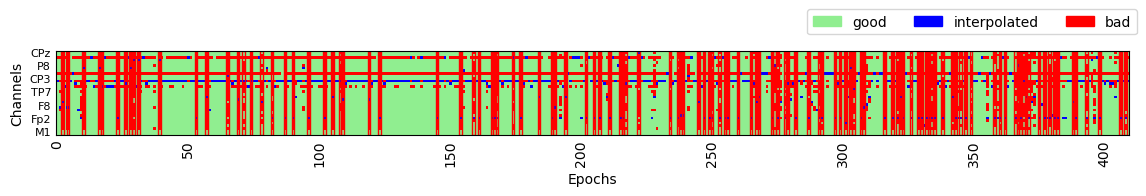

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 18 epochs: 3, 7, 10, 18, 32, 38, 41, 46, 47, 49, 52, 53, 57, 58, 59, 63, 67, 68


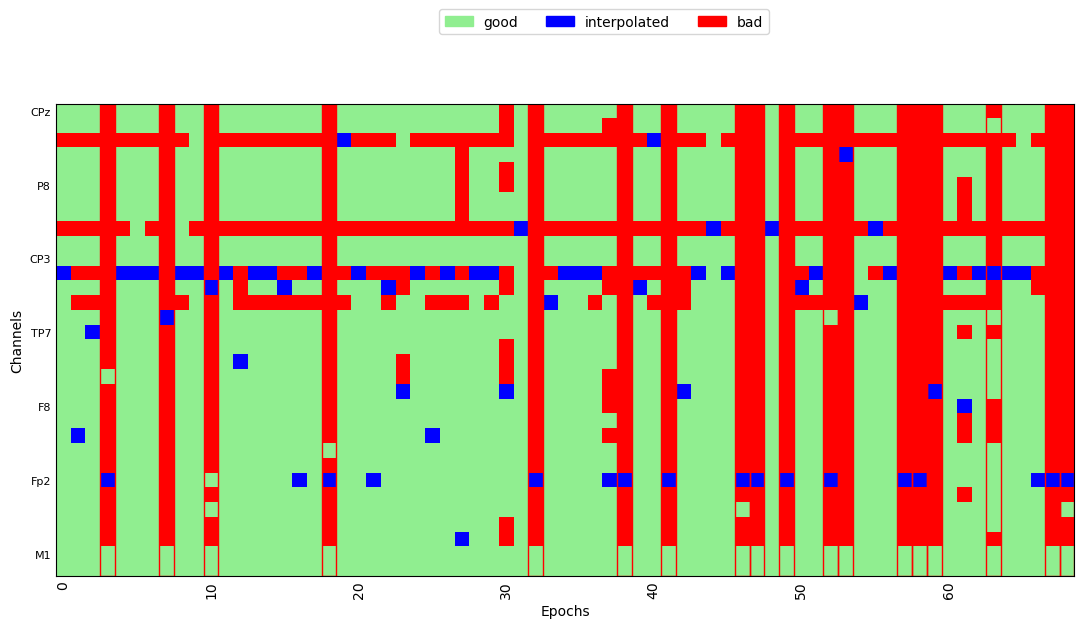

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/448 [00:00<?,       ?it/s]

Dropped 97 epochs: 25, 35, 44, 51, 67, 70, 91, 93, 98, 100, 101, 109, 116, 121, 131, 136, 139, 142, 158, 159, 161, 169, 173, 175, 177, 178, 181, 191, 207, 211, 218, 219, 228, 230, 233, 235, 237, 240, 242, 248, 250, 254, 256, 260, 262, 268, 272, 278, 279, 296, 306, 307, 315, 322, 329, 331, 336, 339, 340, 342, 346, 347, 353, 356, 359, 360, 362, 364, 365, 368, 370, 373, 376, 381, 385, 391, 394, 395, 397, 399, 400, 403, 406, 409, 410, 412, 416, 424, 425, 426, 427, 433, 436, 438, 442, 443, 447


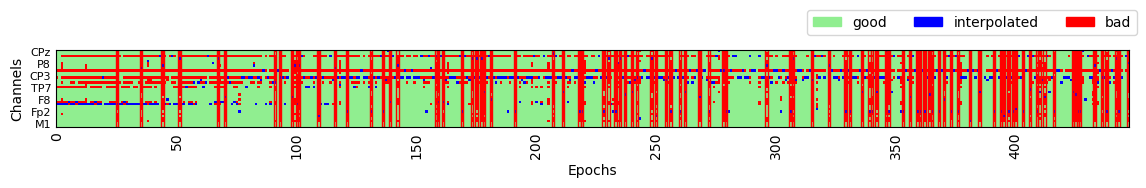

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 18 epochs: 11, 18, 21, 23, 25, 28, 31, 35, 45, 46, 47, 49, 51, 52, 53, 54, 59, 62


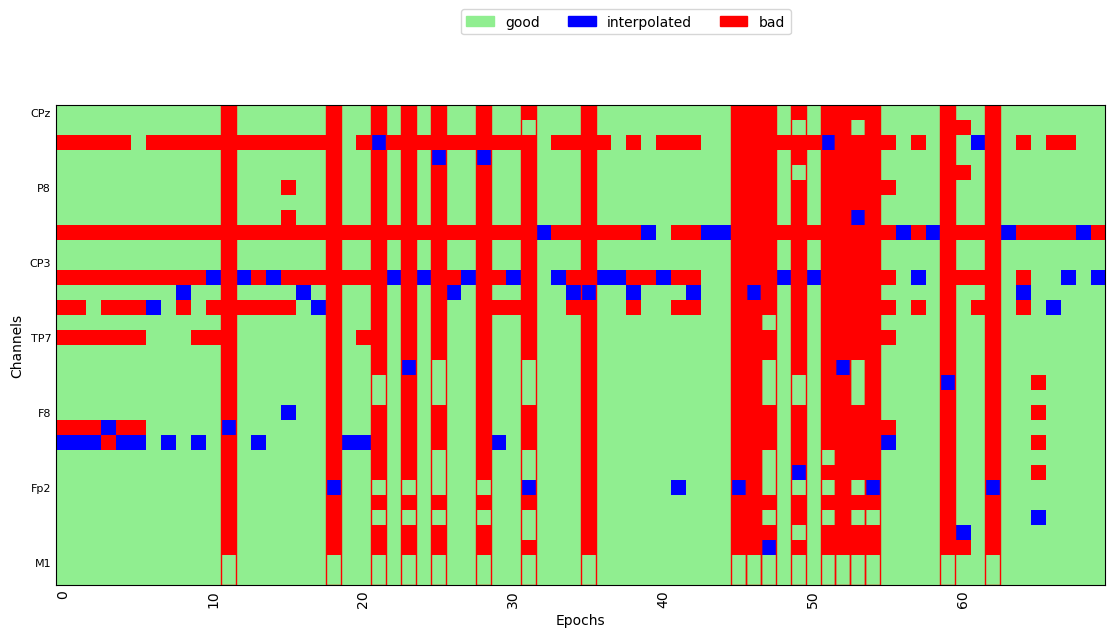

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0001_VOT_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1959 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0001_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

... (7 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=1


  0%|          | Repairing epochs : 0/405 [00:00<?,       ?it/s]

Dropped 107 epochs: 2, 5, 6, 16, 20, 23, 30, 32, 33, 35, 42, 44, 45, 52, 58, 59, 61, 64, 67, 72, 76, 80, 83, 84, 102, 104, 107, 108, 114, 117, 132, 134, 135, 136, 137, 144, 147, 152, 156, 160, 161, 175, 182, 183, 184, 186, 190, 191, 193, 200, 204, 205, 208, 212, 213, 216, 217, 218, 219, 223, 224, 227, 229, 230, 236, 237, 238, 239, 244, 245, 246, 261, 267, 272, 277, 280, 286, 287, 288, 290, 295, 298, 299, 304, 312, 318, 327, 332, 333, 335, 341, 344, 353, 357, 363, 364, 366, 369, 370, 372, 377, 381, 389, 392, 397, 399, 400


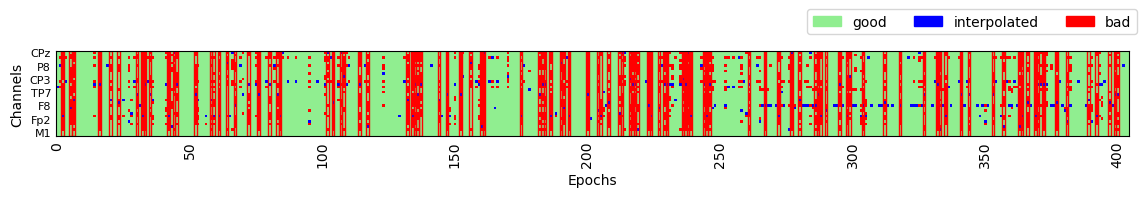

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 18 epochs: 6, 7, 11, 19, 21, 24, 32, 35, 38, 40, 41, 42, 45, 52, 57, 59, 64, 69


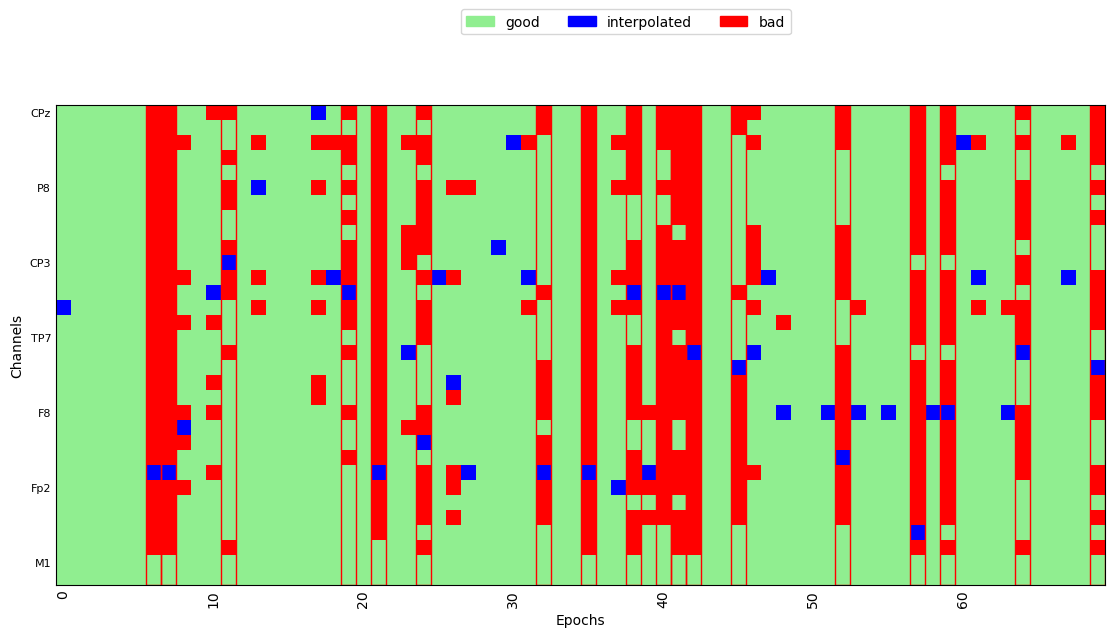

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/449 [00:00<?,       ?it/s]

Dropped 111 epochs: 0, 1, 4, 5, 6, 7, 8, 10, 11, 15, 19, 20, 24, 29, 34, 40, 41, 42, 47, 56, 64, 66, 68, 71, 73, 74, 78, 79, 80, 81, 82, 84, 89, 92, 97, 101, 104, 105, 106, 114, 128, 137, 141, 147, 151, 156, 159, 160, 167, 174, 177, 185, 186, 196, 205, 206, 207, 210, 213, 217, 218, 223, 225, 230, 232, 236, 237, 240, 242, 258, 260, 268, 271, 275, 283, 286, 287, 292, 295, 296, 297, 304, 313, 320, 327, 330, 344, 345, 348, 350, 351, 352, 354, 366, 367, 368, 373, 377, 378, 379, 382, 386, 390, 404, 408, 412, 416, 425, 429, 438, 445


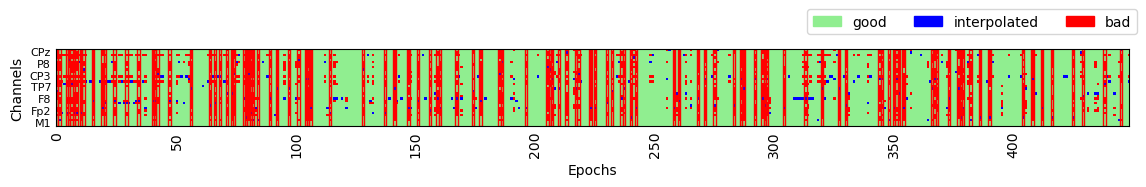

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/71 [00:00<?,       ?it/s]

Dropped 24 epochs: 0, 2, 4, 5, 9, 10, 13, 14, 18, 19, 24, 26, 28, 32, 35, 36, 40, 42, 44, 45, 50, 54, 55, 56


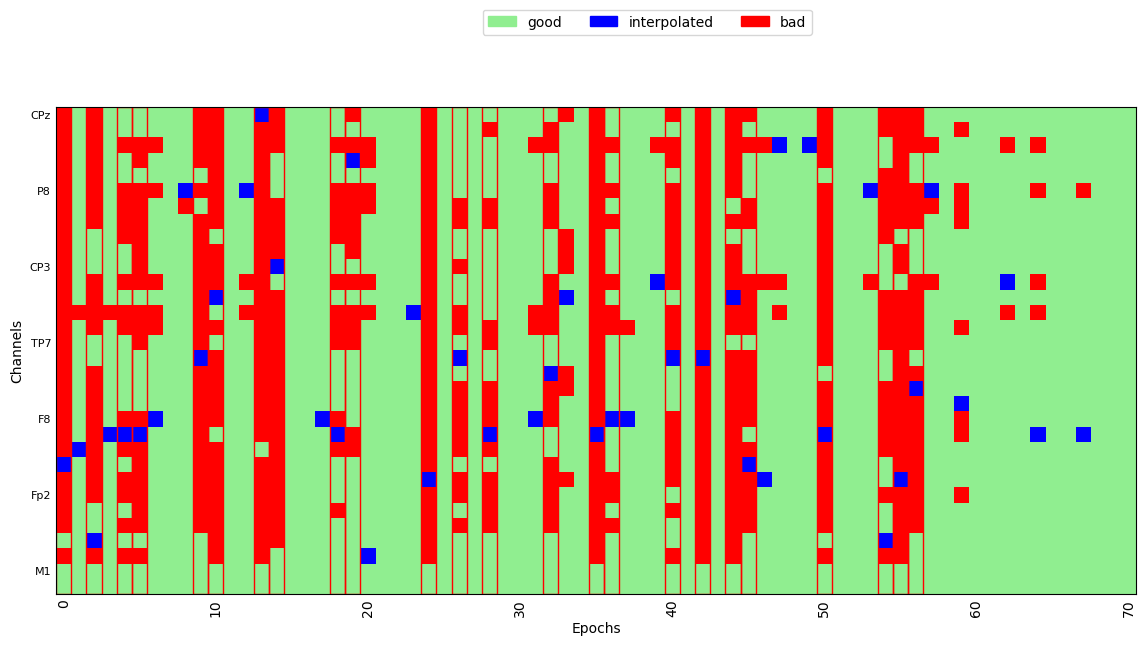

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/424 [00:00<?,       ?it/s]

Dropped 176 epochs: 0, 4, 14, 15, 21, 24, 25, 27, 28, 29, 32, 33, 34, 36, 37, 38, 39, 40, 41, 42, 43, 46, 54, 58, 63, 64, 67, 68, 69, 70, 71, 73, 75, 84, 88, 89, 92, 99, 103, 105, 106, 107, 112, 116, 118, 119, 122, 123, 125, 126, 127, 131, 139, 143, 144, 145, 148, 149, 152, 153, 155, 157, 158, 159, 160, 161, 162, 165, 166, 167, 168, 169, 170, 171, 174, 176, 178, 180, 181, 182, 184, 185, 186, 187, 189, 190, 191, 192, 193, 194, 195, 196, 197, 199, 200, 201, 203, 206, 211, 212, 217, 218, 220, 223, 224, 226, 229, 230, 231, 234, 235, 237, 239, 243, 245, 248, 249, 254, 255, 256, 257, 258, 261, 262, 268, 274, 278, 282, 284, 286, 291, 292, 294, 300, 302, 304, 305, 309, 316, 319, 320, 321, 324, 327, 328, 330, 339, 342, 343, 346, 349, 353, 356, 358, 366, 367, 368, 369, 377, 378, 380, 381, 392, 394, 397, 398, 399, 406, 407, 408, 409, 412, 414, 415, 416, 418


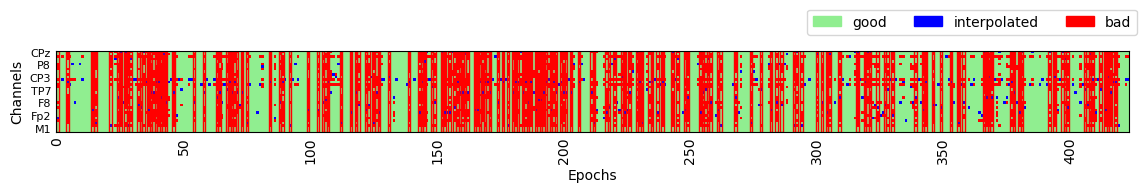

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 35 epochs: 1, 2, 3, 7, 8, 16, 18, 20, 21, 23, 25, 26, 27, 28, 29, 30, 31, 32, 35, 37, 38, 43, 44, 46, 47, 49, 50, 51, 52, 54, 60, 62, 65, 67, 69


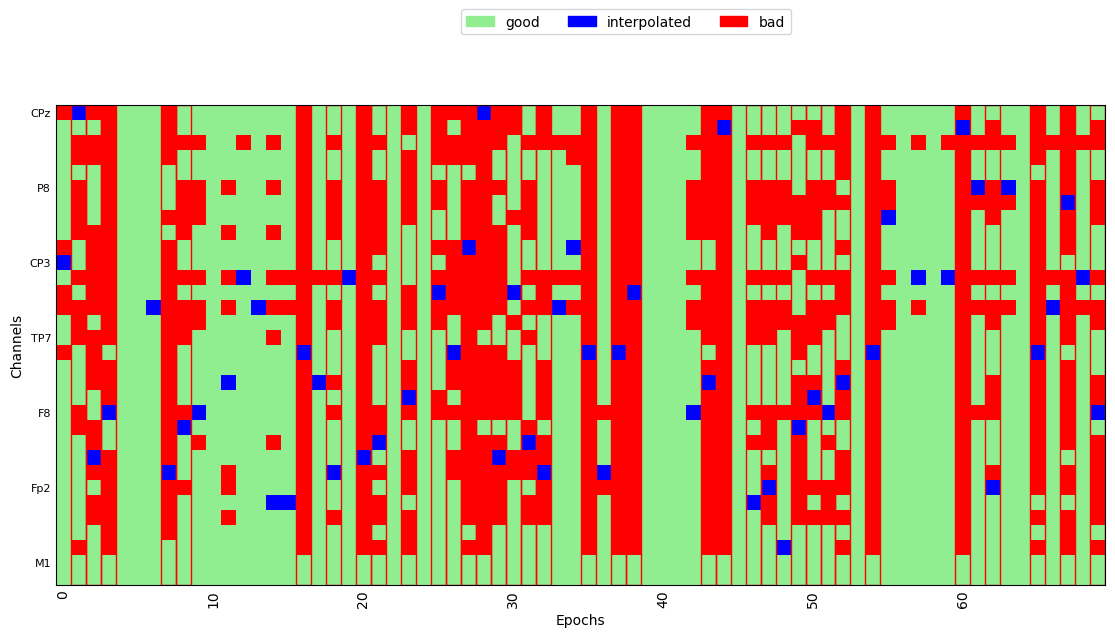

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/400 [00:00<?,       ?it/s]

Dropped 139 epochs: 2, 4, 5, 7, 9, 15, 26, 31, 33, 34, 50, 51, 59, 63, 64, 65, 67, 68, 69, 70, 82, 86, 91, 95, 96, 98, 99, 101, 102, 104, 106, 107, 110, 115, 116, 126, 129, 130, 131, 134, 135, 136, 137, 138, 139, 140, 141, 148, 150, 154, 157, 158, 161, 162, 163, 166, 168, 170, 172, 173, 175, 177, 184, 186, 188, 193, 196, 200, 201, 205, 206, 209, 210, 214, 215, 216, 217, 219, 221, 223, 224, 227, 228, 229, 230, 233, 234, 235, 239, 240, 242, 249, 267, 268, 269, 271, 273, 277, 281, 283, 284, 285, 286, 289, 291, 292, 293, 297, 302, 303, 304, 313, 314, 315, 326, 327, 335, 337, 343, 346, 348, 352, 355, 356, 360, 361, 364, 367, 370, 371, 374, 379, 382, 386, 389, 392, 394, 395, 397


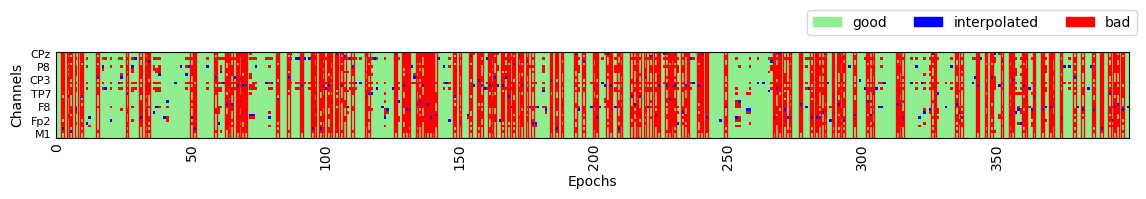

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 22 epochs: 0, 2, 4, 7, 9, 21, 23, 27, 31, 33, 34, 39, 45, 46, 47, 58, 61, 62, 63, 64, 66, 69


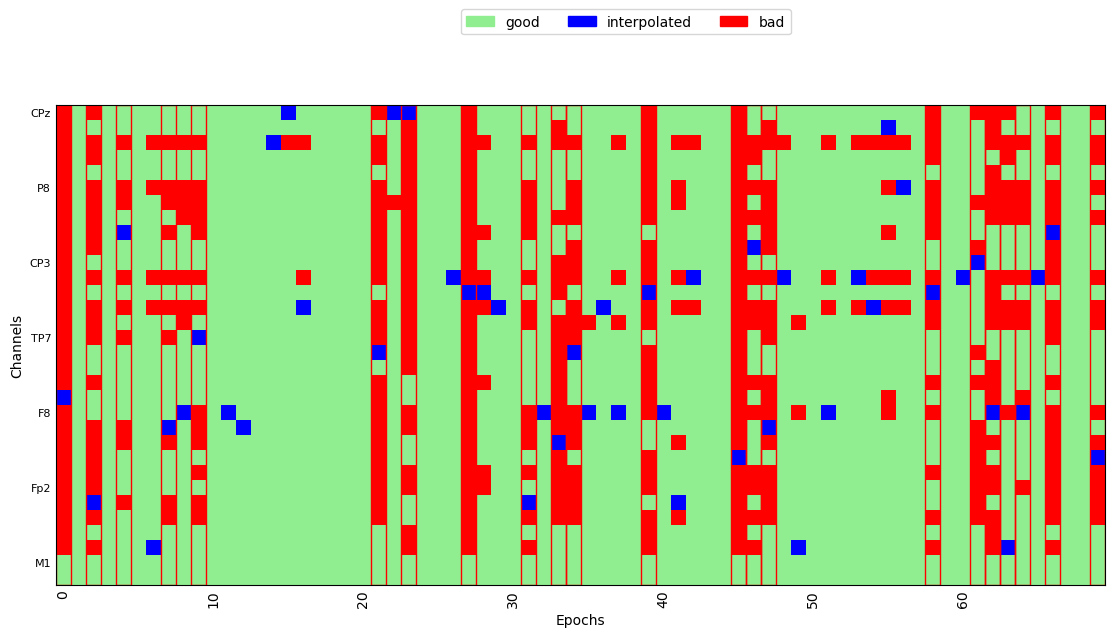

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0018_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1943 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0018_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])
/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["b

  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

... (8 outputs left out)





Estimated consensus=0.50 and n_interpolate=1


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/412 [00:00<?,       ?it/s]

Dropped 89 epochs: 2, 3, 22, 25, 31, 38, 41, 45, 49, 51, 54, 56, 58, 60, 65, 68, 70, 72, 77, 79, 86, 94, 96, 106, 108, 110, 113, 114, 115, 117, 126, 137, 139, 141, 143, 144, 149, 150, 155, 157, 159, 162, 165, 170, 182, 191, 192, 194, 195, 197, 202, 208, 212, 217, 230, 235, 236, 258, 260, 269, 276, 282, 285, 288, 291, 295, 298, 300, 302, 305, 315, 318, 321, 330, 331, 335, 340, 344, 347, 349, 353, 359, 381, 383, 386, 395, 401, 409, 411


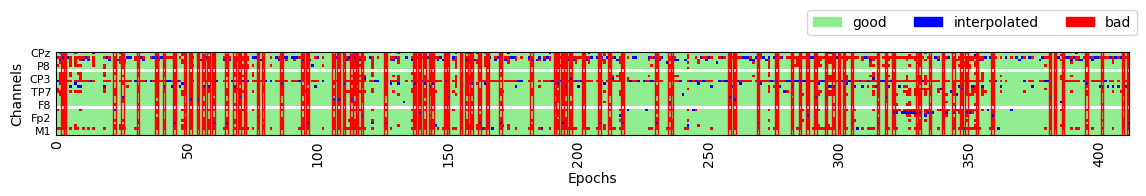

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 14 epochs: 0, 5, 6, 8, 12, 15, 16, 30, 32, 34, 35, 44, 48, 65


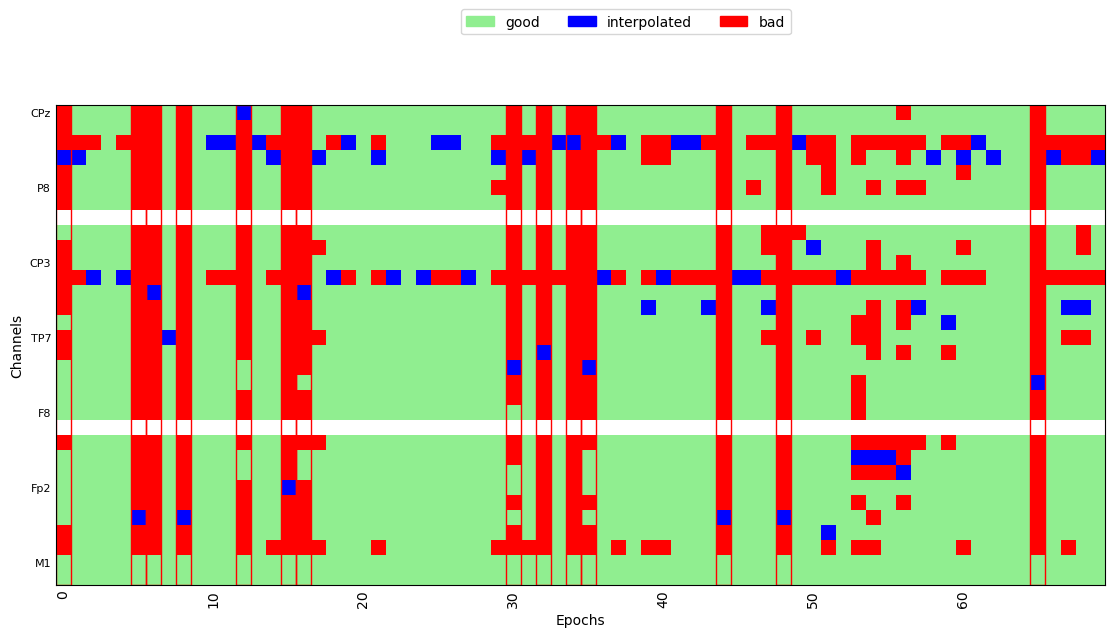

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/418 [00:00<?,       ?it/s]

Dropped 45 epochs: 0, 36, 58, 75, 76, 136, 155, 160, 163, 170, 177, 178, 182, 184, 191, 220, 221, 248, 280, 294, 308, 313, 316, 333, 336, 337, 342, 344, 366, 376, 377, 379, 384, 386, 391, 393, 397, 400, 405, 407, 410, 413, 414, 416, 417


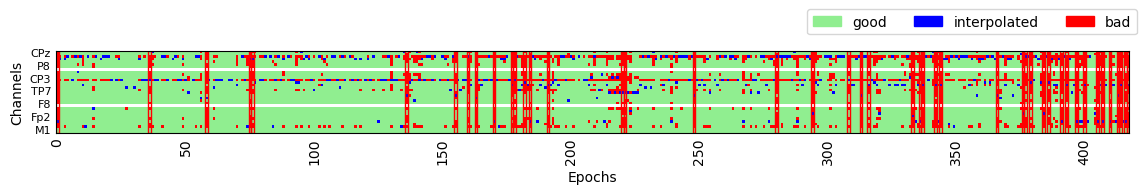

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 10 epochs: 5, 7, 26, 31, 40, 46, 48, 56, 58, 66


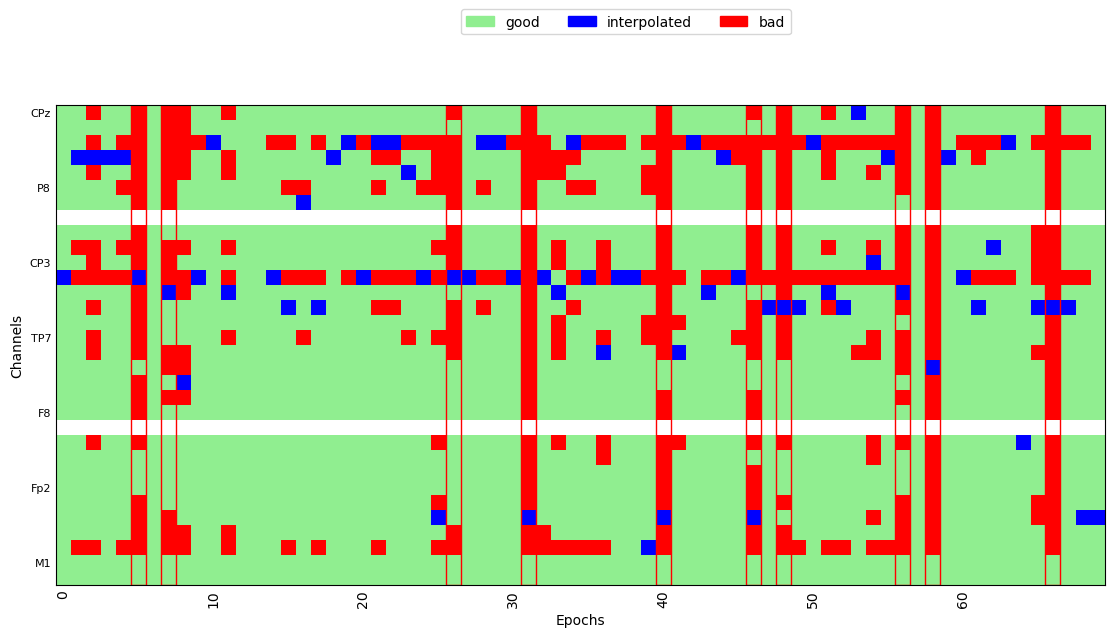

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/395 [00:00<?,       ?it/s]

Dropped 92 epochs: 0, 34, 38, 40, 42, 45, 52, 53, 55, 61, 66, 82, 100, 106, 107, 112, 115, 116, 125, 143, 146, 154, 172, 173, 174, 179, 181, 183, 186, 187, 188, 190, 194, 195, 197, 202, 203, 204, 207, 208, 209, 211, 214, 215, 219, 221, 229, 230, 231, 233, 235, 236, 237, 239, 240, 245, 246, 248, 249, 252, 259, 261, 262, 269, 272, 278, 279, 282, 296, 300, 302, 307, 308, 311, 312, 313, 318, 323, 324, 325, 326, 329, 331, 332, 335, 346, 364, 366, 380, 387, 388, 391


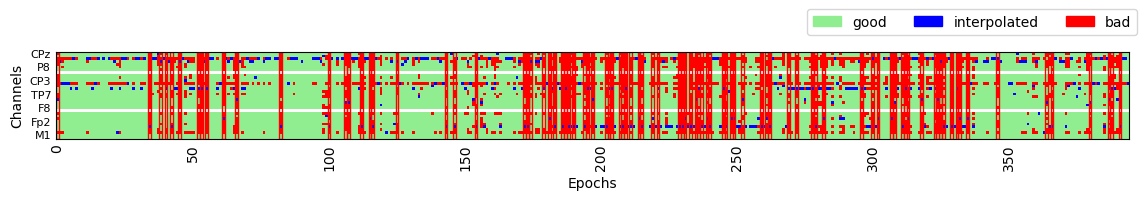

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 20 epochs: 6, 11, 14, 16, 27, 28, 29, 31, 32, 35, 36, 38, 42, 43, 50, 51, 52, 56, 58, 69


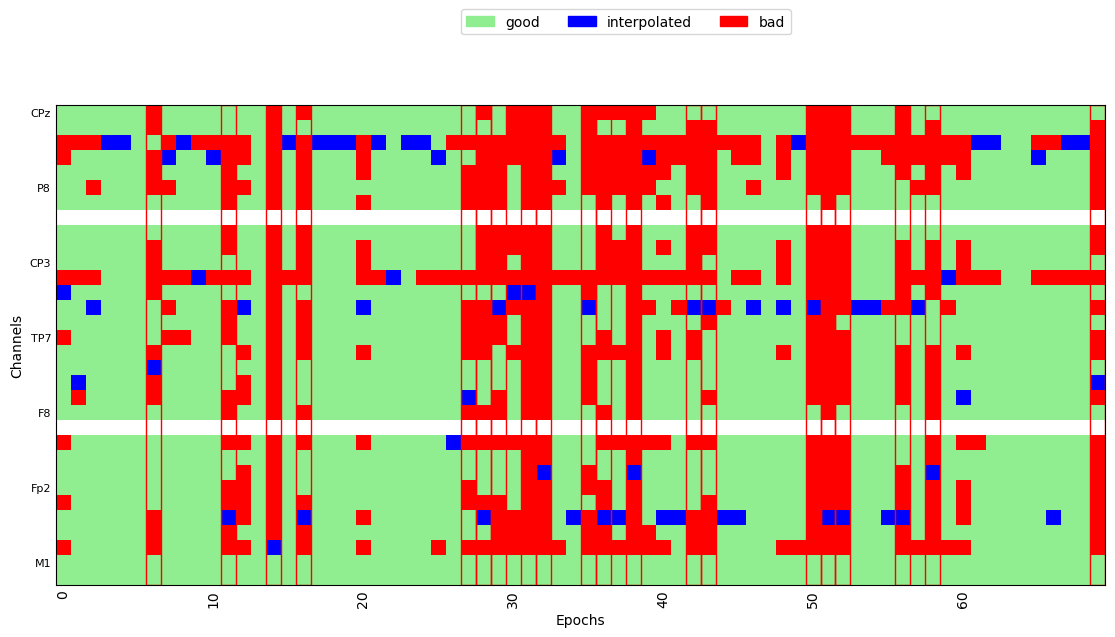

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/438 [00:00<?,       ?it/s]

Dropped 93 epochs: 0, 25, 40, 47, 48, 58, 62, 63, 66, 87, 91, 92, 96, 108, 109, 113, 114, 118, 119, 120, 121, 123, 124, 130, 131, 134, 141, 143, 146, 149, 151, 154, 156, 162, 163, 166, 167, 171, 172, 176, 182, 184, 185, 188, 194, 197, 201, 207, 212, 215, 220, 225, 231, 236, 244, 248, 251, 253, 258, 264, 269, 270, 273, 276, 281, 287, 289, 297, 310, 319, 320, 322, 326, 332, 340, 348, 351, 353, 368, 371, 378, 384, 387, 389, 390, 392, 399, 400, 402, 408, 417, 419, 435


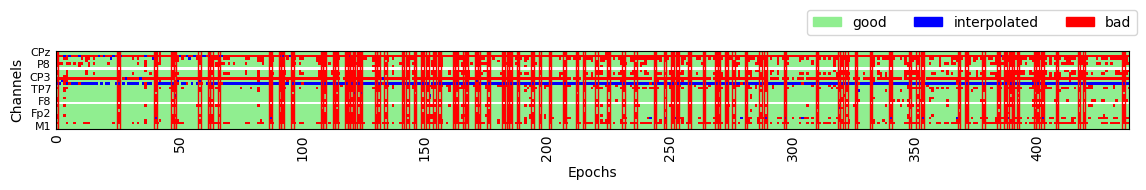

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 16 epochs: 11, 13, 16, 22, 24, 27, 30, 35, 38, 47, 50, 51, 57, 61, 62, 65


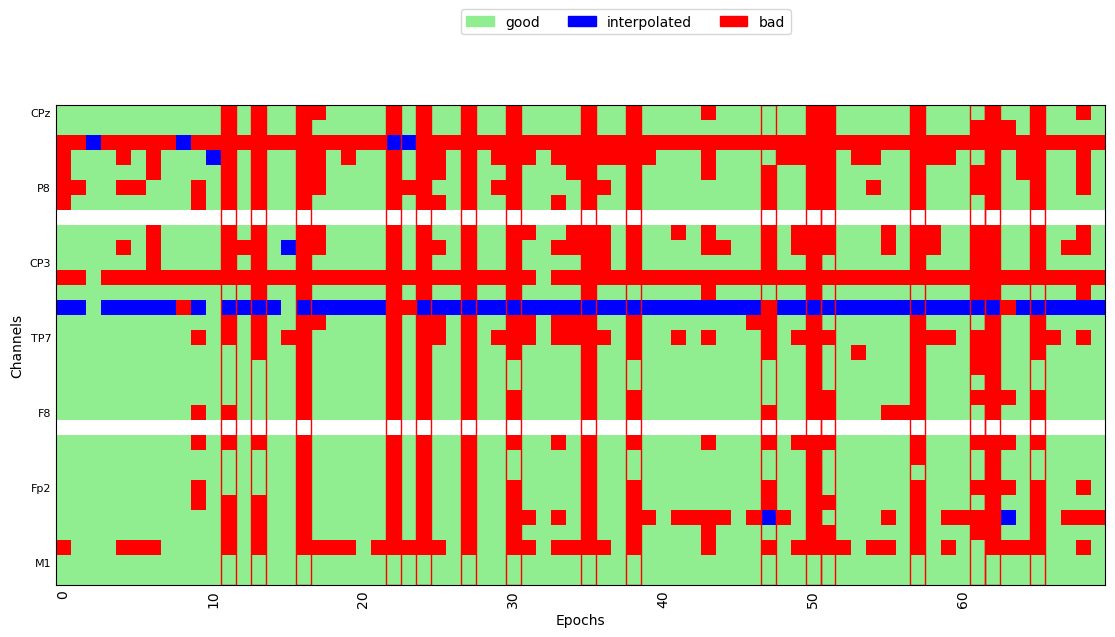

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0017_VOT_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
2027 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0017_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous

Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/2027 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=1


  0%|          | Repairing epochs : 0/416 [00:00<?,       ?it/s]

Dropped 154 epochs: 0, 1, 2, 3, 4, 6, 7, 9, 10, 14, 15, 17, 18, 19, 21, 30, 38, 39, 43, 44, 45, 47, 60, 64, 66, 68, 69, 70, 71, 72, 78, 80, 90, 91, 93, 94, 95, 98, 102, 115, 119, 120, 122, 124, 131, 136, 139, 144, 145, 147, 149, 151, 159, 160, 164, 165, 168, 174, 175, 176, 177, 179, 181, 186, 187, 188, 194, 195, 197, 201, 208, 214, 217, 218, 221, 225, 234, 238, 241, 242, 243, 244, 245, 246, 247, 251, 253, 269, 278, 279, 287, 298, 299, 300, 305, 309, 311, 312, 314, 319, 320, 323, 324, 327, 329, 331, 334, 336, 341, 342, 346, 350, 351, 353, 354, 355, 357, 359, 360, 361, 362, 363, 367, 368, 370, 372, 374, 376, 377, 378, 379, 380, 381, 382, 383, 384, 386, 387, 388, 389, 390, 395, 400, 401, 403, 404, 406, 408, 409, 410, 411, 412, 413, 415


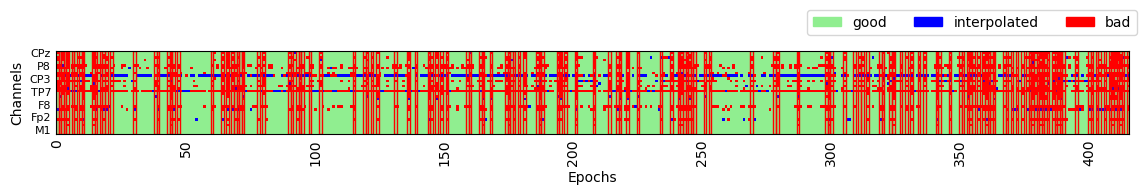

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 31 epochs: 1, 2, 3, 11, 12, 16, 17, 21, 24, 27, 28, 29, 32, 34, 37, 38, 39, 40, 41, 52, 53, 56, 58, 60, 63, 64, 65, 66, 67, 68, 69


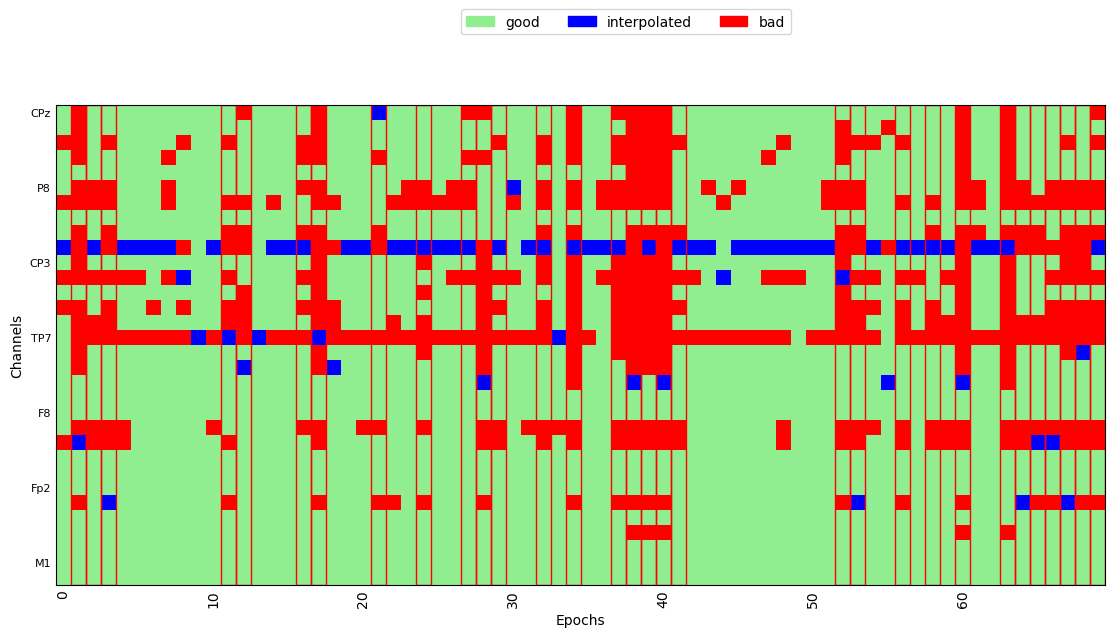

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/425 [00:00<?,       ?it/s]

Dropped 242 epochs: 6, 11, 19, 21, 24, 25, 26, 27, 28, 29, 30, 31, 32, 36, 38, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 59, 62, 65, 67, 68, 70, 72, 73, 74, 75, 79, 80, 81, 82, 83, 84, 85, 86, 89, 93, 94, 95, 96, 97, 99, 100, 101, 102, 104, 105, 106, 107, 108, 110, 111, 113, 114, 119, 120, 121, 124, 127, 128, 129, 131, 132, 133, 134, 136, 137, 138, 143, 144, 145, 147, 148, 150, 151, 157, 158, 159, 163, 164, 165, 166, 170, 171, 173, 174, 175, 176, 177, 178, 179, 181, 182, 184, 186, 187, 188, 189, 194, 198, 199, 200, 204, 205, 206, 207, 208, 209, 212, 216, 217, 218, 219, 221, 222, 223, 224, 225, 226, 228, 229, 230, 231, 232, 233, 234, 236, 238, 239, 240, 243, 244, 247, 248, 249, 250, 251, 252, 253, 254, 255, 257, 258, 259, 260, 261, 264, 265, 266, 271, 275, 276, 280, 281, 285, 288, 290, 291, 293, 295, 296, 298, 299, 300, 302, 304, 313, 314, 317, 318, 321, 322, 323, 324, 326, 328, 332, 333, 334, 339, 340, 341, 342, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354

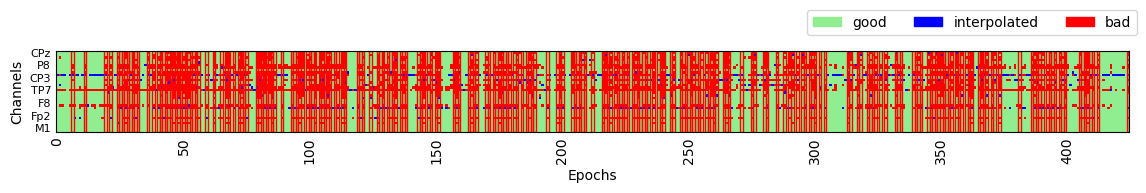

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 41 epochs: 1, 2, 4, 5, 8, 9, 10, 12, 13, 16, 17, 18, 19, 20, 21, 22, 26, 28, 29, 30, 32, 34, 37, 38, 41, 42, 43, 44, 48, 49, 50, 51, 52, 54, 55, 56, 58, 61, 62, 63, 69


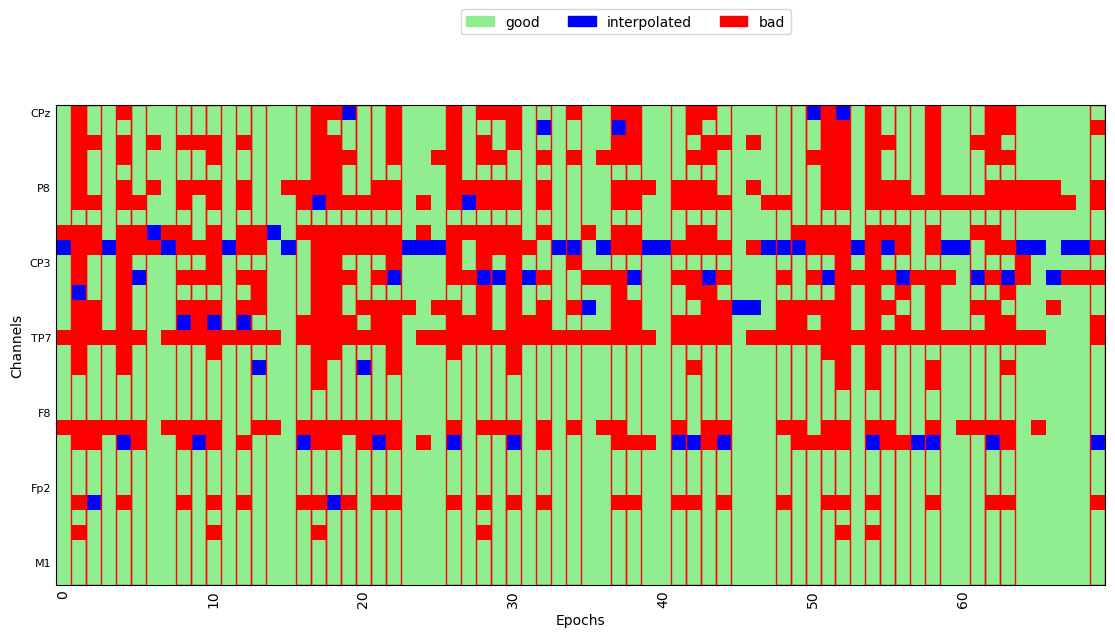

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/449 [00:00<?,       ?it/s]

Dropped 172 epochs: 1, 2, 3, 11, 12, 18, 22, 25, 26, 29, 32, 34, 45, 52, 55, 59, 60, 63, 64, 65, 70, 72, 73, 74, 75, 76, 93, 100, 101, 102, 106, 108, 110, 111, 112, 117, 120, 121, 123, 128, 136, 143, 144, 145, 146, 149, 152, 153, 162, 171, 181, 182, 188, 189, 191, 192, 193, 194, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 209, 210, 211, 212, 213, 214, 215, 220, 229, 233, 239, 242, 243, 244, 249, 250, 256, 262, 263, 265, 266, 267, 268, 269, 271, 272, 273, 275, 276, 277, 280, 284, 285, 286, 287, 288, 291, 293, 294, 295, 296, 297, 298, 299, 301, 302, 303, 304, 305, 306, 307, 308, 311, 315, 318, 319, 320, 324, 325, 326, 327, 328, 329, 331, 332, 333, 334, 339, 342, 343, 344, 345, 347, 348, 349, 350, 351, 355, 356, 357, 377, 381, 386, 396, 398, 399, 409, 410, 411, 412, 413, 414, 419, 423, 424, 425, 430, 433, 434, 438, 444, 445, 448


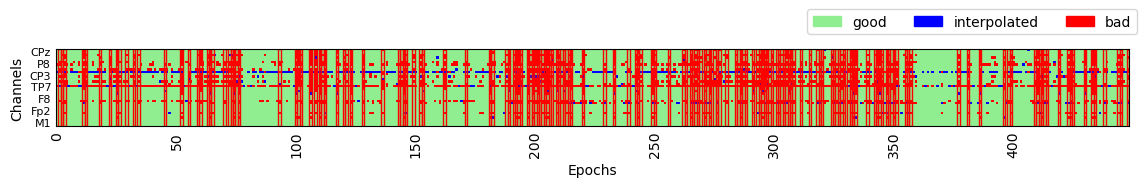

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 26 epochs: 3, 8, 14, 20, 29, 32, 33, 37, 39, 42, 43, 44, 47, 48, 52, 53, 54, 55, 60, 61, 62, 63, 65, 67, 68, 69


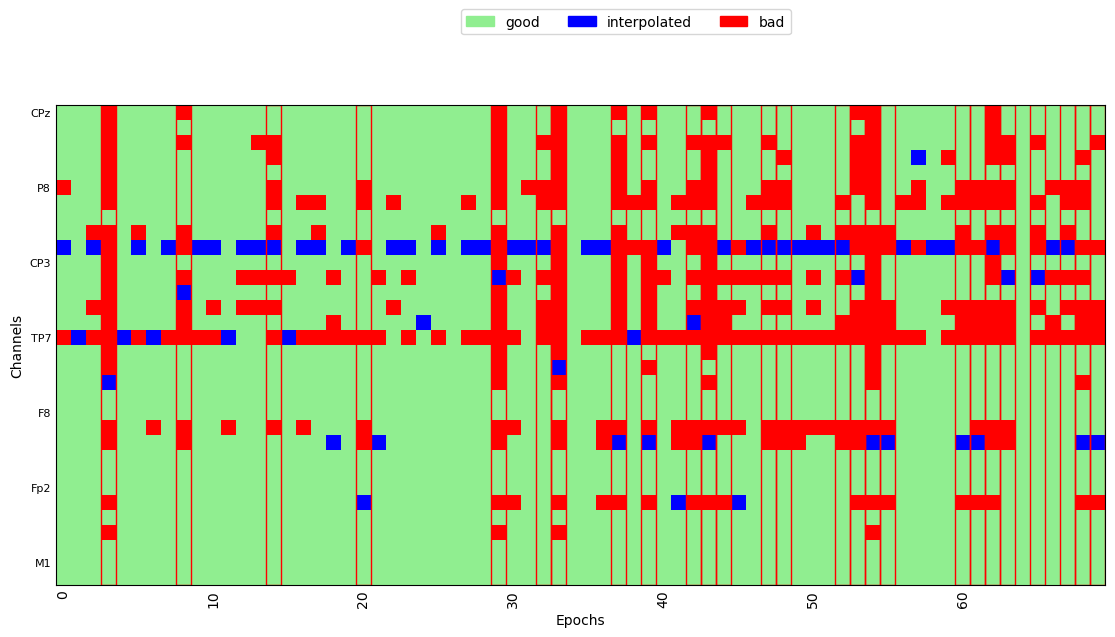

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/457 [00:00<?,       ?it/s]

Dropped 256 epochs: 0, 2, 6, 8, 10, 12, 14, 15, 16, 18, 19, 20, 21, 28, 31, 32, 36, 37, 38, 39, 41, 42, 45, 46, 48, 49, 54, 55, 56, 57, 58, 59, 61, 62, 63, 64, 68, 69, 70, 71, 72, 73, 74, 75, 78, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 97, 98, 99, 100, 101, 102, 104, 105, 106, 107, 108, 109, 112, 118, 120, 121, 122, 123, 126, 127, 132, 134, 135, 136, 137, 139, 140, 141, 142, 143, 146, 149, 152, 156, 157, 160, 163, 164, 165, 166, 168, 173, 174, 178, 182, 183, 186, 187, 194, 195, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 215, 216, 217, 218, 219, 220, 221, 222, 224, 225, 226, 227, 228, 230, 231, 232, 233, 234, 236, 237, 238, 239, 240, 241, 242, 243, 247, 248, 251, 252, 253, 255, 257, 259, 260, 261, 262, 263, 269, 270, 274, 275, 277, 278, 279, 280, 282, 283, 284, 286, 288, 289, 290, 293, 294, 296, 297, 298, 303, 304, 307, 317, 318, 319, 325, 326, 327, 328, 329, 330, 333, 337, 340, 341, 342, 343, 345, 346, 348, 349, 350, 351, 353, 354, 356, 358, 359, 361, 365, 366, 367,

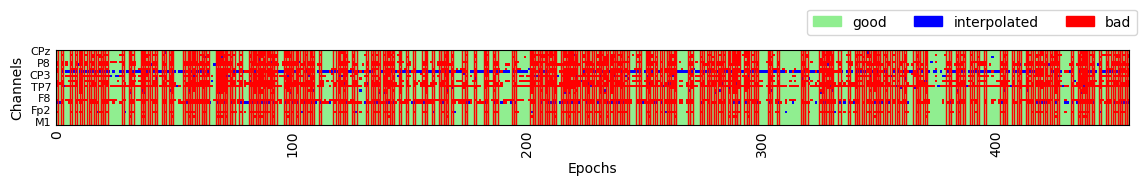

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 41 epochs: 2, 3, 5, 6, 7, 8, 9, 12, 13, 14, 15, 19, 20, 21, 25, 27, 31, 32, 33, 34, 35, 36, 37, 39, 41, 42, 44, 45, 48, 50, 51, 52, 55, 56, 63, 64, 65, 66, 67, 68, 69


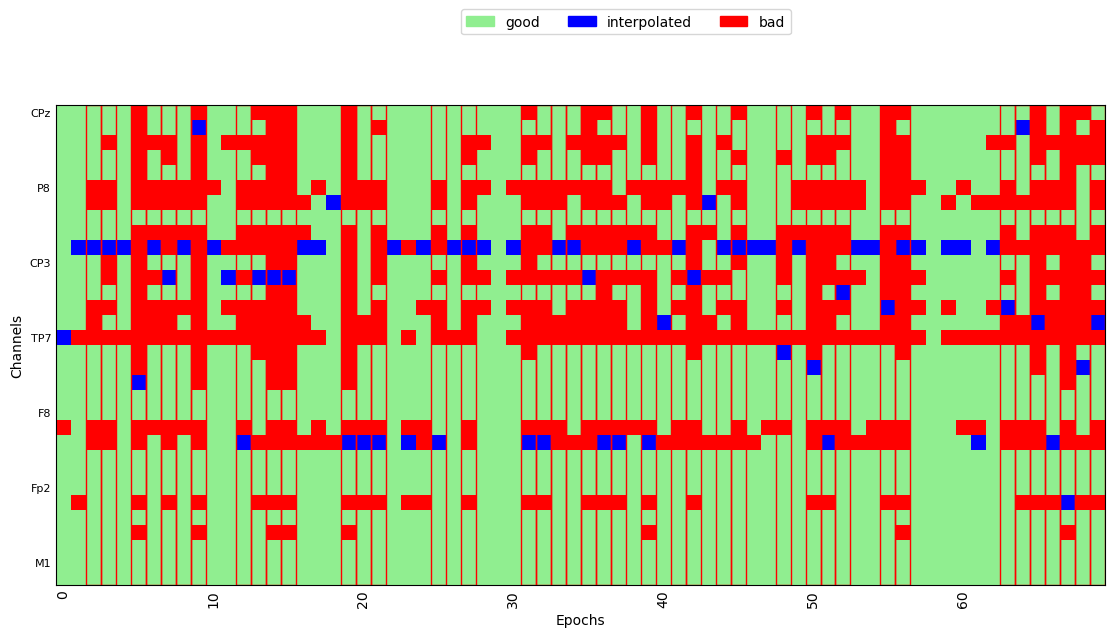

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0010_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1964 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0010_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_c

Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])
/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Creating augmented epochs : 0/31 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/31 [00:00<?,       ?it/s]

... (8 outputs left out)





Estimated consensus=0.40 and n_interpolate=1


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/433 [00:00<?,       ?it/s]

Dropped 180 epochs: 0, 5, 7, 8, 10, 11, 12, 13, 15, 16, 19, 20, 21, 28, 30, 31, 32, 33, 34, 36, 37, 38, 40, 41, 42, 43, 44, 45, 49, 51, 55, 56, 60, 61, 62, 64, 65, 66, 71, 74, 75, 81, 89, 90, 92, 94, 95, 100, 102, 103, 104, 105, 110, 115, 118, 121, 122, 126, 128, 133, 137, 140, 148, 154, 156, 161, 163, 167, 171, 175, 178, 180, 183, 185, 186, 187, 190, 193, 194, 195, 197, 198, 199, 200, 204, 208, 209, 213, 216, 222, 224, 225, 227, 230, 231, 232, 233, 234, 239, 240, 249, 257, 261, 269, 270, 273, 280, 281, 283, 285, 287, 290, 291, 295, 299, 301, 302, 304, 307, 310, 312, 313, 317, 318, 319, 322, 324, 325, 327, 329, 330, 331, 332, 335, 336, 337, 338, 341, 343, 345, 347, 348, 351, 354, 355, 356, 357, 358, 361, 362, 364, 367, 368, 369, 372, 376, 377, 380, 381, 388, 389, 391, 393, 395, 399, 406, 410, 411, 413, 415, 419, 421, 422, 426, 427, 428, 429, 430, 431, 432


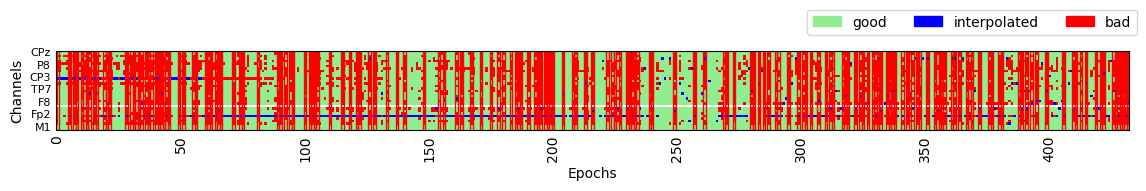

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 34 epochs: 1, 2, 3, 5, 6, 8, 9, 10, 14, 15, 16, 17, 19, 20, 21, 24, 25, 28, 31, 32, 33, 34, 36, 38, 39, 43, 45, 50, 51, 54, 60, 61, 65, 67


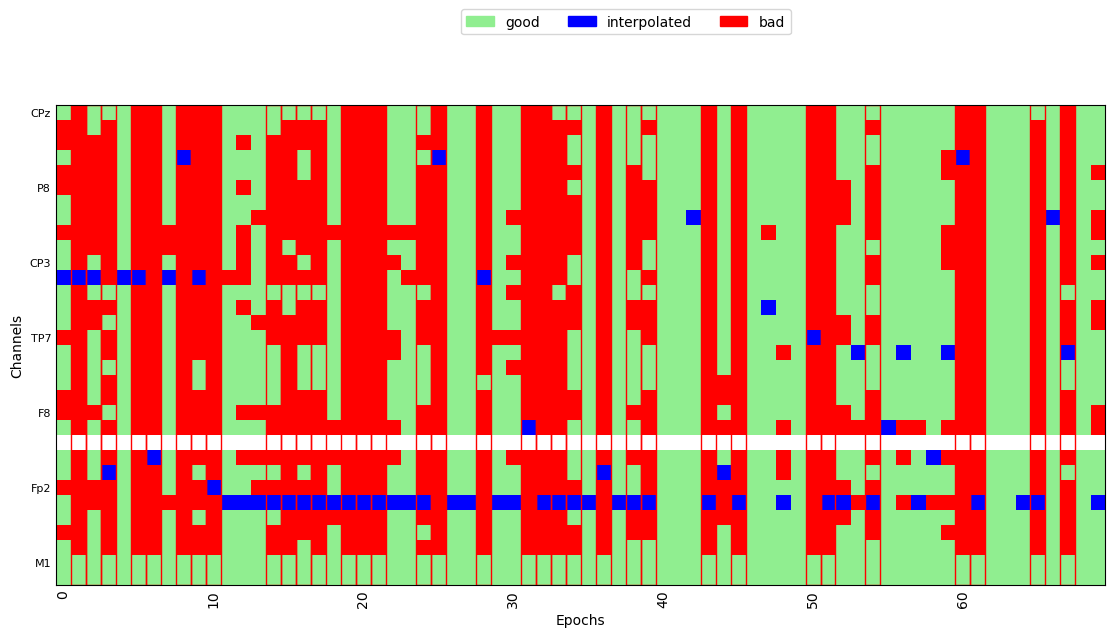

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/441 [00:00<?,       ?it/s]

Dropped 214 epochs: 3, 5, 6, 10, 11, 20, 21, 26, 30, 35, 38, 43, 44, 46, 53, 59, 62, 66, 72, 73, 74, 75, 76, 80, 81, 85, 86, 93, 95, 99, 100, 108, 109, 113, 114, 115, 116, 120, 122, 128, 130, 131, 134, 135, 136, 137, 138, 141, 142, 152, 158, 163, 167, 169, 171, 172, 173, 174, 177, 181, 182, 183, 184, 186, 187, 188, 189, 190, 191, 192, 193, 194, 196, 197, 199, 201, 205, 211, 212, 213, 216, 217, 219, 220, 221, 222, 223, 226, 227, 229, 232, 236, 238, 240, 242, 243, 244, 246, 247, 248, 252, 253, 254, 256, 257, 259, 260, 261, 263, 267, 270, 274, 277, 279, 281, 282, 284, 286, 287, 288, 289, 292, 293, 296, 299, 301, 302, 303, 304, 305, 310, 311, 312, 316, 321, 322, 325, 326, 330, 333, 334, 337, 338, 340, 342, 344, 345, 346, 348, 354, 356, 357, 360, 361, 362, 363, 364, 366, 368, 369, 370, 371, 373, 376, 378, 379, 380, 381, 382, 384, 385, 386, 387, 388, 389, 390, 391, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 404, 405, 407, 408, 409, 410, 412, 413, 414, 415, 416, 417, 418, 419, 423, 425

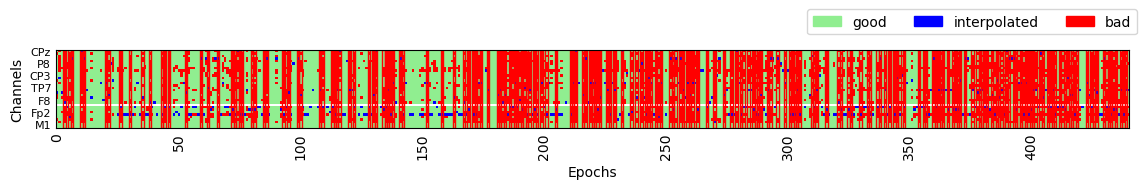

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 40 epochs: 0, 3, 4, 5, 7, 8, 9, 11, 12, 15, 17, 18, 20, 21, 25, 26, 29, 32, 33, 36, 38, 39, 42, 43, 45, 49, 52, 53, 56, 58, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69


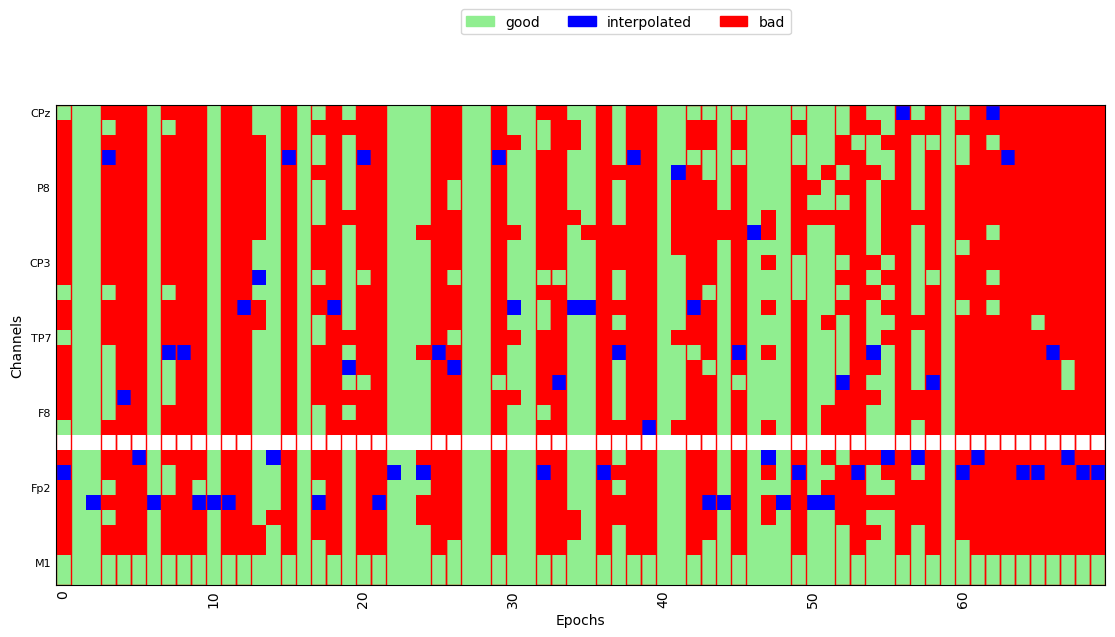

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/403 [00:00<?,       ?it/s]

Dropped 219 epochs: 3, 4, 7, 8, 14, 15, 16, 18, 19, 21, 22, 23, 25, 26, 30, 32, 33, 34, 37, 38, 39, 40, 42, 44, 45, 48, 54, 56, 57, 58, 61, 62, 63, 66, 70, 73, 77, 79, 83, 88, 95, 96, 97, 98, 99, 101, 102, 105, 106, 111, 112, 113, 115, 117, 118, 122, 124, 125, 127, 128, 129, 130, 132, 133, 136, 137, 138, 139, 140, 141, 142, 144, 145, 146, 147, 148, 149, 150, 153, 157, 158, 159, 160, 162, 163, 164, 165, 167, 171, 172, 173, 174, 179, 184, 188, 189, 190, 191, 193, 194, 195, 196, 197, 199, 202, 203, 204, 205, 206, 207, 209, 210, 211, 212, 213, 216, 217, 218, 220, 221, 224, 225, 227, 229, 231, 232, 236, 238, 239, 241, 243, 244, 245, 252, 253, 254, 255, 257, 259, 262, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 283, 284, 285, 286, 287, 292, 295, 298, 301, 303, 304, 305, 308, 309, 310, 312, 313, 315, 316, 317, 318, 320, 321, 323, 324, 325, 327, 328, 329, 331, 332, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 348, 349, 351, 355, 356, 357, 358, 359, 366, 367, 369,

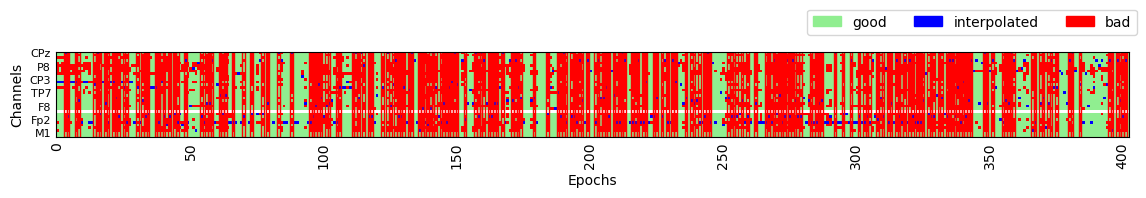

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 42 epochs: 0, 1, 2, 4, 5, 6, 7, 8, 10, 11, 15, 19, 20, 21, 24, 25, 26, 27, 31, 32, 36, 37, 38, 39, 40, 43, 44, 45, 46, 47, 48, 50, 52, 53, 54, 55, 58, 59, 61, 64, 67, 68


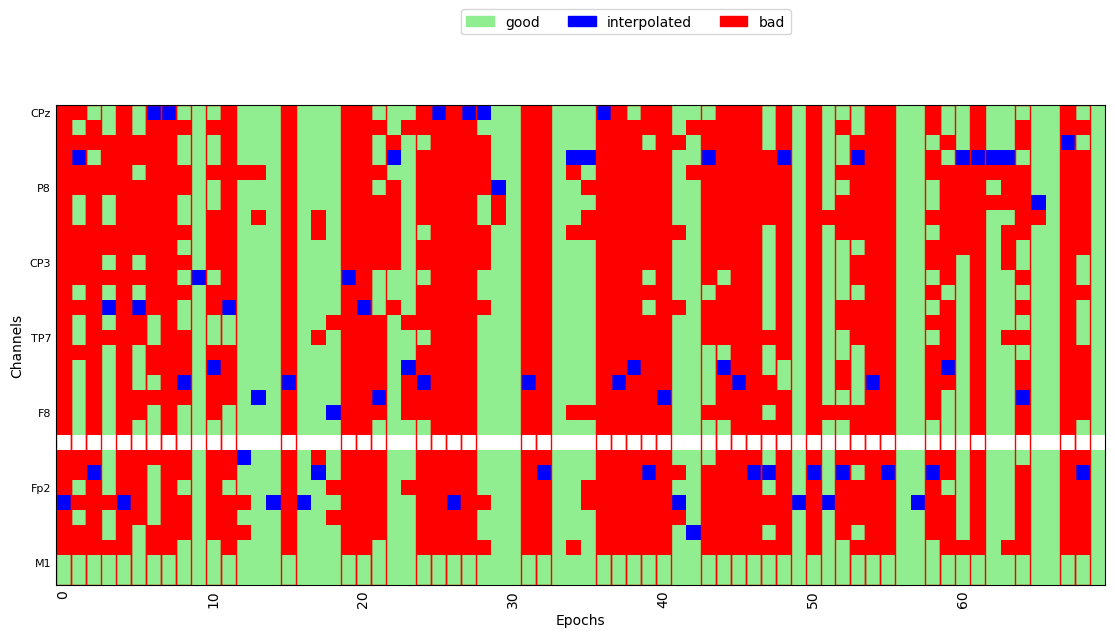

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/407 [00:00<?,       ?it/s]

Dropped 184 epochs: 2, 3, 8, 9, 10, 13, 16, 18, 19, 20, 22, 23, 25, 29, 30, 37, 44, 49, 54, 56, 57, 58, 59, 60, 61, 63, 64, 68, 71, 76, 77, 81, 83, 86, 88, 89, 90, 91, 92, 93, 94, 95, 96, 98, 106, 108, 109, 112, 114, 115, 116, 117, 119, 120, 122, 124, 125, 126, 128, 130, 131, 134, 135, 138, 139, 140, 141, 142, 143, 144, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 166, 168, 169, 170, 171, 173, 174, 177, 183, 185, 186, 188, 192, 193, 194, 195, 200, 206, 207, 213, 218, 219, 223, 226, 227, 229, 230, 231, 233, 234, 237, 239, 245, 246, 249, 250, 251, 255, 257, 260, 263, 264, 266, 267, 268, 270, 271, 273, 275, 277, 279, 281, 290, 291, 293, 294, 296, 297, 299, 301, 309, 311, 312, 313, 314, 317, 319, 320, 321, 323, 324, 329, 330, 332, 333, 336, 337, 340, 346, 350, 361, 362, 364, 367, 370, 371, 374, 375, 379, 380, 382, 386, 388, 399, 403, 405


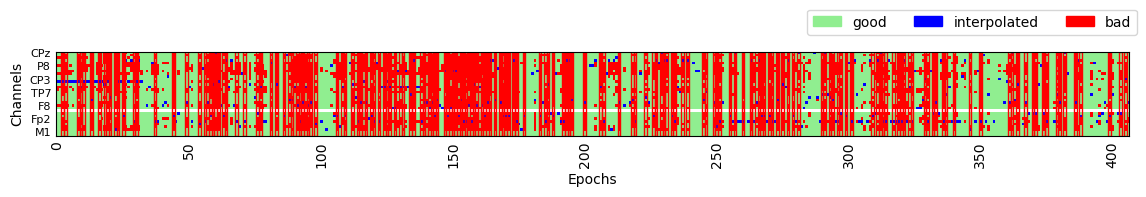

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 1 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 35 epochs: 1, 4, 7, 8, 9, 10, 12, 13, 14, 15, 18, 20, 21, 22, 23, 24, 25, 26, 31, 32, 34, 40, 41, 42, 46, 47, 49, 54, 57, 60, 61, 62, 64, 67, 69


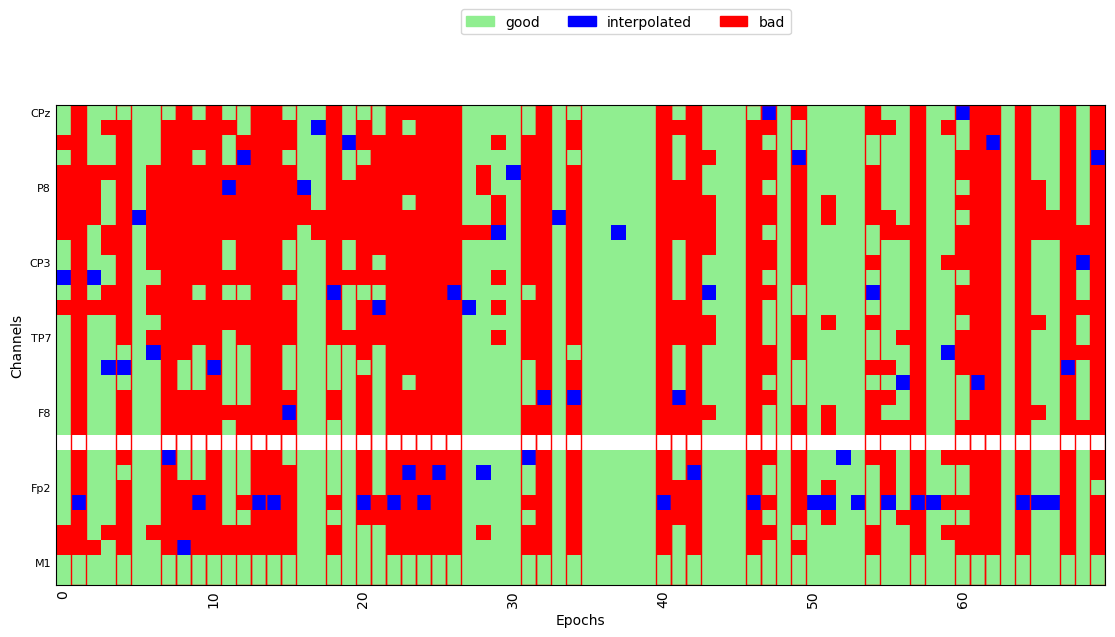

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 31 sensor positions
Interpolating 1 sensors
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0022_VOT_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1936 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0022_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

... (7 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/407 [00:00<?,       ?it/s]

Dropped 9 epochs: 1, 8, 9, 11, 35, 237, 305, 351, 373


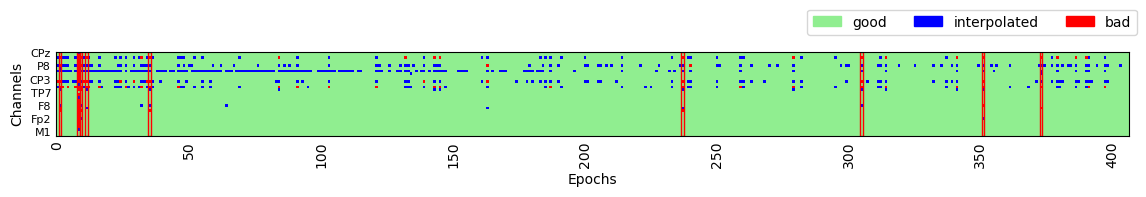

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 1, 8, 12, 16


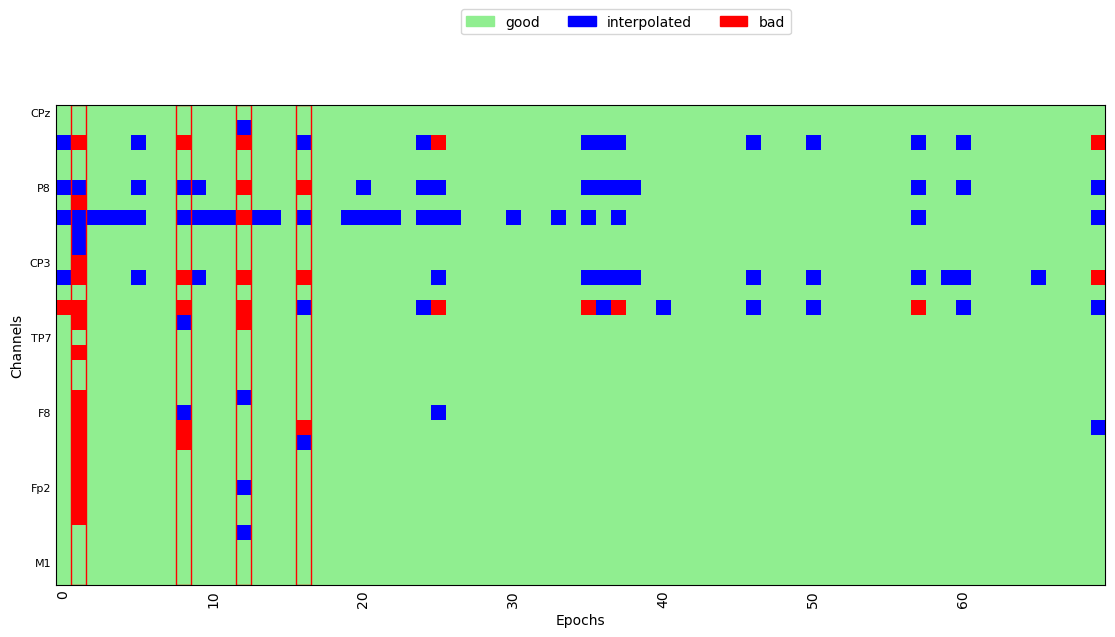

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/420 [00:00<?,       ?it/s]

Dropped 7 epochs: 1, 7, 96, 196, 231, 235, 406


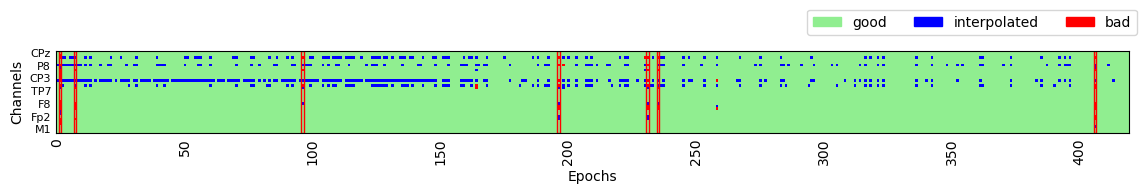

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 33


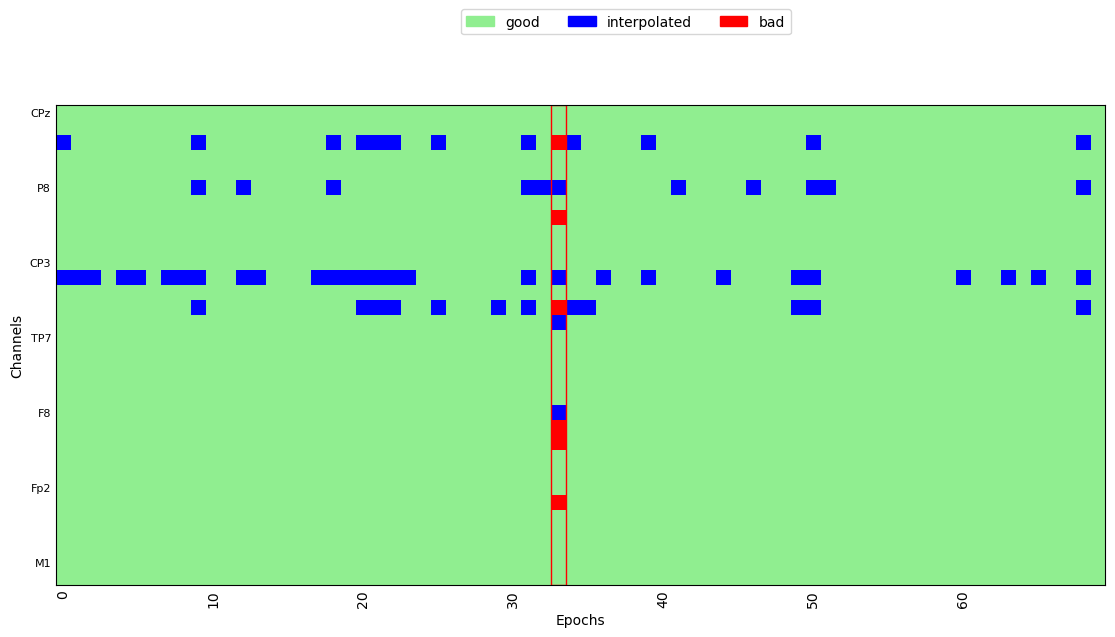

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/407 [00:00<?,       ?it/s]

Dropped 218 epochs: 16, 20, 26, 27, 28, 29, 31, 32, 33, 37, 38, 39, 42, 45, 47, 49, 50, 51, 52, 53, 54, 57, 58, 59, 61, 62, 64, 65, 66, 70, 71, 72, 73, 74, 75, 78, 79, 80, 81, 82, 83, 85, 86, 87, 88, 89, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 102, 103, 104, 106, 107, 108, 109, 110, 111, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 130, 131, 132, 133, 135, 136, 137, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 163, 164, 166, 167, 168, 169, 170, 171, 172, 174, 175, 177, 178, 181, 183, 184, 186, 187, 188, 189, 190, 191, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 213, 215, 216, 217, 219, 221, 223, 224, 225, 226, 227, 228, 230, 231, 233, 234, 235, 237, 238, 239, 240, 241, 242, 243, 244, 245, 250, 252, 253, 254, 255, 256, 258, 259, 260, 261, 262, 263, 266, 267, 268, 269, 270, 272, 273, 275, 276, 277, 278, 279, 280, 281, 282, 284, 285, 286, 

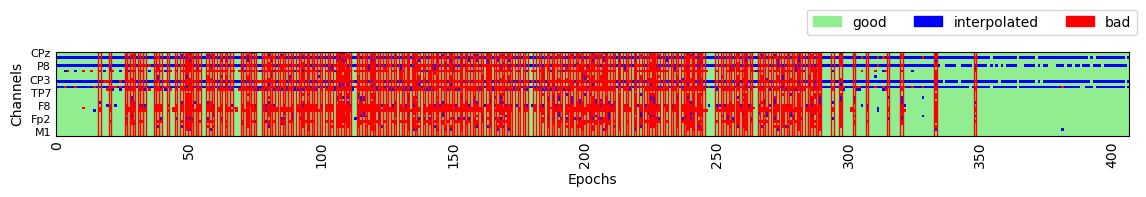

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 36 epochs: 1, 3, 4, 6, 7, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 23, 24, 25, 27, 28, 30, 31, 32, 33, 34, 36, 38, 39, 40, 41, 42, 43, 45, 49


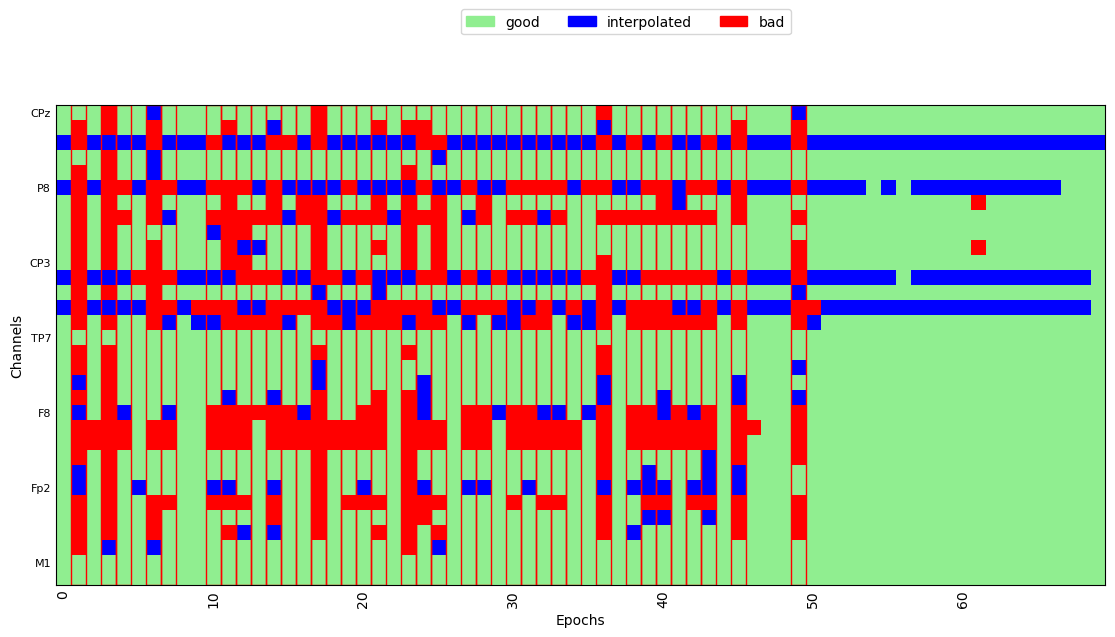

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/422 [00:00<?,       ?it/s]

Dropped 17 epochs: 4, 6, 29, 41, 51, 104, 127, 144, 176, 227, 241, 248, 254, 276, 303, 312, 417


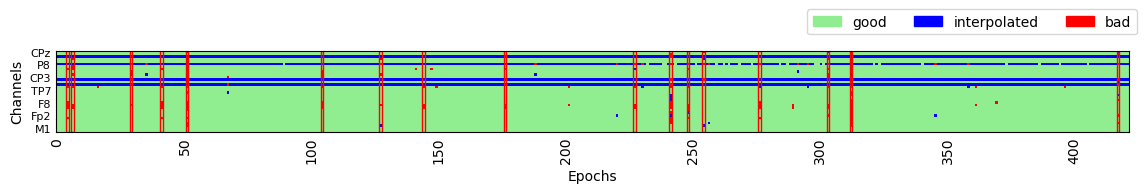

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 34, 35, 48, 51, 59


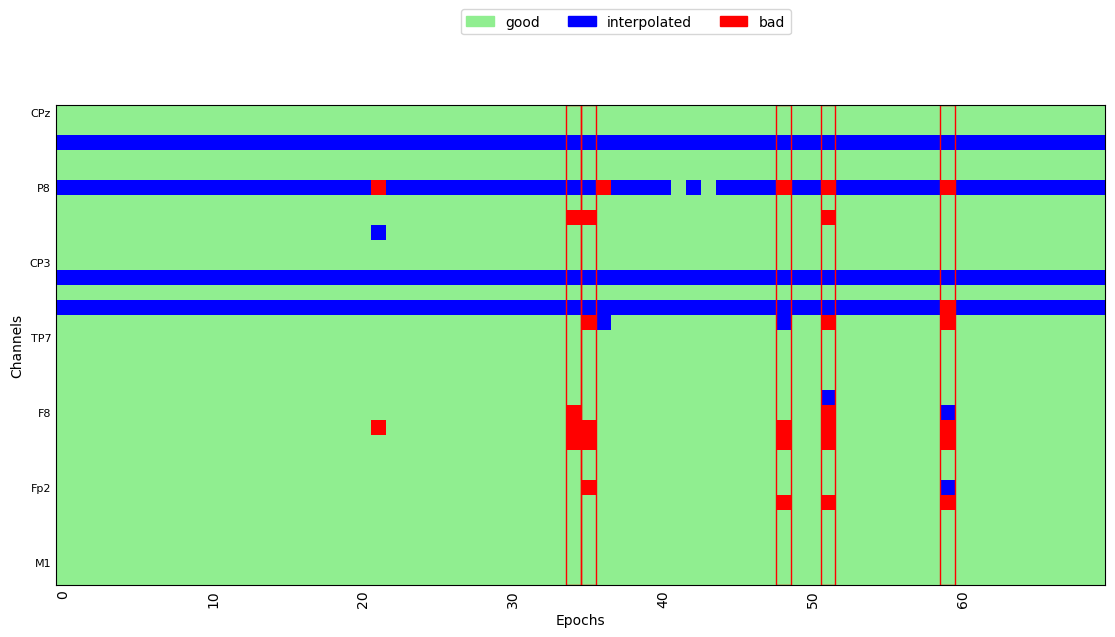

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0004_VOT_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1951 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0004_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_

Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/1951 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=1


  0%|          | Repairing epochs : 0/429 [00:00<?,       ?it/s]

Dropped 53 epochs: 17, 28, 52, 66, 85, 112, 130, 143, 145, 147, 157, 162, 165, 194, 216, 217, 221, 225, 229, 231, 232, 239, 240, 243, 256, 277, 282, 307, 309, 310, 312, 313, 316, 318, 319, 340, 343, 345, 346, 347, 348, 349, 354, 360, 361, 362, 365, 366, 367, 369, 370, 372, 374


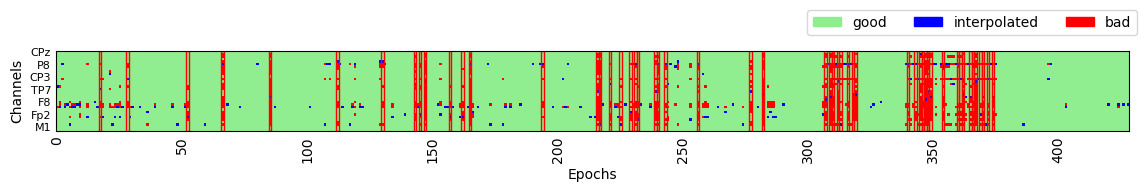

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 3, 35, 46, 49, 55, 56, 58, 59, 66


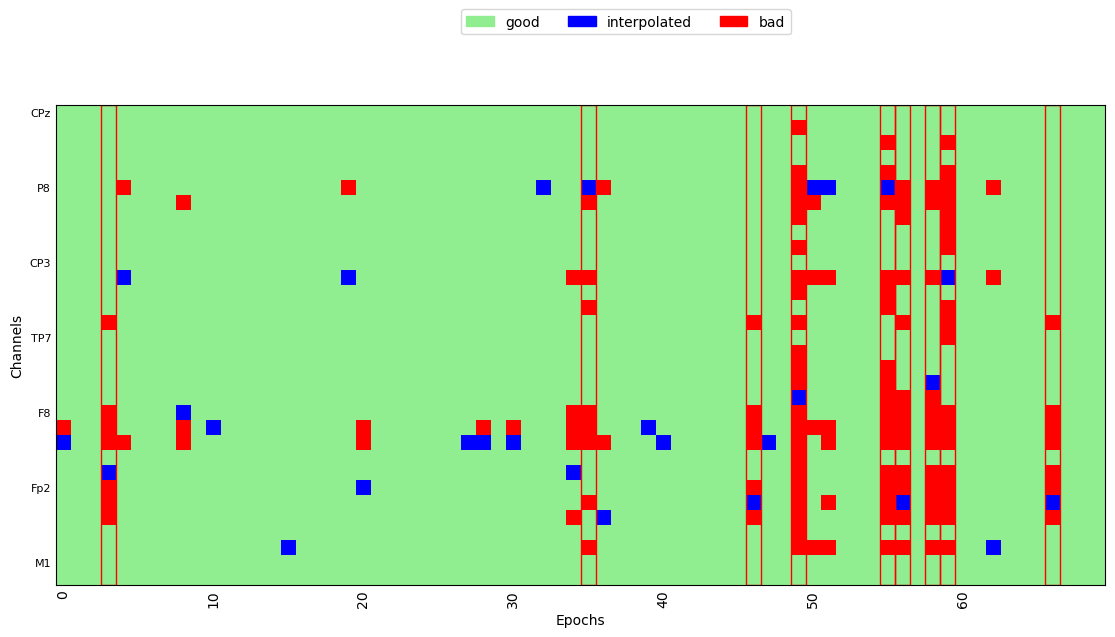

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/397 [00:00<?,       ?it/s]

Dropped 144 epochs: 29, 31, 33, 34, 35, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 72, 73, 76, 77, 79, 84, 85, 86, 87, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 101, 102, 103, 104, 105, 106, 107, 108, 111, 113, 147, 148, 149, 156, 158, 159, 160, 161, 162, 163, 164, 165, 168, 169, 170, 171, 173, 175, 176, 177, 189, 190, 191, 194, 195, 199, 200, 204, 205, 214, 219, 224, 225, 232, 239, 240, 242, 243, 248, 249, 250, 253, 254, 255, 256, 257, 259, 260, 294, 303, 309, 311, 312, 313, 315, 316, 317, 318, 319, 345, 346, 347, 348, 349, 350, 351, 352, 353, 355, 356, 358, 359, 360, 361, 363, 364, 367, 368, 369, 371, 372, 373, 374, 375, 376, 377, 378, 380, 381, 382, 384, 385, 386, 388, 391, 393, 395, 396


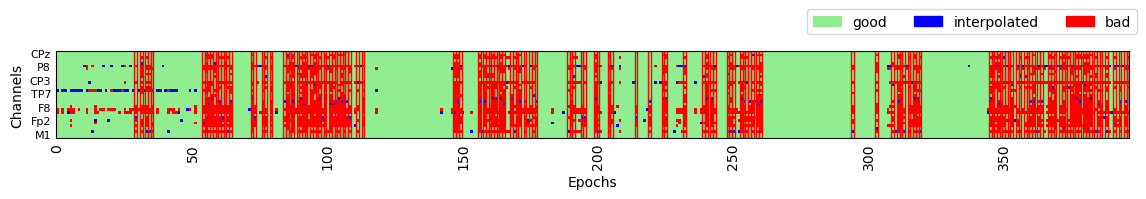

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 25 epochs: 8, 12, 14, 15, 16, 17, 18, 21, 28, 29, 35, 39, 40, 44, 53, 54, 55, 61, 63, 64, 65, 66, 67, 68, 69


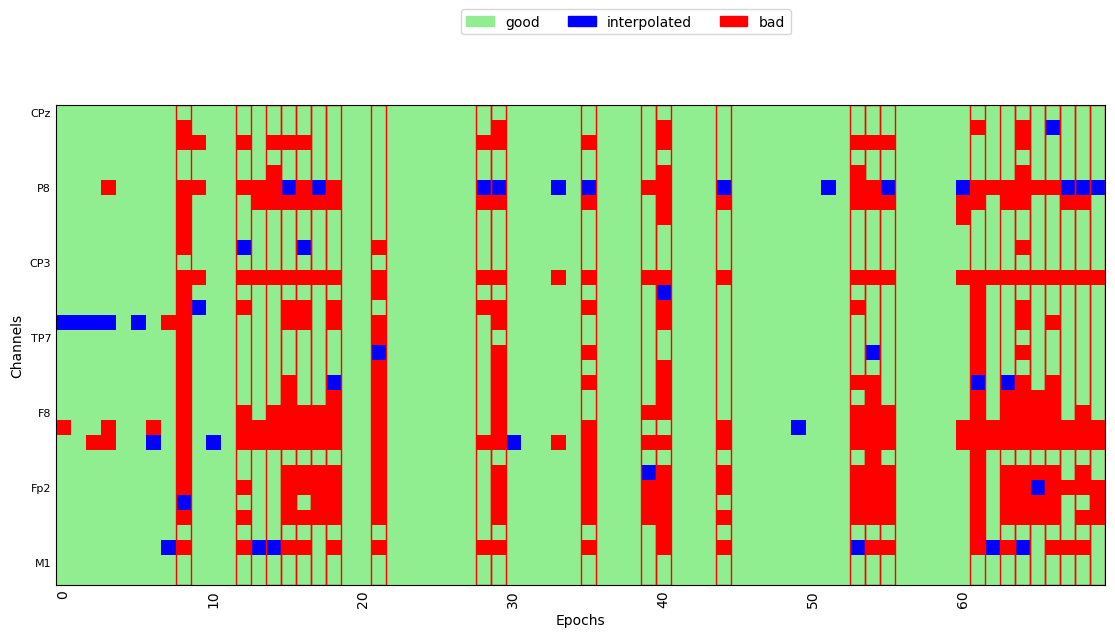

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/415 [00:00<?,       ?it/s]

Dropped 41 epochs: 3, 49, 69, 87, 124, 161, 186, 213, 219, 231, 262, 270, 280, 281, 292, 299, 300, 303, 304, 307, 324, 325, 331, 335, 336, 339, 346, 347, 359, 363, 365, 366, 367, 368, 369, 393, 394, 396, 407, 413, 414


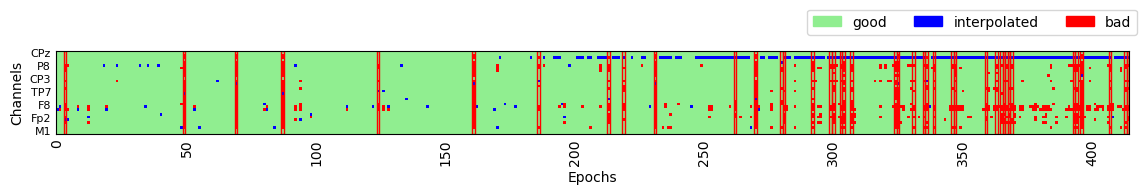

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 47, 63, 66, 69


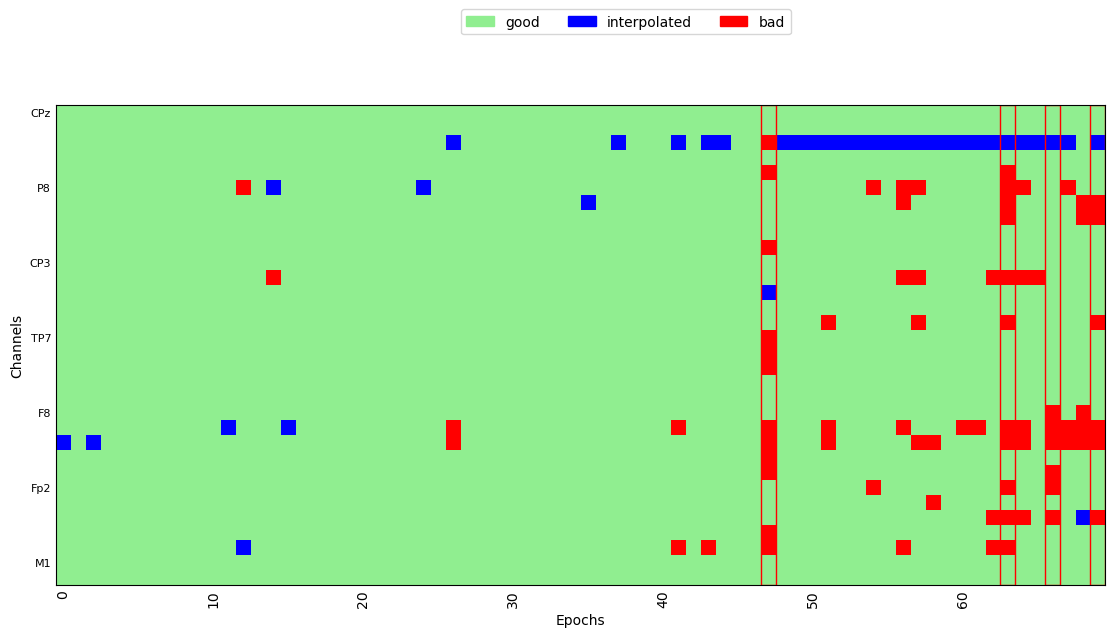

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/430 [00:00<?,       ?it/s]

Dropped 168 epochs: 31, 58, 74, 89, 93, 110, 112, 114, 119, 123, 131, 132, 133, 134, 141, 146, 148, 155, 156, 157, 161, 163, 174, 175, 176, 180, 182, 186, 188, 189, 190, 192, 193, 194, 196, 197, 198, 199, 201, 202, 207, 208, 209, 211, 212, 214, 215, 219, 221, 228, 233, 234, 235, 239, 240, 241, 242, 243, 246, 247, 248, 249, 250, 257, 258, 259, 260, 261, 262, 263, 265, 266, 267, 270, 271, 273, 274, 279, 280, 281, 282, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 309, 313, 319, 320, 321, 323, 324, 327, 328, 330, 332, 333, 337, 338, 345, 346, 347, 353, 354, 355, 357, 358, 359, 360, 361, 363, 364, 365, 368, 369, 370, 372, 373, 375, 377, 385, 387, 388, 389, 390, 392, 393, 394, 395, 398, 400, 401, 402, 403, 404, 406, 407, 408, 410, 411, 414, 415, 416, 417, 420, 423, 424, 425, 428


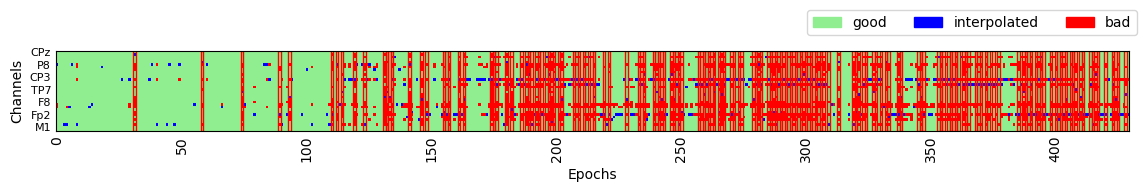

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 20 epochs: 24, 26, 27, 29, 33, 34, 41, 42, 44, 47, 48, 49, 55, 57, 58, 61, 62, 63, 65, 69


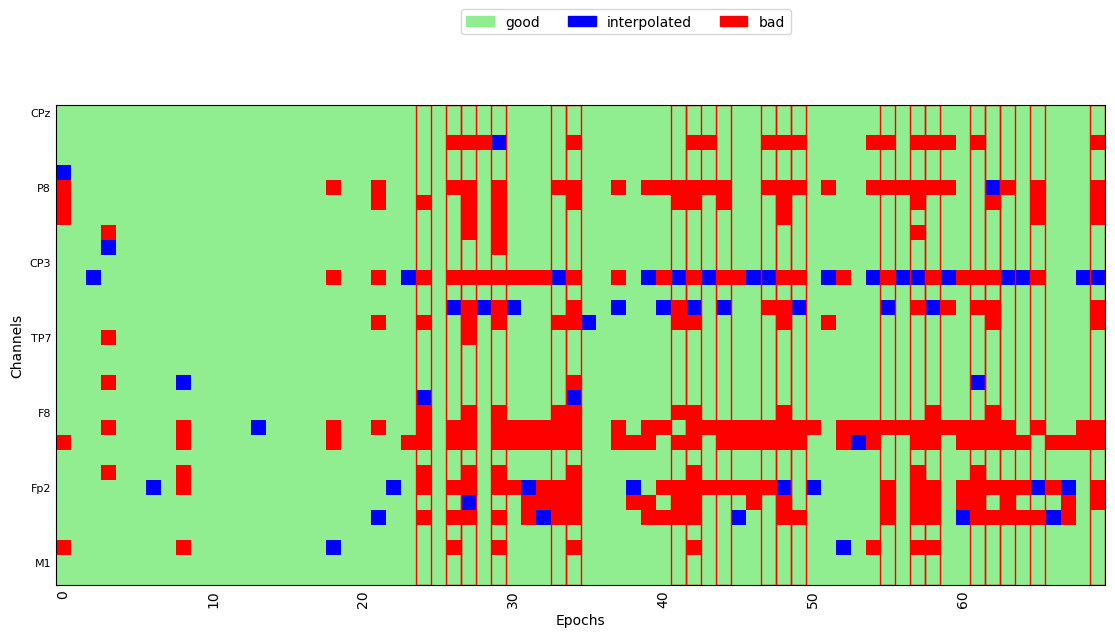

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0011_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1997 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0011_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_c

Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/28 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/28 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/1997 [00:00<?,       ?it/s]

... (7 outputs left out)





Estimated consensus=0.80 and n_interpolate=1


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 4 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/437 [00:00<?,       ?it/s]

Dropped 82 epochs: 0, 9, 11, 15, 25, 38, 45, 49, 50, 64, 67, 72, 73, 75, 78, 80, 83, 87, 88, 90, 100, 110, 118, 121, 125, 128, 137, 146, 147, 152, 160, 164, 171, 175, 178, 194, 196, 199, 208, 209, 238, 243, 250, 252, 258, 264, 266, 272, 282, 286, 289, 291, 294, 300, 316, 319, 321, 329, 340, 353, 356, 363, 365, 371, 372, 385, 387, 388, 389, 391, 393, 394, 395, 398, 402, 414, 415, 419, 421, 424, 427, 429


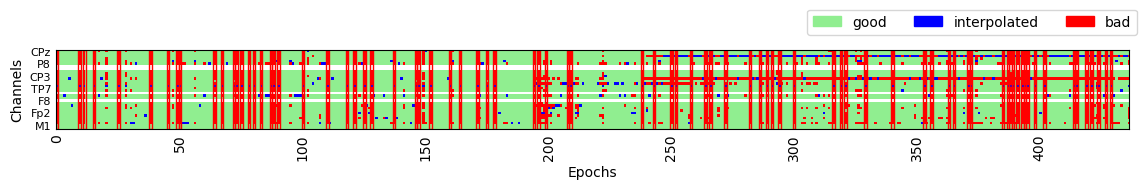

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 28 sensor positions
Interpolating 4 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 4 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 17 epochs: 1, 5, 8, 11, 13, 14, 21, 34, 39, 49, 50, 53, 55, 58, 61, 63, 66


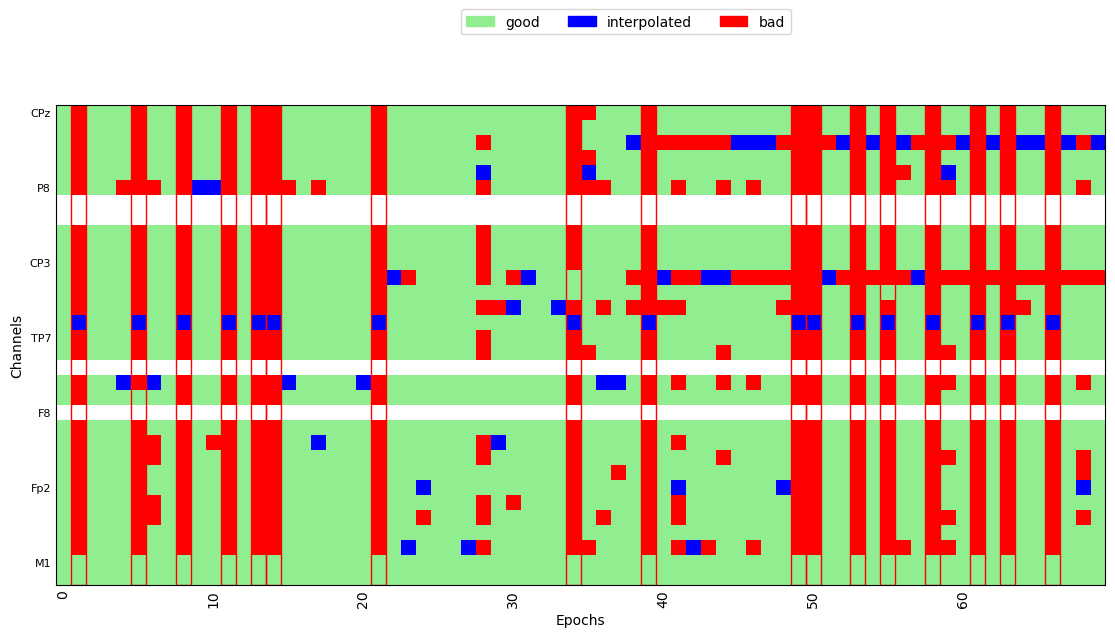

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 28 sensor positions
Interpolating 4 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 4 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/435 [00:00<?,       ?it/s]

Dropped 83 epochs: 0, 5, 10, 13, 18, 20, 24, 31, 37, 45, 54, 59, 65, 69, 78, 93, 95, 97, 119, 123, 127, 129, 135, 139, 141, 144, 146, 147, 151, 154, 155, 160, 165, 181, 185, 192, 197, 206, 208, 212, 213, 220, 228, 230, 231, 236, 242, 243, 245, 258, 269, 271, 272, 274, 279, 292, 312, 323, 327, 331, 336, 341, 344, 347, 352, 353, 354, 356, 361, 362, 366, 372, 380, 387, 397, 399, 405, 408, 419, 423, 429, 432, 434


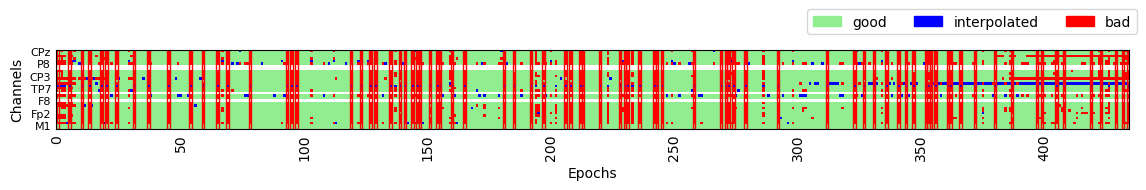

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 28 sensor positions
Interpolating 4 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 4 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 10 epochs: 2, 9, 24, 34, 36, 45, 52, 53, 59, 63


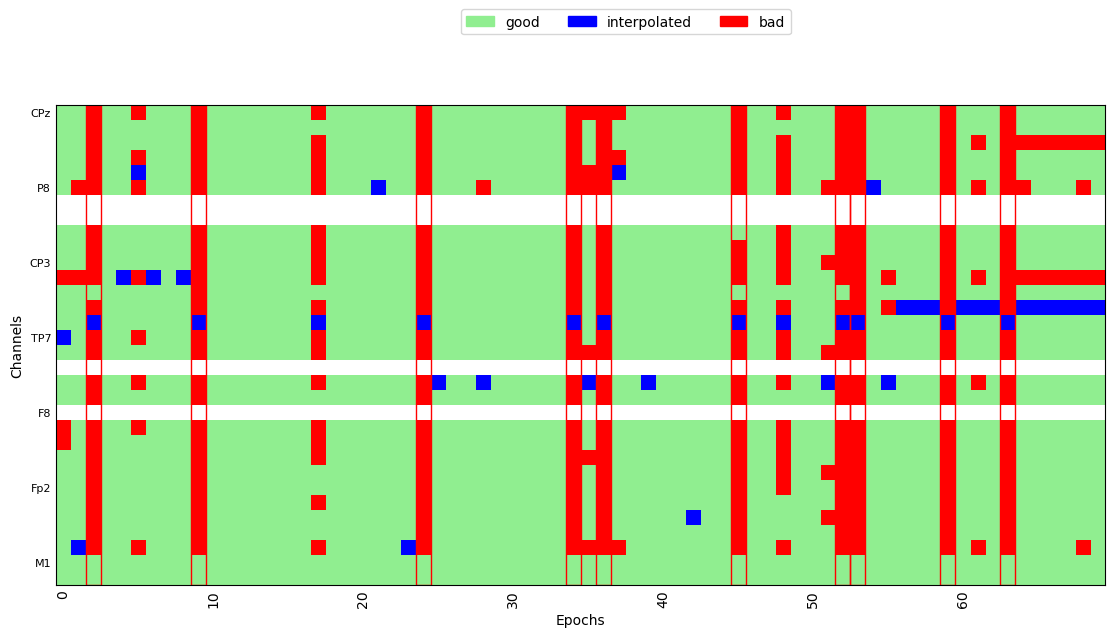

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 28 sensor positions
Interpolating 4 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 4 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/437 [00:00<?,       ?it/s]

Dropped 96 epochs: 1, 14, 18, 22, 26, 28, 30, 36, 40, 41, 50, 55, 58, 61, 64, 66, 69, 72, 80, 84, 85, 89, 95, 96, 99, 104, 111, 114, 117, 122, 125, 130, 136, 138, 150, 151, 156, 157, 158, 166, 169, 174, 175, 180, 184, 185, 189, 190, 207, 209, 211, 213, 218, 219, 221, 223, 227, 229, 232, 235, 237, 240, 253, 261, 263, 266, 279, 281, 284, 288, 297, 300, 311, 320, 327, 329, 341, 344, 349, 352, 356, 358, 361, 373, 374, 377, 385, 392, 400, 411, 413, 418, 422, 427, 428, 431


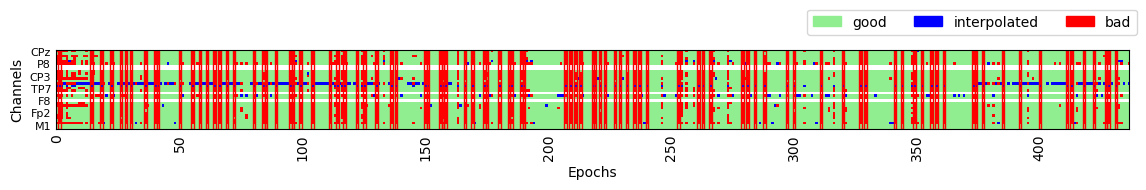

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 28 sensor positions
Interpolating 4 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 4 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 12 epochs: 1, 3, 7, 17, 28, 35, 36, 38, 46, 57, 66, 68


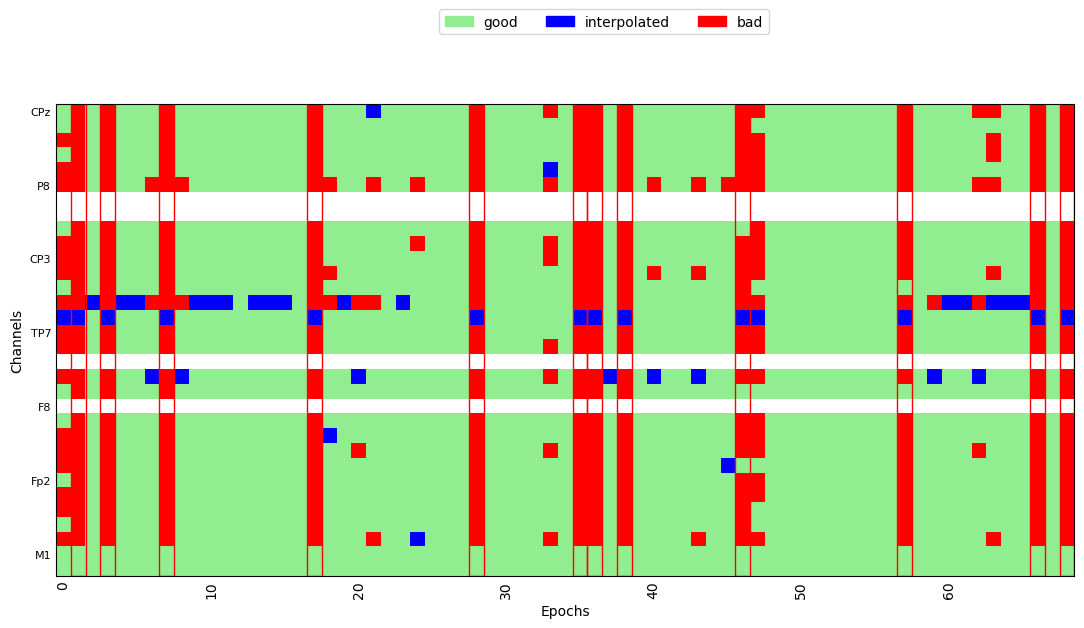

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 28 sensor positions
Interpolating 4 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 4 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/411 [00:00<?,       ?it/s]

Dropped 76 epochs: 6, 10, 12, 25, 30, 31, 33, 35, 36, 37, 41, 43, 44, 47, 52, 56, 58, 61, 62, 69, 77, 83, 93, 98, 107, 120, 125, 126, 128, 139, 147, 156, 160, 181, 184, 187, 190, 199, 207, 210, 215, 226, 230, 238, 242, 244, 245, 250, 253, 260, 264, 271, 274, 287, 294, 303, 311, 316, 320, 324, 328, 329, 335, 346, 350, 356, 371, 373, 379, 383, 388, 390, 402, 404, 406, 408


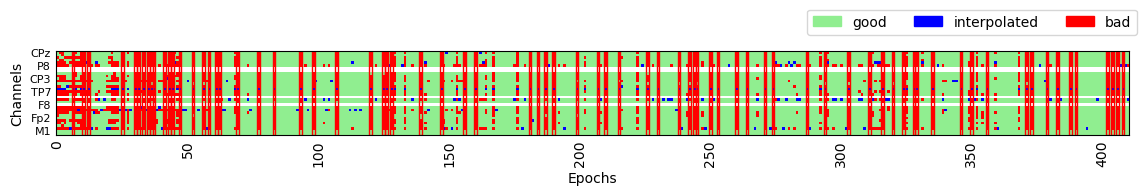

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 28 sensor positions
Interpolating 4 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 4 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

Dropped 10 epochs: 7, 9, 22, 34, 44, 49, 54, 55, 59, 62


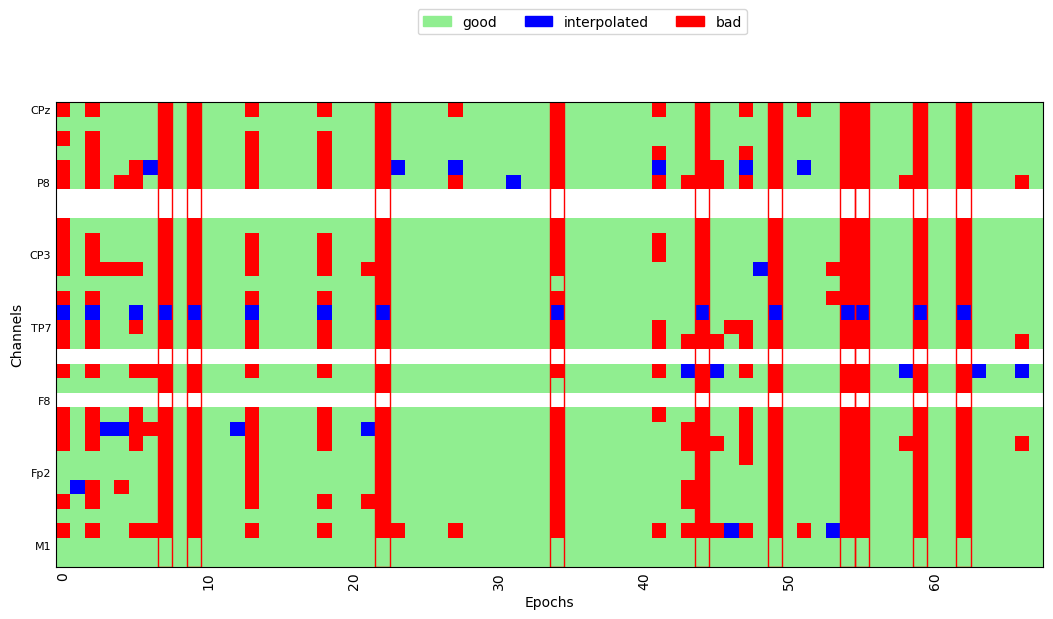

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 28 sensor positions
Interpolating 4 sensors
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0019_F0_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1973 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0019_F0_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])


Running autoreject on ch_type=eeg


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:53: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])


  0%|          | Creating augmented epochs : 0/32 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/32 [00:00<?,       ?it/s]

... (7 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=1


  0%|          | Repairing epochs : 0/421 [00:00<?,       ?it/s]

Dropped 309 epochs: 0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 21, 22, 24, 25, 29, 30, 32, 33, 34, 35, 39, 41, 42, 43, 46, 48, 49, 51, 53, 55, 56, 57, 59, 62, 64, 66, 67, 68, 69, 70, 71, 72, 73, 77, 80, 81, 82, 83, 84, 86, 87, 89, 94, 95, 96, 97, 100, 101, 106, 107, 108, 110, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 124, 129, 132, 135, 136, 138, 140, 141, 144, 145, 147, 149, 150, 151, 153, 158, 159, 160, 161, 162, 165, 166, 168, 170, 171, 172, 173, 174, 175, 177, 178, 179, 180, 181, 182, 183, 184, 185, 188, 191, 192, 195, 196, 197, 198, 200, 201, 205, 206, 208, 209, 214, 215, 216, 217, 218, 219, 221, 222, 224, 226, 227, 234, 238, 239, 240, 241, 243, 244, 245, 249, 250, 251, 252, 253, 254, 255, 256, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 280, 283, 284, 285, 286, 287, 288, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314,

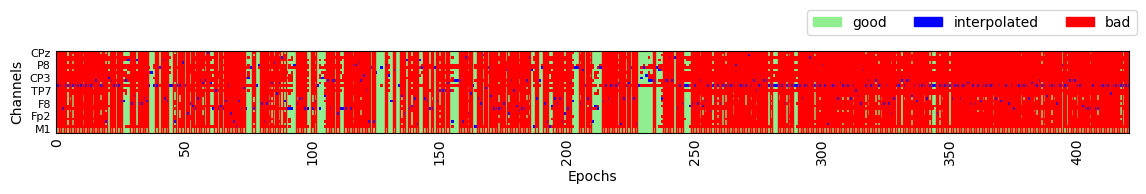

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/66 [00:00<?,       ?it/s]

Dropped 48 epochs: 0, 1, 2, 3, 4, 6, 7, 8, 10, 11, 12, 14, 15, 17, 20, 21, 24, 26, 27, 29, 30, 33, 36, 37, 38, 39, 40, 41, 43, 44, 45, 46, 47, 48, 49, 51, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64


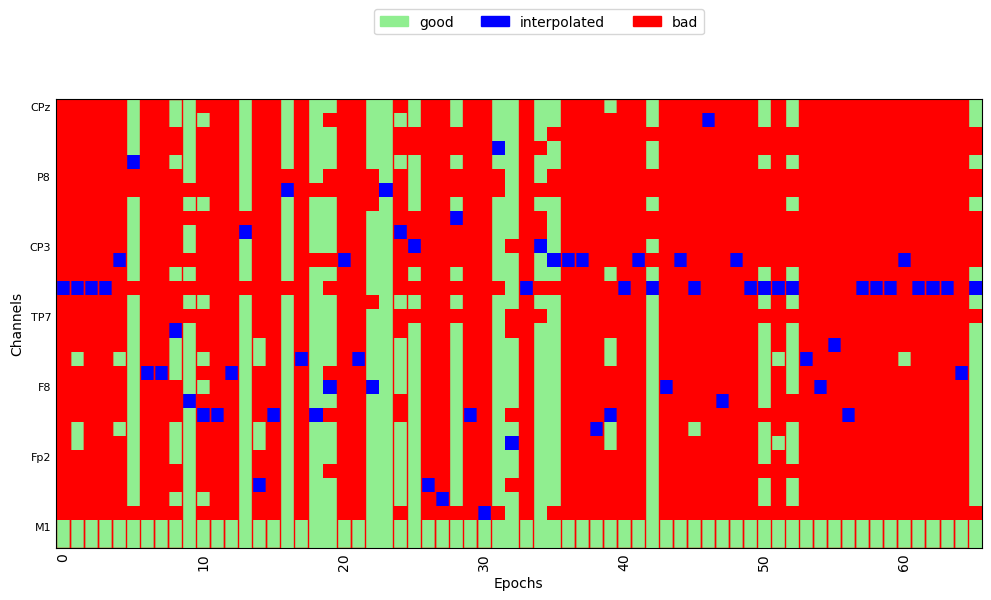

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/427 [00:00<?,       ?it/s]

Dropped 267 epochs: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 20, 21, 23, 24, 25, 27, 29, 30, 33, 34, 41, 44, 46, 47, 48, 53, 55, 56, 58, 61, 62, 63, 64, 65, 68, 69, 70, 71, 72, 74, 75, 77, 78, 81, 82, 83, 86, 87, 90, 99, 100, 101, 103, 105, 107, 108, 109, 110, 111, 112, 117, 119, 122, 123, 124, 125, 127, 129, 131, 134, 135, 136, 137, 139, 140, 143, 144, 145, 146, 147, 148, 149, 152, 153, 154, 155, 156, 157, 158, 160, 161, 164, 165, 166, 167, 168, 169, 171, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 184, 185, 189, 190, 196, 198, 199, 200, 201, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 217, 218, 219, 220, 223, 224, 225, 226, 228, 229, 231, 234, 235, 238, 240, 241, 242, 243, 244, 249, 252, 253, 254, 255, 256, 257, 260, 261, 262, 263, 266, 268, 274, 275, 277, 278, 279, 280, 281, 282, 283, 284, 286, 291, 292, 293, 296, 297, 298, 299, 300, 301, 303, 304, 305, 307, 308, 309, 310, 311, 313, 314, 317, 318, 319, 321, 323, 324, 325, 326, 327, 328, 329, 331,

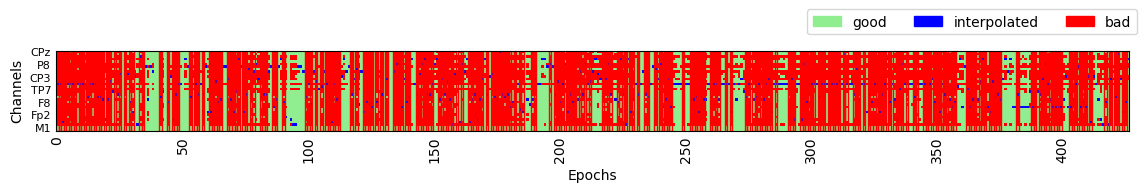

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/66 [00:00<?,       ?it/s]

Dropped 47 epochs: 0, 1, 2, 3, 6, 7, 9, 10, 11, 12, 13, 14, 15, 16, 17, 20, 21, 22, 23, 24, 25, 26, 27, 28, 30, 32, 33, 34, 36, 38, 42, 43, 44, 46, 47, 48, 49, 51, 52, 53, 54, 55, 57, 58, 63, 64, 65


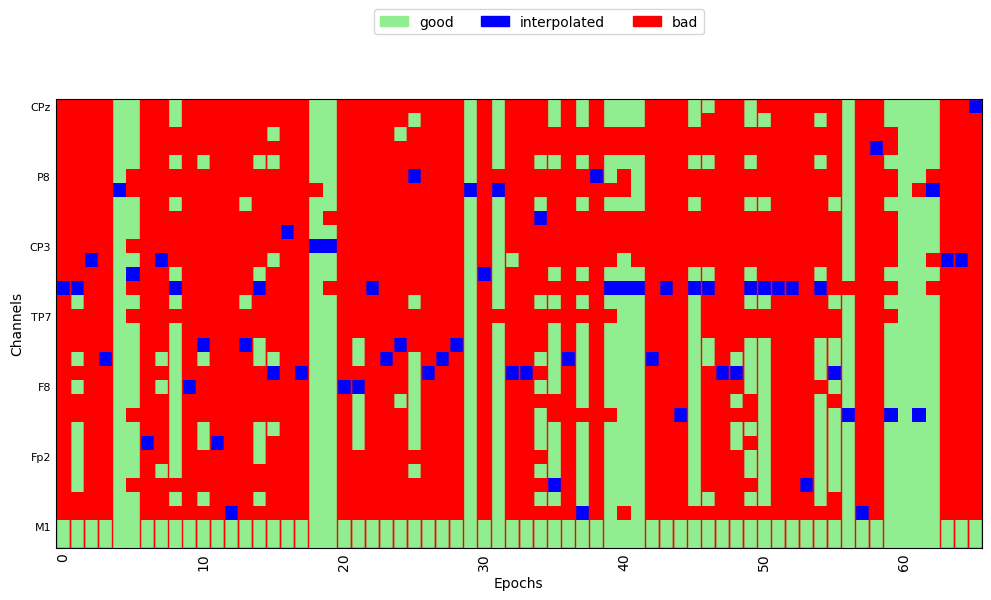

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/406 [00:00<?,       ?it/s]

Dropped 191 epochs: 0, 1, 2, 6, 7, 9, 10, 11, 14, 18, 26, 28, 38, 39, 43, 45, 47, 50, 54, 67, 68, 71, 72, 77, 78, 80, 81, 83, 86, 87, 88, 90, 96, 98, 103, 104, 106, 107, 109, 112, 114, 115, 118, 120, 121, 126, 129, 130, 132, 133, 134, 135, 137, 139, 141, 142, 145, 148, 152, 153, 155, 156, 157, 158, 160, 162, 163, 164, 166, 167, 168, 169, 170, 171, 172, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 187, 189, 190, 191, 192, 193, 194, 195, 197, 198, 199, 201, 202, 203, 204, 208, 210, 213, 214, 216, 219, 220, 221, 228, 229, 231, 233, 235, 237, 244, 245, 247, 249, 252, 253, 254, 255, 258, 259, 260, 262, 263, 264, 265, 266, 268, 269, 270, 273, 274, 275, 277, 278, 279, 280, 282, 283, 285, 286, 289, 290, 291, 295, 296, 298, 299, 300, 301, 302, 304, 305, 306, 307, 310, 312, 313, 314, 317, 322, 323, 324, 325, 327, 328, 334, 337, 342, 343, 344, 345, 347, 349, 352, 354, 355, 356, 357, 358, 359, 369, 372, 373, 384, 386, 391


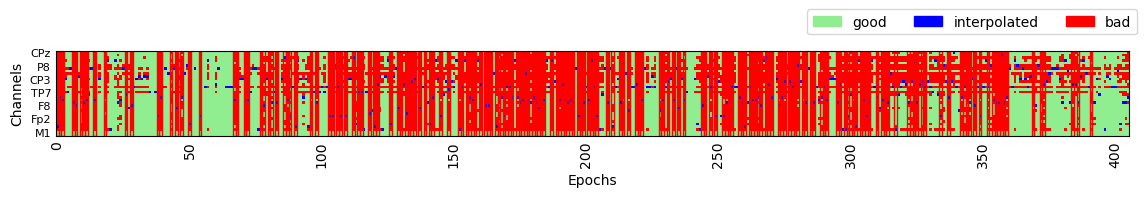

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 30 epochs: 2, 5, 12, 16, 19, 21, 24, 25, 29, 30, 32, 33, 35, 38, 40, 42, 43, 44, 46, 47, 48, 51, 52, 53, 54, 56, 58, 59, 61, 68


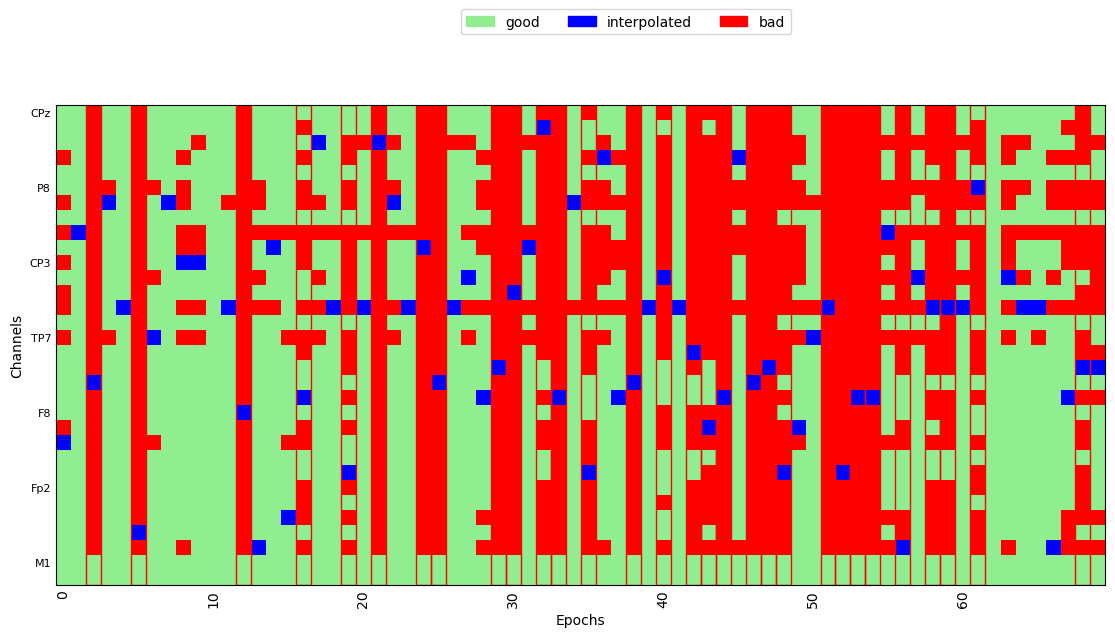

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/447 [00:00<?,       ?it/s]

Dropped 210 epochs: 3, 5, 7, 8, 9, 10, 11, 13, 20, 22, 23, 24, 25, 26, 28, 29, 34, 36, 37, 38, 40, 41, 42, 44, 45, 46, 50, 54, 59, 61, 62, 65, 66, 67, 70, 75, 77, 78, 79, 80, 81, 84, 88, 91, 92, 97, 98, 99, 103, 105, 112, 117, 127, 128, 129, 131, 132, 134, 135, 137, 138, 144, 146, 150, 152, 153, 155, 156, 160, 165, 166, 168, 172, 174, 175, 176, 181, 184, 186, 195, 197, 198, 199, 200, 202, 203, 205, 207, 209, 211, 212, 215, 217, 218, 219, 222, 224, 225, 226, 227, 228, 229, 231, 232, 235, 240, 241, 245, 249, 250, 251, 252, 253, 256, 259, 262, 263, 265, 266, 267, 277, 278, 279, 280, 281, 286, 288, 290, 298, 299, 301, 302, 305, 308, 310, 313, 316, 320, 328, 329, 330, 332, 333, 339, 344, 348, 349, 351, 352, 353, 354, 360, 361, 363, 364, 365, 366, 367, 368, 369, 371, 375, 376, 377, 378, 379, 380, 381, 382, 384, 385, 388, 389, 394, 396, 397, 398, 400, 403, 404, 405, 406, 413, 414, 415, 417, 419, 420, 422, 423, 424, 425, 426, 428, 429, 430, 431, 432, 434, 435, 436, 437, 438, 439, 440, 441, 443

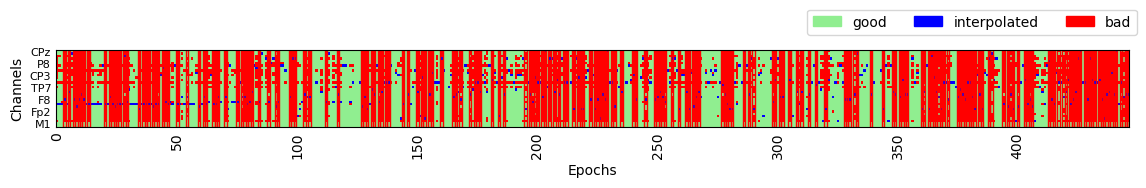

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 27 epochs: 2, 4, 16, 17, 18, 21, 24, 27, 28, 33, 36, 38, 39, 41, 46, 47, 50, 51, 57, 58, 60, 62, 65, 66, 67, 68, 69


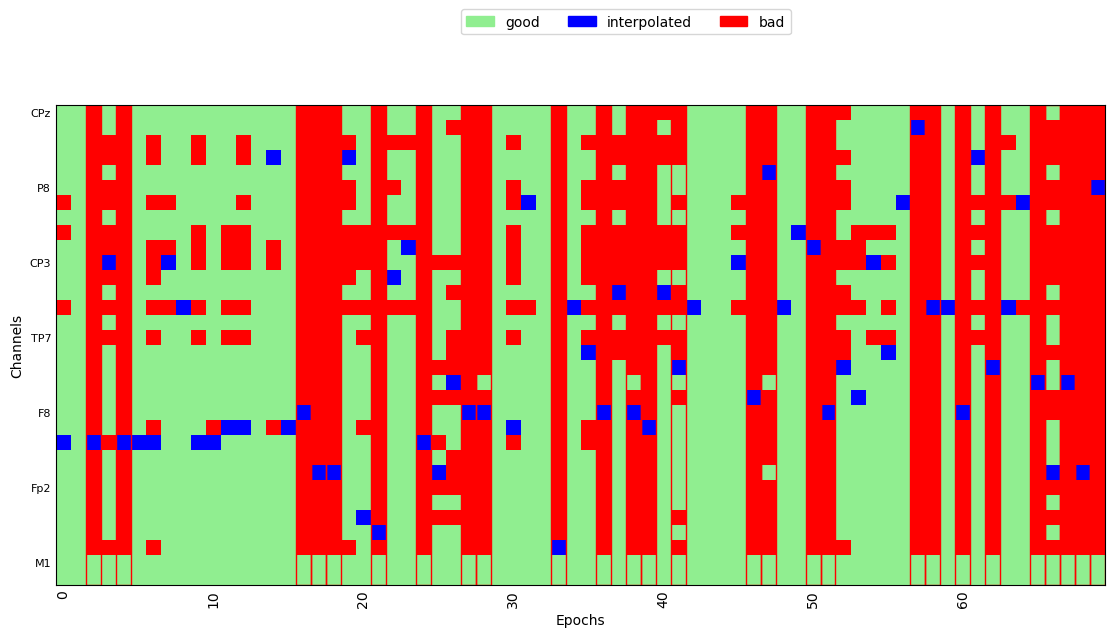

Setting channel interpolation method to {'eeg': 'spline'}.
Applying baseline correction (mode: mean)
Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0012_VOT_corr_bads_bads_ica.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms
        0 CTF compensation matrices available
Not setting metadata
1937 matching events found
No baseline correction applied
0 projection items activated


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:119: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  epochs_cond_clean.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_epochs/korean/KCUE2025_0012_VOT_corr_bads_bads_ica.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(input_dir + file, preload = True)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_59800/3905521445.py:51: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  epochs = mne.add_reference_

Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/1937 [00:00<?,       ?it/s]

... (7 outputs left out)





Estimated consensus=0.20 and n_interpolate=1


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/408 [00:00<?,       ?it/s]

Dropped 396 epochs: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 64, 65, 66, 67, 69, 70, 71, 72, 73, 74, 75, 76, 78, 79, 80, 81, 82, 83, 84, 85, 88, 89, 90, 91, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 22

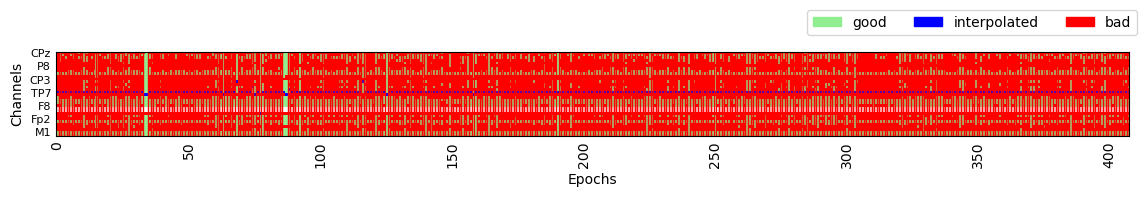

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 69 epochs: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69


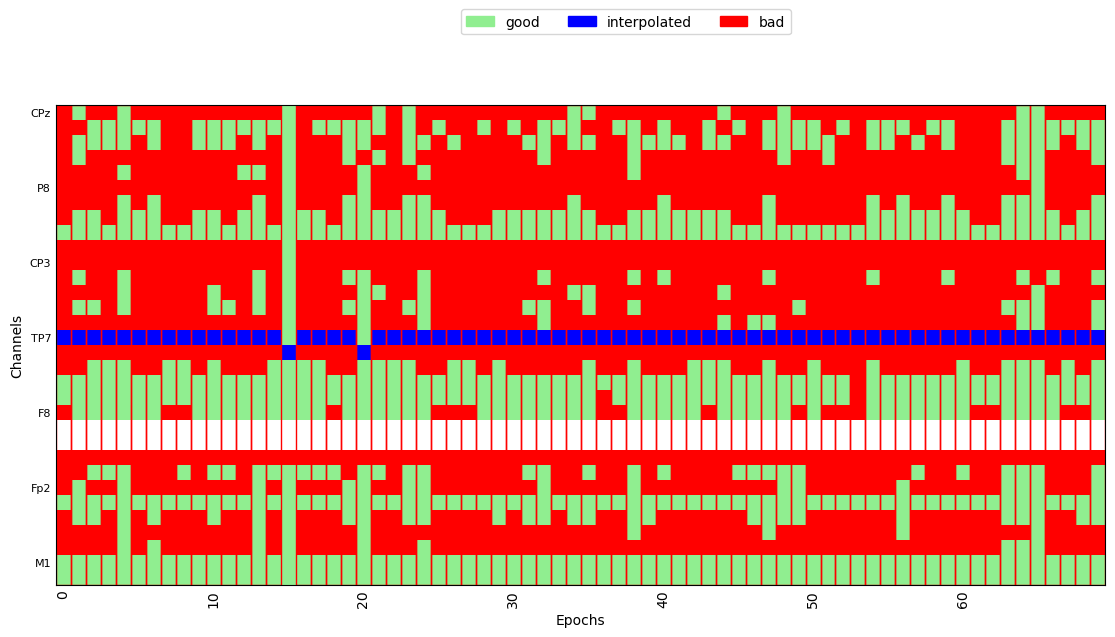

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/414 [00:00<?,       ?it/s]

Dropped 356 epochs: 1, 2, 3, 4, 6, 8, 10, 12, 13, 18, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 32, 33, 34, 35, 36, 37, 38, 40, 41, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 55, 56, 57, 59, 61, 62, 63, 64, 67, 68, 69, 70, 71, 72, 73, 75, 76, 77, 78, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 97, 98, 99, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 187, 188, 189, 191, 193, 194, 195, 196, 198, 199, 200, 201, 202, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 231, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244,

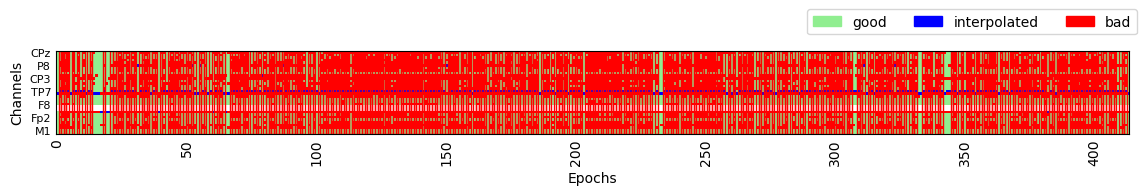

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 66 epochs: 1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 15, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69


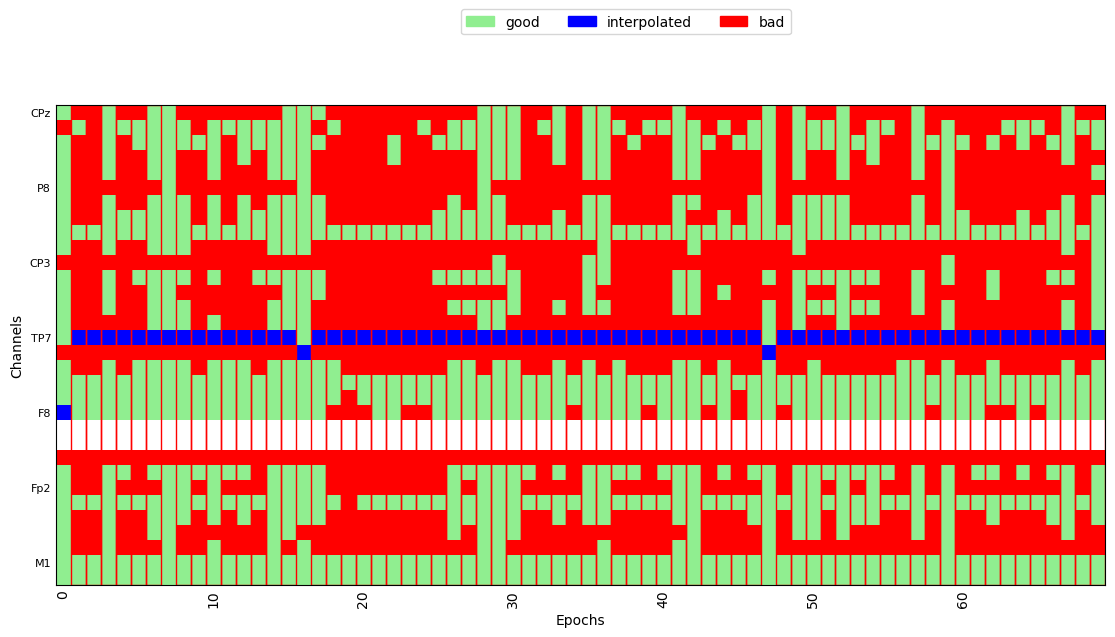

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/427 [00:00<?,       ?it/s]

Dropped 409 epochs: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 75, 76, 77, 78, 79, 80, 81, 82, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 142, 143, 144, 145, 146, 147, 149, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 2

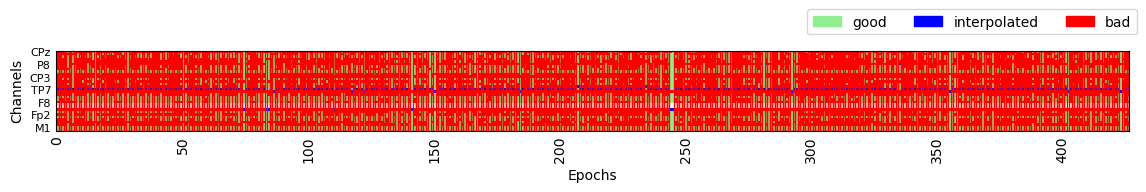

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 97.4 mm
Computing interpolation matrix from 30 sensor positions
Interpolating 2 sensors
Applying baseline correction (mode: mean)


/opt/anaconda3/lib/python3.12/site-packages/autoreject/utils.py:73: UserWarning: 2 channels are marked as bad. These will be ignored. If you want them to be considered by autoreject please remove them from epochs.info["bads"].
  warnings.warn(


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 70 epochs: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69


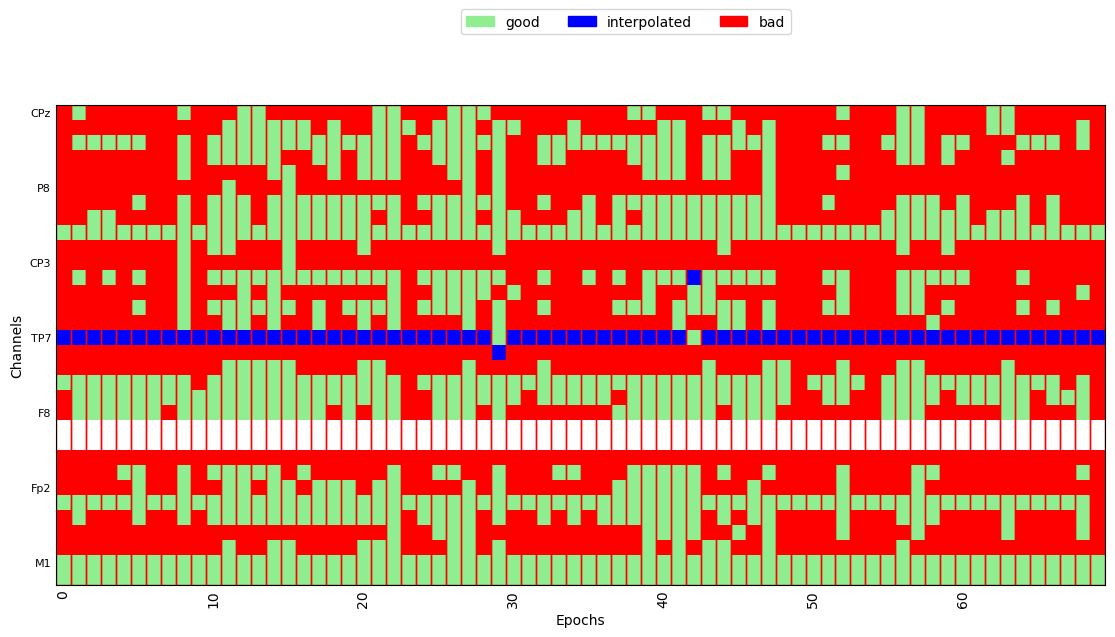

RuntimeError: epochs.interpolation() can't run because this Epochs-object is empty. You might want to check Epochs.drop_log or Epochs.plot_drop_log() to see why epochs were dropped.

In [169]:
#### parameters ####

# directory
input_dir = work_dir + 'eeg_preprocessed_NEW/4_epochs/korean/'
output_dir = work_dir + 'eeg_preprocessed_NEW/5_autoreject/korean/'

# exclude participants
exclude_ppts = [
    # 'VOT_0064', # too many bad channels
]

# condition
conditions = [
    'dorsal_highStan_lowDevi_stan', 
    'dorsal_highStan_lowDevi_devi', 
    'dorsal_lowStan_highDevi_stan', 
    'dorsal_lowStan_highDevi_devi', 
    'glottal_highStan_lowDevi_stan', 
    'glottal_highStan_lowDevi_devi', 
    'glottal_lowStan_highDevi_stan', 
    'glottal_lowStan_highDevi_devi',
]

# baseline starts
t_start_epoch = -0.1
        
# get file names
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


# initialize a log file
if ('autoreject_log.txt' not in all_output):
    with open(output_dir + '/autoreject_log.txt', 'a+') as f:
        f.write('participant' + '\t' + 'condition' + '\t' + 'n_total_trials' + '\t' + 'rate_bad_trials' + '\n')


# re-reference, then epoch
for file in all_input:
    
    if file.endswith("ica.fif") and (file.split('_')[2] + '_' + file.split('_')[1] + '_ave.fif' not in all_output):
        
        # read in data
        epochs = mne.read_epochs(input_dir + file, preload = True)

        # add back the reference channel
        # epochs = mne.add_reference_channels(epochs, 'TP9')
        # epochs.set_montage(montage)
        # NOTE: add reference channels one by one to avoid the bug that overlaps reference channels if added simultaneously
        # add back the reference channel
        epochs = mne.add_reference_channels(epochs, ref_channels = ['M1'])
        epochs.set_montage(montage)
        epochs = mne.add_reference_channels(epochs, ref_channels = ['M2'])
        epochs.set_montage(montage)

        # # set eog
        # raw.set_channel_types({'Fp1':'eog', 'Fp2':'eog'})
        # # read in channel location info
        # raw.set_montage(montage)
        
        #### this is for source calculation ####
        # filter the data, optional
        # raw = raw.filter(l_freq=None, h_freq=30) 

        # sphere = mne.make_sphere_model('auto', 'auto', raw.info)
        # src = mne.setup_volume_source_space(sphere=sphere, exclude=30., pos=15.)
        # forward = mne.make_forward_solution(raw.info, trans=None, src=src, bem=sphere)
        # raw = raw.set_eeg_reference('REST', forward=forward)
        ########################################
        

        ##### autoreject #####
        
        # get participant info
        ppt = file.split('_')[2] + '_' + file.split('_')[1]

        # -------------------------
        # fit AutoReject on all epochs (not per condition)
        # -------------------------
        ar = AutoReject(random_state=42)
        ar.fit(epochs)

        # initialize evoked list
        evoked_list = []
        
        for cond in conditions:

            # extract epochs of that condition
            epochs_cond = epochs[cond]

            # apply fitted model
            epochs_cond_clean, reject_log = ar.transform(epochs_cond, return_log=True)

            # save the reject log figure to a file
            fig = reject_log.plot('horizontal')
            fig.savefig(output_dir + ppt + '_reject_' + cond + '.png', bbox_inches='tight')

            ##### log trial count #####
            n_totalEpochs = len(reject_log.bad_epochs)
            n_badEpochs = sum(reject_log.bad_epochs)

            # # remove 0-trial events
            # if trial_count==0:
            #     del epochs.event_id[k]
            
            # good trial rate
            badEpochs_rate = round(n_badEpochs/n_totalEpochs, 2)

            # log reject summary
            with open(output_dir + 'autoreject_log.txt', 'a+') as f:
                _ =f.write(ppt + '\t' + cond + '\t' + str(n_totalEpochs) + '\t' + str(badEpochs_rate) + '\n')

            
            # average-mastoids re-reference
            # epochs_cond_clean.set_eeg_reference(ref_channels = ['TP9', 'TP10'])
            # epochs_cond_clean.set_eeg_reference(ref_channels = ['M1', 'M2'])

            # final Interpolation
            epochs_cond_clean.interpolate_bads()
            
            # BASELINE CORRECTION
            # epochs_cond_clean.apply_baseline((t_start_epoch, 0))
                
            # average | get ERP for each condition
            evoked = epochs_cond_clean.average()
            # BASELINE CORRECTION
            evoked.apply_baseline((t_start_epoch, 0))

            # add condition label
            evoked.comment = cond

            # append
            evoked_list.append(evoked)
            
        # save
        mne.write_evokeds(output_dir + ppt + '_ave.fif', evoked_list)

## Evoked data quality check

In [ ]:
## parameters
# frequency of the eeg recording for audio downsampling
# eeg_freq = 500

# directory
input_dir = work_dir + '/data_preprocessed/5_evokeds/'

# file name
file = 'F0_0001_ave.fif'

# read in file
evokeds = mne.read_evokeds(input_dir + file, condition='dorsal_highStan_lowDevi_stan')

# check information
print(evokeds.info)

# plot spectrum of raw EEG
evokeds.compute_psd(fmax=30).plot()
plt.show()

# # if needed, plot a spectrum for each channel
# for ch_ind in epochs.info['ch_names']:
#     print('=====================')
#     print(ch_ind)
#     epochs.compute_psd(fmax=30, picks = ch_ind).plot(show=False, amplitude=False)
#     plt.show()

# butterfly plot
evokeds.plot_joint(picks="eeg")
evokeds.plot_topomap(times=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7], ch_type="eeg")
plt.show()

# TFR
segmenting continuous EEG into epochs for ERSP analysis
- re-reference
- segmentation

In [ ]:
# directory
input_dir = work_dir + 'data_preprocessed/3_ica/'
output_dir = work_dir + 'data_preprocessed/4_tfr_evokeds_unnormalized/'

# Epoch window: 
epoch_t_start = -1; epoch_t_end = 2

# criteria to reject epoch
reject_criteria = dict(eeg = 100e-6)       # 100 µV
# reject_criteria = dict(eeg = 150e-6)       # 150 µV
# reject_criteria = dict(eeg = 200e-6)       # 200 µV

exclude_ppts = [
    'F0_0059', # too noisy -> cells of 0 trial
]

tfr_method = 'morlet'

# frequencies
freq_start = 3
freq_end = 30
n_freq = 28
freqs = np.linspace(start=freq_start, stop=freq_end, num=n_freq)

# cycles
cycl_start = 3
cycl_step = 0.8
n_cycl = n_freq
n_cycles = np.linspace(start=cycl_start, stop=cycl_start+cycl_step*(n_cycl-1), num=n_cycl)

condition_list = [
    'dorsal_highStan_lowDevi_stan',
    'dorsal_lowStan_highDevi_stan',
    'glottal_highStan_lowDevi_stan',
    'glottal_lowStan_highDevi_stan',
]

# initialize a list for subjects with too many bad trials
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


#### re-reference, and epoch ####
for file in all_input:
    
    if file.endswith("ica.fif"):

        # get participant info
        ppt = file.split('_')[2] + '_' + file.split('_')[1]

        # skip bad participants
        if (ppt + '_tfr.hdf5' in all_output) or (ppt in exclude_ppts):
            continue
        
        # read in data
        raw = mne.io.read_raw_fif(input_dir + file, preload = True)
        
        # average-mastoids re-reference
        raw.set_eeg_reference(ref_channels = ['TP9', 'TP10'])
        
        #### this is for source calculation ####
        # filter the data, optional
        # raw = raw.filter(l_freq=None, h_freq=30) 

        # sphere = mne.make_sphere_model('auto', 'auto', raw.info)
        # src = mne.setup_volume_source_space(sphere=sphere, exclude=30., pos=15.)
        # forward = mne.make_forward_solution(raw.info, trans=None, src=src, bem=sphere)
        # raw = raw.set_eeg_reference('REST', forward=forward)
        ########################################

        # pick EEG channels
        # picks = mne.pick_types(raw.info, eeg = True)
        
        # get event info for segmentation
        events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        
        # segmentation for ERP
        epochs = mne.Epochs(
            raw,
            events = events_from_annot, event_id = event_dict,
            tmin = epoch_t_start, tmax = epoch_t_end,
            # apply baseline correction
            baseline = None,
            # remove epochs that meet the rejection criteria
            reject = reject_criteria,
            preload = True,
        )
        


        # for each event, remove 0 trial events, record info, and check if a subject is bad
        for k, v in event_dict.items():
            
            # good trial count
            trial_count = len(epochs[k])
            
            # remove 0 trial event
            if trial_count==0:
                del epochs.event_id[k]
                
            # good trial rate
            goodTrial_rate = round( trial_count/sum(events_from_annot[:,2]==v), 2 )
            
            # record epoch summary
            with open(output_dir + 'epoch_summary.txt', 'a+') as f:
                _ =f.write(ppt + '\t' + k + '\t' + str(trial_count) + '\t' + str(goodTrial_rate) + '\n')


        # ERSP

        # initialize tfrs list
        tfrs = []
        
        for condition in condition_list:
            # compute ERSP
            power = epochs[condition].compute_tfr(
                method=tfr_method,
                freqs=freqs,
                n_cycles=n_cycles,
                # return_itc=True,
            )
            
            # average
            power = power.average(method = 'mean', dim = 'epochs')

            # add comment
            power.comment = condition

            # append
            tfrs.append(power)
            
        # save single subject file
        mne.time_frequency.write_tfrs(fname=output_dir + ppt + '_tfr.hdf5', 
                                      tfr=tfrs)

        # release memory
        del power, tfrs

# Data for GAM

In [ ]:
# directory
input_dir = work_dir + 'data_preprocessed/3_ica/'
output_dir = work_dir + 'data_analysis/gam/'
# create a folder if the folder doesn't exist
# os.makedirs(output_dir, exist_ok=True)


# epoch window: 
erp_t_start = -0.2; erp_t_end = 0.8
# baseline
epoch_baseline = (-0.2, 0)

# criteria to reject epoch
reject_criteria = dict(eeg = 100e-6)       # 100 µV


#### get data ####

# get file names
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


# re-reference, then epoch
for file in all_input:
    
    if file.endswith("ica.fif") and (file.split('_')[2] + '_' + file.split('_')[1] + '_gam.csv' not in all_output):
        
        # read in data
        raw = mne.io.read_raw_fif(input_dir + file, preload = True)
        
        # average-mastoids re-reference
        raw.set_eeg_reference(ref_channels = ['TP9', 'TP10'])
        
        # get event info for segmentation
        events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        
        # segmentation for ERP
        epochs = mne.Epochs(
            raw,
            events = events_from_annot, event_id = event_dict,
            tmin = erp_t_start, tmax = erp_t_end,
            # apply baseline correction
            baseline = epoch_baseline,
            # remove epochs that meet the rejection criteria
            reject = reject_criteria,
            preload = True,
        )

        # get participant label
        ppt = file.split('_')[2] + '_' + file.split('_')[1]

        ##########################################################
        #### remove 0-trial events, and log epoch info ####
        for k, v in event_dict.items():
            
            # good trial count
            trial_count = len(epochs[k])
            
            # remove 0 trial event
            if trial_count==0:
                del epochs.event_id[k]
                
            # good trial rate
            goodTrial_rate = round( trial_count/sum(events_from_annot[:,2]==v), 2 )
            
            # record epoch summary
            with open(output_dir + 'epoch_summary.txt', 'a+') as f:
                _ =f.write(ppt + '\t' + k + '\t' + str(trial_count) + '\t' + str(goodTrial_rate) + '\n')
        ##########################################################
        
        # apply baseline
        epochs.apply_baseline(baseline=epoch_baseline, verbose='WARNING')

        # extract data
        df = epochs.to_data_frame(time_format='ms')

        # add info of group, ppt, and item
        df['participant'] = ppt
            
        # save
        df.to_csv(output_dir + ppt + '_gam.csv', index=False)
        
        # reduce memory usage
        del df